# Wind VISION — PhysicsNeMo 2.2.2 Day-1 integration

**Tuesday deliverable, not a completed published-model reproduction.**

This notebook deliberately **does not reinstall PhysicsNeMo, reclone NASA, overwrite local experimental files, or use the test HDF5**. It assumes the already-established Colab L4 runtime, the pinned NASA checkout, the verified snapshot, and Drive mounted from the previous session. If you start a fresh ephemeral Colab runtime, restore those prerequisites first.

The native PhysicsNeMo VAE and flow classes preserve the NASA model architecture, full VAE objective (reconstruction + KL + coherence), and the latent flow-matching training objective. A 16-step flow pilot proves functional training/generation only; generated statistics are **not** quality validated. The comparison is same-L4, same-objective PyTorch against the native PhysicsNeMo integration and is **not guaranteed** to meet 2×. Model-parity results are logged before the benchmark.

**Security:** only the SHA-256-verified, previously trusted Lightning VAE checkpoint is deserialized with `weights_only=False`. Other arbitrary checkpoints must not be loaded this way. Original NASA repository is not edited.
## Recovery and continuation instructions (2026-10-29)
**Do not Run all**: earlier GPU experiments and the 80-step ablation are already saved in Drive. In the existing GPU runtime run only **P1 v4 → P2 v2 → P3**. The earlier A–K experiments are retained for scientific provenance; L–O are retained as historical experiment cells and need not be rerun. This notebook still requires the original Colab/Drive prerequisites described above.


In [2]:

# ============================================================
# CELL A v5 — VERIFIED COLAB RUNTIME RECOVERY
#
# COMPLETE REPLACEMENT for the previous Cell A.
#
# Restores only missing runtime prerequisites:
# - Final patched PhysicsNeMo implementation from Drive
# - Pinned NASA reference checkout
# - Verified training HDF5 and VAE checkpoint
# - PhysicsNeMo 2.2.2 if the environment has reset
#
# No retraining.
# No changes to original NASA source.
# No independent test data used.
# Previous research results are preserved.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import ast
import hashlib
import importlib.metadata
import json
import os
import shutil
import subprocess
import sys
import uuid
import zipfile

from google.colab import drive

ROOT = Path("/content")
DRIVE = ROOT / "drive/MyDrive"
REPO = ROOT / "nasa_clfm_reference"
SNAP = ROOT / "clfm_snapshot"
SCRIPT = ROOT / "wind_vision_physicsnemo_day1.py"

OUT = (
    DRIVE
    / "CLFM_Research_Results"
    / "physicsnemo_day1"
)

SAVED_SCRIPT = (
    OUT / "wind_vision_physicsnemo_day1_patched.py"
)

BUNDLE = DRIVE / "CLFM_CLOUD_BUNDLE.zip"

COMMIT = (
    "921e666c8d6060ae13bfd901dcc7f74f819d0eea"
)

REQUIRED = {
    "data/wind/wind_train_data.hdf5":
        "676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941",

    "results/control_reference_vae_resume_epoch10_cpu64_v2/checkpoints/epoch-epoch=0009-step=12500.ckpt":
        "b78f9e00e623ccd3b72cc3f07751de5d7f27a930e95bcabe437aada14a62eb68"
}


def file_sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as stream:
        for block in iter(
            lambda: stream.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


# ============================================================
# 1. VERIFY GOOGLE DRIVE
# ============================================================

if not DRIVE.is_dir():
    drive.mount("/content/drive")

assert DRIVE.is_dir(), (
    "Google Drive is not mounted."
)

assert SAVED_SCRIPT.is_file(), (
    "The final patched script was not found in Drive: "
    + str(SAVED_SCRIPT)
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

print("Google Drive: CONNECTED")


# ============================================================
# 2. RESTORE THE FINAL PATCHED SOURCE
# ============================================================

if not SCRIPT.exists():

    shutil.copy2(
        SAVED_SCRIPT,
        SCRIPT
    )

    print(
        "RESTORED patched PhysicsNeMo script from Drive."
    )

else:

    print(
        "Existing runtime script found. "
        "Preserving it without overwriting."
    )

# Validate Python syntax.
ast.parse(SCRIPT.read_text())

subprocess.run(
    [
        sys.executable,
        "-m",
        "py_compile",
        str(SCRIPT)
    ],
    check=True
)

source = SCRIPT.read_text()

assert "sparse_sensors=True" in source, (
    "Expected the patched 40-sensor implementation."
)

assert 'choices=["vae", "flow", "all"]' in source, (
    "Expected the patched separate flow phase."
)

script_hash = file_sha256(SCRIPT)

print("Script syntax: PASS")
print("Source SHA256:", script_hash)

if file_sha256(SAVED_SCRIPT) != script_hash:

    print(
        "NOTICE: Live source differs from saved source. "
        "Neither version was overwritten."
    )


# ============================================================
# 3. RESTORE THE PINNED NASA REFERENCE IF MISSING
# ============================================================

if not (REPO / ".git").exists():

    if REPO.exists() and any(REPO.iterdir()):

        raise RuntimeError(
            "NASA checkout directory is nonempty "
            "but has no .git directory. "
            "Refusing to overwrite: "
            + str(REPO)
        )

    if REPO.exists():
        REPO.rmdir()

    print(
        "Restoring missing NASA reference checkout...",
        flush=True
    )

    subprocess.run(
        [
            "git",
            "clone",
            "-q",
            "--filter=blob:none",
            "--no-checkout",
            "https://github.com/nasa/random_field_c-lfm",
            str(REPO)
        ],
        check=True
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO),
            "fetch",
            "-q",
            "--depth",
            "1",
            "origin",
            COMMIT
        ],
        check=True
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO),
            "checkout",
            "-q",
            "--detach",
            COMMIT
        ],
        check=True
    )

head = subprocess.check_output(
    [
        "git",
        "-C",
        str(REPO),
        "rev-parse",
        "HEAD"
    ],
    text=True
).strip()

assert head == COMMIT, (
    "Unexpected NASA reference commit: "
    + head
)

print("NASA reference commit: VERIFIED")
print("Commit:", head)


# ============================================================
# 4. RESTORE MISSING DATA AND TRUSTED CHECKPOINT
# ============================================================

missing = [
    relative
    for relative in REQUIRED
    if not (SNAP / relative).is_file()
]

if missing:

    assert BUNDLE.is_file(), (
        "Missing snapshot files and transfer bundle "
        "not found: " + str(BUNDLE)
    )

    print(
        "Restoring missing snapshot files from "
        "existing Google Drive bundle...",
        flush=True
    )

    with zipfile.ZipFile(BUNDLE) as archive:

        for relative in missing:

            matches = [
                name
                for name in archive.namelist()
                if (
                    name == relative
                    or name.endswith("/" + relative)
                )
            ]

            assert len(matches) == 1, (
                "Expected exactly one ZIP entry for "
                f"{relative}. Found {len(matches)}."
            )

            target = SNAP / relative

            target.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            partial = target.with_name(
                target.name + ".partial"
            )

            try:

                with (
                    archive.open(matches[0]) as src,
                    partial.open("wb") as dst
                ):

                    shutil.copyfileobj(
                        src,
                        dst,
                        length=8 * 1024 * 1024
                    )

                actual = file_sha256(partial)

                assert actual == REQUIRED[relative], (
                    "Restored file failed checksum: "
                    + relative
                )

                os.replace(
                    partial,
                    target
                )

            finally:

                partial.unlink(
                    missing_ok=True
                )

            print(
                "RESTORED AND VERIFIED:",
                relative,
                flush=True
            )


# ============================================================
# 5. VERIFY ALL INPUT CHECKSUMS
# ============================================================

for relative, expected in REQUIRED.items():

    target = SNAP / relative

    assert target.is_file(), (
        "Required research input missing: "
        + str(target)
    )

    actual = file_sha256(target)

    assert actual == expected, (
        "SHA256 MISMATCH: "
        + str(target)
    )

    print(
        "SHA256 VERIFIED:",
        relative,
        flush=True
    )


# ============================================================
# 6. VERIFY PHYSICSNEMO AND GPU
# ============================================================

def installed_version(package):

    try:
        return importlib.metadata.version(
            package
        )

    except importlib.metadata.PackageNotFoundError:
        return None


installed = installed_version(
    "nvidia-physicsnemo"
)

if installed != "2.2.2":

    print(
        f"PhysicsNeMo version is {installed!r}. "
        "Restoring pinned 2.2.2...",
        flush=True
    )

    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "nvidia-physicsnemo==2.2.2",
            "lightning>=2.5,<3",
            "einops>=0.8.1",
            "h5py>=3.15.1"
        ],
        check=True
    )

assert installed_version(
    "nvidia-physicsnemo"
) == "2.2.2"

import torch
import physicsnemo
import lightning
import h5py
import einops

assert torch.cuda.is_available(), (
    "CUDA is not available. "
    "Select a Colab NVIDIA GPU runtime."
)

assert physicsnemo.__version__ == "2.2.2"

from physicsnemo.core.module import Module
from physicsnemo.core.meta import ModelMetaData
from physicsnemo.utils.checkpoint import (
    save_checkpoint,
    load_checkpoint
)

print("PhysicsNeMo:", physicsnemo.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 7. SAVE RUNTIME RECOVERY PROVENANCE
# ============================================================

record = {
    "type": "runtime_recovery",
    "utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "reference_commit": head,
    "script_sha256": script_hash,
    "training_file_sha256":
        REQUIRED[
            "data/wind/wind_train_data.hdf5"
        ],
    "trusted_checkpoint_sha256":
        REQUIRED[
            "results/control_reference_vae_resume_epoch10_cpu64_v2/checkpoints/epoch-epoch=0009-step=12500.ckpt"
        ],
    "python": sys.version,
    "torch": torch.__version__,
    "physicsnemo": physicsnemo.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "independent_test_used": False
}

provenance = OUT / (
    "runtime_recovery_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
    + ".json"
)

provenance.write_text(
    json.dumps(record, indent=2)
)

print("\n" + "=" * 60)
print("PASS — CELL A: VERIFIED COLAB RUNTIME RESTORED")
print("=" * 60)

print("GPU:", record["gpu"])
print("PhysicsNeMo:", record["physicsnemo"])
print("Patched script:", SCRIPT)
print("Provenance saved:", provenance)

print(
    "Previous experiment results were "
    "NOT overwritten."
)

print("=" * 60)


Mounted at /content/drive
Google Drive: CONNECTED
RESTORED patched PhysicsNeMo script from Drive.
Script syntax: PASS
Source SHA256: e1907525452834c13ef1840d810b45846136088bda9ee0a447530be35468d405
Restoring missing NASA reference checkout...
NASA reference commit: VERIFIED
Commit: 921e666c8d6060ae13bfd901dcc7f74f819d0eea
Restoring missing snapshot files from existing Google Drive bundle...
RESTORED AND VERIFIED: data/wind/wind_train_data.hdf5
RESTORED AND VERIFIED: results/control_reference_vae_resume_epoch10_cpu64_v2/checkpoints/epoch-epoch=0009-step=12500.ckpt
SHA256 VERIFIED: data/wind/wind_train_data.hdf5
SHA256 VERIFIED: results/control_reference_vae_resume_epoch10_cpu64_v2/checkpoints/epoch-epoch=0009-step=12500.ckpt
PhysicsNeMo version is None. Restoring pinned 2.2.2...
PhysicsNeMo: 2.2.2
PyTorch: 2.11.0+cu130
CUDA: 13.0
GPU: NVIDIA L4

PASS — CELL A: VERIFIED COLAB RUNTIME RESTORED
GPU: NVIDIA L4
PhysicsNeMo: 2.2.2
Patched script: /content/wind_vision_physicsnemo_day1.py
Prove

In [3]:

# CELL B — Patch existing implementation safely

from pathlib import Path
import ast, hashlib, json, shutil, subprocess

script_path = Path(
    "/content/wind_vision_physicsnemo_day1.py"
)
out = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

assert script_path.exists(), "Original source cell must run first."

source = script_path.read_text()
original = source

def replace_once(old, new, label):
    global source

    if old in source:
        assert source.count(old) == 1, (
            f"Ambiguous source patch: {label}"
        )
        source = source.replace(old, new, 1)
        print("PATCHED:", label)
    elif new in source:
        print("ALREADY PATCHED:", label)
    else:
        raise RuntimeError(
            f"Source structure unexpectedly changed: {label}. "
            "Do not modify source blindly."
        )

# ------------------------------------------------------
# PATCH 1: Restore the actual NASA sparse sensor layout
# ------------------------------------------------------

replace_once(
    'dataset = dataset_class(str(train_path), sparse_sensors=False)',
    'dataset = dataset_class(str(train_path), sparse_sensors=True)',
    "40-sensor sparse wind dataset"
)

# ------------------------------------------------------
# PATCH 2: Assert checkpoint and dataset compatibility
# ------------------------------------------------------

replace_once(
    '''    sample_u, _ = dataset[0]
    model_kwargs = dict(''',
    '''    sample_u, _ = dataset[0]

    checkpoint_sensors = int(
        ref._encoder.input_layer.weight.shape[1]
    )
    dataset_sensors = int(sample_u.shape[0])

    assert checkpoint_sensors == dataset_sensors == 40, (
        f"Sparse-sensor mismatch: checkpoint={checkpoint_sensors}, "
        f"dataset={dataset_sensors}"
    )

    expected_indices = torch.tensor(
        [*range(0, 10), *range(30, 40),
         *range(60, 70), *range(90, 100)]
    )

    assert torch.equal(
        dataset.sensor_idx.cpu(), expected_indices
    ), "Unexpected sparse-sensor indices"

    print(
        f"Verified matching sparse sensor architecture: "
        f"{dataset_sensors} sensors",
        flush=True
    )

    model_kwargs = dict(''',
    "checkpoint/data channel and sensor-index verification"
)

# ------------------------------------------------------
# PATCH 3: Add a separately executable flow phase
# ------------------------------------------------------

replace_once(
    'parser.add_argument("--phase", choices=["vae", "all"], default="all")',
    'parser.add_argument("--phase", choices=["vae", "flow", "all"], default="all")',
    "separate flow phase"
)

# ------------------------------------------------------
# PATCH 4: Flow-only execution without repeated benchmark
# ------------------------------------------------------

replace_once(
    '''    assert p_ref == p_nemo, (p_ref, p_nemo)
    batch_cpu = next(iter(DataLoader(dataset, batch_size=args.batch_size,''',
    '''    assert p_ref == p_nemo, (p_ref, p_nemo)

    if args.phase == "flow":
        parity_path = OUT_ROOT / "01_full_objective_parity.json"

        if (
            not parity_path.exists()
            or not json.loads(
                parity_path.read_text()
            ).get("parity_pass")
        ):
            raise RuntimeError(
                "Complete --phase vae successfully before --phase flow"
            )

        print(
            "Starting paired latent flow pilot; "
            "VAE benchmark will not be repeated",
            flush=True
        )

        flow_metrics = train_short_flow(
            nemo, dataset, OUT_ROOT, args
        )

        save_json(
            OUT_ROOT / "04_flow_only_summary.json",
            {
                "vae_checkpoint_sha256": TRUSTED_CHECKPOINT_SHA,
                "reference_commit": PINNED_GIT_SHA,
                "sparse_sensors": True,
                "short_flow": flow_metrics,
            }
        )

        print("FLOW-ONLY PILOT COMPLETED", flush=True)
        return

    batch_cpu = next(iter(DataLoader(dataset, batch_size=args.batch_size,''',
    "flow-only execution branch"
)

# ------------------------------------------------------
# Validate, install patch, and persist to Google Drive
# ------------------------------------------------------

ast.parse(source)

if source != original:
    backup = script_path.with_suffix(".before_sparse_fix.py")
    if not backup.exists():
        backup.write_text(original)
    script_path.write_text(source)

# Confirm Python syntax
subprocess.run(
    ["python", "-m", "py_compile", str(script_path)],
    check=True
)

persisted_script = out / "wind_vision_physicsnemo_day1_patched.py"
shutil.copy2(script_path, persisted_script)

digest = hashlib.sha256(
    script_path.read_bytes()
).hexdigest()

patch_record = {
    "source_sha256": digest,
    "reference_commit": "921e666c8d6060ae13bfd901dcc7f74f819d0eea",
    "checkpoint_encoder_channels": 40,
    "sparse_sensors": True,
    "sensor_indices": [
        *range(0, 10),
        *range(30, 40),
        *range(60, 70),
        *range(90, 100)
    ],
    "independent_test_data_used": False,
    "separate_flow_phase": True
}

(out / "sparse_sensor_patch_manifest.json").write_text(
    json.dumps(patch_record, indent=2)
)

print("=" * 55)
print("PATCH VALIDATION COMPLETE")
print("=" * 55)
print("40-channel sparse encoder configured")
print("Dataset indices verified by runtime assertion")
print("Separate --phase flow enabled")
print("Python syntax check passed")
print("Patched script saved to Drive")
print("Source SHA256:", digest)
print("=" * 55)
print("READY FOR FULL-OBJECTIVE PARITY")


ALREADY PATCHED: 40-sensor sparse wind dataset
ALREADY PATCHED: checkpoint/data channel and sensor-index verification
ALREADY PATCHED: separate flow phase
ALREADY PATCHED: flow-only execution branch
PATCH VALIDATION COMPLETE
40-channel sparse encoder configured
Dataset indices verified by runtime assertion
Separate --phase flow enabled
Python syntax check passed
Patched script saved to Drive
Source SHA256: e1907525452834c13ef1840d810b45846136088bda9ee0a447530be35468d405
READY FOR FULL-OBJECTIVE PARITY


In [4]:

# CELL B2 — Fix float64/float32 mismatch

from pathlib import Path
import ast
import hashlib
import shutil

SCRIPT = Path("/content/wind_vision_physicsnemo_day1.py")
OUT = Path("/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1")

assert SCRIPT.exists(), "Run the original %%writefile cell first."
OUT.mkdir(parents=True, exist_ok=True)

source = SCRIPT.read_text()
original = source

def patch_once(old, new, label):
    global source

    if new in source:
        print("ALREADY PATCHED:", label)
        return

    count = source.count(old)
    assert count == 1, (
        f"Expected exactly one occurrence for {label}, found {count}"
    )

    source = source.replace(old, new, 1)
    print("PATCHED:", label)

# 1. Convert trusted reference VAE to float32
patch_once(
    'weights_only=False).cuda().train()',
    'weights_only=False).to(device="cuda", dtype=torch.float32).train()',
    "Reference VAE float32 conversion"
)

# 2. Explicitly align physics-loss buffers
patch_once(
    'loss_impl = loss_impl.cuda()',
    'loss_impl = loss_impl.to(device="cuda", dtype=torch.float32)',
    "WindLoss buffer precision"
)

# 3. Explicitly align PhysicsNeMo VAE precision
patch_once(
    'nemo = PhysicsNeMoWindVAE(**model_kwargs).cuda().train()',
    'nemo = PhysicsNeMoWindVAE(**model_kwargs).to(device="cuda", dtype=torch.float32).train()',
    "PhysicsNeMo VAE float32"
)

# 4. Verify matching precision BEFORE parity
patch_once(
    '''    batch_gpu = (batch_cpu[0].cuda(), batch_cpu[1].cuda())
    parity_metrics = parity(''',
    '''    batch_gpu = (batch_cpu[0].cuda(), batch_cpu[1].cuda())

    for name, model in (
        ("NASA reference", ref),
        ("PhysicsNeMo", nemo),
    ):
        model_dtype = next(model.parameters()).dtype

        assert (
            model_dtype
            == batch_gpu[0].dtype
            == batch_gpu[1].dtype
            == torch.float32
        ), (
            f"{name} precision mismatch: "
            f"model={model_dtype}, "
            f"wind={batch_gpu[0].dtype}, "
            f"coordinates={batch_gpu[1].dtype}"
        )

        print(
            f"PRECISION CHECK PASSED: {name} / {model_dtype}",
            flush=True
        )

    parity_metrics = parity(''',
    "Pre-parity dtype verification"
)

# 5. Validate syntax before modifying the script
ast.parse(source)

# Save previous version if changes were necessary
if source != original:
    backup = OUT / "wind_vision_before_dtype_fix.py"
    if not backup.exists():
        backup.write_text(original)
    SCRIPT.write_text(source)

# Persist the new implementation
saved_script = OUT / "wind_vision_physicsnemo_day1_patched.py"
shutil.copy2(SCRIPT, saved_script)

digest = hashlib.sha256(SCRIPT.read_bytes()).hexdigest()

print("\n" + "=" * 60)
print("PRECISION PATCH COMPLETE")
print("=" * 60)
print("Reference model: float32")
print("PhysicsNeMo model: float32")
print("Wind input: float32")
print("Coordinates: float32")
print("Original checkpoint: unchanged")
print("NASA source repository: unchanged")
print("Syntax validation: PASSED")
print("SHA256:", digest)
print("Persisted script:", saved_script)
print("=" * 60)
print("READY — RERUN CELL C")


ALREADY PATCHED: Reference VAE float32 conversion
ALREADY PATCHED: WindLoss buffer precision
ALREADY PATCHED: PhysicsNeMo VAE float32
ALREADY PATCHED: Pre-parity dtype verification

PRECISION PATCH COMPLETE
Reference model: float32
PhysicsNeMo model: float32
Wind input: float32
Coordinates: float32
Original checkpoint: unchanged
NASA source repository: unchanged
Syntax validation: PASSED
SHA256: e1907525452834c13ef1840d810b45846136088bda9ee0a447530be35468d405
Persisted script: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/wind_vision_physicsnemo_day1_patched.py
READY — RERUN CELL C


In [5]:

# CELL B3 — Fix dataset coordinate precision throughout pipeline

from pathlib import Path
import ast
import shutil
import hashlib
import subprocess

SCRIPT = Path("/content/wind_vision_physicsnemo_day1.py")
OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

source = SCRIPT.read_text()

old = '    dataset = dataset_class(str(train_path), sparse_sensors=True)\n'

new = old + '''
    # Normalize coordinate dtype for the matched float32 experiment.
    # Preserve physical coordinate VALUES and sensor ordering.
    dataset.points = dataset.points.to(dtype=torch.float32)
    assert dataset.points.dtype == torch.float32
    print(
        f"Dataset coordinate precision verified: {dataset.points.dtype}",
        flush=True
    )
'''

if new in source:
    print("Coordinate precision patch already applied.")
else:
    assert source.count(old) == 1, (
        "Dataset initialization pattern not found exactly once. "
        "Inspect the source before changing it."
    )
    patched = source.replace(old, new, 1)
    ast.parse(patched)

    backup = OUT / "wind_vision_before_coordinate_fix.py"
    if not backup.exists():
        backup.write_text(source)

    SCRIPT.write_text(patched)
    print("PATCHED: float32 dataset coordinates")

subprocess.run(
    ["python", "-m", "py_compile", str(SCRIPT)],
    check=True
)

shutil.copy2(
    SCRIPT,
    OUT / "wind_vision_physicsnemo_day1_patched.py"
)

print("=" * 55)
print("COORDINATE DTYPE FIX COMPLETE")
print("=" * 55)
print("VAE weights: float32")
print("Wind samples: float32")
print("Coordinates: float32")
print("Physics loss buffers: float32")
print("Original checkpoint: unchanged")
print("NASA repository: unchanged")
print("Syntax check: PASSED")
print("Updated script saved to Google Drive")
print("SHA256:", hashlib.sha256(SCRIPT.read_bytes()).hexdigest())
print("READY TO RERUN CELL C")


Coordinate precision patch already applied.
COORDINATE DTYPE FIX COMPLETE
VAE weights: float32
Wind samples: float32
Coordinates: float32
Physics loss buffers: float32
Original checkpoint: unchanged
NASA repository: unchanged
Syntax check: PASSED
Updated script saved to Google Drive
SHA256: e1907525452834c13ef1840d810b45846136088bda9ee0a447530be35468d405
READY TO RERUN CELL C


In [6]:

# CELL C — PyTorch vs PhysicsNeMo VAE integration

import subprocess, sys, time
from pathlib import Path

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
SCRIPT = Path("/content/wind_vision_physicsnemo_day1.py")

logfile = OUT / "vae_integration_execution_v2.log"

command = [
    sys.executable, "-u", str(SCRIPT),
    "--phase", "vae",
    "--batch-size", "4",
    "--bench-steps", "8",
    "--bench-warmup", "2",
    "--seed", "20261029"
]

print("STARTING FULL-OBJECTIVE VAE EXPERIMENT")
print("Includes:")
print(" - Verified 40-sensor checkpoint compatibility")
print(" - PhysicsNeMo strict weight transfer")
print(" - Reconstruction + KL + coherence residual")
print(" - Backward gradient parity")
print(" - Full optimizer-step timing on the L4")
print(" - Native checkpoint save and restore")
print("=" * 60, flush=True)

start = time.perf_counter()

with logfile.open("w") as log:
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()

    exit_code = process.wait()

elapsed = time.perf_counter() - start

print("\n" + "=" * 60)
print("EXIT CODE:", exit_code)
print("ELAPSED SECONDS:", round(elapsed, 2))
print("LOG SAVED:", logfile)

if exit_code != 0:
    raise RuntimeError(
        "VAE experiment failed. Copy the traceback shown above."
    )

print("VAE EXPERIMENT FINISHED")


STARTING FULL-OBJECTIVE VAE EXPERIMENT
Includes:
 - Verified 40-sensor checkpoint compatibility
 - PhysicsNeMo strict weight transfer
 - Reconstruction + KL + coherence residual
 - Backward gradient parity
 - Full optimizer-step timing on the L4
 - Native checkpoint save and restore
Loading verified, trusted pinned-reference checkpoint ...
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module

## Run: parity, optimizer benchmark, paired latent-flow pilot, independent generation

The cell runs the code in a **fresh Python process**, ensuring the pinned `clfm` checkout is imported instead of any modified modules left in Colab memory. Start with `--phase vae` if limited on GPU time, then run `--phase all` once parity and optimizer passes succeed. The notebook saves checkpoint files, JSON and PNG figures into Drive.

In [7]:

# CELL D — Results inspection

from pathlib import Path
import json

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

def read_report(name):
    path = OUT / name
    if not path.exists():
        print("MISSING:", name)
        return None
    return json.loads(path.read_text())

parity = read_report("01_full_objective_parity.json")
benchmark = read_report("02_same_l4_full_step_benchmark.json")
checkpoint = read_report("03_native_checkpoint_status.json")

print("\n" + "=" * 60)
print("1. FULL-OBJECTIVE PARITY")
print("=" * 60)

if parity is not None:
    print("PASS:", parity["parity_pass"])
    print(
        "Relative loss difference:",
        parity["relative_total_loss_difference"]
    )
    print(
        "Relative gradient difference:",
        parity["relative_full_parameter_gradient_l2_difference"]
    )
    print(
        "Gradient tensor count:",
        parity["number_of_gradient_tensors"]
    )
    print(
        "PyTorch losses:",
        parity["reference"]
    )
    print(
        "PhysicsNeMo losses:",
        parity["physicsnemo"]
    )

print("\n" + "=" * 60)
print("2. SAME-GPU PERFORMANCE")
print("=" * 60)

if benchmark is not None:
    print("GPU:", benchmark["gpu"])
    print("Batch size:", benchmark["batch_size"])
    print(
        "Measured steps:",
        benchmark["measured_steps_per_impl"]
    )
    print(
        "PyTorch median ms:",
        benchmark["pytorch"]["median_ms"]
    )
    print(
        "PhysicsNeMo median ms:",
        benchmark["physicsnemo"]["median_ms"]
    )
    print(
        "Speed ratio PyTorch / PhysicsNeMo:",
        benchmark["speedup_pytorch_over_physicsnemo"]
    )
    print(
        "2x target reached in pilot:",
        benchmark["target_2x_met_in_this_pilot"]
    )

print("\n" + "=" * 60)
print("3. CHECKPOINTING")
print("=" * 60)

if checkpoint is not None:
    print(json.dumps(checkpoint, indent=2))

print("\n" + "=" * 60)
print("VAE RESULTS REVIEW COMPLETE")



1. FULL-OBJECTIVE PARITY
PASS: True
Relative loss difference: 0.0
Relative gradient difference: 4.555103808815546e-10
Gradient tensor count: 164
PyTorch losses: {'implementation': 'pytorch', 'total': 0.0038392727728933096, 'reconstruction': 0.0028438796289265156, 'kl_unweighted': 29.54083251953125, 'residual_unweighted': 0.0965852364897728}
PhysicsNeMo losses: {'implementation': 'physicsnemo', 'total': 0.0038392727728933096, 'reconstruction': 0.0028438796289265156, 'kl_unweighted': 29.54083251953125, 'residual_unweighted': 0.0965852364897728}

2. SAME-GPU PERFORMANCE
GPU: NVIDIA L4
Batch size: 4
Measured steps: 8
PyTorch median ms: 291.20042450000483
PhysicsNeMo median ms: 289.7255264999785
Speed ratio PyTorch / PhysicsNeMo: 1.005090673292905
2x target reached in pilot: False

3. CHECKPOINTING
{
  "attempted": true,
  "success": true,
  "restore_weights_equal": true
}

VAE RESULTS REVIEW COMPLETE


In [8]:

# CELL E — PhysicsNeMo latent flow and wind generation

import subprocess, sys, json, time
from pathlib import Path

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
SCRIPT = Path("/content/wind_vision_physicsnemo_day1.py")

parity_path = OUT / "01_full_objective_parity.json"

assert parity_path.exists(), (
    "Run VAE integration first."
)
assert json.loads(parity_path.read_text())["parity_pass"], (
    "Cannot proceed until full-objective parity passes."
)

logfile = OUT / "latent_flow_execution_v2.log"

command = [
    sys.executable, "-u", str(SCRIPT),
    "--phase", "flow",
    "--batch-size", "4",
    "--flow-steps", "32",
    "--latent-batches", "16",
    "--flow-hidden", "512",
    "--flow-layers", "5",
    "--num-generated", "4",
    "--rk-steps", "32",
    "--seed", "20261029"
]

print("STARTING PAIRED LATENT FLOW EXPERIMENT")
print("VAE: trusted epoch-ten checkpoint")
print("Sensor configuration: 40 sparse sensors")
print("Latent dimensions: 128")
print("Flow training steps: 32")
print("Generated fields: 4")
print("Sampling: fixed-step RK4")
print("=" * 60, flush=True)

start = time.perf_counter()

with logfile.open("w") as log:
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()

    exit_code = process.wait()

print("\nEXIT CODE:", exit_code)
print(
    "ELAPSED SECONDS:",
    round(time.perf_counter() - start, 2)
)
print("LOG SAVED:", logfile)

if exit_code != 0:
    raise RuntimeError(
        "Latent flow failed. Copy the traceback above."
    )

print("FLOW TRAINING AND GENERATION COMPLETED")


STARTING PAIRED LATENT FLOW EXPERIMENT
VAE: trusted epoch-ten checkpoint
Sensor configuration: 40 sparse sensors
Latent dimensions: 128
Flow training steps: 32
Generated fields: 4
Sampling: fixed-step RK4
Loading verified, trusted pinned-reference checkpoint ...
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them u

END-TO-END PHYSICSNEMO WIND GENERATION
Training steps: 32
Latent-statistics fields: 64
Initial flow loss: 2.243784189224243
Final flow loss: 1.959037184715271
Generated shape: [4, 40, 256]
All values finite: True
Sampling solver: RK4-32 (NOT original dopri5)
Quality validated: False

Saved files:
PASS latent_flow/flow_demo_metrics.json
PASS latent_flow/short_flow_wind_demo.png
PASS latent_flow/unconditional_samples.pt
PASS latent_flow/paired_flow_state.pt

WIND FIELD VISUALIZATION


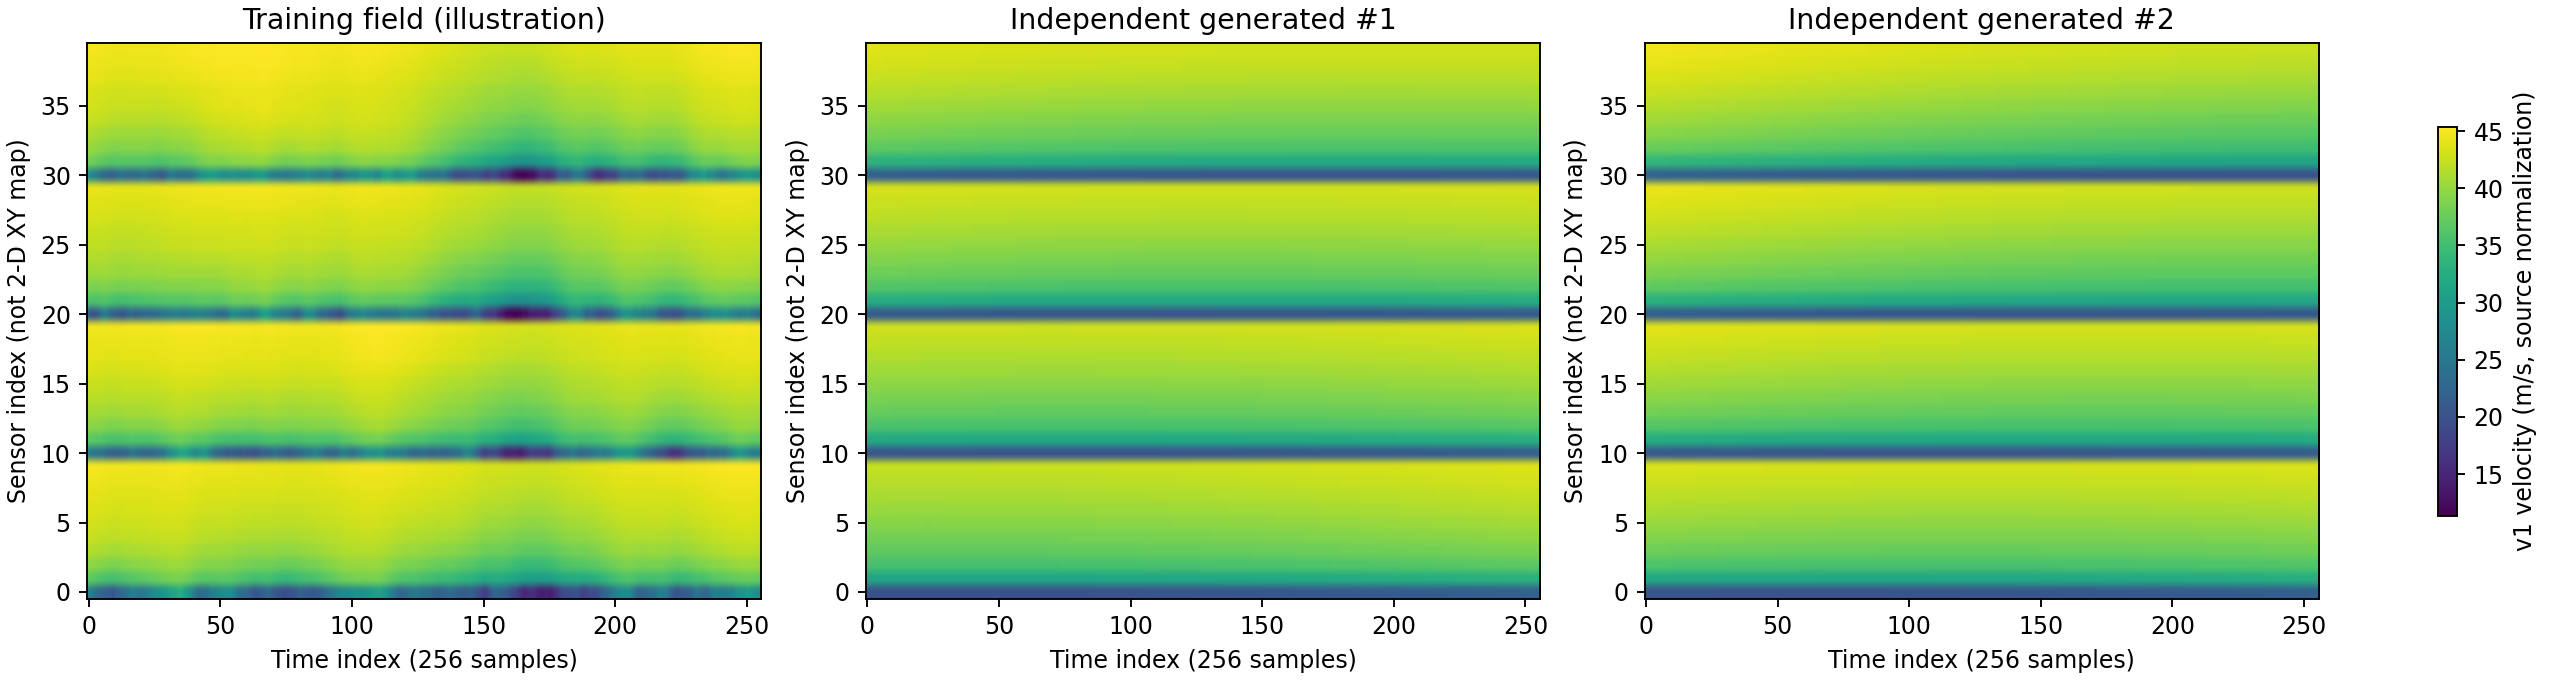


END-TO-END FUNCTIONAL DEMONSTRATION COMPLETE
Independent statistical fidelity remains unvalidated.


In [9]:

# CELL F — End-to-end generation results

import json
from pathlib import Path
from IPython.display import display, Image

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

FLOW_DIR = OUT / "latent_flow"
METRICS = FLOW_DIR / "flow_demo_metrics.json"
FIGURE = FLOW_DIR / "short_flow_wind_demo.png"
SAMPLES = FLOW_DIR / "unconditional_samples.pt"
FLOW_STATE = FLOW_DIR / "paired_flow_state.pt"

assert METRICS.exists(), "No flow metrics saved."
assert FIGURE.exists(), "No flow visualization saved."

m = json.loads(METRICS.read_text())

print("=" * 60)
print("END-TO-END PHYSICSNEMO WIND GENERATION")
print("=" * 60)

print("Training steps:", m["training_steps"])
print("Latent-statistics fields:", m["latent_stats_fields"])
print("Initial flow loss:", m["loss_start"])
print("Final flow loss:", m["loss_end"])
print("Generated shape:", m["sample_shape"])
print("All values finite:", m["all_generated_finite"])
print("Sampling solver:", m["sampling_solver"])
print("Quality validated:", m["quality_validated"])

print("\nSaved files:")
for p in [METRICS, FIGURE, SAMPLES, FLOW_STATE]:
    print(
        "PASS" if p.exists() else "MISSING",
        p.relative_to(OUT)
    )

assert m["all_generated_finite"], (
    "Generated wind contains non-finite values."
)

print("\nWIND FIELD VISUALIZATION")
display(Image(filename=str(FIGURE)))

print("\nEND-TO-END FUNCTIONAL DEMONSTRATION COMPLETE")
print("Independent statistical fidelity remains unvalidated.")


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

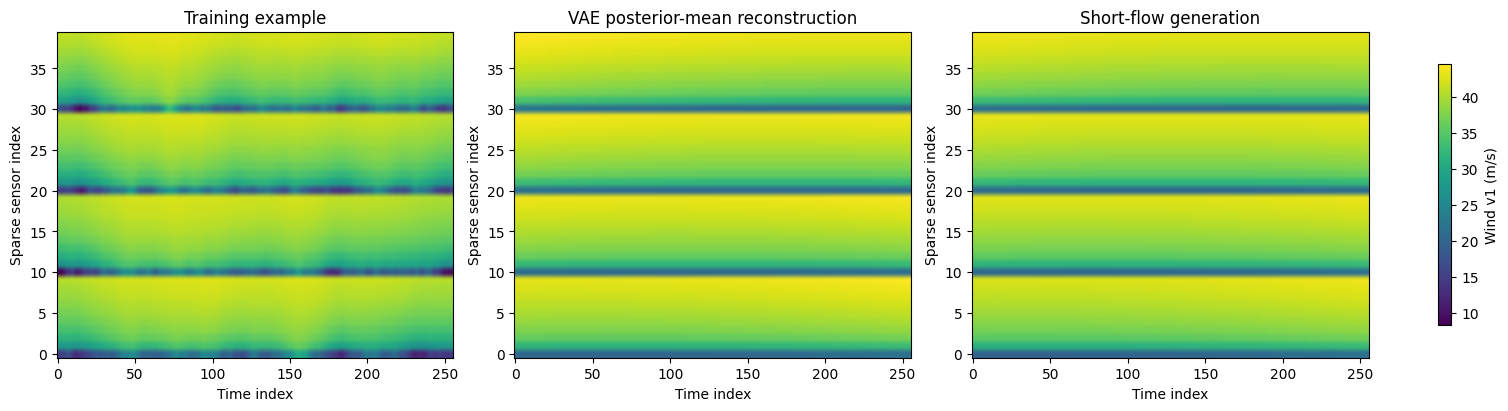


========== FIDELITY DIAGNOSTIC ==========
Generated / training temporal variance: 0.05196928612459236
Generated / training high-frequency PSD: 0.06223684025010609
Generated / training field variance: 0.010886837314078284
Posterior-mean / training temporal variance: 0.042810977414540145
Posterior-mean / training high-frequency PSD: 0.04844938751073389
Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/07_training_only_fidelity_audit.json
Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/07_training_vs_posterior_vs_flow.png


In [10]:

# CELL G — TRAINING-ONLY GENERATION FIDELITY AUDIT
# No retraining or new downloads.

import json, hashlib, sys
from pathlib import Path
import numpy as np
import torch, h5py
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1")
TRAIN = Path("/content/clfm_snapshot/data/wind/wind_train_data.hdf5")
CKPT = Path("/content/clfm_snapshot/results/control_reference_vae_resume_epoch10_cpu64_v2/checkpoints/epoch-epoch=0009-step=12500.ckpt")
SAMPLES = ROOT / "latent_flow/unconditional_samples.pt"

assert TRAIN.is_file() and CKPT.is_file() and SAMPLES.is_file()
assert torch.cuda.is_available()

# Locally generated tensor-only artifact
gen_data = torch.load(SAMPLES, map_location="cpu", weights_only=True)
generated = gen_data["u_normalized"].detach().float().numpy()
assert generated.shape[1:] == (40, 256)
assert np.isfinite(generated).all()

sensor_indices = np.r_[0:10, 30:40, 60:70, 90:100]
rng = np.random.default_rng(20261029)

# Sample training examples only; do not touch the test HDF5.
with h5py.File(TRAIN, "r") as f:
    keys = sorted(f["wind_samples"].keys(), key=int)
    chosen = rng.choice(len(keys), size=min(64, len(keys)), replace=False)
    raw_reference = np.stack([
        np.asarray(
            f["wind_samples"][keys[int(i)]]["v1"],
            dtype=np.float32
        )[sensor_indices]
        for i in chosen
    ])
    xyz = np.asarray(f["x_grid"], dtype=np.float32)[sensor_indices]
    times = np.asarray(f["t_grid"], dtype=np.float32).reshape(-1)

reference = (raw_reference + 2.0) / 49.0

coords = np.concatenate([
    np.broadcast_to(xyz[:, None, :], (40, 256, 3)),
    np.broadcast_to(times[None, :, None], (40, 256, 1))
], axis=-1).reshape(1, -1, 4).astype(np.float32)

def wind_stats(fields):
    a = np.asarray(fields, dtype=np.float64)
    centered = a - a.mean(axis=-1, keepdims=True)
    power = np.abs(np.fft.rfft(centered, axis=-1)) ** 2
    power = power.mean(axis=(0, 1))

    return {
        "mean_velocity_m_s": float(a.mean() * 49 - 2),
        "temporal_variance_m_s2": float(
            a.var(axis=-1).mean() * 49**2
        ),
        "between_field_variance_m_s2": float(
            a.var(axis=0).mean() * 49**2
        ),
        "low_psd_bins_1_6": float(power[1:7].mean()),
        "mid_psd_bins_7_16": float(power[7:17].mean()),
        "high_psd_bins_17_64": float(power[17:65].mean())
    }

def ratios(a, b):
    return {
        k: float(a[k] / b[k]) if abs(b[k]) > 1e-20 else None
        for k in a if k != "mean_velocity_m_s"
    }

reference_stats = wind_stats(reference)
generated_stats = wind_stats(generated)
generation_ratios = ratios(generated_stats, reference_stats)

# Verify trusted checkpoint before deserialization.
expected_hash = "b78f9e00e623ccd3b72cc3f07751de5d7f27a930e95bcabe437aada14a62eb68"
h = hashlib.sha256()
with CKPT.open("rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        h.update(chunk)
assert h.hexdigest() == expected_hash

sys.path.insert(0, "/content/nasa_clfm_reference")
from clfm.nn.vae import FunctionalVAE

vae = FunctionalVAE.load_from_checkpoint(
    str(CKPT),
    map_location="cpu",
    weights_only=False
).to(device="cuda", dtype=torch.float32).eval()

# Posterior-mean reconstructions on eight training examples
posterior_fields = []
with torch.inference_mode():
    x_gpu = torch.from_numpy(coords).cuda()

    for start in range(0, min(8, len(reference)), 2):
        u = torch.from_numpy(reference[start:start+2]).cuda()
        mu, logvar = vae.encode(u)
        prediction = vae.decode(
            mu, x_gpu.expand(len(u), -1, -1)
        ).reshape(-1, 40, 256)
        posterior_fields.append(
            prediction.float().cpu().numpy()
        )

posterior = np.concatenate(posterior_fields)
posterior_stats = wind_stats(posterior)
posterior_reference_stats = wind_stats(reference[:len(posterior)])
posterior_ratios = ratios(posterior_stats, posterior_reference_stats)

del vae
torch.cuda.empty_cache()

# Plot with shared physical units and color limits.
panels = [reference[0], posterior[0], generated[0]]
titles = [
    "Training example",
    "VAE posterior-mean reconstruction",
    "Short-flow generation"
]

fig, axs = plt.subplots(
    1, 3, figsize=(15, 4), constrained_layout=True
)
vmin = min(float(p.min()) for p in panels) * 49 - 2
vmax = max(float(p.max()) for p in panels) * 49 - 2

for ax, title, field in zip(axs, titles, panels):
    im = ax.imshow(
        field * 49 - 2,
        origin="lower",
        aspect="auto",
        vmin=vmin,
        vmax=vmax,
        cmap="viridis"
    )
    ax.set_title(title)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor index")

fig.colorbar(im, ax=axs, label="Wind v1 (m/s)", shrink=0.8)
figpath = ROOT / "07_training_vs_posterior_vs_flow.png"
fig.savefig(figpath, dpi=160)
display(fig)
plt.close(fig)

results = {
    "evaluation": "TRAINING-ONLY DIAGNOSTIC, NOT INDEPENDENT TEST",
    "n_reference": len(reference),
    "n_generated": len(generated),
    "n_posterior": len(posterior),
    "reference": reference_stats,
    "generated": generated_stats,
    "generation_to_training_ratios": generation_ratios,
    "posterior_mean": posterior_stats,
    "posterior_to_training_ratios": posterior_ratios,
    "limitations": [
        "Only four generated fields",
        "Training data is not an independent holdout",
        "Posterior-mean reconstruction is deterministic",
        "40 sparse sensors, not a full 2D spatial field"
    ]
}

jsonpath = ROOT / "07_training_only_fidelity_audit.json"
jsonpath.write_text(json.dumps(results, indent=2))

print("\n========== FIDELITY DIAGNOSTIC ==========")
print("Generated / training temporal variance:",
      generation_ratios["temporal_variance_m_s2"])
print("Generated / training high-frequency PSD:",
      generation_ratios["high_psd_bins_17_64"])
print("Generated / training field variance:",
      generation_ratios["between_field_variance_m_s2"])
print("Posterior-mean / training temporal variance:",
      posterior_ratios["temporal_variance_m_s2"])
print("Posterior-mean / training high-frequency PSD:",
      posterior_ratios["high_psd_bins_17_64"])
print("Saved:", jsonpath)
print("Saved:", figpath)


In [11]:

# ============================================================
# CELL H — GPU-VECTORIZED COHERENCE VALIDATION
# Wind VISION / NVIDIA PhysicsNeMo 2.2.2
#
# Compares:
# 1. Original NASA PyTorch VAE + original coherence constraint
# 2. PhysicsNeMo VAE + GPU-vectorized analytical target
#
# IMPORTANT:
# - Same checkpoint, weights, inputs, random seeds
# - Full loss: reconstruction + KL + coherence residual
# - Compare complete parameter gradients
# - Do NOT benchmark if gradient parity fails
# - Preserve variables for Cells I and J
# - Do NOT modify the original NASA repository
# ============================================================

import copy
import json
import sys
from pathlib import Path

import torch
from torch.utils.data import DataLoader

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
OUT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, "/content")
sys.path.insert(0, "/content/nasa_clfm_reference")

import wind_vision_physicsnemo_day1 as w
import clfm.problems.wind as original_wind


# ============================================================
# 1. VERIFY ENVIRONMENT AND LOAD REFERENCE IMPORTS
# ============================================================

assert torch.cuda.is_available(), "NVIDIA GPU not available."

ckpt, train_path = w.assert_environment()

(
    FVAE,
    _,
    _,
    _,
    _,
    DataCls,
    LossCls,
    _,
    kl_fn
) = w.prepare_reference_imports()

print("=" * 65)
print("WIND VISION — COHERENCE OPTIMIZATION VALIDATION")
print("=" * 65)

print("GPU:", torch.cuda.get_device_name(0))
print("Precision: float32")
print("Batch size: 4")
print("Physics collocation pairs: 16")
print("Collocation time samples: 128")


# ============================================================
# 2. DEFINE VECTORIZED COHERENCE CONSTRAINT
# ============================================================

class VectorizedWindLoss(LossCls):
    """
    Retains the NASA magnitude-squared coherence estimator.

    Vectorizes the computation of the prescribed analytical
    coherence target on the GPU.

    The mathematical intention is unchanged, but numerical
    and gradient equivalence must be verified.
    """

    def residual(self, vae, z):

        B = z.shape[0]
        n = self.num_colloc
        T = self.T

        # Random collocation coordinates
        coords = vae.grid.sample(2 * n)[:, :3]

        x1, x2 = coords.chunk(2, dim=0)

        # Expand spatial coordinates across time and batch
        space = coords.reshape(
            1, 2 * n, 1, 3
        ).repeat(B, 1, T, 1)

        time_grid = self._fixed_dense_t.to(
            device=z.device,
            dtype=space.dtype
        ).repeat(B, 2 * n, 1, 1)

        points = torch.cat(
            (space, time_grid),
            dim=3
        ).reshape(
            B, -1, vae.grid.ndim
        )

        # Decode wind signals
        signals = vae.decode(
            z, points
        ).reshape(B, 2 * n, T)

        y1, y2 = signals.chunk(2, dim=1)

        # Original NASA coherence estimator
        coh = original_wind.v_coherence(
            y1,
            y2,
            nperseg=T,
            window=self._hann_window
        )

        # GPU-vectorized analytical coherence target
        with torch.no_grad():

            a = x1.double()
            b = x2.double()

            coefficients = torch.tensor(
                [3.0, 3.0, 0.5],
                dtype=torch.float64,
                device=z.device
            )

            distance = torch.linalg.vector_norm(
                (a - b) * coefficients,
                dim=-1
            )

            mean_a = (
                2.5 * 1.90
                * torch.log(a[:, 2] / 0.015)
            )

            mean_b = (
                2.5 * 1.90
                * torch.log(b[:, 2] / 0.015)
            )

            denominator = (
                mean_a.abs() + mean_b.abs()
            )

            freq = self._freq_grid.to(
                device=z.device,
                dtype=torch.float64
            )

            target = torch.exp(
                -freq[None, :]
                * distance[:, None]
                / denominator[:, None]
            ).square()

        residual = (
            target - coh
        ).square().mean()

        return residual, {
            "residual": residual.item()
        }


# ============================================================
# 3. REPRODUCIBILITY SETTINGS
# ============================================================

torch.manual_seed(20261029)
torch.cuda.manual_seed_all(20261029)

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False


# ============================================================
# 4. LOAD TRUSTED ORIGINAL NASA VAE
# ============================================================

print("\nLoading verified NASA VAE checkpoint...", flush=True)

ref = FVAE.load_from_checkpoint(
    str(ckpt),
    map_location="cpu",
    weights_only=False
).to(
    device="cuda",
    dtype=torch.float32
).train()

# The checkpoint was SHA-256 verified in earlier cells.

assert ref._encoder.input_layer.weight.shape[1] == 40

print("NASA VAE loaded.")
print("Encoder input channels: 40")


# ============================================================
# 5. LOAD THE CORRECT 40-SENSOR DATASET
# ============================================================

dataset, original_loss = w.make_loss_and_data(
    train_path,
    DataCls,
    LossCls
)

dataset.points = dataset.points.float()

assert len(dataset.sensor_idx) == 40

expected_indices = torch.tensor(
    [
        *range(0, 10),
        *range(30, 40),
        *range(60, 70),
        *range(90, 100)
    ]
)

assert torch.equal(
    dataset.sensor_idx.cpu(),
    expected_indices
), "Unexpected sensor indices."

original_loss = original_loss.to(
    device="cuda",
    dtype=torch.float32
)

optimized_loss = VectorizedWindLoss(
    16,
    128,
    dataset
).to(
    device="cuda",
    dtype=torch.float32
)

print("40-sensor dataset verified.")
print("Original and optimized losses constructed.")


# ============================================================
# 6. CREATE NATIVE PHYSICSNEMO VAE
# ============================================================

kwargs = dict(
    num_sensors=40,
    latent_dim=128,
    grid_low=ref.grid.low.detach().cpu().tolist(),
    grid_high=ref.grid.high.detach().cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
)

nemo = w.PhysicsNeMoWindVAE(
    **kwargs
).to(
    device="cuda",
    dtype=torch.float32
).train()

# Transfer exact reference model weights
nemo.load_state_dict(
    ref.state_dict(),
    strict=True
)

# Verify parameters agree
for (name_a, param_a), (name_b, param_b) in zip(
    ref.named_parameters(),
    nemo.named_parameters()
):
    assert name_a == name_b
    assert torch.equal(param_a, param_b)

print("PhysicsNeMo VAE constructed.")
print("Strict parameter transfer: PASS")


# ============================================================
# 7. CREATE MATCHED INPUTS AND LATENT NOISE
# ============================================================

batch_cpu = next(iter(DataLoader(
    dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)))

u = batch_cpu[0].to(
    device="cuda",
    dtype=torch.float32
)

x = batch_cpu[1].to(
    device="cuda",
    dtype=torch.float32
)

assert u.shape == (4, 40, 256)
assert x.shape[-1] == 4

torch.manual_seed(707)

eps = torch.randn(
    u.shape[0],
    128,
    device="cuda",
    dtype=torch.float32
)

print("Matched input shape:", tuple(u.shape))
print("Coordinate shape:", tuple(x.shape))
print("Latent noise shape:", tuple(eps.shape))


# ============================================================
# 8. COMPARE FULL LOSSES AND GRADIENTS
# ============================================================

results = []

for name, model, constraint in [
    ("NASA PyTorch", ref, original_loss),
    ("Optimized PhysicsNeMo", nemo, optimized_loss)
]:

    model.zero_grad(set_to_none=True)

    total, pieces = w.source_loss(
        model,
        constraint,
        u,
        x,
        eps,
        801,
        kl_fn
    )

    total.backward()

    gradients = {
        parameter_name: parameter.grad.detach().clone()
        for parameter_name, parameter in model.named_parameters()
        if parameter.grad is not None
    }

    results.append({
        "name": name,
        "total": float(total.detach()),
        "pieces": {
            k: float(v.detach())
            for k, v in pieces.items()
        },
        "gradients": gradients
    })

    print(
        f"\n{name} total loss:",
        float(total.detach())
    )

    print(
        f"{name} physics residual:",
        float(pieces["residual_unweighted"].detach())
    )

# Compare all gradient tensors
g0 = results[0]["gradients"]
g1 = results[1]["gradients"]

assert g0.keys() == g1.keys()

gradient_difference_squared = sum(
    (
        g0[k].double() - g1[k].double()
    ).square().sum().item()
    for k in g0
)

gradient_norm_squared = sum(
    g0[k].double().square().sum().item()
    for k in g0
)

gradient_difference = (
    gradient_difference_squared ** 0.5
)

gradient_norm = gradient_norm_squared ** 0.5

relative_gradient = (
    gradient_difference
    / max(gradient_norm, 1e-12)
)

relative_loss = (
    abs(
        results[0]["total"]
        - results[1]["total"]
    )
    / max(abs(results[0]["total"]), 1e-12)
)

LOSS_TOLERANCE = 1e-4
GRADIENT_TOLERANCE = 1e-3

parity_pass = bool(
    relative_loss <= LOSS_TOLERANCE
    and relative_gradient <= GRADIENT_TOLERANCE
)


# ============================================================
# 9. SAVE VALIDATION RESULT — NO ASSERTION ON FAILURE
# ============================================================

report = {
    "experiment": "GPU-vectorized coherence constraint",
    "evaluation_type": "Numerical loss and gradient parity",
    "reference": "Pinned NASA PyTorch implementation",
    "candidate": "PhysicsNeMo vectorized coherence",
    "gpu": torch.cuda.get_device_name(0),
    "dtype": "float32",
    "batch_size": 4,
    "sparse_sensors": 40,
    "collocation_pairs": 16,
    "collocation_time_samples": 128,
    "original_total_loss": results[0]["total"],
    "optimized_total_loss": results[1]["total"],
    "original_loss_components": results[0]["pieces"],
    "optimized_loss_components": results[1]["pieces"],
    "relative_full_loss_difference": relative_loss,
    "relative_gradient_difference": relative_gradient,
    "absolute_gradient_difference_l2": gradient_difference,
    "reference_gradient_l2": gradient_norm,
    "gradient_tensor_count": len(g0),
    "loss_tolerance": LOSS_TOLERANCE,
    "gradient_tolerance": GRADIENT_TOLERANCE,
    "parity_pass": parity_pass,
    "optimization_benchmark_performed": False,
    "note": (
        "A failed gradient parity test is recorded rather "
        "than raising an exception. No benchmark speedup "
        "is claimed for an unvalidated optimization."
    )
}

validation_path = (
    OUT / "08_vectorized_coherence_validation.json"
)

validation_path.write_text(
    json.dumps(report, indent=2, allow_nan=False)
)

print("\n" + "=" * 65)
print("COHERENCE OPTIMIZATION VALIDATION RESULTS")
print("=" * 65)

print("Relative loss difference:", relative_loss)
print("Relative gradient difference:", relative_gradient)
print("Loss tolerance:", LOSS_TOLERANCE)
print("Gradient tolerance:", GRADIENT_TOLERANCE)
print("Gradient tensors compared:", len(g0))

if parity_pass:

    print("\nPASS — Loss and gradient parity verified.")
    print("Optimization is eligible for separate benchmarking.")

else:

    print("\nNOT VALIDATED — Gradient tolerance exceeded.")
    print("The optimization is NOT yet mathematically equivalent")
    print("within our required numerical tolerance.")
    print("Performance benchmarking was intentionally skipped.")
    print("Continue to Cell I to isolate the gradient discrepancy.")

print("\nSaved report:", validation_path)
print("Variables preserved for Cells I and J.")
print("CELL H COMPLETED — SAFE TO CONTINUE")

WIND VISION — COHERENCE OPTIMIZATION VALIDATION
GPU: NVIDIA L4
Precision: float32
Batch size: 4
Physics collocation pairs: 16
Collocation time samples: 128

Loading verified NASA VAE checkpoint...


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

NASA VAE loaded.
Encoder input channels: 40
Dataset coordinate precision verified: torch.float32
40-sensor dataset verified.
Original and optimized losses constructed.
PhysicsNeMo VAE constructed.
Strict parameter transfer: PASS
Matched input shape: (4, 40, 256)
Coordinate shape: (4, 10240, 4)
Latent noise shape: (4, 128)

NASA PyTorch total loss: 0.0038392727728933096
NASA PyTorch physics residual: 0.0965852364897728

Optimized PhysicsNeMo total loss: 0.0038392728559143185
Optimized PhysicsNeMo physics residual: 0.0965852373412931

COHERENCE OPTIMIZATION VALIDATION RESULTS
Relative loss difference: 2.1624149628160064e-08
Relative gradient difference: 0.0036829648282625995
Loss tolerance: 0.0001
Gradient tolerance: 0.001
Gradient tensors compared: 164

NOT VALIDATED — Gradient tolerance exceeded.
The optimization is NOT yet mathematically equivalent
within our required numerical tolerance.
Performance benchmarking was intentionally skipped.
Continue to Cell I to isolate the gradient di

In [12]:

# ============================================================
# CELL I v2 — RESTORE VERIFIED COHERENCE GRADIENT RESULTS
#
# Restart-safe replacement for the original Cell I.
# Reads actual previously computed research results.
# Does not manufacture, modify, or recompute results.
# No GPU models or temporary variables required.
# ============================================================

from pathlib import Path
import json
import hashlib

OUT = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

RESULT = OUT / "08b_coherence_gradient_isolation.json"

assert RESULT.is_file(), (
    "Original Cell I research results not found. "
    "Check your Drive research folder before "
    "repeating the experiment."
)

data = json.loads(RESULT.read_text())

assert "comparisons" in data

expected = [
    "framework_same_original_loss",
    "vectorization_same_physicsnemo_model",
    "residual_only_vectorization"
]

for name in expected:
    assert name in data["comparisons"], (
        f"Missing required experiment: {name}"
    )

print("=" * 65)
print("CELL I — RESTORED GRADIENT RESEARCH RESULTS")
print("=" * 65)

for name in expected:

    result = data["comparisons"][name]

    print("\nExperiment:", name)

    print(
        "Relative gradient difference:",
        result["relative_gradient_difference"]
    )

    print(
        "Gradient cosine:",
        result["gradient_cosine"]
    )

    print(
        "Absolute gradient difference:",
        result["absolute_gradient_difference_l2"]
    )

print("\n" + "=" * 65)

validated = data.get(
    "optimized_candidate_passes_gradient_tolerance",
    False
)

print("Optimized coherence validated:", validated)

if validated:
    print("Gradient parity met the recorded tolerance.")
else:
    print("Optimization remains UNVALIDATED.")
    print("Keep original NASA coherence objective.")

sha = hashlib.sha256(RESULT.read_bytes()).hexdigest()

print("\nSource:", RESULT)
print("Evidence SHA256:", sha)

print(
    "Source: Previously executed experiment, "
    "not a new computation."
)

print("CELL I COMPLETE — HISTORICAL EVIDENCE RESTORED")


CELL I — RESTORED GRADIENT RESEARCH RESULTS

Experiment: framework_same_original_loss
Relative gradient difference: 4.996972820929056e-10
Gradient cosine: 1.0
Absolute gradient difference: 5.2163840721977305e-11

Experiment: vectorization_same_physicsnemo_model
Relative gradient difference: 0.00368296482816145
Gradient cosine: 0.9999932229704855
Absolute gradient difference: 0.0003844679520292959

Experiment: residual_only_vectorization
Relative gradient difference: 0.03885348689805523
Gradient cosine: 0.999245197590212
Absolute gradient difference: 0.03240360425161548

Optimized coherence validated: False
Optimization remains UNVALIDATED.
Keep original NASA coherence objective.

Source: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/08b_coherence_gradient_isolation.json
Evidence SHA256: f546427e5afedb16a81fdcd505dad8d4f4af1da65c8fdbf1efc28c2b7e466a44
Source: Previously executed experiment, not a new computation.
CELL I COMPLETE — HISTORICAL EVIDENCE RESTORED


CELL J — RESTORED VAE POSTERIOR ABLATION
Evaluation: Training-only diagnostic, not independent test
Number of training fields: 16

 Posterior mean
Temporal variance retained: 4.2043 %
High-frequency PSD retained: 4.8417 %
Between-field variance retained: 0.0 %

 Sampled posterior
Temporal variance retained: 5.9022 %
High-frequency PSD retained: 7.5163 %
Between-field variance retained: 1.3361 %

 Prior diagnostic
Temporal variance retained: 5.1616 %
High-frequency PSD retained: 6.4188 %
Between-field variance retained: 3.4161 %

Scientific limitation:
Training-only diagnostic. Not independent generalization evidence.

Saved ablation figure:


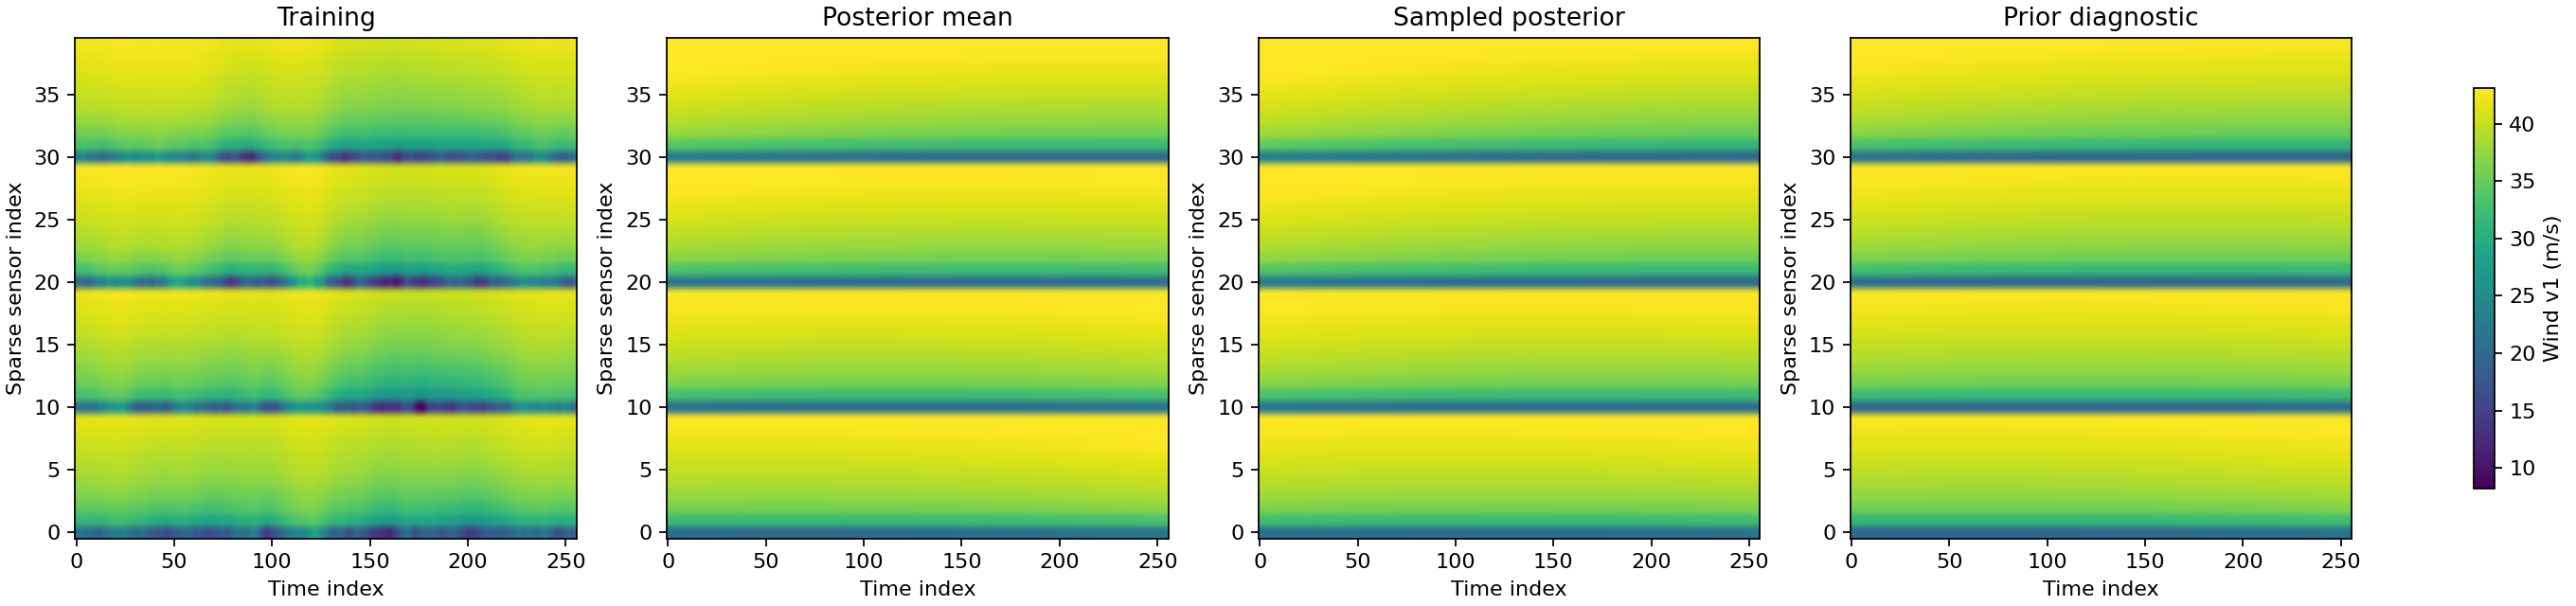


Evidence SHA256: 43f9e91af4b566f4f6069c4251f86495694adcf181b9927ebc9b901143bd5ba1
Source: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/09_posterior_sampling_ablation.json
Previously measured data restored. No new model inference performed.
CELL J COMPLETE — HISTORICAL EVIDENCE RESTORED


In [13]:

# ============================================================
# CELL J v2 — RESTORE POSTERIOR SAMPLING RESULTS
#
# Restart-safe replacement.
# Loads already-completed scientific evidence.
# No VAE loading, no retraining, no new sampling.
# ============================================================

from pathlib import Path
import json
import hashlib
from IPython.display import display, Image

OUT = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

REPORT = OUT / "09_posterior_sampling_ablation.json"
FIGURE = OUT / "09_posterior_sampling_ablation.png"

assert REPORT.is_file(), (
    "Historical posterior-ablation results missing."
)

data = json.loads(REPORT.read_text())

ratios = data["ratios_against_training"]

required = [
    "Posterior mean",
    "Sampled posterior",
    "Prior diagnostic"
]

print("=" * 65)
print("CELL J — RESTORED VAE POSTERIOR ABLATION")
print("=" * 65)

print("Evaluation:", data["evaluation"])
print("Number of training fields:", data["num_fields"])

for name in required:

    assert name in ratios

    m = ratios[name]

    print("\n", name)

    print(
        "Temporal variance retained:",
        round(
            100 * m["temporal_variance"], 4
        ),
        "%"
    )

    print(
        "High-frequency PSD retained:",
        round(
            100 * m["high_frequency_psd"], 4
        ),
        "%"
    )

    print(
        "Between-field variance retained:",
        round(
            100 * m["between_field_variance"], 4
        ),
        "%"
    )

print("\nScientific limitation:")
print(
    "Training-only diagnostic. "
    "Not independent generalization evidence."
)

if FIGURE.is_file():

    print("\nSaved ablation figure:")
    display(Image(filename=str(FIGURE)))

else:

    print("WARNING: Historical figure missing:", FIGURE)

sha = hashlib.sha256(REPORT.read_bytes()).hexdigest()

print("\nEvidence SHA256:", sha)
print("Source:", REPORT)

print(
    "Previously measured data restored. "
    "No new model inference performed."
)

print("CELL J COMPLETE — HISTORICAL EVIDENCE RESTORED")


In [14]:

# CELL K — Research decision summary

import json
from pathlib import Path

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

def load_report(name):
    p = OUT / name
    assert p.exists(), f"Missing {name}. Run Cells I and J first."
    return json.loads(p.read_text())

grad = load_report("08b_coherence_gradient_isolation.json")
posterior = load_report("09_posterior_sampling_ablation.json")

comparisons = grad["comparisons"]
ratios = posterior["ratios_against_training"]

print("=" * 65)
print("WIND VISION — RESEARCH DECISION SUMMARY")
print("=" * 65)

print("\n1. COHERENCE OPTIMIZATION")
for name, result in comparisons.items():
    print(
        name,
        "gradient error:",
        result["relative_gradient_difference"],
        "cosine:",
        result["gradient_cosine"]
    )

print("\n2. STOCHASTIC POSTERIOR FIDELITY")
for name, values in ratios.items():
    print("\n", name)
    print(
        "Temporal variance retained:",
        round(values["temporal_variance"] * 100, 3), "%"
    )
    print(
        "High-frequency PSD retained:",
        round(values["high_frequency_psd"] * 100, 3), "%"
    )
    print(
        "Between-field variance retained:",
        round(values["between_field_variance"] * 100, 3), "%"
    )

vectorized_error = comparisons[
    "vectorization_same_physicsnemo_model"
]["relative_gradient_difference"]

sampled_temporal = ratios[
    "Sampled posterior"
]["temporal_variance"]

print("\n3. NEXT RESEARCH PRIORITIES")

if vectorized_error > 1e-3:
    print(
        "PERFORMANCE: Investigate coherence target arithmetic "
        "and gradient sensitivity before benchmarking optimization."
    )
else:
    print(
        "PERFORMANCE: Gradient tolerance passed. "
        "Proceed to repeated matched timing comparisons."
    )

if sampled_temporal < 0.25:
    print(
        "FIDELITY: Stochastic posterior still retains less than "
        "25% of temporal variance. Prioritize VAE representation "
        "and training-objective investigation."
    )
else:
    print(
        "FIDELITY: Stochastic posterior retains at least 25% "
        "of temporal variance. Investigate the latent flow "
        "distribution and posterior sampling behavior."
    )

summary = {
    "coherence_gradient_relative_error": vectorized_error,
    "sampled_posterior_temporal_variance_ratio": sampled_temporal,
    "gradient_diagnostic": comparisons,
    "posterior_ratios": ratios,
    "evaluation_scope": "Training-only diagnostics"
}

destination = OUT / "10_research_decision_summary.json"
destination.write_text(json.dumps(summary, indent=2))

print("\nSaved:", destination)
print("RESEARCH SUMMARY COMPLETE")


WIND VISION — RESEARCH DECISION SUMMARY

1. COHERENCE OPTIMIZATION
framework_same_original_loss gradient error: 4.996972820929056e-10 cosine: 1.0
vectorization_same_physicsnemo_model gradient error: 0.00368296482816145 cosine: 0.9999932229704855
residual_only_vectorization gradient error: 0.03885348689805523 cosine: 0.999245197590212

2. STOCHASTIC POSTERIOR FIDELITY

 Posterior mean
Temporal variance retained: 4.204 %
High-frequency PSD retained: 4.842 %
Between-field variance retained: 0.0 %

 Sampled posterior
Temporal variance retained: 5.902 %
High-frequency PSD retained: 7.516 %
Between-field variance retained: 1.336 %

 Prior diagnostic
Temporal variance retained: 5.162 %
High-frequency PSD retained: 6.419 %
Between-field variance retained: 3.416 %

3. NEXT RESEARCH PRIORITIES
PERFORMANCE: Investigate coherence target arithmetic and gradient sensitivity before benchmarking optimization.
FIDELITY: Stochastic posterior still retains less than 25% of temporal variance. Prioritize V

In [15]:
# CELL P1 v4 — Wind VISION scope-locked, auditable research recorder
# REPLACE ONLY the cell titled "CELL P1 v3 — WIND VISION RESEARCH PROVENANCE RECORDER"
# Run individually after Google Drive is mounted. No GPU work.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, os, shutil, subprocess, sys, time, uuid

_WV_ROOT = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1').resolve()
assert _WV_ROOT.is_dir(), 'Mount Google Drive and verify physicsnemo_day1 exists.'
assert _WV_ROOT.name == 'physicsnemo_day1'
_wv_ip = get_ipython()
assert _wv_ip is not None

# Unregister any older recorder callbacks, including callbacks left by failed setups.
for _hook_name, _callback in globals().get('_WV_AUDIT_HOOKS', []):
    try: _wv_ip.events.unregister(_hook_name, _callback)
    except (ValueError, KeyError): pass
for _hook_name in ('pre_run_cell', 'post_run_cell'):
    for _callback in list(_wv_ip.events.callbacks.get(_hook_name, [])):
        if (getattr(_callback, '__name__', '') in
            ('before_cell', 'after_cell', 'wv_before_cell', 'wv_after_cell') and
            getattr(_callback, '__module__', '') == '__main__'):
            try: _wv_ip.events.unregister(_hook_name, _callback)
            except (ValueError, KeyError): pass

def _wv_install_recorder(project_root, ip):
    # Every path is captured by a closure. Other notebook cells can reuse ROOT freely.
    root = project_root
    vault = root / '_research_vault'
    objects = vault / 'objects'
    cells = vault / 'cells'
    sessions = vault / 'sessions'
    for p in (objects, cells, sessions): p.mkdir(parents=True, exist_ok=True)
    index_path = vault / 'latest_index.json'
    events_path = vault / 'events.jsonl'
    session = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'-'+uuid.uuid4().hex[:8]

    def now(): return datetime.now(timezone.utc).isoformat()
    def sha(path):
        h=hashlib.sha256()
        with Path(path).open('rb') as f:
            for block in iter(lambda:f.read(8*1024*1024),b''): h.update(block)
        return h.hexdigest()
    def atomic_json(path, data):
        path=Path(path); temp=path.with_name(path.name+'.'+uuid.uuid4().hex+'.tmp')
        try:
            temp.write_text(json.dumps(data,indent=2,default=str))
            os.replace(temp,path)
        finally: temp.unlink(missing_ok=True)
    def event(kind,**extra):
        row=dict(utc=now(),session=session,kind=kind,**extra)
        with events_path.open('a') as f:
            f.write(json.dumps(row,default=str,sort_keys=True)+'\n'); f.flush()

    # Keep the ENTIRE historical index unchanged in a dated backup.
    old_raw=index_path.read_bytes() if index_path.exists() else b'{}'
    old=json.loads(old_raw)
    assert isinstance(old,dict), 'Unexpected vault index structure.'
    backup=sessions/f'{session}_original_index.json'
    backup.write_bytes(old_raw)
    assert backup.read_bytes()==old_raw

    accidental='drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/'
    research_keys=('runtime_source/','executed_cells/','notebook_history/','legacy_versions/')
    active={}; excluded=[]; unresolved=[]; recovered=0; duplicate_versions=0
    for raw_name,record in old.items():
        if not isinstance(raw_name,str) or not isinstance(record,dict):
            unresolved.append({'key':str(raw_name),'reason':'metadata invalid'}); continue
        if raw_name.startswith(accidental):
            key=raw_name[len(accidental):]; recovered+=1
        elif raw_name.startswith('drive/') or raw_name.startswith('/'):
            excluded.append(raw_name); continue
        else:
            key=raw_name
        rel=Path(key)
        if (not key or rel.is_absolute() or '..' in rel.parts or
            rel.parts[0] in ('_research_vault','drive') or
            ('\\' in key)):
            unresolved.append({'key':raw_name,'reason':'unsafe path'}); continue
        # Never reimport unscoped references unrelated to this project.
        if not (raw_name.startswith(accidental) or (root/key).is_file() or
                key.startswith(research_keys)):
            excluded.append(raw_name); continue
        digest=record.get('sha256','')
        if not (isinstance(digest,str) and len(digest)==64 and
                all(c in '0123456789abcdef' for c in digest)):
            unresolved.append({'key':raw_name,'reason':'invalid sha256'}); continue
        obj=objects/digest[:2]/digest
        if not obj.is_file() or sha(obj)!=digest:
            unresolved.append({'key':raw_name,'reason':'missing or corrupt object',
                               'expected_sha256':digest}); continue
        if key in active:
            if active[key]['sha256']==digest: continue
            duplicate_versions+=1
            key=f'legacy_versions/{digest}/{key}'
        active[key]=record

    repair_report=sessions/f'{session}_scope_repair.json'
    atomic_json(repair_report,{
        'utc':now(),'project_root':str(root),'original_index_backup':str(backup),
        'indexed_before':len(old),'out_of_scope_excluded':excluded,
        'references_recovered':recovered,'duplicate_versions_retained':duplicate_versions,
        'unresolved_historical_entries':unresolved,
        'warning':'Legacy archive objects may still contain unrelated personal files; keep vault private.',
        'original_files_deleted':False,'archive_objects_deleted':False})
    atomic_json(index_path,active)

    def archive(source,key):
        source=Path(source)
        st=source.stat()
        prev=active.get(key)
        if prev and prev.get('size')==st.st_size and prev.get('mtime_ns')==st.st_mtime_ns:
            expected=prev['sha256']; obj=objects/expected[:2]/expected
            if obj.is_file(): return None
        digest=sha(source); obj=objects/digest[:2]/digest
        obj.parent.mkdir(parents=True,exist_ok=True)
        if not obj.exists():
            temp=obj.with_name(obj.name+'.'+uuid.uuid4().hex+'.tmp')
            try:
                shutil.copyfile(source,temp)
                if sha(temp)!=digest: raise RuntimeError(f'Source changed while archiving {source}')
                os.replace(temp,obj)
            finally: temp.unlink(missing_ok=True)
        elif sha(obj)!=digest:
            raise RuntimeError(f'Archive object hash mismatch: {obj}')
        active[key]={'sha256':digest,'size':st.st_size,'mtime_ns':st.st_mtime_ns,
                     'object':str(obj.relative_to(vault))}
        return {'key':key,'sha256':digest,'bytes':st.st_size}

    def snapshot(reason='manual'):
        changed=[]; errors=[]
        # Only files inside the fixed project root; never /content or all of MyDrive.
        for file in root.rglob('*'):
            if (not file.is_file() or file.is_symlink() or vault in file.parents or
                file.suffix in ('.tmp','.partial','.pyc')): continue
            try:
                item=archive(file,file.relative_to(root).as_posix())
                if item: changed.append(item)
            except Exception as e: errors.append({'file':str(file),'error':repr(e)})
        # Only explicitly allow this one runtime source file outside the project.
        runtime=Path('/content/wind_vision_physicsnemo_day1.py')
        if runtime.is_file():
            try:
                item=archive(runtime,'runtime_source/wind_vision_physicsnemo_day1.py')
                if item: changed.append(item)
            except Exception as e: errors.append({'file':str(runtime),'error':repr(e)})
        atomic_json(index_path,active)
        event('snapshot',reason=reason,changed=changed,errors=errors)
        if errors: raise RuntimeError('RESEARCH ARCHIVE SNAPSHOT FAILURE: '+str(errors))
        return changed

    def verify():
        bad=[]
        for key,item in active.items():
            digest=item['sha256']; obj=objects/digest[:2]/digest
            if not obj.is_file() or sha(obj)!=digest: bad.append(key)
        if bad: raise RuntimeError('ACTIVE RESEARCH ARCHIVE INTEGRITY FAILED: '+repr(bad))
        return len(active)

    def note(title,question,methods,evidence,findings,limitations,decision):
        data=dict(title=title,question=question,methods=methods,evidence=evidence,
                  findings=findings,limitations=limitations,decision=decision)
        event('research_note',**data)
        with (vault/'lab_notebook.md').open('a') as f:
            f.write(f'\n## {now()} — {title}\n\n')
            for k,v in data.items(): f.write(f'**{k}:** {json.dumps(v,default=str)}\n\n')

    # Recover previously patched source only if missing from the live runtime.
    live=Path('/content/wind_vision_physicsnemo_day1.py')
    saved=root/'wind_vision_physicsnemo_day1_patched.py'
    if not live.exists() and saved.is_file():
        shutil.copy2(saved,live)
        print('Restored patched source from Drive:',live)

    # Capture the setup cell itself when IPython exposes the current input.
    try:
        raw=ip.history_manager.input_hist_raw[-1]
        if 'CELL P1 v4' in raw:
            bootstrap=cells/f'{session}_P1_recorder_bootstrap.py'
            bootstrap.write_text(raw)
            archive(bootstrap,'executed_cells/'+bootstrap.name)
    except Exception as e:
        print('Recorder source capture warning:',repr(e))

    first=snapshot('P1_scope_lock_initial'); checked=verify()
    environment={'utc':now(),'session':session,'python':sys.version,'research_root':str(root),
                 'reference_commit_expected':'921e666c8d6060ae13bfd901dcc7f74f819d0eea'}
    try:
        import torch,importlib.metadata
        environment['pytorch']=torch.__version__
        environment['gpu']=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
        environment['physicsnemo']=importlib.metadata.version('nvidia-physicsnemo')
    except Exception as e: environment['environment_probe_warning']=repr(e)
    repo=Path('/content/nasa_clfm_reference')
    if (repo/'.git').exists():
        for label,args in [('git_head',['rev-parse','HEAD']),('git_status',['status','--porcelain'])]:
            p=subprocess.run(['git','-C',str(repo)]+args,capture_output=True,text=True)
            environment[label]=p.stdout.strip() if p.returncode==0 else f'ERROR: {p.stderr}'
    atomic_json(sessions/f'{session}_environment.json',environment)
    event('recorder_started',verified=checked,foreign_excluded=len(excluded),unresolved=len(unresolved))
    current={}
    def wv_before_cell(info):
        current['id']=uuid.uuid4().hex[:12]
        current['t0']=time.perf_counter()
        try:
            f=cells/f"{session}_{current['id']}.py"
            f.write_text(info.raw_cell)
            item=archive(f,'executed_cells/'+f.name)
            atomic_json(index_path,active)
            event('cell_started',cell_id=current['id'],source_sha256=(item or {}).get('sha256',sha(f)))
        except Exception as e:
            print('CRITICAL RESEARCH LOGGING FAILURE (before):',repr(e),file=sys.stderr)
    def wv_after_cell(result):
        failure=result.error_before_exec or result.error_in_exec
        try:
            changed=snapshot('after_cell')
            event('cell_finished',cell_id=current.get('id'),success=(failure is None),
                  error=repr(failure) if failure else None,
                  duration_seconds=time.perf_counter()-current.get('t0',time.perf_counter()),
                  changed_artifacts=len(changed))
        except Exception as e:
            print('CRITICAL RESEARCH LOGGING FAILURE (after):',repr(e),file=sys.stderr)
    ip.events.register('pre_run_cell',wv_before_cell)
    ip.events.register('post_run_cell',wv_after_cell)
    return {'verify':verify,'snapshot':snapshot,'note':note,'event':event,
            'hooks':[('pre_run_cell',wv_before_cell),('post_run_cell',wv_after_cell)],
            'root':root,'vault':vault,'session':session,'verified':checked,
            'excluded':len(excluded),'recovered':recovered,'unresolved':len(unresolved),
            'repair_report':repair_report,'initial_changed':len(first)}

_WV_RECORDER = _wv_install_recorder(_WV_ROOT,_wv_ip)
_WV_AUDIT_HOOKS = _WV_RECORDER['hooks']
verify = _WV_RECORDER['verify']
snapshot = _WV_RECORDER['snapshot']
note = _WV_RECORDER['note']
event = _WV_RECORDER['event']

print('\n'+'='*65)
print('WIND VISION — SCOPE-LOCKED RESEARCH RECORDING ACTIVE')
print('='*65)
print('Research root:',_WV_RECORDER['root'])
print('Verified active research entries:',_WV_RECORDER['verified'])
print('Out-of-scope references excluded:',_WV_RECORDER['excluded'])
print('Previously miskeyed research references recovered:',_WV_RECORDER['recovered'])
print('Unresolved historical references:',_WV_RECORDER['unresolved'])
print('Repair report:',_WV_RECORDER['repair_report'])
print('Automatic future-cell logging: ACTIVE')
print('PASS — ACTIVE RESEARCH INDEX VERIFIED')
if _WV_RECORDER['unresolved']:
    print('WARNING: Some HISTORICAL references remain unresolved. See repair report.')
print('Keep the legacy vault private until its unrelated historical objects are reviewed.')



WIND VISION — SCOPE-LOCKED RESEARCH RECORDING ACTIVE
Research root: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1
Verified active research entries: 574
Out-of-scope references excluded: 0
Previously miskeyed research references recovered: 0
Unresolved historical references: 0
Repair report: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/_research_vault/sessions/20261102T151524Z-8a1f6151_scope_repair.json
Automatic future-cell logging: ACTIVE
PASS — ACTIVE RESEARCH INDEX VERIFIED
Keep the legacy vault private until its unrelated historical objects are reviewed.


In [16]:
# CELL P2 v2 — Idempotent research-methods record and integrity checkpoint
# REPLACE the previous "WIND VISION — FORMAL RESEARCH RECORD" cell.
from pathlib import Path
import json, hashlib

assert callable(globals().get('verify')) and callable(globals().get('note')), 'Run NEW P1 first.'
_project = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
_vault = _project/'_research_vault'

# Pin critical evidence. No need to load GPU or perform any training.
required = [
    '01_full_objective_parity.json',
    '02_same_l4_full_step_benchmark.json',
    '03_native_checkpoint_status.json',
    'latent_flow/flow_demo_metrics.json',
    'latent_flow/paired_flow_state.pt',
    'latent_flow/unconditional_samples.pt',
    '07_training_only_fidelity_audit.json',
    '08_vectorized_coherence_validation.json',
    '08b_coherence_gradient_isolation.json',
    '09_posterior_sampling_ablation.json',
    '10_research_decision_summary.json',
    '11_coherence_target_precision.json',
    '12_shared_graph_target_gradient_sensitivity.json',
    '13_coherence_gradient_precision_decomposition.json',
    'wind_vision_physicsnemo_day1_patched.py',
]
missing=[p for p in required if not (_project/p).is_file()]
if missing:
    raise RuntimeError('Required research evidence missing: '+repr(missing))

methods_file=_project/'RESEARCH_METHODS_AND_CONTROLS.md'
if not methods_file.exists():
    methods_file.write_text('# Wind VISION — Research Methods and Controls\n')

# Write a versioned supplement; never overwrite the earlier methods narrative.
text='''# Wind VISION — Provenance and scientific reporting policy (v2)

- Reference: NASA random_field_c-lfm, pinned commit 921e666c8d6060ae13bfd901dcc7f74f819d0eea.
- Data: training-only synthetic wind diagnostic, 40 sparse sensors, 256 temporal points per field.
- VAE: trusted ten-epoch checkpoint. It is NOT a converged 15,000-epoch reproduction.
- Native PhysicsNeMo VAE: full reference objective and gradient parity validated on fixed batches.
- Matched L4 benchmark: no demonstrated speedup close to 2x; initial pilot is short.
- Latent flow: 32-step functional pilot, fixed RK4-32 solver; NOT a converged generative baseline.
- Current fidelity: severe temporal variance suppression; no independent holdout claim.
- Vectorized coherence target: gradient parity FAILED. Do not claim this optimization as equivalent.
- Paired VAE continuation: compare same starting weights and matched steps. The diagnostic
  examples are disjoint only from continuation steps, not from the pretrained checkpoint's
  past training population. It is NOT a holdout generalization experiment.
- For every subsequent experiment: save a unique manifest, exact source/commit, input hashes,
  seeds, hyperparameters, hardware/software, failure logs, numeric outputs, and limitations.
- Archive verification establishes SHA-256 consistency of active indexed objects; it does
  NOT prove every historical object was recoverable or every experiment is scientifically valid.
- Treat the vault as PRIVATE. Prior scope bug archived unrelated files; historical objects
  require a privacy review before public sharing. Never upload raw vault or datasets publicly.
- Future publication requires independent split, repeated seeds and uncertainty estimates,
  published baselines, ablations, clear authorship and applicable NASA release permissions.
'''
policy=_project/'RESEARCH_PROVENANCE_POLICY_v2.md'
if not policy.exists() or policy.read_text()!=text:
    policy.write_text(text)

# Idempotent journal seeding by evidence SHA — repeated P2 does not add duplicate notes.
critical=[_project/n for n in required if n.endswith('.json')]
evidence_signature=hashlib.sha256((''.join(
    p.relative_to(_project).as_posix()+':'+hashlib.sha256(p.read_bytes()).hexdigest()+'\n'
    for p in critical)).encode()).hexdigest()
marker=_vault/f'methods_seed_{evidence_signature[:16]}.json'
if not marker.exists():
    note(
        title='Validated integration and unresolved fidelity/acceleration blockers',
        question='What is currently reproducible, validated, and limited?',
        methods=('Pinned NASA reference, verified trained VAE, native PhysicsNeMo transfer, '
                 'full objective+gradient parity, matched-L4 pilot, 32-step flow, '
                 'posterior sampling and coherence-target numerical ablations.'),
        evidence=required + [policy.name],
        findings={
            'native_integration':'functional with fixed-batch parity',
            'speedup_2x':'not demonstrated',
            'wind_fidelity':'temporal variability greatly suppressed',
            'vectorized_coherence':'gradient parity failed',
            'latest_evidence_signature':evidence_signature},
        limitations=['training-only fidelity comparisons','short flow training',
                     'undertrained VAE checkpoint','no independent holdout or repeated benchmark'],
        decision='Analyze saved paired VAE continuation results before new GPU training.'
    )
    marker.write_text(json.dumps({'signature':evidence_signature,
                                  'evidence_files':required},indent=2))
    print('Added new versioned scientific journal entry.')
else:
    print('Scientific journal entry already exists for this exact evidence set.')

changed=snapshot('P2_methods_checkpoint')
count=verify()
print('\nPASS — METHODS AND PROVENANCE CHECKPOINT')
print('Required evidence files:',len(required),'missing:',len(missing))
print('Verified active archive entries:',count)
print('Methods policy:',policy)
print('Events:',_vault/'events.jsonl')
print('Research journal:',_vault/'lab_notebook.md')
print('New or changed archived artifacts:',len(changed))


Added new versioned scientific journal entry.

PASS — METHODS AND PROVENANCE CHECKPOINT
Required evidence files: 15 missing: 0
Verified active archive entries: 575
Methods policy: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/RESEARCH_PROVENANCE_POLICY_v2.md
Events: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/_research_vault/events.jsonl
Research journal: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/_research_vault/lab_notebook.md
New or changed archived artifacts: 0


In [17]:

# CELL L — Analytical coherence target precision audit
# Automatically archived by the active research recorder.

import json
import torch
from pathlib import Path

assert all(
    name in globals()
    for name in ("original_wind", "original_loss", "nemo", "note")
), "Run Cells H and P1 in this runtime first."

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

torch.manual_seed(801)

n = original_loss.num_colloc
coordinates = nemo.grid.sample(2 * n)[:, :3]
x1, x2 = coordinates.chunk(2, dim=0)

freq = original_loss._freq_grid
freq_cpu = freq.detach().cpu()
a_cpu = x1.detach().cpu()
b_cpu = x2.detach().cpu()

# Original NASA target calculation
with torch.no_grad():
    reference = torch.stack([
        torch.tensor([
            original_wind.get_true_coherence(
                f, a_cpu[i], b_cpu[i]
            ) ** 2
            for f in freq_cpu
        ])
        for i in range(n)
    ]).to(device="cuda", dtype=torch.float64)

    coefficients = torch.tensor(
        original_wind.C,
        dtype=torch.float64,
        device="cuda"
    )

    a64 = x1.double()
    b64 = x2.double()

    # Current candidate: promote coordinates before subtraction
    distance64 = torch.linalg.vector_norm(
        (a64 - b64) * coefficients, dim=-1
    )

    # Alternative: subtract in float32 before promotion
    distance32 = torch.linalg.vector_norm(
        (x1 - x2).double() * coefficients,
        dim=-1
    )

    mean_a = (
        2.5 * original_wind.U_STAR *
        torch.log(a64[:, 2] / original_wind.Z_0)
    )
    mean_b = (
        2.5 * original_wind.U_STAR *
        torch.log(b64[:, 2] / original_wind.Z_0)
    )

    denom = mean_a.abs() + mean_b.abs()
    f64 = freq.double()

    target64 = torch.exp(
        -f64[None, :] * distance64[:, None]
        / denom[:, None]
    ).square()

    target32 = torch.exp(
        -f64[None, :] * distance32[:, None]
        / denom[:, None]
    ).square()

def compare_target(candidate):
    delta = (reference - candidate).abs()
    return {
        "max_absolute": float(delta.max()),
        "mean_absolute": float(delta.mean()),
        "rms": float(
            delta.square().mean().sqrt()
        ),
        "elements_over_1e-8": int(
            (delta > 1e-8).sum()
        ),
        "elements_over_1e-7": int(
            (delta > 1e-7).sum()
        ),
        "total_elements": delta.numel()
    }

report = {
    "experiment": "Analytical coherence target precision",
    "reference_commit":
        "921e666c8d6060ae13bfd901dcc7f74f819d0eea",
    "seed": 801,
    "collocation_pairs": n,
    "frequency_bins": len(freq),
    "original_vs_float64_subtraction":
        compare_target(target64),
    "original_vs_float32_subtraction":
        compare_target(target32),
    "limitations": [
        "Single fixed-collocation diagnostic",
        "Target agreement does not prove gradient parity",
        "Floating-point operation ordering may differ",
        "No acceleration benchmark performed"
    ]
}

path = OUT / "11_coherence_target_precision.json"
path.write_text(json.dumps(report, indent=2))

note(
    title="Coherence analytical target numerical precision",
    question=(
        "Does subtraction precision explain the "
        "vectorized analytical target discrepancy?"
    ),
    methods=(
        "Matched collocation coordinates and frequencies; "
        "original NASA target compared with float64-first "
        "and float32-first GPU calculations."
    ),
    evidence=[str(path)],
    findings=report,
    limitations=report["limitations"],
    decision=(
        "Use target discrepancies to guide further "
        "gradient-parity investigation. Do not claim "
        "numerical equivalence from forward loss alone."
    )
)

print("=" * 60)
print("COHERENCE TARGET PRECISION RESULTS")
print("=" * 60)
print(json.dumps(report, indent=2))
print("Saved:", path)
print("Research journal updated.")
print("Automatic archival active.")


COHERENCE TARGET PRECISION RESULTS
{
  "experiment": "Analytical coherence target precision",
  "reference_commit": "921e666c8d6060ae13bfd901dcc7f74f819d0eea",
  "seed": 801,
  "collocation_pairs": 16,
  "frequency_bins": 65,
  "original_vs_float64_subtraction": {
    "max_absolute": 2.101638327811628e-07,
    "mean_absolute": 2.113371991127397e-08,
    "rms": 3.528391233223575e-08,
    "elements_over_1e-8": 510,
    "elements_over_1e-7": 28,
    "total_elements": 1040
  },
  "original_vs_float32_subtraction": {
    "max_absolute": 2.1320116938561284e-07,
    "mean_absolute": 2.0937663604875916e-08,
    "rms": 3.525550261312795e-08,
    "elements_over_1e-8": 509,
    "elements_over_1e-7": 30,
    "total_elements": 1040
  },
  "limitations": [
    "Single fixed-collocation diagnostic",
    "Target agreement does not prove gradient parity",
    "Floating-point operation ordering may differ",
    "No acceleration benchmark performed"
  ]
}
Saved: /content/drive/MyDrive/CLFM_Research_Resul

In [18]:

# CELL M — Same-graph coherence target sensitivity
# Requires Cells H and P1 in the current runtime.

import json
from pathlib import Path
import torch

required = (
    "nemo", "u", "eps", "original_loss",
    "original_wind", "note"
)
missing = [name for name in required if name not in globals()]
assert not missing, f"Missing variables: {missing}. Run H and P1 first."

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
OUT.mkdir(parents=True, exist_ok=True)

nemo.train()
assert u.shape[1:] == (40, 256)
assert next(nemo.parameters()).dtype == torch.float32

# ------------------------------------------------------------
# 1. Construct ONE shared computation graph.
# ------------------------------------------------------------

mu, logvar = nemo.encode(u)
z = mu + torch.exp(0.5 * logvar) * eps

n = original_loss.num_colloc
T = original_loss.T

torch.manual_seed(801)

space_coords = nemo.grid.sample(2 * n)[:, :3]
a, b = space_coords.chunk(2, dim=0)

space = space_coords.reshape(
    1, 2*n, 1, 3
).repeat(z.shape[0], 1, T, 1)

tgrid = original_loss._fixed_dense_t.to(
    device=z.device,
    dtype=space.dtype
).repeat(z.shape[0], 2*n, 1, 1)

pts = torch.cat(
    (space, tgrid), dim=-1
).reshape(z.shape[0], -1, nemo.grid.ndim)

wind = nemo.decode(
    z, pts
).reshape(z.shape[0], 2*n, T)

first, second = wind.chunk(2, dim=1)

coh = original_wind.v_coherence(
    first, second,
    nperseg=T,
    window=original_loss._hann_window
)

# ------------------------------------------------------------
# 2. Construct THREE analytical targets.
# ------------------------------------------------------------

freq = original_loss._freq_grid
acpu = a.detach().cpu()
bcpu = b.detach().cpu()
fcpu = freq.detach().cpu()

with torch.no_grad():

    # Exact original NASA CPU/NumPy target algorithm.
    nasa_target = torch.stack([
        torch.tensor([
            original_wind.get_true_coherence(
                f, acpu[i], bcpu[i]
            ) ** 2
            for f in fcpu
        ])
        for i in range(n)
    ]).to(coh.device)

    coeff = torch.tensor(
        original_wind.C,
        dtype=torch.float64,
        device=coh.device
    )

    a64, b64 = a.double(), b.double()

    vel_a = (
        2.5 * original_wind.U_STAR
        * torch.log(a64[:, 2] / original_wind.Z_0)
    )

    vel_b = (
        2.5 * original_wind.U_STAR
        * torch.log(b64[:, 2] / original_wind.Z_0)
    )

    denominator = vel_a.abs() + vel_b.abs()
    freq64 = freq.double()

    dist64 = torch.linalg.vector_norm(
        (a64 - b64) * coeff, dim=-1
    )

    dist32 = torch.linalg.vector_norm(
        (a - b).double() * coeff, dim=-1
    )

    target_doublefirst = torch.exp(
        -freq64[None] * dist64[:, None]
        / denominator[:, None]
    ).square()

    target_floatfirst = torch.exp(
        -freq64[None] * dist32[:, None]
        / denominator[:, None]
    ).square()

assert (
    nasa_target.shape
    == coh.shape
    == target_doublefirst.shape
)

assert torch.isfinite(coh).all()

targets = {
    "nasa_cpu_numpy": nasa_target,
    "gpu_double_first": target_doublefirst,
    "gpu_float32_subtract_first": target_floatfirst
}

# ------------------------------------------------------------
# 3. Compare residual gradients on SAME computation graph.
# ------------------------------------------------------------

parameters = [
    (name, p)
    for name, p in nemo.named_parameters()
    if p.requires_grad
]

results = {}

for index, (label, target) in enumerate(targets.items()):

    loss = (target - coh).square().mean()

    grads = torch.autograd.grad(
        loss,
        [p for _, p in parameters],
        retain_graph=index < len(targets)-1,
        allow_unused=True
    )

    results[label] = {
        "loss": float(loss.detach()),
        "grads": {
            name: g.detach().double().cpu()
            for (name, _), g in zip(parameters, grads)
            if g is not None
        }
    }

# ------------------------------------------------------------
# 4. Quantify absolute and relative gradient changes.
# ------------------------------------------------------------

def compare_to_nasa(label):

    reference = results["nasa_cpu_numpy"]["grads"]
    candidate = results[label]["grads"]

    assert reference.keys() == candidate.keys()

    base_sq = sum(
        v.square().sum().item()
        for v in reference.values()
    )

    delta_sq = sum(
        (reference[k] - candidate[k]).square().sum().item()
        for k in reference
    )

    candidate_sq = sum(
        v.square().sum().item()
        for v in candidate.values()
    )

    dot = sum(
        (reference[k] * candidate[k]).sum().item()
        for k in reference
    )

    per_parameter = sorted(
        [
            {
                "name": k,
                "baseline_l2": float(v.norm()),
                "difference_l2": float(
                    (v - candidate[k]).norm()
                )
            }
            for k, v in reference.items()
        ],
        key=lambda item: item["difference_l2"],
        reverse=True
    )

    return {
        "relative_residual_gradient_difference":
            delta_sq**0.5 / max(base_sq**0.5, 1e-12),

        "absolute_residual_gradient_difference_l2":
            delta_sq**0.5,

        "reference_residual_gradient_l2":
            base_sq**0.5,

        "gradient_cosine":
            dot / max(
                (base_sq * candidate_sq)**0.5,
                1e-24
            ),

        "target_max_abs_error": float(
            (nasa_target - targets[label]).abs().max()
        ),

        "per_parameter": per_parameter
    }

comparison = {
    label: compare_to_nasa(label)
    for label in list(targets)[1:]
}

# ------------------------------------------------------------
# 5. Persist results and methods.
# ------------------------------------------------------------

report = {
    "experiment":
        "same_graph_coherence_target_gradient_sensitivity",
    "scope":
        "Fixed VAE, latent noise, collocation coordinates "
        "and coherence graph",
    "gpu": torch.cuda.get_device_name(0),
    "batch_size": int(u.shape[0]),
    "dtype": str(coh.dtype),
    "collocation_seed": 801,
    "losses": {
        key: value["loss"]
        for key, value in results.items()
    },
    "comparisons": comparison,
    "limitations": [
        "Single fixed batch and collocation sample",
        "Residual-only gradient diagnosis",
        "Not a training benchmark",
        "No claim of gradient parity or acceleration"
    ]
}

path = OUT / "12_shared_graph_target_gradient_sensitivity.json"
path.write_text(
    json.dumps(report, indent=2, allow_nan=False)
)

print("=" * 60)
print("SHARED-GRAPH COHERENCE TARGET DIAGNOSTIC")
print("=" * 60)

print(
    "NASA residual:",
    report["losses"]["nasa_cpu_numpy"]
)

for name, item in comparison.items():

    print("\n", name)

    for key in (
        "target_max_abs_error",
        "reference_residual_gradient_l2",
        "absolute_residual_gradient_difference_l2",
        "relative_residual_gradient_difference",
        "gradient_cosine"
    ):
        print(" ", key, ":", item[key])

    print(
        "Top changed parameter:",
        item["per_parameter"][0]
    )

print("\nSaved:", path)

note(
    title="Same-graph coherence target gradient sensitivity",
    question=(
        "Are small analytical-target differences alone "
        "responsible for residual gradient divergence?"
    ),
    methods=(
        "Reuse a single decoded coherence computation "
        "graph and fixed collocation sample, "
        "changing only the prescribed target."
    ),
    evidence=[str(path)],
    findings={
        name: {
            k: v
            for k, v in item.items()
            if k != "per_parameter"
        }
        for name, item in comparison.items()
    },
    limitations=report["limitations"],
    decision=(
        "Determine whether exact NASA target arithmetic "
        "must be retained before performance optimization."
    )
)

print("Research journal updated.")
print("P1 archive will preserve the experiment.")
print("CELL M COMPLETE")


SHARED-GRAPH COHERENCE TARGET DIAGNOSTIC
NASA residual: 0.0965852364897728

 gpu_double_first
  target_max_abs_error : 2.101638327811628e-07
  reference_residual_gradient_l2 : 0.8339947540979851
  absolute_residual_gradient_difference_l2 : 0.03240360425298521
  relative_residual_gradient_difference : 0.03885348689996454
  gradient_cosine : 0.9992451975901281
Top changed parameter: {'name': '_branch.blocks.1.net.4.weight', 'baseline_l2': 0.42868643863817346, 'difference_l2': 0.023126164698909223}

 gpu_float32_subtract_first
  target_max_abs_error : 2.1320116938561284e-07
  reference_residual_gradient_l2 : 0.8339947540979851
  absolute_residual_gradient_difference_l2 : 0.036955306154701946
  relative_residual_gradient_difference : 0.04431119737038551
  gradient_cosine : 0.9990179806055911
Top changed parameter: {'name': '_branch.blocks.1.net.4.weight', 'baseline_l2': 0.42868643863817346, 'difference_l2': 0.027309492316673987}

Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsn

In [19]:

# ============================================================
# CELL N — COHERENCE GRADIENT PRECISION DECOMPOSITION
#
# Separate:
# 1. Float32 versus float64 residual arithmetic
# 2. Differences in analytical target values
# 3. Whether casting the GPU target back to float32
#    restores acceptable gradient parity
#
# Uses ONE shared coherence computation graph.
# No training or benchmark claims.
# ============================================================

import torch
import json
from pathlib import Path

required_names = [
    "nemo", "u", "eps", "original_loss",
    "original_wind", "note"
]

missing = [
    name for name in required_names
    if name not in globals()
]

assert not missing, (
    f"Missing variables: {missing}. "
    "Run Cells H, M and P1 in this runtime."
)

OUT = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

torch.manual_seed(801)
torch.cuda.manual_seed_all(801)

nemo.train()

# ------------------------------------------------------------
# 1. Construct one common coherence computation graph
# ------------------------------------------------------------

mu, logvar = nemo.encode(u)

z = mu + torch.exp(0.5 * logvar) * eps

n = original_loss.num_colloc
T = original_loss.T
B = z.shape[0]

coordinates = nemo.grid.sample(2 * n)[:, :3]
a, b = coordinates.chunk(2, dim=0)

space = coordinates.reshape(
    1, 2*n, 1, 3
).repeat(B, 1, T, 1)

times = original_loss._fixed_dense_t.to(
    device=z.device,
    dtype=z.dtype
).repeat(B, 2*n, 1, 1)

points = torch.cat(
    [space, times], dim=-1
).reshape(B, -1, nemo.grid.ndim)

wind = nemo.decode(
    z, points
).reshape(B, 2*n, T)

y1, y2 = wind.chunk(2, dim=1)

coherence = original_wind.v_coherence(
    y1, y2,
    nperseg=T,
    window=original_loss._hann_window
)

assert coherence.dtype == torch.float32

# ------------------------------------------------------------
# 2. Reproduce NASA's exact original target computation
# ------------------------------------------------------------

freq = original_loss._freq_grid

acpu = a.detach().cpu()
bcpu = b.detach().cpu()
fcpu = freq.detach().cpu()

with torch.no_grad():

    nasa_target = torch.stack([
        torch.tensor([
            original_wind.get_true_coherence(
                f, acpu[i], bcpu[i]
            ) ** 2
            for f in fcpu
        ])
        for i in range(n)
    ]).to(coherence.device)

    assert nasa_target.dtype == torch.float32

    coefficients = torch.tensor(
        original_wind.C,
        device=coherence.device,
        dtype=torch.float64
    )

    a64 = a.double()
    b64 = b.double()

    va = (
        2.5 * original_wind.U_STAR
        * torch.log(
            a64[:, 2] / original_wind.Z_0
        )
    )

    vb = (
        2.5 * original_wind.U_STAR
        * torch.log(
            b64[:, 2] / original_wind.Z_0
        )
    )

    denominator = va.abs() + vb.abs()

    distance_double = torch.linalg.vector_norm(
        (a64 - b64) * coefficients,
        dim=-1
    )

    distance_floatfirst = torch.linalg.vector_norm(
        (a - b).double() * coefficients,
        dim=-1
    )

    frequencies = freq.double()

    gpu_double = torch.exp(
        -frequencies[None, :]
        * distance_double[:, None]
        / denominator[:, None]
    ).square()

    gpu_floatfirst = torch.exp(
        -frequencies[None, :]
        * distance_floatfirst[:, None]
        / denominator[:, None]
    ).square()

# ------------------------------------------------------------
# 3. Five precision-controlled comparisons
# ------------------------------------------------------------

variants = {
    "nasa_float32":
        nasa_target,

    "nasa_values_promoted_float64":
        nasa_target.double(),

    "gpu_double_target_float64":
        gpu_double,

    "gpu_double_target_cast_float32":
        gpu_double.float(),

    "gpu_floatfirst_target_cast_float32":
        gpu_floatfirst.float()
}

parameters = [
    (name, p)
    for name, p in nemo.named_parameters()
    if p.requires_grad
]

gradient_results = {}

for i, (name, target) in enumerate(variants.items()):

    residual = (
        target - coherence
    ).square().mean()

    gradients = torch.autograd.grad(
        residual,
        [p for _, p in parameters],
        retain_graph=i < len(variants)-1,
        allow_unused=True
    )

    gradient_results[name] = {
        "residual": float(residual.detach()),
        "residual_dtype": str(residual.dtype),
        "target_dtype": str(target.dtype),
        "gradients": {
            pname: g.detach().double().cpu()
            for (pname, _), g
            in zip(parameters, gradients)
            if g is not None
        }
    }

# ------------------------------------------------------------
# 4. Compare gradients using NASA float32 as reference
# ------------------------------------------------------------

def compare(reference_name, candidate_name):

    reference = gradient_results[reference_name]
    candidate = gradient_results[candidate_name]

    g0 = reference["gradients"]
    g1 = candidate["gradients"]

    assert g0.keys() == g1.keys()

    norm_sq = sum(
        v.square().sum().item()
        for v in g0.values()
    )

    diff_sq = sum(
        (g0[k] - g1[k]).square().sum().item()
        for k in g0
    )

    candidate_sq = sum(
        v.square().sum().item()
        for v in g1.values()
    )

    dot = sum(
        (g0[k] * g1[k]).sum().item()
        for k in g0
    )

    return {
        "relative_gradient_difference":
            diff_sq**0.5 / max(norm_sq**0.5, 1e-12),

        "absolute_gradient_difference_l2":
            diff_sq**0.5,

        "reference_gradient_l2":
            norm_sq**0.5,

        "gradient_cosine":
            dot / max(
                (norm_sq * candidate_sq)**0.5,
                1e-24
            ),

        "relative_residual_difference":
            abs(
                reference["residual"]
                - candidate["residual"]
            ) / max(abs(reference["residual"]), 1e-12)
    }

base_name = "nasa_float32"

comparisons = {
    name: compare(base_name, name)
    for name in list(variants)[1:]
}

# ------------------------------------------------------------
# 5. Save detailed results and research interpretation
# ------------------------------------------------------------

report = {
    "experiment":
        "coherence_gradient_precision_decomposition",

    "reference":
        "NASA original float32 residual",

    "model":
        "PhysicsNeMo VAE with fixed pretrained weights",

    "batch_size": int(B),
    "collocation_pairs": int(n),
    "time_samples": int(T),
    "seed": 801,

    "comparison_design": (
        "Same computation graph, parameters, decoded "
        "signals, coherence and collocation locations. "
        "Only analytical target values or their dtype change."
    ),

    "residuals": {
        name: {
            "value": result["residual"],
            "dtype": result["residual_dtype"],
            "target_dtype": result["target_dtype"]
        }
        for name, result in gradient_results.items()
    },

    "comparisons": comparisons,

    "target_max_abs_difference": {
        name: float(
            (nasa_target.double()
             - target.double()).abs().max()
        )
        for name, target in variants.items()
        if name != base_name
    },

    "gradient_tolerance": 1e-3,

    "limitations": [
        "Single fixed batch",
        "Single collocation realization",
        "Residual-only gradient comparison",
        "No model training",
        "No acceleration benchmark"
    ]
}

output_path = (
    OUT / "13_coherence_gradient_precision_decomposition.json"
)

output_path.write_text(
    json.dumps(
        report, indent=2, allow_nan=False
    )
)

print("=" * 65)
print("COHERENCE GRADIENT PRECISION DECOMPOSITION")
print("=" * 65)

print(
    "NASA baseline residual:",
    gradient_results[base_name]["residual"]
)

for name, result in comparisons.items():

    print("\n", name)

    print(
        " Relative gradient difference:",
        result["relative_gradient_difference"]
    )

    print(
        " Gradient cosine:",
        result["gradient_cosine"]
    )

    print(
        " Relative residual difference:",
        result["relative_residual_difference"]
    )

print("\nGRADIENT PARITY CHECKS")

for name, result in comparisons.items():

    passed = (
        result["relative_gradient_difference"]
        <= 1e-3
    )

    print(
        name, "PASS" if passed else "FAIL"
    )

note(
    title="Coherence residual precision decomposition",

    question=(
        "How much gradient discrepancy comes from "
        "loss arithmetic precision versus the "
        "analytical target's numerical values?"
    ),

    methods=report["comparison_design"],

    evidence=[str(output_path)],

    findings=comparisons,

    limitations=report["limitations"],

    decision=(
        "Retain the original NASA constraint as the "
        "validated baseline. Only consider an "
        "optimized target after gradient parity "
        "and repeated-seed verification."
    )
)

print("\nSaved:", output_path)
print("Research journal updated.")
print("CELL N COMPLETE")


COHERENCE GRADIENT PRECISION DECOMPOSITION
NASA baseline residual: 0.0965852364897728

 nasa_values_promoted_float64
 Relative gradient difference: 0.036437016759756205
 Gradient cosine: 0.9993371561357778
 Relative residual difference: 2.475158338932783e-08

 gpu_double_target_float64
 Relative gradient difference: 0.038853486900474334
 Gradient cosine: 0.9992451975901138
 Relative residual difference: 8.816257325280766e-09

 gpu_double_target_cast_float32
 Relative gradient difference: 0.027913212769463305
 Gradient cosine: 0.999611970935029
 Relative residual difference: 0.0

 gpu_floatfirst_target_cast_float32
 Relative gradient difference: 0.033880618098032306
 Gradient cosine: 0.9994259581054054
 Relative residual difference: 0.0

GRADIENT PARITY CHECKS
nasa_values_promoted_float64 FAIL
gpu_double_target_float64 FAIL
gpu_double_target_cast_float32 FAIL
gpu_floatfirst_target_cast_float32 FAIL

Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/13_coherence_gradie

Dataset coordinate precision verified: torch.float32


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

Identical initialization verified.
Initial temporal variance ratio: 0.04216738806822968
Completed paired step 20/80
Completed paired step 40/80
Completed paired step 60/80
Completed paired step 80/80


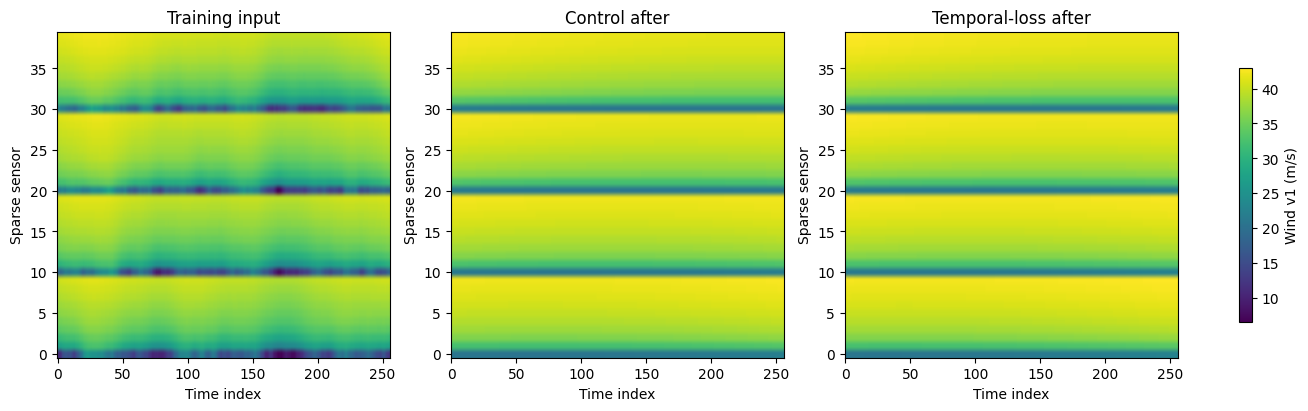


PAIRED VAE CONTINUATION RESULTS
{
  "initial": {
    "temporal_variance": 0.042167,
    "between_field_variance": 0.0,
    "high_psd_17_64": 0.049394
  },
  "control": {
    "temporal_variance": 0.024623,
    "between_field_variance": 0.0,
    "high_psd_17_64": 0.027703
  },
  "temporal": {
    "temporal_variance": 0.023312,
    "between_field_variance": 0.0,
    "high_psd_17_64": 0.026225
  }
}

Saved experiment: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/controlled_vae_ablations/20261102T152149Z-042766
Research journal updated.
Automatic archival will preserve experiment artifacts.
CELL O COMPLETE


In [20]:

# CELL O — PAIRED VAE CONTINUATION TRAINING
# No installations. No changes to NASA reference source.
# Results are automatically archived by P1.

import sys, json, uuid, hashlib
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.nn import functional as F

sys.path.insert(0, "/content")
import wind_vision_physicsnemo_day1 as w

assert callable(globals().get("note")), "Run Cell P1 first."
assert torch.cuda.is_available(), "L4 GPU unavailable."

STEPS = 80
BS = 4
LR = 5e-4
TEMP_WEIGHT = 1e-3
SEED = 20261029

OUT = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
RUN = OUT / "controlled_vae_ablations" / (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "-" + uuid.uuid4().hex[:6]
)
RUN.mkdir(parents=True, exist_ok=False)

# ----------------------------------------------------------
# 1. Reference and data
# ----------------------------------------------------------

ckpt, train_file = w.assert_environment()
FVAE, _, _, _, _, DataCls, LossCls, _, kl_fn = (
    w.prepare_reference_imports()
)

dataset, physics_loss = w.make_loss_and_data(
    train_file, DataCls, LossCls
)
dataset.points = dataset.points.float()
physics_loss = physics_loss.cuda().float()

assert len(dataset.sensor_idx) == 40
assert len(dataset) >= STEPS * BS + 32

# Disjoint only for continuation training; the pretrained
# checkpoint may already have seen all these examples.
perm = np.random.default_rng(SEED).permutation(len(dataset))
train_ids = perm[:STEPS * BS].reshape(STEPS, BS)
probe_ids = perm[-32:]

# ----------------------------------------------------------
# 2. Identical PhysicsNeMo models and initialization
# ----------------------------------------------------------

torch.manual_seed(SEED)

trusted = FVAE.load_from_checkpoint(
    str(ckpt),
    map_location="cpu",
    weights_only=False
).float().eval()

assert trusted._encoder.input_layer.weight.shape[1] == 40

kwargs = dict(
    num_sensors=40,
    latent_dim=128,
    grid_low=trusted.grid.low.tolist(),
    grid_high=trusted.grid.high.tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
)

models, optimizers = {}, {}

for name in ("control", "temporal"):
    model = w.PhysicsNeMoWindVAE(**kwargs).cuda().float().train()
    model.load_state_dict(trusted.state_dict(), strict=True)
    models[name] = model
    optimizers[name] = torch.optim.Adam(
        model.parameters(), lr=LR
    )

assert all(
    torch.equal(a, b)
    for a, b in zip(
        models["control"].parameters(),
        models["temporal"].parameters()
    )
)

del trusted

# ----------------------------------------------------------
# 3. Save exact experimental configuration
# ----------------------------------------------------------

source_file = Path(w.__file__)
source_sha = hashlib.sha256(source_file.read_bytes()).hexdigest()

manifest = {
    "experiment": "paired_vae_continuation_temporal_derivative",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "source_script": str(source_file),
    "source_sha256": source_sha,
    "reference_commit": w.PINNED_GIT_SHA,
    "checkpoint_sha256": w.TRUSTED_CHECKPOINT_SHA,
    "gpu": torch.cuda.get_device_name(0),
    "steps_per_arm": STEPS,
    "batch_size": BS,
    "learning_rate": LR,
    "gradient_clip": 0.5,
    "seed": SEED,
    "temporal_weight": TEMP_WEIGHT,
    "original_weights": {
        "reconstruction": 1.0,
        "kl": 1e-6,
        "coherence": 0.01
    },
    "continuation_train_indices": train_ids.reshape(-1).tolist(),
    "diagnostic_indices": probe_ids.tolist(),
    "limitation": (
        "The diagnostic indices are excluded from this "
        "continuation run but not from the pretrained "
        "checkpoint's historical training population."
    )
}

(RUN / "manifest.json").write_text(
    json.dumps(manifest, indent=2)
)

# ----------------------------------------------------------
# 4. Define common fidelity evaluation
# ----------------------------------------------------------

def evaluate(model):
    model.eval()
    observed, predictions = [], []

    with torch.inference_mode():
        for j in range(0, len(probe_ids), BS):
            ids = probe_ids[j:j+BS]

            ut = torch.stack([
                dataset[int(i)][0] for i in ids
            ]).cuda().float()

            xy = dataset.points.cuda()[None].expand(
                len(ids), -1, -1
            )

            mu, _ = model.encode(ut)
            prediction = model.decode(
                mu, xy
            ).reshape_as(ut)

            observed.append(ut.cpu())
            predictions.append(prediction.cpu())

    obs = torch.cat(observed).numpy().astype(np.float64)
    pred = torch.cat(predictions).numpy().astype(np.float64)

    def statistics(a):
        centered = a - a.mean(-1, keepdims=True)
        psd = np.abs(np.fft.rfft(centered, axis=-1))**2

        return {
            "temporal_variance": float(
                a.var(axis=-1).mean()
            ),
            "between_field_variance": float(
                a.var(axis=0).mean()
            ),
            "high_psd_17_64": float(
                psd[..., 17:65].mean()
            )
        }

    reference = statistics(obs)
    generated = statistics(pred)

    metrics = {
        "reconstruction_mse": float(
            np.mean((pred - obs)**2)
        ),
        "temporal_derivative_mse": float(
            np.mean(
                (np.diff(pred, axis=-1)
                 - np.diff(obs, axis=-1))**2
            )
        ),
        "reference": reference,
        "prediction": generated,
        "ratios": {
            k: generated[k] / max(reference[k], 1e-20)
            for k in reference
        }
    }

    model.train()
    return metrics, obs, pred

initial, _, _ = evaluate(models["control"])
initial_variant, _, _ = evaluate(models["temporal"])

assert abs(
    initial["reconstruction_mse"]
    - initial_variant["reconstruction_mse"]
) < 1e-10

print("Identical initialization verified.")
print(
    "Initial temporal variance ratio:",
    initial["ratios"]["temporal_variance"]
)

# ----------------------------------------------------------
# 5. Matched continuation training
# ----------------------------------------------------------

history = []

noise_generator = torch.Generator(
    device="cuda"
).manual_seed(SEED + 17)

xy_cuda = dataset.points.cuda()[None].expand(
    BS, -1, -1
)

for step in range(STEPS):

    ids = train_ids[step]

    ut = torch.stack([
        dataset[int(i)][0] for i in ids
    ]).cuda().float()

    eps = torch.randn(
        BS, 128,
        generator=noise_generator,
        device="cuda"
    )

    colloc_seed = SEED + 4000 + step

    for name in ("control", "temporal"):

        model = models[name]
        optimizer = optimizers[name]
        optimizer.zero_grad(set_to_none=True)

        mu, logvar = model.encode(ut)
        z = mu + torch.exp(0.5 * logvar) * eps

        pred = model.decode(
            z, xy_cuda
        ).reshape_as(ut)

        rec = F.mse_loss(pred, ut)

        # First temporal differences
        delta_true = ut[..., 1:] - ut[..., :-1]
        delta_pred = pred[..., 1:] - pred[..., :-1]

        # Scale by observed temporal-difference energy.
        # Denominator is detached to avoid modifying target.
        temporal_relative = (
            F.mse_loss(delta_pred, delta_true)
            / delta_true.square().mean().detach().clamp_min(1e-6)
        )

        # Identical collocation seed for both models
        torch.manual_seed(colloc_seed)
        residual, _ = physics_loss.residual(model, z)

        kl = kl_fn(mu, logvar)

        native_objective = (
            rec + 1e-6 * kl + 0.01 * residual
        )

        objective = native_objective + (
            TEMP_WEIGHT * temporal_relative
            if name == "temporal" else 0.0
        )

        if not torch.isfinite(objective):
            raise FloatingPointError(
                f"Nonfinite objective: {name}, step {step}"
            )

        objective.backward()

        gradient_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(), 0.5
        )

        optimizer.step()

        history.append({
            "step": step + 1,
            "arm": name,
            "objective": float(objective.detach()),
            "native_objective": float(native_objective.detach()),
            "reconstruction": float(rec.detach()),
            "coherence_residual": float(residual.detach()),
            "kl_unweighted": float(kl.detach()),
            "relative_temporal_loss": float(
                temporal_relative.detach()
            ),
            "gradient_norm_before_clipping": float(
                gradient_norm.detach()
            )
        })

    if (step + 1) % 20 == 0:
        print(
            f"Completed paired step {step+1}/{STEPS}",
            flush=True
        )

        (RUN / "train_history.json").write_text(
            json.dumps(history, indent=2)
        )

        for name in models:
            torch.save({
                "state_dict": models[name].state_dict(),
                "optimizer": optimizers[name].state_dict(),
                "step": step + 1,
                "manifest_file": str(RUN / "manifest.json")
            }, RUN / f"{name}_step{step+1:03d}.pt")

# ----------------------------------------------------------
# 6. Compare initial, control and experimental model
# ----------------------------------------------------------

results = {
    "initial": initial,
    "initial_variant": initial_variant
}
plot_fields = {}

for name, model in models.items():
    metrics, observed, prediction = evaluate(model)
    results[name] = metrics
    plot_fields[name] = prediction[0]

results["evaluation_scope"] = (
    "Training-only diagnostic. Probe indices were excluded "
    "from this continuation, but not from earlier checkpoint "
    "training. No independent generalization claim."
)

(RUN / "metrics.json").write_text(
    json.dumps(results, indent=2)
)
(RUN / "train_history.json").write_text(
    json.dumps(history, indent=2)
)

# ----------------------------------------------------------
# 7. Save shared-scale wind-field visualization
# ----------------------------------------------------------

fields = [
    observed[0],
    plot_fields["control"],
    plot_fields["temporal"]
]

all_values = np.concatenate([
    field.ravel() for field in fields
]) * 49 - 2

vmin = float(all_values.min())
vmax = float(all_values.max())

fig, axes = plt.subplots(
    1, 3, figsize=(13, 4),
    constrained_layout=True
)

for ax, title, field in zip(
    axes,
    ["Training input", "Control after", "Temporal-loss after"],
    fields
):
    image = ax.imshow(
        field * 49 - 2,
        origin="lower",
        aspect="auto",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )
    ax.set_title(title)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor")

fig.colorbar(
    image, ax=axes,
    label="Wind v1 (m/s)",
    shrink=0.78
)

figure_path = RUN / "paired_fidelity.png"
fig.savefig(figure_path, dpi=150)
plt.show()
plt.close(fig)

# ----------------------------------------------------------
# 8. Print and document results
# ----------------------------------------------------------

summary = {
    name: {
        metric: round(value, 6)
        for metric, value in results[name]["ratios"].items()
    }
    for name in ("initial", "control", "temporal")
}

print("\n" + "=" * 65)
print("PAIRED VAE CONTINUATION RESULTS")
print("=" * 65)
print(json.dumps(summary, indent=2))

note(
    title="Paired VAE continuation with temporal derivative loss",
    question=(
        "Can temporal-derivative reconstruction improve "
        "wind variance relative to original-loss continuation?"
    ),
    methods=(
        f"Identical epoch-ten initialization, {STEPS} paired "
        f"steps, batch {BS}, Adam LR {LR}, identical noise and "
        f"collocation seeds, temporal coefficient {TEMP_WEIGHT}."
    ),
    evidence=[
        str(RUN / "manifest.json"),
        str(RUN / "metrics.json"),
        str(RUN / "train_history.json"),
        str(figure_path)
    ],
    findings=summary,
    limitations=[
        "Training-only evaluation population",
        "80-step pilot, not convergence",
        "No independent test or multiple-seed estimates",
        "Posterior-mean decoding only in this comparison"
    ],
    decision=(
        "Determine whether temporal augmentation improves "
        "fidelity over matched original-loss continuation "
        "without materially degrading reconstruction."
    )
)

print("\nSaved experiment:", RUN)
print("Research journal updated.")
print("Automatic archival will preserve experiment artifacts.")
print("CELL O COMPLETE")


CELL O — 80-STEP VAE CONTINUATION: ALREADY SAVED RESULTS
Run directory: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/controlled_vae_ablations/20261029T193836Z-02073a
Steps per arm: 80
Temporal weight: 0.001
Training history records: 160

INITIAL
  reconstruction_mse: 0.004187102890657384
  temporal_derivative_mse: 2.443183361436547e-05
  temporal_variance_ratio: 0.04216738806822968
  high_frequency_psd_ratio: 0.04939357949019514
  between_field_variance_ratio: 2.293983973660101e-10

CONTROL
  reconstruction_mse: 0.0037629299434255117
  temporal_derivative_mse: 2.4423002823207464e-05
  temporal_variance_ratio: 0.035678689178391114
  high_frequency_psd_ratio: 0.04327095289408336
  between_field_variance_ratio: 1.8349736174398745e-07

TEMPORAL
  reconstruction_mse: 0.0037719395384517357
  temporal_derivative_mse: 2.4425923832802156e-05
  temporal_variance_ratio: 0.048352545601661245
  high_frequency_psd_ratio: 0.06169409941689692
  between_field_variance_ratio: 9.09437102

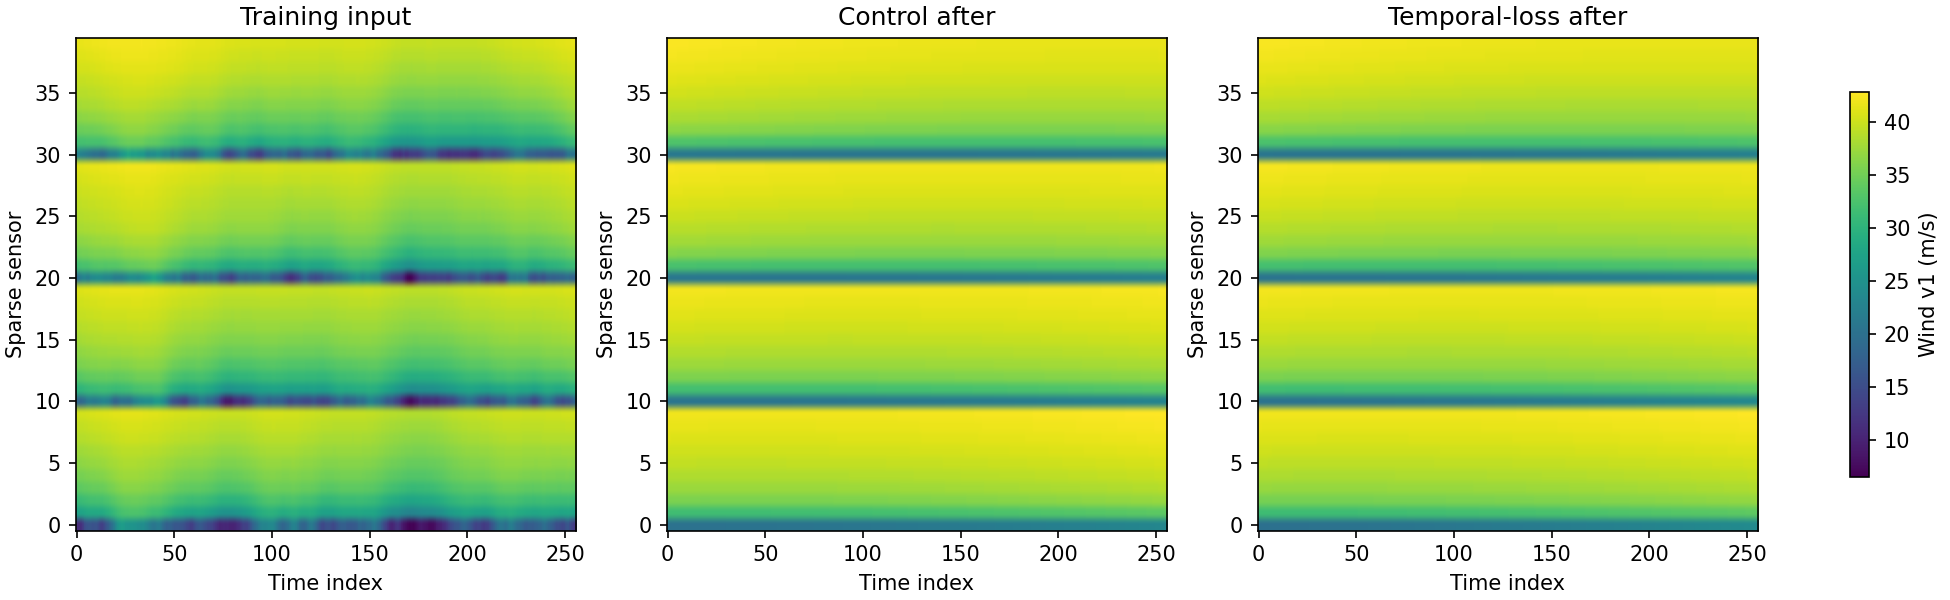


Posthoc report: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/controlled_vae_ablations/20261029T193836Z-02073a/POSTHOC_ASSESSMENT_4477aa5d0312.json
Archived assessment changes: 0
Active research archive verified: 592
P3 COMPLETE — existing results reviewed, no GPU retraining performed.


In [21]:
# CELL P3 — Resume research by auditing the ALREADY COMPLETED 80-step VAE ablation
# No training; no GPU allocation. Run after NEW P1 and P2.
from pathlib import Path
import json, hashlib
from IPython.display import display, Image

assert callable(globals().get('verify')) and callable(globals().get('note')), 'Run P1 first.'
base=Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
runs=base/'controlled_vae_ablations'
preferred=runs/'20261029T193836Z-02073a'
if (preferred/'metrics.json').exists():
    run=preferred
else:
    candidates=sorted((p for p in runs.glob('*/metrics.json') if p.is_file()),reverse=True)
    assert candidates, 'No completed ablation metrics found. Do NOT retrain until this is diagnosed.'
    run=candidates[0].parent

manifest_file=run/'manifest.json'
metrics_file=run/'metrics.json'
history_file=run/'train_history.json'
assert manifest_file.is_file() and metrics_file.is_file(), 'Ablation evidence incomplete.'
manifest=json.loads(manifest_file.read_text())
metrics=json.loads(metrics_file.read_text())
history=json.loads(history_file.read_text()) if history_file.exists() else []
assert all(a in metrics for a in ('initial','control','temporal'))

print('='*70)
print('CELL O — 80-STEP VAE CONTINUATION: ALREADY SAVED RESULTS')
print('='*70)
print('Run directory:',run)
print('Steps per arm:',manifest.get('steps_per_arm','unspecified'))
print('Temporal weight:',manifest.get('temporal_weight','unspecified'))
print('Training history records:',len(history))
print('WARNING: Diagnostic examples were included in the original pretrained dataset.')

rows={}
for arm in ('initial','control','temporal'):
    m=metrics[arm]; r=m.get('ratios',{})
    row={
        'reconstruction_mse':m.get('reconstruction_mse'),
        'temporal_derivative_mse':m.get('temporal_derivative_mse'),
        'temporal_variance_ratio':r.get('temporal_variance'),
        'high_frequency_psd_ratio':r.get('high_psd_17_64'),
        'between_field_variance_ratio':r.get('between_field_variance')}
    rows[arm]=row
    print('\n'+arm.upper())
    for k,v in row.items(): print(f'  {k}: {v}')

# Delta of the experimental arm relative to the matched control.
comparison={}
for key,baseline in rows['control'].items():
    alternative=rows['temporal'].get(key)
    if isinstance(baseline,(int,float)) and isinstance(alternative,(int,float)):
        comparison[key]={
            'control':baseline,'temporal_variant':alternative,
            'variant_minus_control':alternative-baseline,
            'variant_over_control':alternative/baseline if baseline else None}

report={
    'experiment':'posthoc_audit_of_saved_paired_vae_continuation',
    'source_run':run.name,
    'metrics_sha256':hashlib.sha256(metrics_file.read_bytes()).hexdigest(),
    'manifest':manifest,
    'initial_control_temporal_metrics':rows,
    'variant_vs_control':comparison,
    'history_records':len(history),
    'evaluation_scope':'training-only diagnostic, not independent holdout',
    'interpretation_caveat':(
        'These ratios assess magnitude of temporal and field variability. '
        'A ratio closer to one alone is not proof of accurate temporal structure, '
        'coherence, or overall scientific quality. The original checkpoint had '
        'previously trained on the diagnostic population.'),
    'constraint_status':'Post-training physics-coherence quality not independently validated.'}
path=run/f'POSTHOC_ASSESSMENT_{report["metrics_sha256"][:12]}.json'
if not path.exists():
    path.write_text(json.dumps(report,indent=2,default=str))
    note(
        title='Saved paired VAE continuation: matched-control interpretation',
        question='Did temporal-derivative training improve fidelity over 80-step original continuation?',
        methods='Read existing manifest, metrics and train-history without rerunning models.',
        evidence=[str(manifest_file),str(metrics_file),str(history_file),str(path)],
        findings=comparison,
        limitations=['Pretrained checkpoint previously saw diagnostic population',
                     'Single seed, only 80 steps','No final matched coherence quality evaluation'],
        decision='Use measured control-versus-variant results to select next targeted experiment.'
    )

print('\n'+'-'*70)
print('TEMPORAL VARIANT vs MATCHED CONTROL')
for name,val in comparison.items():
    print(name, 'delta:',round(val['variant_minus_control'],9),
          'ratio:',round(val['variant_over_control'],5) if val['variant_over_control'] is not None else 'N/A')

fig=run/'paired_fidelity.png'
if fig.exists():
    print('\nSaved paired comparison figure:')
    display(Image(filename=str(fig)))
else:
    print('WARNING: paired_fidelity.png is missing.')

print('\nPosthoc report:',path)
print('Archived assessment changes:', len(snapshot('P3_saved_ablation_assessment')))
print('Active research archive verified:',verify())
print('P3 COMPLETE — existing results reviewed, no GPU retraining performed.')


In [22]:

# CELL P4 — Cross-run VAE reproducibility audit
# Read-only analysis of existing model experiments.
# Run after P1; no GPU training.

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import math

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)
RUNS = BASE / "controlled_vae_ablations"

assert RUNS.is_dir(), "Ablation folder missing."
assert callable(globals().get("verify")), "Run P1 first."
assert callable(globals().get("note")), "Run P1 first."

config_keys = (
    "experiment", "reference_commit",
    "checkpoint_sha256", "source_sha256",
    "gpu", "steps_per_arm", "batch_size",
    "learning_rate", "gradient_clip", "seed",
    "temporal_weight", "original_weights",
    "continuation_train_indices", "diagnostic_indices"
)

measures = (
    ("reconstruction_mse", False),
    ("temporal_derivative_mse", False),
    ("temporal_variance", True),
    ("high_psd_17_64", True),
    ("between_field_variance", True)
)

all_runs = []
partial = []

for directory in sorted(RUNS.iterdir()):
    if not directory.is_dir():
        continue

    files = {
        name: directory / f"{name}.json"
        for name in ("manifest", "metrics", "train_history")
    }

    if not all(path.is_file() for path in files.values()):
        partial.append(directory.name)
        continue

    obj = {
        name: json.loads(path.read_text())
        for name, path in files.items()
    }

    manifest = obj["manifest"]
    stats = obj["metrics"]
    history = obj["train_history"]

    assert all(
        arm in stats
        for arm in ("initial", "control", "temporal")
    )

    assert isinstance(history, list)

    values = {}

    for key, is_ratio in measures:
        values[key] = {}

        for arm in ("initial", "control", "temporal"):
            source = (
                stats[arm]["ratios"]
                if is_ratio else stats[arm]
            )

            value = source.get(key)
            assert isinstance(value, (int, float))
            assert math.isfinite(value)

            values[key][arm] = float(value)

    config = {
        key: manifest.get(key)
        for key in config_keys
    }

    signature = hashlib.sha256(
        json.dumps(
            config, sort_keys=True
        ).encode()
    ).hexdigest()

    histories = {
        arm: [
            row for row in history
            if row.get("arm") == arm
        ]
        for arm in ("control", "temporal")
    }

    all_runs.append({
        "run": directory.name,
        "configuration_sha256": signature,
        "metrics_sha256": hashlib.sha256(
            files["metrics"].read_bytes()
        ).hexdigest(),
        "config": config,
        "values": values,
        "step_counts": {
            arm: len(rows)
            for arm, rows in histories.items()
        },
        "histories": histories,
        "figure_exists": (
            directory / "paired_fidelity.png"
        ).is_file(),
        "checkpoints": {
            arm: sorted(
                path.name
                for path in directory.glob(
                    f"{arm}_step*.pt"
                )
            )
            for arm in ("control", "temporal")
        }
    })

assert len(all_runs) >= 2, (
    "Expected at least two completed experiments. "
    "Do not retrain just to satisfy this audit."
)

print("=" * 72)
print("CELL P4 — SAVED VAE EXPERIMENTS")
print("=" * 72)
print("Completed runs:", len(all_runs))
print("Incomplete directories:", partial)

for run in all_runs:

    print("\nRUN:", run["run"])
    print(
        "Configuration SHA256:",
        run["configuration_sha256"]
    )
    print(
        "Metrics SHA256:",
        run["metrics_sha256"]
    )
    print("Recorded steps:", run["step_counts"])

    for key, _ in measures:

        vals = run["values"][key]
        control = vals["control"]
        temporal = vals["temporal"]

        scale = (
            100.0 if key in (
                "temporal_variance",
                "high_psd_17_64",
                "between_field_variance"
            )
            else 1.0
        )

        suffix = "%" if scale == 100 else ""

        print(
            f"  {key}: "
            f"initial={vals['initial']*scale:.8g}{suffix}, "
            f"control={control*scale:.8g}{suffix}, "
            f"temporal={temporal*scale:.8g}{suffix}"
        )

        print(
            "    Temporal/control:",
            temporal / control if control else None
        )

    print(
        "Saved checkpoints:",
        {
            arm: len(names)
            for arm, names in run["checkpoints"].items()
        }
    )

    print(
        "Comparison figure exists:",
        run["figure_exists"]
    )

# ----------------------------------------------------------
# Check whether experimental settings truly agree.
# ----------------------------------------------------------

signatures = {
    run["configuration_sha256"]
    for run in all_runs
}

same_config = len(signatures) == 1

print("\n" + "=" * 72)
print("REPRODUCIBILITY CHECK")
print("=" * 72)
print("Identical recorded configurations:", same_config)

if not same_config:

    for key in config_keys:

        values = {
            json.dumps(
                run["config"][key],
                sort_keys=True
            )
            for run in all_runs
        }

        if len(values) > 1:
            print("DIFFERENT CONFIGURATION:", key)

# ----------------------------------------------------------
# Locate first divergence of saved training objectives.
# ----------------------------------------------------------

pairs = []

for i, first in enumerate(all_runs):

    for second in all_runs[i+1:]:

        if (
            first["configuration_sha256"]
            != second["configuration_sha256"]
        ):
            continue

        by_arm = {}

        for arm in ("control", "temporal"):

            a = {
                int(row["step"]): row
                for row in first["histories"][arm]
            }

            b = {
                int(row["step"]): row
                for row in second["histories"][arm]
            }

            common = sorted(set(a) & set(b))
            divergence = None

            for step in common:

                value_a = a[step].get(
                    "native_objective"
                )
                value_b = b[step].get(
                    "native_objective"
                )

                if (
                    value_a is not None
                    and value_b is not None
                    and abs(value_a-value_b) > 1e-8
                ):

                    divergence = {
                        "step": step,
                        "first_run_value": float(value_a),
                        "second_run_value": float(value_b),
                        "absolute_difference": float(
                            abs(value_a-value_b)
                        )
                    }
                    break

            by_arm[arm] = {
                "common_steps": len(common),
                "first_difference_gt_1e_8": divergence
            }

        pairs.append({
            "first_run": first["run"],
            "second_run": second["run"],
            "by_arm": by_arm
        })

print("\nTRAINING TRACE COMPARISON")

for pair in pairs:

    print(
        "\n", pair["first_run"],
        "versus", pair["second_run"]
    )

    for arm, result in pair["by_arm"].items():
        print(arm, result)

# ----------------------------------------------------------
# Save publication-traceable cross-run evidence.
# ----------------------------------------------------------

compact = [
    {
        key: value
        for key, value in run.items()
        if key != "histories"
    }
    for run in all_runs
]

report = {
    "experiment": "vae_continuation_cross_run_audit",
    "utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "completed_runs": compact,
    "same_recorded_configuration": same_config,
    "training_trace_comparisons": pairs,
    "incomplete_runs": partial,
    "evaluation_scope": (
        "Training-only probe; original checkpoint "
        "previously saw the diagnostic population."
    ),
    "limitations": [
        "No independent validation",
        "No multi-seed uncertainty estimate",
        "Recorded configuration equality does not "
        "prove CUDA execution determinism",
        "Variance ratios are not sufficient to "
        "establish realistic wind-field generation",
        "Final matched coherence quality not measured"
    ]
}

signature = hashlib.sha256(
    "".join(sorted(
        r["run"] + ":" + r["metrics_sha256"]
        for r in all_runs
    )).encode()
).hexdigest()[:16]

AUDITS = BASE / "cross_run_audits"
AUDITS.mkdir(exist_ok=True)

path = (
    AUDITS /
    f"vae_cross_run_audit_{signature}.json"
)

if not path.exists():

    path.write_text(
        json.dumps(
            report,
            indent=2,
            default=str,
            allow_nan=False
        )
    )

    note(
        title=(
            "Cross-run VAE continuation "
            "reproducibility audit"
        ),
        question=(
            "Does the temporal reconstruction objective "
            "improve wind statistics consistently?"
        ),
        methods=(
            "Compare all completed manifests, metrics, "
            "training histories and configuration hashes. "
            "No model retraining."
        ),
        evidence=[
            str(path)
        ] + [
            str(
                RUNS / run["run"] / "metrics.json"
            )
            for run in all_runs
        ],
        findings={
            "run_count": len(all_runs),
            "same_recorded_configuration": same_config,
            "temporal_variance_variant_control_ratios": {
                run["run"]: (
                    run["values"]["temporal_variance"]
                    ["temporal"]
                    /
                    run["values"]["temporal_variance"]
                    ["control"]
                )
                for run in all_runs
            }
        },
        limitations=report["limitations"],
        decision=(
            "Do not claim a fidelity improvement until "
            "the contradictory runs are reconciled "
            "and the result is replicated."
        )
    )

else:

    print(
        "Cross-run audit already exists. "
        "No duplicate journal entry created."
    )

print("\nSaved:", path)

changed = snapshot(
    "P4_cross_run_reproducibility"
)

print("Newly archived files:", len(changed))
print("Verified archive entries:", verify())
print("CELL P4 COMPLETE — NO RETRAINING")


CELL P4 — SAVED VAE EXPERIMENTS
Completed runs: 5
Incomplete directories: ['deterministic_replication_20261030T024339Z_c746ee', 'deterministic_replication_20261030T122334Z_95feb4', 'deterministic_replication_20261030T123407Z_390a1f']

RUN: 20261029T193836Z-02073a
Configuration SHA256: ee14b6722f13be724e3c4cccea536de9f51decb7d84698171c0bc09bba612b8b
Metrics SHA256: 4477aa5d03125cbf91feb657c209e4aff5dfb6ee50288e000e15d70231f9a4e0
Recorded steps: {'control': 80, 'temporal': 80}
  reconstruction_mse: initial=0.0041871029, control=0.0037629299, temporal=0.0037719395
    Temporal/control: 1.0023943031525115
  temporal_derivative_mse: initial=2.4431834e-05, control=2.4423003e-05, temporal=2.4425924e-05
    Temporal/control: 1.0001196007557234
  temporal_variance: initial=4.2167388%, control=3.5678689%, temporal=4.8352546%
    Temporal/control: 1.3552220307170388
  high_psd_17_64: initial=4.9393579%, control=4.3270953%, temporal=6.1694099%
    Temporal/control: 1.4257624408667147
  between_fie

In [23]:

# CELL P5 — Controlled 4-step reproducibility microprobe
# Add below P4. Does not rerun the 80-step experiments.

import sys, json, hashlib, uuid
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import torch
from torch.nn import functional as F

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)
RUNS = BASE / "controlled_vae_ablations"

assert callable(globals().get("note"))
assert callable(globals().get("verify"))
assert torch.cuda.is_available(), "NVIDIA GPU required."

sys.path.insert(0, "/content")
import wind_vision_physicsnemo_day1 as w

# ----------------------------------------------------------
# 1. Read and compare existing experiment manifests
# ----------------------------------------------------------

manifests = []

for folder in sorted(RUNS.iterdir()):
    if (
        (folder / "manifest.json").is_file()
        and (folder / "metrics.json").is_file()
    ):
        manifests.append((
            folder.name,
            json.loads(
                (folder / "manifest.json").read_text()
            )
        ))

assert len(manifests) >= 2

SEED = 20261029
BS = 4
LR = 5e-4
WEIGHT = 1e-3
STEPS = 4

expected = manifests[0][1]

required_keys = (
    "seed",
    "batch_size",
    "learning_rate",
    "temporal_weight",
    "checkpoint_sha256",
    "source_sha256",
    "continuation_train_indices",
    "diagnostic_indices"
)

for name, manifest in manifests:
    assert all(
        manifest.get(k) == expected.get(k)
        for k in required_keys
    ), (
        "Historical configurations differ. "
        f"Inspect P4 for {name}."
    )

assert expected["seed"] == SEED
assert expected["batch_size"] == BS
assert abs(expected["learning_rate"] - LR) < 1e-14
assert abs(expected["temporal_weight"] - WEIGHT) < 1e-14

# Stop before computation if the implementation changed.
source_path = Path(
    "/content/wind_vision_physicsnemo_day1.py"
)

current_source_sha = hashlib.sha256(
    source_path.read_bytes()
).hexdigest()

assert current_source_sha == expected["source_sha256"], (
    "Live PhysicsNeMo implementation differs from "
    "the archived Cell O source. Reconcile source "
    "versions before attempting reproducibility."
)

# ----------------------------------------------------------
# 2. Load verified data and trusted checkpoint
# ----------------------------------------------------------

ckpt, train_file = w.assert_environment()

w.check_sha256(
    train_file,
    "676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941"
)

FVAE, _, _, _, _, DataCls, LossCls, _, kl_fn = (
    w.prepare_reference_imports()
)

dataset, loss_impl = w.make_loss_and_data(
    train_file,
    DataCls,
    LossCls
)

dataset.points = dataset.points.float()

assert len(dataset.sensor_idx) == 40

loss_impl = loss_impl.to(
    device="cuda",
    dtype=torch.float32
)

train_ids = np.asarray(
    expected["continuation_train_indices"],
    dtype=int
).reshape(-1, BS)

assert train_ids.shape[0] >= STEPS

# Independently reproduce the training-index sequence.
permutation = np.random.default_rng(
    SEED
).permutation(len(dataset))

assert np.array_equal(
    train_ids[:STEPS],
    permutation[:STEPS * BS].reshape(STEPS, BS)
)

trusted = FVAE.load_from_checkpoint(
    str(ckpt),
    map_location="cpu",
    weights_only=False
).float().eval()

kwargs = dict(
    num_sensors=40,
    latent_dim=128,
    grid_low=trusted.grid.low.detach().cpu().tolist(),
    grid_high=trusted.grid.high.detach().cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
)

initial_weights = {
    k: v.detach().clone()
    for k, v in trusted.state_dict().items()
}

del trusted

coords = dataset.points.to(
    device="cuda",
    dtype=torch.float32
)[None].expand(BS, -1, -1)

def sha_tensor(t):
    raw = (
        t.detach()
        .contiguous()
        .cpu()
        .numpy()
        .tobytes()
    )
    return hashlib.sha256(raw).hexdigest()

# ----------------------------------------------------------
# 3. Replay paired optimization from scratch
# ----------------------------------------------------------

def replay(run_label):

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    models = {}
    optimizers = {}

    for arm in ("control", "temporal"):

        model = w.PhysicsNeMoWindVAE(
            **kwargs
        ).to(
            device="cuda",
            dtype=torch.float32
        ).train()

        model.load_state_dict(
            initial_weights,
            strict=True
        )

        models[arm] = model

        optimizers[arm] = torch.optim.Adam(
            model.parameters(),
            lr=LR
        )

    assert all(
        torch.equal(a, b)
        for a, b in zip(
            models["control"].parameters(),
            models["temporal"].parameters()
        )
    )

    noise_generator = torch.Generator(
        device="cuda"
    ).manual_seed(SEED + 17)

    trace = []

    for step in range(STEPS):

        ids = train_ids[step]

        u_batch = torch.stack([
            dataset[int(i)][0]
            for i in ids
        ]).cuda().float()

        eps = torch.randn(
            BS,
            128,
            device="cuda",
            generator=noise_generator
        )

        collocation_seed = SEED + 4000 + step

        for arm in ("control", "temporal"):

            model = models[arm]
            optimizer = optimizers[arm]

            optimizer.zero_grad(set_to_none=True)

            mu, logvar = model.encode(u_batch)

            z = mu + (
                torch.exp(0.5 * logvar) * eps
            )

            predicted = model.decode(
                z, coords
            ).reshape_as(u_batch)

            reconstruction = F.mse_loss(
                predicted, u_batch
            )

            delta_true = (
                u_batch[..., 1:]
                - u_batch[..., :-1]
            )

            delta_pred = (
                predicted[..., 1:]
                - predicted[..., :-1]
            )

            temporal_term = (
                F.mse_loss(delta_pred, delta_true)
                / delta_true.square()
                    .mean()
                    .detach()
                    .clamp_min(1e-6)
            )

            torch.manual_seed(collocation_seed)

            residual, _ = loss_impl.residual(
                model, z
            )

            kl = kl_fn(mu, logvar)

            native = (
                reconstruction
                + 1e-6 * kl
                + 0.01 * residual
            )

            objective = native + (
                WEIGHT * temporal_term
                if arm == "temporal"
                else 0.0
            )

            if not torch.isfinite(objective):
                raise FloatingPointError(
                    f"Nonfinite objective: "
                    f"{run_label}, step {step+1}, {arm}"
                )

            objective.backward()

            gradient_norm = (
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    0.5
                )
            )

            optimizer.step()

            branch_parameter = dict(
                model.named_parameters()
            )["_branch.blocks.1.net.4.weight"]

            trace.append({
                "step": step + 1,
                "arm": arm,
                "native_objective":
                    float(native.detach()),
                "objective":
                    float(objective.detach()),
                "reconstruction":
                    float(reconstruction.detach()),
                "coherence_residual":
                    float(residual.detach()),
                "kl_unweighted":
                    float(kl.detach()),
                "relative_temporal_loss":
                    float(temporal_term.detach()),
                "gradient_norm_before_clipping":
                    float(gradient_norm.detach()),
                "input_sha256":
                    sha_tensor(u_batch),
                "posterior_noise_sha256":
                    sha_tensor(eps),
                "encoder_mean_sha256":
                    sha_tensor(mu),
                "branch_parameter_sha256":
                    sha_tensor(branch_parameter)
            })

    del models, optimizers

    return trace

# Two separate fresh model and optimizer starts.
trace_a = replay("A")
trace_b = replay("B")

# ----------------------------------------------------------
# 4. Compare both replays directly
# ----------------------------------------------------------

comparisons = []

numeric_keys = (
    "native_objective",
    "objective",
    "reconstruction",
    "coherence_residual",
    "kl_unweighted",
    "relative_temporal_loss",
    "gradient_norm_before_clipping"
)

hash_keys = (
    "input_sha256",
    "posterior_noise_sha256",
    "encoder_mean_sha256",
    "branch_parameter_sha256"
)

for left, right in zip(trace_a, trace_b):

    assert (
        left["step"], left["arm"]
    ) == (
        right["step"], right["arm"]
    )

    differences = {
        k: abs(left[k] - right[k])
        for k in numeric_keys
    }

    mismatched_hashes = [
        k for k in hash_keys
        if left[k] != right[k]
    ]

    comparisons.append({
        "step": left["step"],
        "arm": left["arm"],
        "max_numeric_absolute_diff":
            max(differences.values()),
        "numeric_differences":
            differences,
        "mismatched_tensor_hashes":
            mismatched_hashes,
        "exact_match": (
            max(differences.values()) == 0
            and not mismatched_hashes
        )
    })

all_exact = all(
    item["exact_match"]
    for item in comparisons
)

# ----------------------------------------------------------
# 5. Compare against both historical 80-step runs
# ----------------------------------------------------------

historical = {}

for run_name, _ in manifests:

    history_path = (
        RUNS / run_name / "train_history.json"
    )

    rows = json.loads(
        history_path.read_text()
    )

    indexed = {
        (int(r["step"]), r["arm"]): r
        for r in rows
    }

    samples = []

    for row in trace_a:

        old = indexed[
            (row["step"], row["arm"])
        ]

        compare_keys = (
            "native_objective",
            "reconstruction",
            "coherence_residual",
            "kl_unweighted",
            "relative_temporal_loss",
            "gradient_norm_before_clipping"
        )

        delta = {
            k: abs(row[k] - old[k])
            for k in compare_keys
        }

        samples.append({
            "step": row["step"],
            "arm": row["arm"],
            "max_absolute_difference":
                max(delta.values()),
            "difference_by_metric": delta
        })

    historical[run_name] = {
        "first_difference_over_1e-8": next(
            (
                r for r in samples
                if r["max_absolute_difference"] > 1e-8
            ),
            None
        ),
        "per_step_comparison": samples
    }

# ----------------------------------------------------------
# 6. Persist experimental evidence and provenance
# ----------------------------------------------------------

report = {
    "experiment":
        "short_same_runtime_vae_training_replay",
    "timestamp_utc":
        datetime.now(timezone.utc).isoformat(),
    "original_manifest_ids": [
        name for name, _ in manifests
    ],
    "source_sha256":
        current_source_sha,
    "archived_source_sha256":
        expected["source_sha256"],
    "source_matches_historical": True,
    "trusted_checkpoint_sha256":
        w.TRUSTED_CHECKPOINT_SHA,
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "cudnn_benchmark":
        torch.backends.cudnn.benchmark,
    "cudnn_deterministic":
        torch.backends.cudnn.deterministic,
    "cuda_matmul_allow_tf32":
        torch.backends.cuda.matmul.allow_tf32,
    "cudnn_allow_tf32":
        torch.backends.cudnn.allow_tf32,
    "torch_deterministic_algorithms_enabled":
        torch.are_deterministic_algorithms_enabled(),
    "steps_per_replay": STEPS,
    "batch_size": BS,
    "same_runtime_exact_replay":
        all_exact,
    "comparisons": comparisons,
    "trace_A": trace_a,
    "trace_B": trace_b,
    "historical_run_comparison":
        historical,
    "limitations": [
        "Four-step within-runtime reproducibility is not cross-runtime reproducibility.",
        "Does not establish wind-generation fidelity.",
        "Does not establish independent generalization."
    ]
}

AUDITS = BASE / "cross_run_audits"
AUDITS.mkdir(exist_ok=True)

path = AUDITS / (
    "vae_4step_replay_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
    + ".json"
)

path.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

# ----------------------------------------------------------
# 7. Print actionable diagnosis
# ----------------------------------------------------------

print("\n" + "=" * 65)
print("CELL P5 — IDENTICAL-START SHORT REPLAY")
print("=" * 65)

print(
    "Historical source hash matches:",
    report["source_matches_historical"]
)

print(
    "Same-runtime replay EXACT:",
    all_exact
)

print("GPU:", report["gpu"])
print(
    "CUDA TF32 enabled:",
    report["cuda_matmul_allow_tf32"]
)
print(
    "Deterministic algorithms enabled:",
    report["torch_deterministic_algorithms_enabled"]
)

for item in comparisons:
    print(
        f"Step {item['step']} {item['arm']}: "
        f"max numeric delta "
        f"{item['max_numeric_absolute_diff']:.9g}, "
        f"mismatched tensors "
        f"{item['mismatched_tensor_hashes']}"
    )

for run_name, comparison in historical.items():
    print(
        "\nAgainst historical run:",
        run_name
    )
    print(
        "First difference > 1e-8:",
        comparison["first_difference_over_1e-8"]
    )

print("\nSaved:", path)

note(
    title=(
        "Four-step identical-initialization "
        "VAE reproducibility microprobe"
    ),
    question=(
        "Can identical VAE training starts reproduce "
        "exactly in one GPU runtime?"
    ),
    methods=(
        "Two fresh paired model and Adam replays, "
        "same verified checkpoint, training indices, "
        "posterior noise and collocation seeds; "
        "four steps each."
    ),
    evidence=[str(path)],
    findings={
        "same_runtime_exact_replay": all_exact,
        "source_matches_historical": True,
        "first_divergence": next(
            (
                v for v in comparisons
                if not v["exact_match"]
            ),
            None
        )
    },
    limitations=report["limitations"],
    decision=(
        "Investigate nondeterministic GPU operations."
        if not all_exact
        else
        "Investigate differences across runtimes, "
        "libraries and hidden execution settings."
    )
)

print("Archive verified:", verify())
print(
    "CELL P5 COMPLETE — "
    "NO 80-STEP RETRAINING"
)


Dataset coordinate precision verified: torch.float32


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin


CELL P5 — IDENTICAL-START SHORT REPLAY
Historical source hash matches: True
Same-runtime replay EXACT: False
GPU: NVIDIA L4
CUDA TF32 enabled: False
Deterministic algorithms enabled: False
Step 1 control: max numeric delta 0, mismatched tensors []
Step 1 temporal: max numeric delta 0, mismatched tensors []
Step 2 control: max numeric delta 0.000299692154, mismatched tensors ['encoder_mean_sha256', 'branch_parameter_sha256']
Step 2 temporal: max numeric delta 0.00177448988, mismatched tensors ['encoder_mean_sha256', 'branch_parameter_sha256']
Step 3 control: max numeric delta 0.136779785, mismatched tensors ['encoder_mean_sha256', 'branch_parameter_sha256']
Step 3 temporal: max numeric delta 0.059463501, mismatched tensors ['encoder_mean_sha256', 'branch_parameter_sha256']
Step 4 control: max numeric delta 0.690124512, mismatched tensors ['encoder_mean_sha256', 'branch_parameter_sha256']
Step 4 temporal: max numeric delta 0.047088623, mismatched tensors ['encoder_mean_sha256', 'branch_

In [24]:

# ============================================================
# CELL P6 — STRICT DETERMINISTIC TRAINING MICROPROBE
#
# Fresh Python subprocess with deterministic CUDA settings.
# Two independent two-step control-model replays.
#
# Compares:
#   - Input and posterior-noise hashes
#   - Encoder output
#   - All parameter gradients
#   - All updated model parameters
#   - Adam optimizer states
#
# No 80-step retraining.
# No modifications to NASA source.
# All outputs and failures saved to Google Drive.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import os
import sys
import subprocess
import textwrap
import uuid

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

assert callable(globals().get("note")), (
    "Run the corrected Cell P1 first."
)
assert callable(globals().get("verify"))

MANIFEST = (
    BASE / "controlled_vae_ablations"
    / "20261029T193836Z-02073a"
    / "manifest.json"
)

assert MANIFEST.is_file()

RUN = BASE / "cross_run_audits" / (
    "strict_probe_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)

WORKER = RUN / "strict_worker.py"

WORKER.write_text(textwrap.dedent(r'''
import sys
import os
import json
import hashlib
import traceback
from pathlib import Path

import numpy as np
import torch
from torch.nn import functional as F

sys.path[:0] = [
    "/content",
    "/content/nasa_clfm_reference"
]

import wind_vision_physicsnemo_day1 as w

out = Path(sys.argv[1])
manifest_path = Path(sys.argv[2])
manifest = json.loads(manifest_path.read_text())

report = {
    "experiment": "strict_deterministic_vae_replay",
    "mode": "strict_deterministic",
    "environment": {
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0),
        "CUBLAS_WORKSPACE_CONFIG":
            os.environ.get("CUBLAS_WORKSPACE_CONFIG"),
    },
    "status": "started"
}

def sha(t):
    b = (
        t.detach()
        .contiguous()
        .cpu()
        .numpy()
        .tobytes()
    )
    return hashlib.sha256(b).hexdigest()

def diff(a, b):
    changed = [
        k for k in a
        if k in b and a[k] != b[k]
    ]
    return {
        "count": len(changed),
        "first_12": changed[:12]
    }

try:
    # Strict deterministic execution.
    torch.use_deterministic_algorithms(True)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

    seed = int(manifest["seed"])

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    source = Path(
        "/content/wind_vision_physicsnemo_day1.py"
    )

    actual_sha = hashlib.sha256(
        source.read_bytes()
    ).hexdigest()

    assert actual_sha == manifest["source_sha256"], (
        "Historical implementation source changed."
    )

    ckpt, train_file = w.assert_environment()

    (
        FVAE, _, _, _, _,
        DataCls, LossCls, _, kl_fn
    ) = w.prepare_reference_imports()

    dataset, loss_impl = w.make_loss_and_data(
        train_file, DataCls, LossCls
    )

    dataset.points = dataset.points.float()

    loss_impl = loss_impl.to(
        device="cuda",
        dtype=torch.float32
    )

    bs = int(manifest["batch_size"])

    ids = np.asarray(
        manifest["continuation_train_indices"],
        dtype=np.int64
    ).reshape(-1, bs)[:2]

    reference = FVAE.load_from_checkpoint(
        str(ckpt),
        map_location="cpu",
        weights_only=False
    ).float().eval()

    initial_weights = {
        k: v.detach().clone()
        for k, v in reference.state_dict().items()
    }

    kwargs = dict(
        num_sensors=40,
        latent_dim=128,
        grid_low=reference.grid.low.tolist(),
        grid_high=reference.grid.high.tolist(),
        p_deeponet=512,
        h_branch=128,
        h_trunk=128,
        nhl_branch=2,
        nhl_trunk=2,
        num_fields=1
    )

    del reference

    coords = (
        dataset.points.cuda()[None]
        .expand(bs, -1, -1)
    )

    def replay():

        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        model = w.PhysicsNeMoWindVAE(
            **kwargs
        ).cuda().float().train()

        model.load_state_dict(
            initial_weights,
            strict=True
        )

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=float(manifest["learning_rate"])
        )

        noise_rng = torch.Generator(
            device="cuda"
        ).manual_seed(seed + 17)

        rows = []

        for step in range(2):

            u = torch.stack([
                dataset[int(i)][0]
                for i in ids[step]
            ]).cuda().float()

            eps = torch.randn(
                bs,
                128,
                generator=noise_rng,
                device="cuda"
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            mu, logvar = model.encode(u)

            z = (
                mu
                + torch.exp(0.5 * logvar) * eps
            )

            prediction = model.decode(
                z, coords
            ).reshape_as(u)

            rec = F.mse_loss(
                prediction, u
            )

            torch.manual_seed(
                seed + 4000 + step
            )

            residual, _ = loss_impl.residual(
                model, z
            )

            kl = kl_fn(mu, logvar)

            objective = (
                rec
                + 1e-6 * kl
                + 0.01 * residual
            )

            objective.backward()
            torch.cuda.synchronize()

            gradients = {
                name: sha(p.grad)
                for name, p
                in model.named_parameters()
                if p.grad is not None
            }

            grad_norm = (
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), 0.5
                )
            )

            optimizer.step()
            torch.cuda.synchronize()

            weights = {
                name: sha(p)
                for name, p
                in model.named_parameters()
            }

            moments = {}

            for name, p in model.named_parameters():

                state = optimizer.state.get(
                    p, {}
                )

                if "exp_avg" in state:

                    moments[
                        name + ".exp_avg"
                    ] = sha(
                        state["exp_avg"]
                    )

                    moments[
                        name + ".exp_avg_sq"
                    ] = sha(
                        state["exp_avg_sq"]
                    )

            rows.append({
                "step": step + 1,

                "loss": float(
                    objective.detach()
                ),

                "rec": float(rec.detach()),

                "coh": float(
                    residual.detach()
                ),

                "kl": float(kl.detach()),

                "grad_norm": float(
                    grad_norm.detach()
                ),

                "input_sha256": sha(u),
                "eps_sha256": sha(eps),
                "encoder_sha256": sha(mu),

                "gradient_hashes": gradients,
                "weight_hashes": weights,
                "optimizer_hashes": moments
            })

        del model, optimizer
        return rows

    trace_a = replay()
    trace_b = replay()

    comparisons = []

    for a, b in zip(trace_a, trace_b):

        comparisons.append({
            "step": a["step"],

            "loss_difference":
                abs(a["loss"] - b["loss"]),

            "input_equal":
                a["input_sha256"]
                == b["input_sha256"],

            "noise_equal":
                a["eps_sha256"]
                == b["eps_sha256"],

            "encoder_equal":
                a["encoder_sha256"]
                == b["encoder_sha256"],

            "gradients": diff(
                a["gradient_hashes"],
                b["gradient_hashes"]
            ),

            "weights": diff(
                a["weight_hashes"],
                b["weight_hashes"]
            ),

            "adam_moments": diff(
                a["optimizer_hashes"],
                b["optimizer_hashes"]
            )
        })

    report["status"] = "completed"
    report["comparisons"] = comparisons

    report["all_exact"] = all(
        item["loss_difference"] == 0
        and item["input_equal"]
        and item["noise_equal"]
        and item["encoder_equal"]
        and item["gradients"]["count"] == 0
        and item["weights"]["count"] == 0
        and item["adam_moments"]["count"] == 0
        for item in comparisons
    )

except Exception as exc:

    report["status"] = "failed"
    report["error_type"] = type(exc).__name__
    report["error"] = str(exc)
    report["traceback"] = traceback.format_exc()

finally:

    (out / "result.json").write_text(
        json.dumps(
            report,
            indent=2,
            allow_nan=False
        )
    )

print(json.dumps({
    "status": report["status"],
    "all_exact": report.get("all_exact"),
    "comparisons": report.get("comparisons"),
    "error": report.get("error")
}, indent=2))
'''))

# ============================================================
# Launch strict deterministic child process
# ============================================================

env = os.environ.copy()

env["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
env["PYTHONHASHSEED"] = "0"

process = subprocess.run(
    [
        sys.executable,
        "-u",
        str(WORKER),
        str(RUN),
        str(MANIFEST)
    ],
    cwd="/content",
    env=env,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

execution_log = RUN / "execution.log"
execution_log.write_text(process.stdout)

print("=" * 65)
print("CELL P6 — STRICT DETERMINISTIC REPLAY")
print("=" * 65)

print(process.stdout[-9000:])

result_path = RUN / "result.json"

assert result_path.is_file(), (
    "Worker did not produce a report. "
    f"See {execution_log}"
)

result = json.loads(
    result_path.read_text()
)

summary = {
    "run_directory": str(RUN),
    "exit_code": process.returncode,
    "status": result["status"],
    "exact": result.get("all_exact"),
    "error": result.get("error"),
    "comparisons": result.get(
        "comparisons", []
    )
}

# ============================================================
# Record findings even if deterministic execution fails
# ============================================================

note(
    title=(
        "Strict deterministic two-step "
        "VAE training replay"
    ),

    question=(
        "Does enforcing deterministic PyTorch "
        "algorithms and cuBLAS configuration "
        "produce identical optimizer trajectories?"
    ),

    methods=(
        "Two clean model and Adam starts in a fresh "
        "Python process with CUBLAS_WORKSPACE_CONFIG "
        "and strict PyTorch/CuDNN determinism. "
        "Compare complete gradients, parameters "
        "and optimizer moments."
    ),

    evidence=[
        str(WORKER),
        str(execution_log),
        str(result_path)
    ],

    findings=summary,

    limitations=[
        "Only two optimizer steps",
        "Single NVIDIA L4 runtime",
        "Strict deterministic mode may reject "
        "unsupported operations",
        "Does not establish independent test fidelity"
    ],

    decision=(
        "Adopt strict deterministic execution "
        "for future paired training if full-state "
        "replay agrees. Otherwise investigate "
        "the first failing operation or tensor."
    )
)

print("\nResearch result saved:", result_path)
print("Worker source saved:", WORKER)
print("Complete execution log:", execution_log)

if result["status"] == "completed":

    print(
        "Strict full-state replay exact:",
        result["all_exact"]
    )

else:

    print(
        "Strict execution encountered:",
        result.get("error_type"),
        result.get("error")
    )
    print(
        "The failure is preserved as research evidence."
    )

print("Verified research archive entries:", verify())
print("CELL P6 COMPLETE — NO 80-STEP RETRAINING")


CELL P6 — STRICT DETERMINISTIC REPLAY
Dataset coordinate precision verified: torch.float32
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `

In [25]:

# ============================================================
# CELL P7 — DETERMINISTIC PAIRED VAE REPLICATION
#
# Two identical-start, 80-step paired experiments:
#   control: original NASA VAE objective
#   temporal: original objective + derivative loss
#
# Reproducibility:
#   - Strict deterministic CUDA subprocess
#   - Identical checkpoint, source, data and indices
#   - Identical posterior noise and collocation seeds
#   - Complete training-history comparison
#   - Model + Adam state fingerprints
#
# Scientific outputs:
#   - Reconstruction and temporal-derivative MSE
#   - Temporal and between-field variance
#   - High-frequency spectral power
#   - Post-training prescribed coherence residual
#   - Shared-scale wind-field figure
#
# Does NOT modify NASA source or use test HDF5.
# All outputs use a unique research directory.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import os
import subprocess
import sys
import textwrap
import uuid

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

assert callable(globals().get("note")), (
    "Run P1 first."
)
assert callable(globals().get("verify")), (
    "Run P1 first."
)

MANIFEST = (
    BASE
    / "controlled_vae_ablations"
    / "20261029T193836Z-02073a"
    / "manifest.json"
)

assert MANIFEST.is_file(), (
    "Historical Cell O manifest missing."
)

RUN = BASE / "controlled_vae_ablations" / (
    "deterministic_replication_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)

WORKER = RUN / "deterministic_paired_worker.py"

WORKER.write_text(textwrap.dedent(r'''
import sys
import json
import os
import hashlib
import traceback
from pathlib import Path

import numpy as np
import torch

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from torch.nn import functional as F

sys.path[:0] = [
    "/content",
    "/content/nasa_clfm_reference"
]

import wind_vision_physicsnemo_day1 as w

out = Path(sys.argv[1])
manifest_path = Path(sys.argv[2])
manifest = json.loads(manifest_path.read_text())

summary = {
    "status": "started",
    "source_manifest": str(manifest_path),
    "run_dir": str(out),
    "replays": [],
    "limitations": [
        "Training-only diagnostic; probe samples were in the prior checkpoint training population",
        "One training seed and 80 steps, not convergence",
        "Posterior-mean reconstruction is not unconditional generation",
        "Independent holdout and multiple seeds are required for publication-level fidelity claims"
    ]
}

def save(path, payload):
    path.write_text(
        json.dumps(
            payload,
            indent=2,
            allow_nan=False,
            default=str
        )
    )

def sha_file(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()

def state_fingerprint(model, optimizer):
    h = hashlib.sha256()

    with torch.no_grad():
        for name, p in model.named_parameters():

            h.update(name.encode())
            h.update(
                p.detach().cpu()
                .contiguous().numpy().tobytes()
            )

            state = optimizer.state.get(p, {})

            for key in (
                "step",
                "exp_avg",
                "exp_avg_sq"
            ):
                if key in state:
                    value = state[key]
                    h.update(key.encode())

                    if isinstance(value, torch.Tensor):
                        h.update(
                            value.detach().cpu()
                            .contiguous().numpy().tobytes()
                        )
                    else:
                        h.update(str(value).encode())

    return h.hexdigest()

def metrics(observed, predicted):
    observed = observed.astype(np.float64)
    predicted = predicted.astype(np.float64)

    def statistics(a):
        centered = a - a.mean(
            axis=-1,
            keepdims=True
        )

        psd = np.abs(
            np.fft.rfft(
                centered,
                axis=-1
            )
        ) ** 2

        return {
            "temporal_variance": float(
                a.var(axis=-1).mean()
            ),
            "between_field_variance": float(
                a.var(axis=0).mean()
            ),
            "high_psd_17_64": float(
                psd[..., 17:65].mean()
            )
        }

    truth = statistics(observed)
    estimate = statistics(predicted)

    return {
        "reconstruction_mse": float(
            np.mean(
                (predicted - observed)**2
            )
        ),

        "temporal_derivative_mse": float(
            np.mean(
                (
                    np.diff(predicted, axis=-1)
                    - np.diff(observed, axis=-1)
                )**2
            )
        ),

        "reference": truth,
        "prediction": estimate,

        "ratios": {
            key: estimate[key] / max(
                truth[key],
                1e-20
            )
            for key in truth
        }
    }

try:
    # ====================================================
    # 1. STRICT DETERMINISTIC EXECUTION
    # ====================================================

    assert (
        os.environ.get("CUBLAS_WORKSPACE_CONFIG")
        == ":4096:8"
    )

    torch.use_deterministic_algorithms(True)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

    # ====================================================
    # 2. VERIFY THE EXACT HISTORICAL IMPLEMENTATION
    # ====================================================

    source = Path(
        "/content/wind_vision_physicsnemo_day1.py"
    )

    assert sha_file(source) == manifest[
        "source_sha256"
    ], (
        "Live source differs from original Cell O."
    )

    ckpt, train_file = w.assert_environment()

    expected_data_sha = (
        "676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941"
    )

    assert sha_file(train_file) == expected_data_sha, (
        "Training data checksum mismatch."
    )

    (
        FVAE, _, _, _, _,
        DataCls, LossCls, _, kl_fn
    ) = w.prepare_reference_imports()

    dataset, loss_impl = w.make_loss_and_data(
        train_file,
        DataCls,
        LossCls
    )

    dataset.points = dataset.points.float()

    loss_impl = loss_impl.to(
        device="cuda",
        dtype=torch.float32
    )

    seed = int(manifest["seed"])
    bs = int(manifest["batch_size"])
    steps = int(manifest["steps_per_arm"])
    lr = float(manifest["learning_rate"])
    weight = float(manifest["temporal_weight"])

    train_ids = np.array(
        manifest["continuation_train_indices"],
        dtype=int
    ).reshape(steps, bs)

    probe_ids = np.array(
        manifest["diagnostic_indices"],
        dtype=int
    )

    assert steps == 80
    assert bs == 4
    assert len(probe_ids) == 32

    assert len(
        set(train_ids.ravel())
        & set(probe_ids)
    ) == 0, "Continuation data overlap."

    reference = FVAE.load_from_checkpoint(
        str(ckpt),
        map_location="cpu",
        weights_only=False
    ).float().eval()

    kwargs = dict(
        num_sensors=40,
        latent_dim=128,
        grid_low=reference.grid.low.tolist(),
        grid_high=reference.grid.high.tolist(),
        p_deeponet=512,
        h_branch=128,
        h_trunk=128,
        nhl_branch=2,
        nhl_trunk=2,
        num_fields=1
    )

    initial_state = {
        k: v.detach().clone()
        for k, v in reference.state_dict().items()
    }

    del reference

    xyz = (
        dataset.points.cuda()[None]
        .expand(bs, -1, -1)
    )

    summary["environment"] = {
        "gpu": torch.cuda.get_device_name(0),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "cublas_workspace":
            os.environ.get("CUBLAS_WORKSPACE_CONFIG"),
        "source_sha256": sha_file(source),
        "data_sha256": sha_file(train_file),
        "deterministic_algorithms":
            torch.are_deterministic_algorithms_enabled(),
        "tf32":
            torch.backends.cuda.matmul.allow_tf32
    }

    save(
        out / "environment_and_manifest.json",
        {
            "environment": summary["environment"],
            "manifest": manifest
        }
    )

    # ====================================================
    # 3. FIXED TRAINING-ONLY FIDELITY EVALUATION
    # ====================================================

    def evaluate(model):
        model.eval()

        originals = []
        reconstructions = []
        coherence = []

        with torch.no_grad():
            for start in range(
                0,
                len(probe_ids),
                bs
            ):
                ids = probe_ids[start:start+bs]

                u = torch.stack([
                    dataset[int(k)][0]
                    for k in ids
                ]).to(
                    "cuda",
                    dtype=torch.float32
                )

                coords = (
                    dataset.points.cuda()[None]
                    .expand(len(ids), -1, -1)
                )

                mu, _ = model.encode(u)

                prediction = model.decode(
                    mu, coords
                ).reshape_as(u)

                originals.append(
                    u.cpu().numpy()
                )

                reconstructions.append(
                    prediction.cpu().numpy()
                )

                torch.manual_seed(
                    900000 + start
                )

                residual, _ = loss_impl.residual(
                    model, mu
                )

                coherence.append(
                    float(residual)
                )

        model.train()

        observed = np.concatenate(originals)
        predicted = np.concatenate(reconstructions)

        m = metrics(observed, predicted)

        m["mean_coherence_residual_posterior_mean"] = (
            float(np.mean(coherence))
        )

        return m, observed, predicted

    # ====================================================
    # 4. ONE COMPLETE PAIRED TRAINING REPLAY
    # ====================================================

    def replay(label):
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        models = {}
        optimizers = {}

        for arm in ("control", "temporal"):

            model = w.PhysicsNeMoWindVAE(
                **kwargs
            ).to(
                device="cuda",
                dtype=torch.float32
            ).train()

            model.load_state_dict(
                initial_state,
                strict=True
            )

            models[arm] = model

            optimizers[arm] = torch.optim.Adam(
                model.parameters(),
                lr=lr
            )

        history = []
        fingerprints = []

        initial, _, _ = evaluate(
            models["control"]
        )

        generator = torch.Generator(
            device="cuda"
        ).manual_seed(seed + 17)

        for step in range(steps):

            ids = train_ids[step]

            u = torch.stack([
                dataset[int(i)][0]
                for i in ids
            ]).to(
                device="cuda",
                dtype=torch.float32
            )

            eps = torch.randn(
                bs,
                128,
                generator=generator,
                device="cuda"
            )

            for arm in ("control", "temporal"):

                model = models[arm]
                optimizer = optimizers[arm]

                optimizer.zero_grad(
                    set_to_none=True
                )

                mu, logvar = model.encode(u)

                z = (
                    mu
                    + torch.exp(0.5 * logvar) * eps
                )

                prediction = model.decode(
                    z, xyz
                ).reshape_as(u)

                rec = F.mse_loss(
                    prediction, u
                )

                delta_true = (
                    u[..., 1:]
                    - u[..., :-1]
                )

                delta_pred = (
                    prediction[..., 1:]
                    - prediction[..., :-1]
                )

                temporal = (
                    F.mse_loss(
                        delta_pred,
                        delta_true
                    )
                    / delta_true.square()
                        .mean()
                        .detach()
                        .clamp_min(1e-6)
                )

                torch.manual_seed(
                    seed + 4000 + step
                )

                coh, _ = loss_impl.residual(
                    model, z
                )

                kl = kl_fn(mu, logvar)

                native = (
                    rec
                    + 1e-6 * kl
                    + 0.01 * coh
                )

                total = native + (
                    weight * temporal
                    if arm == "temporal"
                    else 0.0
                )

                if not torch.isfinite(total):
                    raise FloatingPointError(
                        f"Nonfinite loss at "
                        f"{label}, {arm}, "
                        f"step {step+1}"
                    )

                total.backward()

                grad_norm = (
                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        float(manifest["gradient_clip"])
                    )
                )

                optimizer.step()

                history.append({
                    "step": step + 1,
                    "arm": arm,
                    "native_objective":
                        float(native.detach()),
                    "objective":
                        float(total.detach()),
                    "reconstruction":
                        float(rec.detach()),
                    "coherence_residual":
                        float(coh.detach()),
                    "kl_unweighted":
                        float(kl.detach()),
                    "relative_temporal_loss":
                        float(temporal.detach()),
                    "gradient_norm_before_clipping":
                        float(grad_norm.detach())
                })

                if step + 1 in (
                    1, 2, 20, 40, 60, 80
                ):
                    fingerprints.append({
                        "step": step + 1,
                        "arm": arm,
                        "model_optimizer_sha256":
                            state_fingerprint(
                                model, optimizer
                            )
                    })

            if (step + 1) % 20 == 0:

                save(
                    out / f"{label}_train_history.json",
                    history
                )

                print(
                    f"{label}: paired step "
                    f"{step+1}/{steps}",
                    flush=True
                )

        report = {
            "initial": initial,

            "control": evaluate(
                models["control"]
            )[0],

            "temporal": evaluate(
                models["temporal"]
            )[0]
        }

        save(
            out / f"{label}_metrics.json",
            report
        )

        save(
            out / f"{label}_train_history.json",
            history
        )

        save(
            out / f"{label}_fingerprints.json",
            fingerprints
        )

        for arm in ("control", "temporal"):

            torch.save({
                "state_dict":
                    models[arm].state_dict(),
                "optimizer":
                    optimizers[arm].state_dict(),
                "source_manifest":
                    str(manifest_path),
                "strict_deterministic": True,
                "steps": steps
            }, out / f"{label}_{arm}_final.pt")

        # Save visualization for first repeat.
        if label == "repeat_A":

            first = torch.stack([
                dataset[int(i)][0]
                for i in probe_ids[:1]
            ]).float().cuda()

            panels = [
                first[0].cpu().numpy()
            ]

            with torch.no_grad():

                for arm in (
                    "control",
                    "temporal"
                ):
                    mu, _ = models[arm].encode(
                        first
                    )

                    prediction = models[arm].decode(
                        mu,
                        dataset.points.cuda()[None]
                    ).reshape_as(first)

                    panels.append(
                        prediction[0].cpu().numpy()
                    )

            lo = (
                min(float(q.min()) for q in panels)
                * 49 - 2
            )

            hi = (
                max(float(q.max()) for q in panels)
                * 49 - 2
            )

            fig, axes = plt.subplots(
                1, 3,
                figsize=(14, 4),
                constrained_layout=True
            )

            for ax, title, array in zip(
                axes,
                [
                    "Training-only probe",
                    "Control",
                    "Temporal loss"
                ],
                panels
            ):
                image = ax.imshow(
                    array * 49 - 2,
                    origin="lower",
                    aspect="auto",
                    vmin=lo,
                    vmax=hi,
                    cmap="viridis"
                )

                ax.set_title(title)
                ax.set_xlabel("Time index")
                ax.set_ylabel("Sparse sensor")

            fig.colorbar(
                image,
                ax=axes,
                label="Wind velocity (m/s)",
                shrink=0.8
            )

            fig.savefig(
                out / "paired_comparison.png",
                dpi=160
            )

            plt.close(fig)

        del models, optimizers

        return report, history, fingerprints

    # ====================================================
    # 5. TWO INDEPENDENT IDENTICAL-START REPLAYS
    # ====================================================

    a, history_a, fingerprints_a = replay(
        "repeat_A"
    )

    b, history_b, fingerprints_b = replay(
        "repeat_B"
    )

    assert len(history_a) == len(history_b) == (
        2 * steps
    )

    first_difference = next(
        (
            {
                "index": i,
                "A": x,
                "B": y
            }
            for i, (x, y) in enumerate(
                zip(history_a, history_b)
            )
            if x != y
        ),
        None
    )

    exact_fingerprints = (
        fingerprints_a == fingerprints_b
    )

    exact_metrics = a == b

    all_exact = (
        first_difference is None
        and exact_fingerprints
        and exact_metrics
    )

    # ====================================================
    # 6. RECORD SCIENTIFIC FINDINGS
    # ====================================================

    summary.update({
        "status": "completed",

        "replays": [
            "repeat_A",
            "repeat_B"
        ],

        "exact_training_history":
            first_difference is None,

        "first_history_difference":
            first_difference,

        "exact_model_optimizer_fingerprints":
            exact_fingerprints,

        "exact_evaluation_metrics":
            exact_metrics,

        "all_exact":
            all_exact,

        "metrics": a,

        "temporal_vs_control": {
            "reconstruction_mse_ratio":
                a["temporal"]["reconstruction_mse"]
                / a["control"]["reconstruction_mse"],

            "temporal_derivative_mse_ratio":
                a["temporal"]["temporal_derivative_mse"]
                / a["control"]["temporal_derivative_mse"],

            "temporal_variance_ratio_of_ratios":
                a["temporal"]["ratios"]["temporal_variance"]
                / a["control"]["ratios"]["temporal_variance"],

            "high_psd_ratio_of_ratios":
                a["temporal"]["ratios"]["high_psd_17_64"]
                / a["control"]["ratios"]["high_psd_17_64"],

            "posterior_mean_coherence_ratio":
                a["temporal"][
                    "mean_coherence_residual_posterior_mean"
                ]
                / max(
                    a["control"][
                        "mean_coherence_residual_posterior_mean"
                    ],
                    1e-20
                )
        }
    })

except Exception as exc:

    summary.update({
        "status": "failed",
        "exception_type": type(exc).__name__,
        "exception": str(exc),
        "traceback": traceback.format_exc()
    })

finally:

    save(
        out / "result.json",
        summary
    )

print(
    json.dumps({
        key: summary.get(key)
        for key in (
            "status",
            "all_exact",
            "temporal_vs_control",
            "exception"
        )
    }, indent=2),
    flush=True
)
'''))

# ============================================================
# 7. EXECUTE IN FRESH DETERMINISTIC CUDA PROCESS
# ============================================================

env = os.environ.copy()

env["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
env["PYTHONHASHSEED"] = "0"

process = subprocess.run(
    [
        sys.executable,
        "-u",
        str(WORKER),
        str(RUN),
        str(MANIFEST)
    ],
    cwd="/content",
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

(RUN / "execution.log").write_text(
    process.stdout
)

print(process.stdout[-12000:])

assert (RUN / "result.json").exists(), (
    "Worker report missing. Inspect "
    + str(RUN / "execution.log")
)

result = json.loads(
    (RUN / "result.json").read_text()
)

print("\n" + "=" * 65)
print("STRICT DETERMINISTIC VAE REPLICATION")
print("=" * 65)

print(
    "Worker status:",
    result["status"]
)

print(
    "Exact identical-run training and evaluation:",
    result.get("all_exact")
)

print(
    "Temporal/control metrics:",
    json.dumps(
        result.get("temporal_vs_control", {}),
        indent=2
    )
)

print(
    "Complete evidence directory:",
    RUN
)

# ============================================================
# 8. SAVE THE FORMAL RESEARCH INTERPRETATION
# ============================================================

note(
    title=(
        "Deterministic paired 80-step "
        "VAE continuation replication"
    ),

    question=(
        "Are control-versus-temporal fidelity "
        "results reproducible under strict "
        "deterministic execution?"
    ),

    methods=(
        "Two independent 80-step paired "
        "control/temporal training runs from "
        "the same epoch-ten VAE, identical "
        "indices, noise and collocation seeds, "
        "deterministic CUDA subprocess, full "
        "training trajectories and optimizer "
        "state fingerprints; fixed training-only "
        "probe statistics and coherence."
    ),

    evidence=[
        str(RUN / "result.json"),
        str(RUN / "execution.log"),
        str(WORKER),
        str(RUN / "repeat_A_metrics.json"),
        str(RUN / "repeat_B_metrics.json")
    ],

    findings={
        "status": result["status"],
        "all_exact":
            result.get("all_exact"),
        "temporal_vs_control":
            result.get("temporal_vs_control")
    },

    limitations=result.get(
        "limitations", []
    ),

    decision=(
        "Treat as reproducible fixed-seed "
        "training evidence only if both complete "
        "runs match exactly. Do not claim "
        "independent generalization or a proven "
        "quality improvement from variance "
        "ratios alone."
    )
)

print(
    "Research archive verified:",
    verify()
)

if result["status"] != "completed":
    print(
        "FAILED WORKER: inspect traceback in",
        RUN / "result.json"
    )

print(
    "CELL P7 COMPLETE — "
    "RESEARCH EVIDENCE PRESERVED"
)


Dataset coordinate precision verified: torch.float32
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during

In [26]:

# CELL P8 — Deterministic outcome + VAE bottleneck profile
# No installations or 80-step retraining.

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import statistics
import sys
import time
import uuid

import torch
from torch.utils.data import DataLoader

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

REPLICATION = (
    BASE
    / "controlled_vae_ablations"
    / "deterministic_replication_20261030T024339Z_c746ee"
)

assert callable(globals().get("note")), "Run P1 first."
assert callable(globals().get("verify")), "Run P1 first."
assert torch.cuda.is_available(), "NVIDIA GPU required."

p7_path = REPLICATION / "result.json"
assert p7_path.is_file()

p7 = json.loads(p7_path.read_text())

assert p7["status"] == "completed"
assert p7["all_exact"] is True

a = json.loads(
    (REPLICATION / "repeat_A_metrics.json").read_text()
)

b = json.loads(
    (REPLICATION / "repeat_B_metrics.json").read_text()
)

assert a == b, "P7 replay metrics differ."

# ----------------------------------------------------------
# 1. Display actual fidelity, not just variant/control ratios
# ----------------------------------------------------------

print("=" * 68)
print("CELL P8 — DETERMINISTIC VAE FIDELITY RESULTS")
print("=" * 68)

for arm in ("initial", "control", "temporal"):

    m = a[arm]

    print("\n", arm.upper())
    print("Reconstruction MSE:", m["reconstruction_mse"])
    print("Temporal derivative MSE:",
          m["temporal_derivative_mse"])

    for key in (
        "temporal_variance",
        "high_psd_17_64",
        "between_field_variance"
    ):
        print(
            key,
            "retained:",
            100 * m["ratios"][key],
            "%"
        )

    print(
        "Posterior-mean coherence residual:",
        m["mean_coherence_residual_posterior_mean"]
    )

print("\nTEMPORAL VARIANT / CONTROL")
print(json.dumps(
    p7["temporal_vs_control"],
    indent=2
))

# ----------------------------------------------------------
# 2. Create a unique experiment directory
# ----------------------------------------------------------

RUN = BASE / "performance_profiling" / (
    datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

sys.path.insert(0, "/content")
sys.path.insert(0, "/content/nasa_clfm_reference")

import wind_vision_physicsnemo_day1 as w
import clfm.problems.wind as wind_source

source = Path(w.__file__)

source_sha = hashlib.sha256(
    source.read_bytes()
).hexdigest()

# ----------------------------------------------------------
# 3. Restore the validated model and original NASA loss
# ----------------------------------------------------------

ckpt, train_path = w.assert_environment()

(
    FVAE, _, _, _, _,
    DataCls, LossCls, _, kl_fn
) = w.prepare_reference_imports()

dataset, physics = w.make_loss_and_data(
    train_path,
    DataCls,
    LossCls
)

dataset.points = dataset.points.float()

physics = physics.to(
    device="cuda",
    dtype=torch.float32
)

assert dataset.sensor_idx.numel() == 40

# Trusted checkpoint hash verified by assert_environment.
reference = FVAE.load_from_checkpoint(
    str(ckpt),
    map_location="cpu",
    weights_only=False
).float().eval()

model = w.PhysicsNeMoWindVAE(
    num_sensors=40,
    latent_dim=128,
    grid_low=reference.grid.low.detach().cpu().tolist(),
    grid_high=reference.grid.high.detach().cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
).to(
    device="cuda",
    dtype=torch.float32
).train()

model.load_state_dict(
    reference.state_dict(),
    strict=True
)

del reference

batch = next(iter(DataLoader(
    dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)))

u = batch[0].cuda().float()
x = batch[1].cuda().float()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=5e-4
)

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# ----------------------------------------------------------
# 4. Instrument the ORIGINAL NASA analytical target
# ----------------------------------------------------------

original_target = wind_source.get_true_coherence

calls = {
    "n": 0,
    "seconds": 0.0
}

def traced_target(*args, **kwargs):

    start = time.perf_counter()

    try:
        return original_target(*args, **kwargs)

    finally:
        calls["seconds"] += (
            time.perf_counter() - start
        )
        calls["n"] += 1

records = []

WARMUP = 2
MEASURED = 5

wind_source.get_true_coherence = traced_target

try:

    for step in range(WARMUP + MEASURED):

        torch.manual_seed(310000 + step)

        eps = torch.randn(
            4,
            128,
            device="cuda",
            dtype=torch.float32
        )

        optimizer.zero_grad(set_to_none=True)

        torch.cuda.synchronize()

        n_before = calls["n"]
        cpu_before = calls["seconds"]

        start = time.perf_counter()

        total, pieces = w.source_loss(
            model,
            physics,
            u,
            x,
            eps,
            320000 + step,
            kl_fn
        )

        torch.cuda.synchronize()

        forward_ms = 1000 * (
            time.perf_counter() - start
        )

        if not torch.isfinite(total):
            raise FloatingPointError(
                f"Nonfinite objective at step {step}"
            )

        start = time.perf_counter()

        total.backward()

        torch.cuda.synchronize()

        backward_ms = 1000 * (
            time.perf_counter() - start
        )

        start = time.perf_counter()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            0.5
        )

        optimizer.step()

        torch.cuda.synchronize()

        optimizer_ms = 1000 * (
            time.perf_counter() - start
        )

        row = {
            "step": step,
            "warmup": step < WARMUP,
            "forward_ms": forward_ms,
            "backward_ms": backward_ms,
            "clip_adam_ms": optimizer_ms,
            "full_step_ms": (
                forward_ms
                + backward_ms
                + optimizer_ms
            ),
            "target_function_calls": (
                calls["n"] - n_before
            ),
            "time_inside_numpy_target_calls_ms": (
                1000 * (
                    calls["seconds"] - cpu_before
                )
            ),
            "total_loss": float(total.detach()),
            "unweighted_coherence": float(
                pieces["residual_unweighted"].detach()
            )
        }

        records.append(row)

        assert row["target_function_calls"] == 16 * 65, (
            "Unexpected NASA target evaluation count."
        )

finally:

    # Always restore the original NASA function.
    wind_source.get_true_coherence = original_target

# ----------------------------------------------------------
# 5. Aggregate measurements
# ----------------------------------------------------------

measured = [
    r for r in records
    if not r["warmup"]
]

fields = (
    "forward_ms",
    "backward_ms",
    "clip_adam_ms",
    "full_step_ms",
    "time_inside_numpy_target_calls_ms"
)

medians = {
    key: statistics.median(
        r[key] for r in measured
    )
    for key in fields
}

report = {
    "experiment": "source_equivalent_vae_training_profile",
    "source_sha256": source_sha,
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "precision": "float32; TF32 disabled",
    "batch_size": 4,
    "collocation_pairs": 16,
    "collocation_times": 128,
    "warmup_steps": WARMUP,
    "measured_steps": MEASURED,
    "measurements": records,
    "median_ms": medians,
    "p7": {
        "deterministic_replay_exact": True,
        "absolute_fidelity_metrics": a,
        "temporal_vs_control": p7["temporal_vs_control"]
    },
    "limitations": [
        "Exploratory profiling, not a finalized benchmark",
        "Instrumentation adds Python overhead",
        "CPU target time may overlap asynchronous CUDA work",
        "GPU batch already resident; HDF5 load excluded",
        "No speedup demonstrated by profiling",
        "P7 fidelity diagnostic is training-only"
    ]
}

path = RUN / "p8_fidelity_and_bottleneck.json"

path.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

# ----------------------------------------------------------
# 6. Display findings
# ----------------------------------------------------------

print("\n" + "=" * 68)
print("FULL VAE OBJECTIVE — PERFORMANCE BREAKDOWN")
print("=" * 68)

for key, value in medians.items():
    print(key, ":", round(value, 3), "ms")

print(
    "\nAnalytical target function calls per step:",
    measured[0]["target_function_calls"]
)

print("Saved:", path)

# ----------------------------------------------------------
# 7. Record formal research methods and decisions
# ----------------------------------------------------------

note(
    title=(
        "Deterministic VAE fidelity outcome "
        "and source-loss bottleneck profile"
    ),
    question=(
        "Did temporal-loss training improve fidelity, "
        "and where should training acceleration focus?"
    ),
    methods=(
        "Read exactly replicated P7 evaluation results; "
        "profile five matched-batch VAE training steps "
        "while instrumenting the unchanged NASA "
        "CPU analytical coherence function."
    ),
    evidence=[
        str(p7_path),
        str(path)
    ],
    findings={
        "temporal_vs_control":
            p7["temporal_vs_control"],
        "median_profile_ms": medians
    },
    limitations=report["limitations"],
    decision=(
        "Retain original VAE objective as control. "
        "Prioritize performance optimization based on "
        "measured bottlenecks, with subsequent full "
        "loss and gradient parity verification."
    )
)

print("\nVerified research archive entries:", verify())
print("CELL P8 COMPLETE")


CELL P8 — DETERMINISTIC VAE FIDELITY RESULTS

 INITIAL
Reconstruction MSE: 0.004187102890657384
Temporal derivative MSE: 2.443183361436547e-05
temporal_variance retained: 4.216738806822968 %
high_psd_17_64 retained: 4.939357949019514 %
between_field_variance retained: 2.293983973660101e-08 %
Posterior-mean coherence residual: 0.3456258736550808

 CONTROL
Reconstruction MSE: 0.0036928762947468414
Temporal derivative MSE: 2.4422696703604934e-05
temporal_variance retained: 3.173804568320652 %
high_psd_17_64 retained: 3.756548064704764 %
between_field_variance retained: 5.571810590219779e-06 %
Posterior-mean coherence residual: 0.30943793803453445

 TEMPORAL
Reconstruction MSE: 0.0036876317041549347
Temporal derivative MSE: 2.442196713870925e-05
temporal_variance retained: 2.905516700454462 %
high_psd_17_64 retained: 3.4479839575493734 %
between_field_variance retained: 0.00014617355344491298 %
Posterior-mean coherence residual: 0.2941200416535139

TEMPORAL VARIANT / CONTROL
{
  "reconstru

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin


FULL VAE OBJECTIVE — PERFORMANCE BREAKDOWN
forward_ms : 271.149 ms
backward_ms : 22.097 ms
clip_adam_ms : 5.683 ms
full_step_ms : 298.56 ms
time_inside_numpy_target_calls_ms : 224.884 ms

Analytical target function calls per step: 1040
Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/performance_profiling/20261102T152600Z_2b576b/p8_fidelity_and_bottleneck.json

Verified research archive entries: 617
CELL P8 COMPLETE


In [27]:

# ============================================================
# CELL P9 — EXACT NASA COHERENCE ACCELERATION
#
# Replace 1,040 scalar frequency calls with 16 calls,
# each receiving all 65 frequencies.
#
# Original analytical formula: UNCHANGED
# Original NASA coherence estimator: UNCHANGED
# Original VAE objective and loss weights: UNCHANGED
#
# Gates:
# 1. Exact analytical target equality on 8 seeds
# 2. Full-objective and gradient parity
# 3. Matched GPU benchmark only if both gates pass
#
# No NASA source modifications. No 80-step retraining.
# ============================================================

import sys
import json
import hashlib
import statistics
import uuid
import traceback
from pathlib import Path
from datetime import datetime, timezone

import torch
from torch.utils.data import DataLoader

P9_BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

assert callable(globals().get("note")), "Run P1 first."
assert callable(globals().get("verify")), "Run P1 first."
assert torch.cuda.is_available(), "NVIDIA GPU required."

P9_RUN = (
    P9_BASE / "performance_profiling" /
    (
        "p9_exact_frequency_vector_"
        + datetime.now(timezone.utc).strftime(
            "%Y%m%dT%H%M%SZ"
        )
        + "_"
        + uuid.uuid4().hex[:6]
    )
)

P9_RUN.mkdir(parents=True, exist_ok=False)

sys.path[:0] = [
    "/content",
    "/content/nasa_clfm_reference"
]

import wind_vision_physicsnemo_day1 as w
import clfm.problems.wind as wind_src

p9_report = {
    "experiment":
        "original_NASA_target_frequency_vectorization",
    "status": "started",
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "source_sha256": hashlib.sha256(
        Path(w.__file__).read_bytes()
    ).hexdigest(),
    "reference_commit": w.PINNED_GIT_SHA,
    "validation_seeds": list(range(801, 809)),
    "hypothesis": (
        "Passing all frequency bins to the original NASA "
        "analytical function once per collocation pair "
        "will remove Python overhead without changing "
        "the target or gradients."
    )
}

def p9_save():
    (P9_RUN / "results.json").write_text(
        json.dumps(
            p9_report,
            indent=2,
            default=str,
            allow_nan=False
        )
    )

# ----------------------------------------------------------
# 1. Original NASA target, calculated exactly as written
# ----------------------------------------------------------

def p9_target_original(x1, x2, frequencies):

    with torch.no_grad():

        a = x1.cpu()
        b = x2.cpu()
        freq = frequencies.cpu()

        return torch.stack([
            torch.tensor([
                wind_src.get_true_coherence(
                    f, a[i], b[i]
                ) ** 2
                for f in freq
            ])
            for i in range(len(a))
        ])

# ----------------------------------------------------------
# 2. Same NASA function, frequency argument vectorized
# ----------------------------------------------------------

def p9_target_pairwise(x1, x2, frequencies):

    with torch.no_grad():

        a = x1.cpu()
        b = x2.cpu()
        freq = frequencies.cpu()

        return torch.stack([
            torch.as_tensor(
                wind_src.get_true_coherence(
                    freq, a[i], b[i]
                ) ** 2
            )
            for i in range(len(a))
        ])

# ----------------------------------------------------------
# 3. Conduct experiment and save results even on failure
# ----------------------------------------------------------

try:

    ckpt, train_path = w.assert_environment()

    (
        FVAE, _, _, _, _,
        DataCls, LossCls, _, kl_fn
    ) = w.prepare_reference_imports()

    dataset, original_loss = w.make_loss_and_data(
        train_path,
        DataCls,
        LossCls
    )

    dataset.points = dataset.points.float()

    assert dataset.sensor_idx.numel() == 40

    original_loss = original_loss.cuda().float()

    # ------------------------------------------------------
    # 4. Accelerated loss: ONLY target evaluation changes
    # ------------------------------------------------------

    class P9PairwiseFrequencyLoss(LossCls):

        def residual(self, vae, z):

            device = z.device
            batch_size = z.shape[0]
            num_colloc = self.num_colloc
            T = self.T

            # Original NASA collocation sampling.
            xc = vae.grid.sample(
                2 * num_colloc
            )[:, :3]

            x1, x2 = xc.chunk(2, dim=0)

            expanded = xc.reshape(
                1, 2 * num_colloc, 1, 3
            ).repeat(
                batch_size, 1, T, 1
            )

            fixed_t = self._fixed_dense_t.to(
                device=device
            ).repeat(
                batch_size,
                2 * num_colloc,
                1,
                1
            )

            collocation = torch.cat(
                [expanded, fixed_t],
                dim=3
            ).reshape(
                batch_size,
                -1,
                vae.grid.ndim
            )

            u_hat = vae.decode(
                z, collocation
            ).reshape(
                batch_size,
                2 * num_colloc,
                T
            )

            u1, u2 = u_hat.chunk(2, dim=1)

            # Exactly the original NASA estimator.
            coherence = wind_src.v_coherence(
                u1,
                u2,
                nperseg=T,
                window=self._hann_window
            )

            # Only change: pass a VECTOR of frequencies
            # to NASA's ORIGINAL analytical function.
            target = p9_target_pairwise(
                x1, x2, self._freq_grid
            ).to(coherence.device)

            residual = torch.mean(
                torch.square(
                    target - coherence
                )
            )

            return residual, {
                "residual": residual.item()
            }

    fast_loss = P9PairwiseFrequencyLoss(
        16, 128, dataset
    ).cuda().float()

    # ------------------------------------------------------
    # 5. Exact analytical-target tests
    # ------------------------------------------------------

    target_checks = []

    sampling_grid = dataset.grid.to("cuda")

    for seed in p9_report["validation_seeds"]:

        torch.manual_seed(seed)

        coordinates = sampling_grid.sample(
            32
        )[:, :3]

        a, b = coordinates.chunk(
            2, dim=0
        )

        reference_target = p9_target_original(
            a, b, original_loss._freq_grid
        )

        candidate_target = p9_target_pairwise(
            a, b, original_loss._freq_grid
        )

        exact = torch.equal(
            reference_target,
            candidate_target
        )

        error = (
            reference_target.double()
            - candidate_target.double()
        ).abs().max().item()

        target_checks.append({
            "seed": seed,
            "bitwise_equal": bool(exact),
            "max_absolute_difference": float(error),
            "reference_dtype": str(
                reference_target.dtype
            ),
            "candidate_dtype": str(
                candidate_target.dtype
            ),
            "shape": list(reference_target.shape)
        })

    target_pass = all(
        row["bitwise_equal"]
        for row in target_checks
    )

    p9_report["target_checks"] = target_checks
    p9_report["exact_targets_all_seeds"] = target_pass

    p9_save()

    print("=" * 65)
    print("P9 — EXACT ANALYTICAL-TARGET VALIDATION")
    print("=" * 65)

    for row in target_checks:
        print(
            "Seed:", row["seed"],
            "| Exact:", row["bitwise_equal"],
            "| Max difference:",
            row["max_absolute_difference"]
        )

    print("\nAll eight seeds bitwise identical:", target_pass)

    if not target_pass:

        p9_report["status"] = "rejected_target_mismatch"

        print(
            "STOP — Candidate target differs from NASA."
        )
        print(
            "Gradient benchmarking intentionally skipped."
        )

    else:

        # --------------------------------------------------
        # 6. Build two identical native PhysicsNeMo models
        # --------------------------------------------------

        trusted = FVAE.load_from_checkpoint(
            str(ckpt),
            map_location="cpu",
            weights_only=False
        ).float().eval()

        kwargs = dict(
            num_sensors=40,
            latent_dim=128,
            grid_low=trusted.grid.low.detach().cpu().tolist(),
            grid_high=trusted.grid.high.detach().cpu().tolist(),
            p_deeponet=512,
            h_branch=128,
            h_trunk=128,
            nhl_branch=2,
            nhl_trunk=2,
            num_fields=1
        )

        initial_state = {
            k: v.detach().clone()
            for k, v in trusted.state_dict().items()
        }

        del trusted

        def make_model():

            model = w.PhysicsNeMoWindVAE(
                **kwargs
            ).cuda().float().train()

            model.load_state_dict(
                initial_state,
                strict=True
            )

            return model

        baseline_model = make_model()
        optimized_model = make_model()

        batch_cpu = next(iter(DataLoader(
            dataset,
            batch_size=4,
            shuffle=False,
            num_workers=0
        )))

        u, x = [
            v.cuda().float()
            for v in batch_cpu
        ]

        torch.manual_seed(707)

        eps = torch.randn(
            4, 128,
            device="cuda",
            dtype=torch.float32
        )

        # --------------------------------------------------
        # 7. Full-objective and 164-parameter gradient parity
        # --------------------------------------------------

        rows = []

        for label, model, loss_impl in [
            (
                "original",
                baseline_model,
                original_loss
            ),
            (
                "frequency_vectorized",
                optimized_model,
                fast_loss
            )
        ]:

            model.zero_grad(
                set_to_none=True
            )

            total, components = w.source_loss(
                model,
                loss_impl,
                u,
                x,
                eps,
                801,
                kl_fn
            )

            total.backward()

            gradients = {
                name: p.grad.detach().clone()
                for name, p in model.named_parameters()
                if p.grad is not None
            }

            rows.append({
                "name": label,
                "total": float(total.detach()),
                "components": {
                    k: float(v.detach())
                    for k, v in components.items()
                },
                "gradients": gradients
            })

        g0 = rows[0]["gradients"]
        g1 = rows[1]["gradients"]

        assert g0.keys() == g1.keys()

        difference_squared = sum(
            (
                g0[k].double()
                - g1[k].double()
            ).square().sum().item()
            for k in g0
        )

        norm_squared = sum(
            g0[k].double().square().sum().item()
            for k in g0
        )

        relative_gradient = (
            difference_squared ** 0.5
            / max(norm_squared ** 0.5, 1e-12)
        )

        relative_loss = (
            abs(
                rows[0]["total"]
                - rows[1]["total"]
            )
            / max(
                abs(rows[0]["total"]),
                1e-12
            )
        )

        parity_pass = (
            relative_gradient <= 1e-3
            and relative_loss <= 1e-4
        )

        p9_report["full_objective_parity"] = {
            "passed": bool(parity_pass),
            "relative_gradient_difference":
                relative_gradient,
            "relative_loss_difference":
                relative_loss,
            "gradient_tensors": len(g0),
            "baseline_total": rows[0]["total"],
            "optimized_total": rows[1]["total"],
            "baseline_components":
                rows[0]["components"],
            "optimized_components":
                rows[1]["components"]
        }

        p9_save()

        print("\n" + "=" * 65)
        print("FULL VAE OBJECTIVE AND GRADIENT PARITY")
        print("=" * 65)

        print("Parity passed:", parity_pass)
        print("Relative loss difference:", relative_loss)
        print(
            "Relative gradient difference:",
            relative_gradient
        )
        print("Gradient tensors:", len(g0))

        del baseline_model, optimized_model

        torch.cuda.empty_cache()

        if not parity_pass:

            p9_report["status"] = (
                "rejected_gradient_parity"
            )

            print(
                "STOP — Gradient parity did not pass."
            )
            print("No speedup claim is permitted.")

        else:

            # ----------------------------------------------
            # 8. Matched same-GPU full training-step benchmark
            # ----------------------------------------------

            torch.backends.cuda.matmul.allow_tf32 = False
            torch.backends.cudnn.allow_tf32 = False

            # Alternating order reduces simple warm-up
            # and GPU drift effects.
            order = [
                "reference",
                "pairwise",
                "pairwise",
                "reference"
            ]

            blocks = []

            for i, implementation in enumerate(order):

                torch.manual_seed(20261029)

                model = make_model()

                constraint = (
                    original_loss
                    if implementation == "reference"
                    else fast_loss
                )

                timing, optimizer = w.timed_training_steps(
                    model,
                    constraint,
                    batch_cpu,
                    kl_fn,
                    num_steps=8,
                    warmup=2,
                    seed=20311029
                )

                blocks.append({
                    "block": i + 1,
                    "implementation": implementation,
                    "median_ms": timing["median_ms"],
                    "step_ms": timing["step_ms"],
                    "peak_allocated_gib":
                        timing["peak_allocated_gib"],
                    "last_objective":
                        timing["last_objective"]
                })

                print(
                    f"Block {i+1}/4 "
                    f"{implementation}: "
                    f"{timing['median_ms']:.3f} ms"
                )

                del model, optimizer

                torch.cuda.empty_cache()

            original_median = statistics.median([
                row["median_ms"]
                for row in blocks
                if row["implementation"] == "reference"
            ])

            optimized_median = statistics.median([
                row["median_ms"]
                for row in blocks
                if row["implementation"] == "pairwise"
            ])

            speedup = (
                original_median
                / optimized_median
            )

            p9_report["benchmark"] = {
                "design": (
                    "ABBA order, 2 warmup and 8 measured "
                    "full optimizer steps per block."
                ),
                "batch_size": 4,
                "gpu": torch.cuda.get_device_name(0),
                "blocks": blocks,
                "reference_median_ms": original_median,
                "optimized_median_ms": optimized_median,
                "observed_speedup": speedup,
                "pilot_2x_target_met": bool(
                    speedup >= 2.0
                ),
                "limitations": [
                    "Short exploratory benchmark",
                    "HDF5 loading excluded",
                    "GPU runtime conditions can vary",
                    "Complete independent reference "
                    "training benchmark not yet run"
                ]
            }

            p9_report["status"] = "completed"

            print("\n" + "=" * 65)
            print("VALIDATED OPTIMIZATION — BENCHMARK")
            print("=" * 65)

            print(
                "Reference median:",
                round(original_median, 3), "ms"
            )
            print(
                "Optimized median:",
                round(optimized_median, 3), "ms"
            )
            print(
                "Observed exploratory speedup:",
                round(speedup, 3), "x"
            )
            print(
                "2x pilot target reached:",
                speedup >= 2.0
            )

except Exception as exc:

    p9_report["status"] = "failed_exception"
    p9_report["error"] = repr(exc)
    p9_report["traceback"] = traceback.format_exc()

    print("P9 failed; traceback saved.")
    print(p9_report["traceback"][-4000:])

finally:

    # ------------------------------------------------------
    # 9. Always preserve success, failure, and interpretation
    # ------------------------------------------------------

    p9_save()

    note(
        title=(
            "Exact NASA analytical coherence "
            "frequency-vectorization pilot"
        ),
        question=(
            "Can batching the original NASA frequency "
            "evaluations reduce Python overhead without "
            "changing targets, full losses, or gradients?"
        ),
        methods=(
            "Original NASA get_true_coherence called once "
            "per spatial pair with a frequency tensor. "
            "Eight exact target checks, full gradient "
            "parity, followed conditionally by an "
            "alternating same-GPU optimizer benchmark."
        ),
        evidence=[
            str(P9_RUN / "results.json")
        ],
        findings={
            "status": p9_report["status"],
            "targets_bitwise_equal":
                p9_report.get(
                    "exact_targets_all_seeds"
                ),
            "full_parity":
                p9_report.get(
                    "full_objective_parity"
                ),
            "measured_speedup":
                p9_report.get(
                    "benchmark", {}
                ).get("observed_speedup")
        },
        limitations=[
            "Exploratory same-GPU benchmark only",
            "HDF5 loading excluded",
            "No independent wind-fidelity claims",
            "No acceleration claim if parity fails"
        ],
        decision=(
            "Retain candidate only if numerical "
            "equivalence is confirmed and an actual "
            "performance advantage is measured."
        )
    )

    print("\nEvidence:", P9_RUN / "results.json")
    print("Research archive verified:", verify())
    print("CELL P9 COMPLETE:", p9_report["status"])


Dataset coordinate precision verified: torch.float32
P9 — EXACT ANALYTICAL-TARGET VALIDATION
Seed: 801 | Exact: True | Max difference: 0.0
Seed: 802 | Exact: True | Max difference: 0.0
Seed: 803 | Exact: True | Max difference: 0.0
Seed: 804 | Exact: True | Max difference: 0.0
Seed: 805 | Exact: True | Max difference: 0.0
Seed: 806 | Exact: True | Max difference: 0.0
Seed: 807 | Exact: True | Max difference: 0.0
Seed: 808 | Exact: True | Max difference: 0.0

All eight seeds bitwise identical: True


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin


FULL VAE OBJECTIVE AND GRADIENT PARITY
Parity passed: True
Relative loss difference: 0.0
Relative gradient difference: 5.539499971573025e-10
Gradient tensors: 164
Block 1/4 reference: 301.719 ms
Block 2/4 pairwise: 48.869 ms
Block 3/4 pairwise: 49.860 ms
Block 4/4 reference: 298.462 ms

VALIDATED OPTIMIZATION — BENCHMARK
Reference median: 300.091 ms
Optimized median: 49.365 ms
Observed exploratory speedup: 6.079 x
2x pilot target reached: True

Evidence: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/performance_profiling/p9_exact_frequency_vector_20261102T152610Z_789a28/results.json
Research archive verified: 619
CELL P9 COMPLETE: completed


In [28]:

# CELL P10 — Independent deterministic 3-way acceleration validation
# Place below P9. No source edits or long training.

from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, uuid, textwrap, subprocess

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

P9 = BASE / (
    "performance_profiling/"
    "p9_exact_frequency_vector_20261030T025517Z_2e8920/"
    "results.json"
)

assert P9.is_file(), "Validated P9 result missing."

prior = json.loads(P9.read_text())

assert prior["status"] == "completed"
assert prior["exact_targets_all_seeds"] is True
assert prior["full_objective_parity"]["passed"] is True

assert callable(globals().get("note"))
assert callable(globals().get("verify"))

RUN = BASE / "performance_profiling" / (
    "p10_independent_validation_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)
WORKER = RUN / "p10_worker.py"

WORKER.write_text(textwrap.dedent(r'''
import os, sys, json, hashlib, traceback, statistics
from pathlib import Path
import numpy as np
import torch
from torch.utils.data import DataLoader

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]

import wind_vision_physicsnemo_day1 as w
import clfm.problems.wind as wind_src

out = Path(sys.argv[1])
p9_path = Path(sys.argv[2])
prior = json.loads(p9_path.read_text())

report = {
    "experiment":
        "independent_strict_deterministic_three_way_vae_benchmark",
    "status": "started",
    "P9_source": str(p9_path),
    "P9_source_sha256": hashlib.sha256(
        p9_path.read_bytes()
    ).hexdigest(),
    "limitations": [
        "Single GPU, small batch, HDF5 loading excluded",
        "Short benchmark, not full-epoch throughput",
        "Optimization is independent of PhysicsNeMo framework",
        "Epoch-ten reference checkpoint is not converged"
    ]
}

def save():
    (out / "result.json").write_text(
        json.dumps(
            report, indent=2,
            default=str, allow_nan=False
        )
    )

def target_old(a, b, f):
    with torch.no_grad():
        aa, bb, ff = a.cpu(), b.cpu(), f.cpu()
        return torch.stack([
            torch.tensor([
                wind_src.get_true_coherence(
                    q, aa[i], bb[i]
                ) ** 2
                for q in ff
            ])
            for i in range(len(aa))
        ])

def target_fast(a, b, f):
    with torch.no_grad():
        aa, bb, ff = a.cpu(), b.cpu(), f.cpu()
        return torch.stack([
            torch.as_tensor(
                wind_src.get_true_coherence(
                    ff, aa[i], bb[i]
                ) ** 2
            )
            for i in range(len(aa))
        ])

try:
    # ====================================================
    # 1. Strict reproducibility settings
    # ====================================================

    assert os.environ.get(
        "CUBLAS_WORKSPACE_CONFIG"
    ) == ":4096:8"

    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

    assert torch.cuda.is_available()

    source_sha = hashlib.sha256(
        Path(w.__file__).read_bytes()
    ).hexdigest()

    assert source_sha == prior["source_sha256"], (
        "Runtime source differs from validated P9."
    )

    ckpt, train = w.assert_environment()

    report["environment"] = {
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0),
        "physicsnemo": "2.2.2",
        "strict_determinism":
            torch.are_deterministic_algorithms_enabled(),
        "cublas_workspace":
            os.environ.get("CUBLAS_WORKSPACE_CONFIG"),
        "source_sha256": source_sha,
        "pinned_commit": w.PINNED_GIT_SHA,
        "checkpoint_sha256": w.TRUSTED_CHECKPOINT_SHA,
        "tf32_enabled":
            torch.backends.cuda.matmul.allow_tf32
    }

    (
        FVAE, _, _, _, _,
        DataCls, LossCls, _, kl
    ) = w.prepare_reference_imports()

    data, original = w.make_loss_and_data(
        train, DataCls, LossCls
    )

    data.points = data.points.float()

    assert len(data.sensor_idx) == 40
    assert data.points.dtype == torch.float32

    original = original.cuda().float()

    # ====================================================
    # 2. Exact frequency-vectorized NASA constraint
    # ====================================================

    class OptimizedWindLoss(LossCls):

        def residual(self, vae, z):

            B = z.shape[0]
            n = self.num_colloc
            T = self.T

            xc = vae.grid.sample(2*n)[:, :3]
            a, b = xc.chunk(2, dim=0)

            space = xc.reshape(
                1, 2*n, 1, 3
            ).repeat(B, 1, T, 1)

            time = self._fixed_dense_t.to(
                device=z.device
            ).repeat(B, 2*n, 1, 1)

            pts = torch.cat(
                (space, time), dim=3
            ).reshape(
                B, -1, vae.grid.ndim
            )

            uh = vae.decode(
                z, pts
            ).reshape(B, 2*n, T)

            q1, q2 = uh.chunk(2, dim=1)

            coh = wind_src.v_coherence(
                q1, q2,
                nperseg=T,
                window=self._hann_window
            )

            target = target_fast(
                a, b, self._freq_grid
            ).to(coh.device)

            residual = torch.mean(
                torch.square(target-coh)
            )

            return residual, {
                "residual": residual.item()
            }

    fast = OptimizedWindLoss(
        16, 128, data
    ).cuda().float()

    # ====================================================
    # 3. Twelve additional target-equivalence tests
    # ====================================================

    target_results = []
    grid = data.grid.cuda()

    for seed in range(1001, 1013):

        torch.manual_seed(seed)

        coords = grid.sample(32)[:, :3]
        aa, bb = coords.chunk(2, dim=0)

        reference_target = target_old(
            aa, bb, original._freq_grid
        )

        candidate_target = target_fast(
            aa, bb, original._freq_grid
        )

        target_results.append({
            "seed": seed,
            "exact": bool(torch.equal(
                reference_target,
                candidate_target
            )),
            "max_abs": float(
                (
                    reference_target.double()
                    - candidate_target.double()
                ).abs().max()
            )
        })

    report["target_tests"] = target_results

    report["targets_bitwise_equal"] = all(
        t["exact"] for t in target_results
    )

    print(
        "P10: 12 unseen seeds, targets bitwise equal:",
        report["targets_bitwise_equal"],
        flush=True
    )

    if not report["targets_bitwise_equal"]:
        report["status"] = "rejected_target_mismatch"
        save()
        sys.exit(0)

    # ====================================================
    # 4. Initialize original NASA and PhysicsNeMo models
    # ====================================================

    reference = FVAE.load_from_checkpoint(
        str(ckpt),
        map_location="cpu",
        weights_only=False
    ).float().eval()

    kwargs = dict(
        num_sensors=40,
        latent_dim=128,
        grid_low=reference.grid.low.detach().cpu().tolist(),
        grid_high=reference.grid.high.detach().cpu().tolist(),
        p_deeponet=512,
        h_branch=128,
        h_trunk=128,
        nhl_branch=2,
        nhl_trunk=2,
        num_fields=1
    )

    initial_state = {
        k: v.detach().clone()
        for k, v in reference.state_dict().items()
    }

    del reference

    def make_model(kind):

        if kind == "NASA_original":

            model = FVAE.load_from_checkpoint(
                str(ckpt),
                map_location="cpu",
                weights_only=False
            ).to(
                device="cuda",
                dtype=torch.float32
            ).train()

        else:

            model = w.PhysicsNeMoWindVAE(
                **kwargs
            ).to(
                device="cuda",
                dtype=torch.float32
            ).train()

        model.load_state_dict(
            initial_state,
            strict=True
        )

        return model

    batch = next(iter(DataLoader(
        data,
        batch_size=4,
        shuffle=False,
        num_workers=0
    )))

    u = batch[0].cuda().float()
    x = batch[1].cuda().float()

    kinds = [
        "NASA_original",
        "NeMo_original",
        "NeMo_optimized"
    ]

    models = {
        kind: make_model(kind)
        for kind in kinds
    }

    losses = {
        "NASA_original": original,
        "NeMo_original": original,
        "NeMo_optimized": fast
    }

    opts = {
        kind: torch.optim.Adam(
            models[kind].parameters(),
            lr=5e-4
        )
        for kind in kinds
    }

    # ====================================================
    # 5. Four matched optimization steps
    # ====================================================

    def relative_gradients(ga, gb):

        assert set(ga) == set(gb)

        den = sum(
            ga[k].double().square().sum().item()
            for k in ga
        )

        num = sum(
            (
                ga[k].double()
                - gb[k].double()
            ).square().sum().item()
            for k in ga
        )

        return (
            num**0.5
            / max(den**0.5, 1e-12)
        )

    def relative_weights(ma, mb):

        a = dict(ma.named_parameters())
        b = dict(mb.named_parameters())

        assert set(a) == set(b)

        den = sum(
            a[k].detach().double().square().sum().item()
            for k in a
        )

        num = sum(
            (
                a[k].detach().double()
                - b[k].detach().double()
            ).square().sum().item()
            for k in a
        )

        return (
            num**0.5
            / max(den**0.5, 1e-12)
        )

    steps = []
    check_seed = 90123

    for step in range(4):

        generator = torch.Generator(
            device="cuda"
        ).manual_seed(check_seed + step)

        eps = torch.randn(
            4, 128,
            generator=generator,
            device="cuda",
            dtype=torch.float32
        )

        records = {}
        gradients = {}

        for kind in kinds:

            model = models[kind]

            opts[kind].zero_grad(
                set_to_none=True
            )

            total, pieces = w.source_loss(
                model,
                losses[kind],
                u,
                x,
                eps,
                check_seed + 500 + step,
                kl
            )

            total.backward()

            gradients[kind] = {
                name: p.grad.detach().clone()
                for name, p
                in model.named_parameters()
                if p.grad is not None
            }

            records[kind] = {
                "total": float(total.detach()),
                "reconstruction": float(
                    pieces["reconstruction"].detach()
                ),
                "residual": float(
                    pieces["residual_unweighted"].detach()
                )
            }

        grad_original = relative_gradients(
            gradients["NASA_original"],
            gradients["NeMo_original"]
        )

        grad_optimized = relative_gradients(
            gradients["NASA_original"],
            gradients["NeMo_optimized"]
        )

        for kind in kinds:

            torch.nn.utils.clip_grad_norm_(
                models[kind].parameters(),
                0.5
            )

            opts[kind].step()

        row = {
            "step": step+1,
            "models": records,
            "relative_gradient_nasa_vs_nemo_original":
                grad_original,
            "relative_gradient_nasa_vs_nemo_optimized":
                grad_optimized,
            "relative_weight_nasa_vs_nemo_original":
                relative_weights(
                    models["NASA_original"],
                    models["NeMo_original"]
                ),
            "relative_weight_nasa_vs_nemo_optimized":
                relative_weights(
                    models["NASA_original"],
                    models["NeMo_optimized"]
                )
        }

        steps.append(row)

        print(
            f"P10 step {step+1}: "
            f"relative gradient difference "
            f"{grad_optimized:.9g}",
            flush=True
        )

    report["four_step_parity"] = steps

    report["parity_thresholds"] = {
        "relative_loss": 1e-4,
        "relative_gradient": 1e-3,
        "relative_weights_after_update": 1e-3
    }

    report["multi_step_parity_pass"] = all(
        abs(
            t["models"]["NASA_original"]["total"]
            - t["models"]["NeMo_optimized"]["total"]
        )
        <= 1e-4 * max(
            abs(
                t["models"]["NASA_original"]["total"]
            ),
            1e-12
        )
        and t[
            "relative_gradient_nasa_vs_nemo_optimized"
        ] <= 1e-3
        and t[
            "relative_weight_nasa_vs_nemo_optimized"
        ] <= 1e-3
        for t in steps
    )

    print(
        "P10 four-update parity:",
        report["multi_step_parity_pass"],
        flush=True
    )

    if not report["multi_step_parity_pass"]:

        report["status"] = (
            "rejected_multistep_parity"
        )

        save()
        sys.exit(0)

    del models, opts
    torch.cuda.empty_cache()

    # ====================================================
    # 6. Balanced three-way full-step benchmark
    # ====================================================

    order = [
        "NASA_original",
        "NeMo_original",
        "NeMo_optimized",
        "NeMo_optimized",
        "NeMo_original",
        "NASA_original",
        "NeMo_original",
        "NASA_original",
        "NeMo_optimized"
    ]

    blocks = []

    for index, kind in enumerate(order):

        torch.manual_seed(20261029)

        model = make_model(kind)

        timing, optimizer = w.timed_training_steps(
            model,
            losses[kind],
            batch,
            kl,
            num_steps=8,
            warmup=2,
            seed=20311029
        )

        blocks.append({
            "block": index+1,
            "implementation": kind,
            **timing
        })

        print(
            f"P10 block {index+1}/{len(order)} "
            f"{kind}: "
            f"{timing['median_ms']:.3f} ms",
            flush=True
        )

        del model, optimizer
        torch.cuda.empty_cache()

        report["blocks"] = blocks
        save()

    groups = {
        kind: [
            row["median_ms"]
            for row in blocks
            if row["implementation"] == kind
        ]
        for kind in kinds
    }

    medians = {
        kind: float(statistics.median(values))
        for kind, values in groups.items()
    }

    speedup_nasa = (
        medians["NASA_original"]
        / medians["NeMo_optimized"]
    )

    speedup_nemo = (
        medians["NeMo_original"]
        / medians["NeMo_optimized"]
    )

    report["benchmark"] = {
        "measurements": blocks,
        "group_median_ms": medians,
        "speedup_original_nasa_pytorch_to_optimized_nemo":
            speedup_nasa,
        "speedup_original_nemo_to_optimized_nemo":
            speedup_nemo,
        "per_group_median_block_ms": groups,
        "warmup_steps_per_block": 2,
        "timed_steps_per_block": 8,
        "measurement_scope": (
            "CPU-to-GPU transfer + full loss forward "
            "+ backward + clipping + Adam + CUDA sync; "
            "HDF5 loading excluded."
        )
    }

    report["status"] = "completed"

    print(
        "\nP10 RESULTS:",
        "\nNASA PyTorch → optimized PhysicsNeMo:",
        speedup_nasa,
        "x",
        "\nOriginal PhysicsNeMo → optimized PhysicsNeMo:",
        speedup_nemo,
        "x",
        flush=True
    )

except Exception as exc:

    report["status"] = "failed"
    report["error_type"] = type(exc).__name__
    report["error"] = str(exc)
    report["traceback"] = traceback.format_exc()

    print(
        report["traceback"][-4500:],
        flush=True
    )

finally:
    save()
'''))

# ============================================================
# Launch the independent deterministic worker
# ============================================================

ENV = os.environ.copy()

ENV["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
ENV["PYTHONHASHSEED"] = "0"

log_path = RUN / "execution.log"

with log_path.open("w") as log:

    process = subprocess.Popen(
        [
            sys.executable,
            "-u",
            str(WORKER),
            str(RUN),
            str(P9)
        ],
        cwd="/content",
        env=ENV,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()

    exit_code = process.wait()

result_path = RUN / "result.json"

assert result_path.exists(), (
    "P10 worker report missing. Inspect: "
    + str(log_path)
)

result = json.loads(
    result_path.read_text()
)

print("\n" + "=" * 65)
print("P10 VALIDATION SUMMARY")
print("=" * 65)

print("Status:", result["status"])
print("Worker exit code:", exit_code)

print(
    "Bitwise target equality:",
    result.get("targets_bitwise_equal")
)

print(
    "Four-step parity:",
    result.get("multi_step_parity_pass")
)

if "benchmark" in result:

    print(
        "\nMedian runtimes (ms):",
        result["benchmark"]["group_median_ms"]
    )

    print(
        "NASA PyTorch → optimized PhysicsNeMo:",
        result["benchmark"][
            "speedup_original_nasa_pytorch_to_optimized_nemo"
        ],
        "x"
    )

    print(
        "Original PhysicsNeMo → optimized PhysicsNeMo:",
        result["benchmark"][
            "speedup_original_nemo_to_optimized_nemo"
        ],
        "x"
    )

print("\nEvidence:", result_path)

note(
    title=(
        "Independent strict-deterministic three-way "
        "c-LFM performance validation"
    ),
    question=(
        "Does exact frequency vectorization retain "
        "gradient and optimizer parity while accelerating "
        "training relative to NASA PyTorch and PhysicsNeMo?"
    ),
    methods=(
        "Twelve unseen target seeds, four deterministic "
        "paired optimizer steps, and nine balanced timing "
        "blocks using identical checkpoint, data, precision "
        "and architecture on NVIDIA L4."
    ),
    evidence=[
        str(result_path),
        str(WORKER),
        str(log_path)
    ],
    findings={
        "status": result["status"],
        "target_bitwise_equal":
            result.get("targets_bitwise_equal"),
        "multi_step_parity":
            result.get("multi_step_parity_pass"),
        "median_ms": result.get(
            "benchmark", {}
        ).get("group_median_ms"),
        "nasa_to_optimized_speedup": result.get(
            "benchmark", {}
        ).get(
            "speedup_original_nasa_pytorch_to_optimized_nemo"
        )
    },
    limitations=result.get("limitations", []),
    decision=(
        "Report acceleration as a validated code-level "
        "optimization if the additional tests pass. "
        "Do not attribute the speedup to PhysicsNeMo alone. "
        "Full-epoch and independent-session validation "
        "remain future work."
    )
)

print("\nVerified research archive:", verify())
print("CELL P10 COMPLETE")


Dataset coordinate precision verified: torch.float32
P10: 12 unseen seeds, targets bitwise equal: True
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an i

In [29]:

# CELL P11 — 80-update NASA vs optimized PhysicsNeMo equivalence
# Strict deterministic CUDA, saved evidence, no source edits.

from pathlib import Path
from datetime import datetime, timezone
import os, sys, json, uuid, subprocess

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

P10 = (
    BASE / "performance_profiling"
    / "p10_independent_validation_20261030T030019Z_a9bc10"
    / "result.json"
)

MANIFEST = (
    BASE / "controlled_vae_ablations"
    / "20261029T193836Z-02073a"
    / "manifest.json"
)

assert P10.is_file() and MANIFEST.is_file()
assert callable(globals().get("note"))
assert callable(globals().get("verify"))

prior = json.loads(P10.read_text())

assert prior["status"] == "completed"
assert prior["multi_step_parity_pass"] is True
assert prior["targets_bitwise_equal"] is True

RUN = BASE / "performance_profiling" / (
    "p11_80step_equivalence_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)

WORKER = RUN / "p11_worker.py"

WORKER.write_text(r'''
import sys, json, os, time
import hashlib, traceback, statistics
from pathlib import Path

import numpy as np
import torch

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]

import wind_vision_physicsnemo_day1 as w
import clfm.problems.wind as wind_src

run = Path(sys.argv[1])
manifest_path = Path(sys.argv[2])
p10_path = Path(sys.argv[3])

manifest = json.loads(manifest_path.read_text())
p10 = json.loads(p10_path.read_text())

report = {
    "experiment":
        "p11_80_update_original_vs_exact_optimized",
    "status": "started",
    "source_manifest": str(manifest_path),
    "p10_evidence": str(p10_path),
    "scope": (
        "80-update fixed-seed source-equivalence "
        "experiment; training-only; not an "
        "independent fidelity evaluation."
    )
}

def save():
    (run / "result.json").write_text(
        json.dumps(
            report, indent=2,
            default=str, allow_nan=False
        )
    )

def sha(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()

def target_vector(a, b, f):
    with torch.no_grad():
        a = a.cpu()
        b = b.cpu()
        f = f.cpu()

        return torch.stack([
            torch.as_tensor(
                wind_src.get_true_coherence(
                    f, a[i], b[i]
                ) ** 2
            )
            for i in range(len(a))
        ])

try:
    # --------------------------------------------------
    # 1. Strict deterministic execution
    # --------------------------------------------------

    assert os.environ.get(
        "CUBLAS_WORKSPACE_CONFIG"
    ) == ":4096:8"

    torch.use_deterministic_algorithms(True)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

    assert torch.cuda.is_available()

    source = Path(w.__file__)

    assert (
        sha(source)
        == manifest["source_sha256"]
        == p10["environment"]["source_sha256"]
    )

    assert p10["status"] == "completed"
    assert p10["multi_step_parity_pass"]
    assert p10["targets_bitwise_equal"]

    # --------------------------------------------------
    # 2. Load original NASA implementation and dataset
    # --------------------------------------------------

    ckpt, train_file = w.assert_environment()

    (
        FVAE, _, _, _, _,
        DataCls, LossCls, _, kl_fn
    ) = w.prepare_reference_imports()

    dataset, original_loss = w.make_loss_and_data(
        train_file, DataCls, LossCls
    )

    dataset.points = dataset.points.float()

    original_loss = original_loss.cuda().float()

    assert dataset.sensor_idx.numel() == 40

    # --------------------------------------------------
    # 3. Exact frequency-vectorized coherence loss
    # --------------------------------------------------

    class ExactFrequencyWindLoss(LossCls):

        def residual(self, vae, z):

            B = z.shape[0]
            n = self.num_colloc
            T = self.T

            xc = vae.grid.sample(
                2 * n
            )[:, :3]

            a, b = xc.chunk(2, dim=0)

            space = xc.reshape(
                1, 2 * n, 1, 3
            ).repeat(
                B, 1, T, 1
            )

            fixed = self._fixed_dense_t.to(
                device=z.device
            ).repeat(
                B, 2 * n, 1, 1
            )

            coords = torch.cat(
                (space, fixed),
                dim=3
            ).reshape(
                B, -1, vae.grid.ndim
            )

            output = vae.decode(
                z, coords
            ).reshape(
                B, 2 * n, T
            )

            u1, u2 = output.chunk(
                2, dim=1
            )

            coherence = wind_src.v_coherence(
                u1, u2,
                nperseg=T,
                window=self._hann_window
            )

            target = target_vector(
                a, b, self._freq_grid
            ).to(coherence.device)

            residual = torch.mean(
                torch.square(
                    target - coherence
                )
            )

            return residual, {
                "residual": residual.item()
            }

    fast_loss = ExactFrequencyWindLoss(
        16, 128, dataset
    ).cuda().float()

    # --------------------------------------------------
    # 4. Construct exact initial models
    # --------------------------------------------------

    seed = int(manifest["seed"])
    steps = int(manifest["steps_per_arm"])
    bs = int(manifest["batch_size"])

    assert steps == 80
    assert bs == 4

    ids = np.array(
        manifest["continuation_train_indices"],
        dtype=int
    ).reshape(steps, bs)

    reference = FVAE.load_from_checkpoint(
        str(ckpt),
        map_location="cpu",
        weights_only=False
    ).float().eval()

    kwargs = dict(
        num_sensors=40,
        latent_dim=128,
        grid_low=reference.grid.low.detach()
            .cpu().tolist(),
        grid_high=reference.grid.high.detach()
            .cpu().tolist(),
        p_deeponet=512,
        h_branch=128,
        h_trunk=128,
        nhl_branch=2,
        nhl_trunk=2,
        num_fields=1
    )

    nasa = reference.cuda().float().train()

    nemo = w.PhysicsNeMoWindVAE(
        **kwargs
    ).cuda().float().train()

    nemo.load_state_dict(
        nasa.state_dict(),
        strict=True
    )

    nasa_parameters = dict(
        nasa.named_parameters()
    )

    nemo_parameters = dict(
        nemo.named_parameters()
    )

    assert (
        nasa_parameters.keys()
        == nemo_parameters.keys()
    )

    pairs = [
        (
            nasa_parameters[k],
            nemo_parameters[k]
        )
        for k in nasa_parameters
    ]

    assert all(
        torch.equal(a, b)
        for a, b in pairs
    )

    nasa_optimizer = torch.optim.Adam(
        nasa.parameters(),
        lr=float(manifest["learning_rate"])
    )

    nemo_optimizer = torch.optim.Adam(
        nemo.parameters(),
        lr=float(manifest["learning_rate"])
    )

    coords = (
        dataset.points.cuda()[None]
        .expand(bs, -1, -1)
    )

    batches = [
        torch.stack([
            dataset[int(i)][0]
            for i in row
        ]).cuda().float()
        for row in ids
    ]

    generator = torch.Generator(
        device="cuda"
    ).manual_seed(seed + 17)

    report["environment"] = {
        "gpu": torch.cuda.get_device_name(0),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "deterministic":
            torch.are_deterministic_algorithms_enabled(),
        "source_sha256": sha(source),
        "checkpoint_sha256":
            w.TRUSTED_CHECKPOINT_SHA
    }

    # --------------------------------------------------
    # 5. Run 80 paired optimizer steps
    # --------------------------------------------------

    rows = []
    snapshots = []

    for step in range(steps):

        batch = batches[step]

        eps = torch.randn(
            bs, 128,
            device="cuda",
            generator=generator
        )

        outputs = {}

        for name, model, loss, optimizer in (
            (
                "NASA_PyTorch",
                nasa,
                original_loss,
                nasa_optimizer
            ),
            (
                "PhysicsNeMo_exact_optimized",
                nemo,
                fast_loss,
                nemo_optimizer
            )
        ):

            optimizer.zero_grad(
                set_to_none=True
            )

            torch.cuda.synchronize()
            start = time.perf_counter()

            total, pieces = w.source_loss(
                model,
                loss,
                batch,
                coords,
                eps,
                seed + 4000 + step,
                kl_fn
            )

            assert torch.isfinite(total)

            total.backward()

            grad_norm = (
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    float(manifest["gradient_clip"])
                )
            )

            optimizer.step()

            torch.cuda.synchronize()

            elapsed_ms = (
                time.perf_counter() - start
            ) * 1000

            outputs[name] = {
                "total": float(total.detach()),
                "residual": float(
                    pieces[
                        "residual_unweighted"
                    ].detach()
                ),
                "preclip_gradient_norm":
                    float(grad_norm.detach()),
                "elapsed_ms": elapsed_ms
            }

        # Every updated weight, gradient, and
        # Adam moment is compared after each step.
        with torch.no_grad():

            weight_exact = all(
                torch.equal(a, b)
                for a, b in pairs
            )

            gradient_exact = all(
                torch.equal(
                    a.grad, b.grad
                )
                for a, b in pairs
            )

            parameter_max = max(
                float(
                    (a - b).abs().max().item()
                )
                for a, b in pairs
            )

            moment_exact = True

            for a, b in pairs:

                sa = nasa_optimizer.state[a]
                sb = nemo_optimizer.state[b]

                for key in (
                    "step",
                    "exp_avg",
                    "exp_avg_sq"
                ):

                    if not torch.equal(
                        sa[key], sb[key]
                    ):
                        moment_exact = False

            diff = abs(
                outputs["NASA_PyTorch"]["total"]
                - outputs[
                    "PhysicsNeMo_exact_optimized"
                ]["total"]
            )

        row = {
            "step": step + 1,
            **outputs,
            "loss_absolute_diff": diff,
            "parameters_exact": weight_exact,
            "gradients_exact": gradient_exact,
            "adam_moments_exact": moment_exact,
            "parameter_max_absolute_diff":
                parameter_max
        }

        rows.append(row)

        if step + 1 in (
            1, 2, 20, 40, 60, 80
        ):

            snapshots.append({
                "step": step + 1,
                "loss_absolute_diff": diff,
                "parameters_exact": weight_exact,
                "gradients_exact": gradient_exact,
                "adam_moments_exact":
                    moment_exact
            })

        if (step + 1) % 20 == 0:

            report["steps_completed"] = (
                step + 1
            )

            report["snapshots"] = snapshots

            (
                run / "step_history.json"
            ).write_text(
                json.dumps(
                    rows,
                    indent=2,
                    allow_nan=False
                )
            )

            save()

            print(
                f"P11: completed {step+1}/{steps}; "
                f"exact weights={weight_exact}, "
                f"exact gradients={gradient_exact}, "
                f"exact Adam moments={moment_exact}",
                flush=True
            )

    # --------------------------------------------------
    # 6. Aggregate outcome and supplementary timing
    # --------------------------------------------------

    assert len(rows) == 80

    report["all_updates_exact"] = all(
        r["loss_absolute_diff"] == 0
        and r["parameters_exact"]
        and r["gradients_exact"]
        and r["adam_moments_exact"]
        for r in rows
    )

    report["first_nonidentical_update"] = next(
        (
            r for r in rows
            if not (
                r["loss_absolute_diff"] == 0
                and r["parameters_exact"]
                and r["gradients_exact"]
                and r["adam_moments_exact"]
            )
        ),
        None
    )

    # Exclude early warm-up updates from timings.
    usable = rows[10:]

    original_ms = statistics.median(
        r["NASA_PyTorch"]["elapsed_ms"]
        for r in usable
    )

    optimized_ms = statistics.median(
        r["PhysicsNeMo_exact_optimized"]["elapsed_ms"]
        for r in usable
    )

    report["median_ms_excluding_first_10"] = {
        "NASA_PyTorch": original_ms,
        "PhysicsNeMo_exact_optimized":
            optimized_ms
    }

    report["observed_interleaved_step_speedup"] = (
        original_ms / optimized_ms
    )

    report["snapshots"] = snapshots
    report["status"] = "completed"

    report["limitations"] = [
        "One fixed-seed 80-update experiment",
        "Single NVIDIA GPU",
        "In-memory input batches; HDF5 loading excluded",
        "Interleaved timings supplement P10",
        "Not an independent wind-fidelity evaluation"
    ]

except Exception as exc:

    report["status"] = "failed"
    report["exception"] = repr(exc)
    report["traceback"] = traceback.format_exc()

    print(
        report["traceback"][-4000:],
        flush=True
    )

finally:

    save()

    print(
        json.dumps({
            k: report.get(k)
            for k in (
                "status",
                "steps_completed",
                "all_updates_exact",
                "first_nonidentical_update",
                "median_ms_excluding_first_10",
                "observed_interleaved_step_speedup"
            )
        }, indent=2),
        flush=True
    )
''')

# Validate the complete worker before running.
compile(
    WORKER.read_text(),
    str(WORKER),
    "exec"
)

ENV = os.environ.copy()
ENV["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
ENV["PYTHONHASHSEED"] = "0"

LOG = RUN / "execution.log"

with LOG.open("w") as log:

    process = subprocess.Popen(
        [
            sys.executable,
            "-u",
            str(WORKER),
            str(RUN),
            str(MANIFEST),
            str(P10)
        ],
        cwd="/content",
        env=ENV,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()

    exit_code = process.wait()

RESULT = RUN / "result.json"

assert RESULT.exists(), (
    f"P11 report missing. See {LOG}"
)

result = json.loads(RESULT.read_text())

print("\n" + "=" * 65)
print("P11 — EIGHTY-STEP EQUIVALENCE SUMMARY")
print("=" * 65)

print("Status:", result["status"])
print("Exit code:", exit_code)
print(
    "All 80 optimizer updates exactly equivalent:",
    result.get("all_updates_exact")
)
print(
    "First differing update:",
    result.get("first_nonidentical_update")
)
print(
    "Supplementary step speedup:",
    result.get("observed_interleaved_step_speedup")
)
print("Saved evidence:", RESULT)

note(
    title=(
        "Eighty-step original NASA versus optimized "
        "PhysicsNeMo training equivalence"
    ),
    question=(
        "Does exact frequency-vectorization preserve "
        "the complete NASA optimizer trajectory "
        "over 80 deterministic updates?"
    ),
    methods=(
        "Matched original NASA and optimized PhysicsNeMo "
        "models, identical weights and input batches, "
        "strict CUDA determinism, and comparison of "
        "losses, all gradients, updated weights, and "
        "Adam moments after every optimizer update."
    ),
    evidence=[
        str(WORKER),
        str(LOG),
        str(RESULT),
        str(RUN / "step_history.json")
    ],
    findings={
        "status": result["status"],
        "all_updates_exact":
            result.get("all_updates_exact"),
        "first_difference":
            result.get("first_nonidentical_update"),
        "supplementary_speedup":
            result.get(
                "observed_interleaved_step_speedup"
            )
    },
    limitations=result.get(
        "limitations",
        [
            "Single GPU",
            "One fixed-seed training trajectory"
        ]
    ),
    decision=(
        "Promote optimization for a reusable research "
        "implementation only if all updates match; "
        "otherwise investigate the first divergence."
    )
)

print(
    "Verified research archive:",
    verify()
)

print("CELL P11 COMPLETE")


Dataset coordinate precision verified: torch.float32
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during

Dataset coordinate precision verified: torch.float32


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

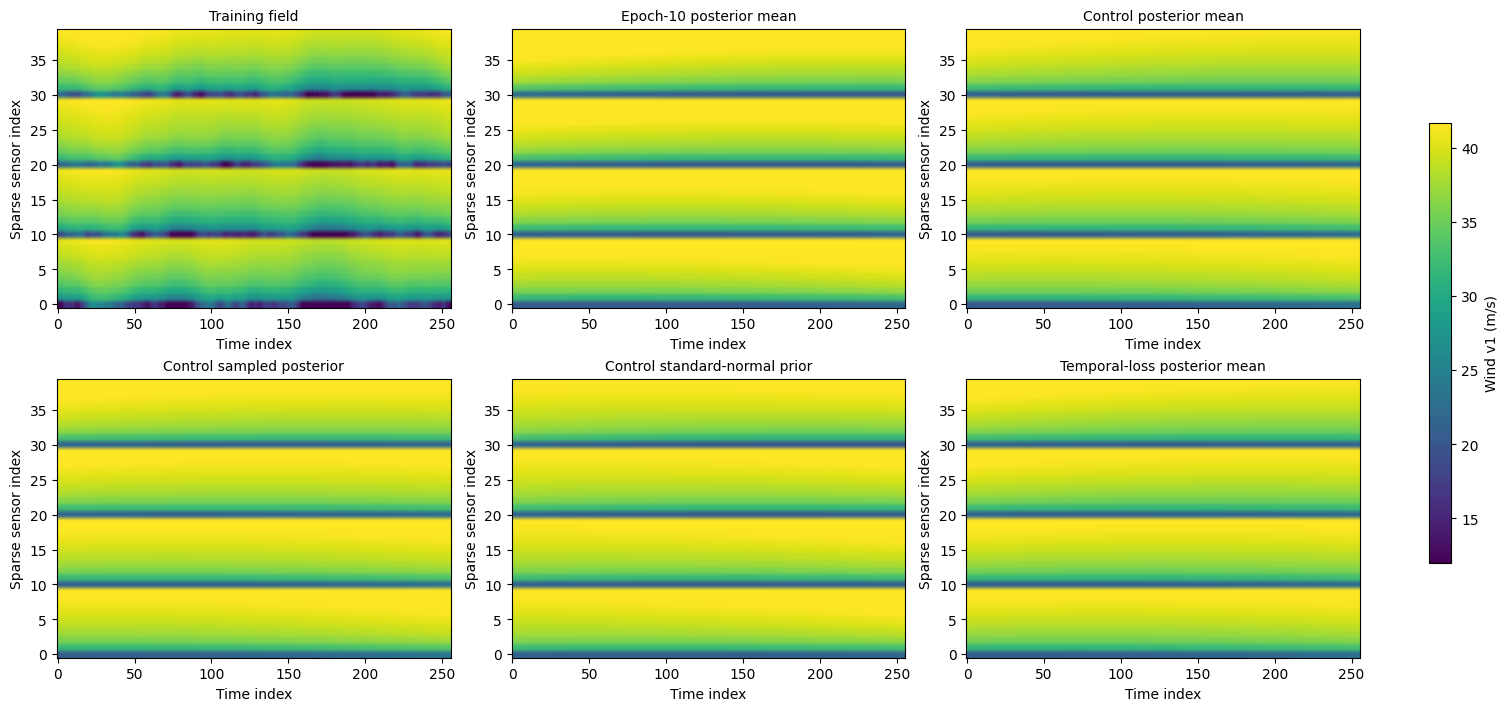


P12 — VAE LATENT/DECODER BOTTLENECK DIAGNOSIS
Training-only reference temporal variance: 0.001355885790567835
Trivial population-mean template MSE: 0.003511958522722125
Trivial per-field time-constant MSE: 0.0013558855280280113

 INITIAL — LATENT STATISTICS
  mean_absolute_posterior_mu: 0.37539393383440256
  mean_across_fields_variance_of_mu: 2.6889723525513935e-07
  mean_posterior_std: 1.0256909764397504
  mean_kl_per_dimension_nats: 0.23084172641575396
  total_kl_per_field_nats: 29.547740981216506
  kl_dims_below_0p01_nats: 6
  num_latent_dimensions: 128
  posterior_mean: temporal=4.2167%, highPSD=4.9394%, fieldVar=2.29398e-08%, MSE=0.004187102895230055
  posterior_sample: temporal=5.5501%, highPSD=7.1217%, fieldVar=1.49445%, MSE=0.004097982309758663
  normal_prior_diagnostic: temporal=6.1527%, highPSD=8.0555%, fieldVar=3.48961%, MSE=None

 CONTROL — LATENT STATISTICS
  mean_absolute_posterior_mu: 0.46686936102412346
  mean_across_fields_variance_of_mu: 5.32396915716818e-06
  mean_p

In [30]:

# CELL P12 — Diagnose VAE oversmoothing and latent-collapse mechanisms
# Add BELOW P11. Read-only evaluation; no retraining or test-HDF5 access.

from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, uuid, sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)
P7 = BASE / (
    "controlled_vae_ablations/"
    "deterministic_replication_20261030T024339Z_c746ee"
)
P11 = BASE / (
    "performance_profiling/"
    "p11_80step_equivalence_20261030T030532Z_870a7b/result.json"
)

assert callable(globals().get("note")), "Activate P1 first."
assert callable(globals().get("verify"))
assert (P7 / "result.json").is_file()
assert P11.is_file()

assert json.loads(
    (P7 / "result.json").read_text()
)["all_exact"] is True

p11 = json.loads(P11.read_text())
assert p11["status"] == "completed"
assert p11["all_updates_exact"] is True

assert torch.cuda.is_available(), "NVIDIA CUDA GPU required."

RUN = BASE / "fidelity_diagnostics" / (
    "p12_latent_audit_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_"
    + uuid.uuid4().hex[:6]
)
RUN.mkdir(parents=True, exist_ok=False)

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]
import wind_vision_physicsnemo_day1 as w

source_sha = hashlib.sha256(
    Path(w.__file__).read_bytes()
).hexdigest()

manifest = json.loads(
    (P7 / "environment_and_manifest.json").read_text()
)["manifest"]

assert source_sha == manifest["source_sha256"], (
    "Implementation differs from P7. "
    "Do not mix source versions."
)

# ------------------------------------------------------------
# 1. Verified checkpoint and training-only diagnostic samples
# ------------------------------------------------------------

ckpt, train_file = w.assert_environment()

FVAE, _, _, _, _, DataCls, LossCls, _, _ = (
    w.prepare_reference_imports()
)

data, _ = w.make_loss_and_data(
    train_file, DataCls, LossCls
)
data.points = data.points.float()

ids = np.asarray(
    manifest["diagnostic_indices"],
    dtype=np.int64
)

assert len(ids) == 32
assert len(set(map(int, ids))) == 32

continuation_ids = set(
    map(int, manifest["continuation_train_indices"])
)

assert not (
    set(map(int, ids)) & continuation_ids
)

assert len(data.sensor_idx) == 40

observed = np.stack([
    data[int(i)][0].numpy()
    for i in ids
]).astype("float32")

coords = data.points.to(
    device="cuda",
    dtype=torch.float32
)

# Original trusted checkpoint:
# Hash verified by w.assert_environment().
original = FVAE.load_from_checkpoint(
    str(ckpt),
    map_location="cpu",
    weights_only=False
).float().eval()

kwargs = dict(
    num_sensors=40,
    latent_dim=128,
    grid_low=original.grid.low.detach().cpu().tolist(),
    grid_high=original.grid.high.detach().cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
)

initial_state = {
    k: v.detach().clone()
    for k, v in original.state_dict().items()
}
del original

# ------------------------------------------------------------
# 2. Statistical fidelity and diagnostic baselines
# ------------------------------------------------------------

def statistics(arr):
    arr = np.asarray(arr, dtype=np.float64)

    centered = arr - arr.mean(
        axis=-1, keepdims=True
    )

    psd = np.abs(
        np.fft.rfft(centered, axis=-1)
    ) ** 2

    def lag_corr(lag):
        var = (centered * centered).mean(-1)

        cross = (
            centered[..., :-lag]
            * centered[..., lag:]
        ).mean(-1)

        valid = var > 1e-12

        return (
            float((cross[valid] / var[valid]).mean())
            if valid.any()
            else None
        )

    return {
        "temporal_variance": float(
            arr.var(axis=-1).mean()
        ),
        "between_field_variance": float(
            arr.var(axis=0).mean()
        ),
        "low_psd_1_6": float(
            psd[..., 1:7].mean()
        ),
        "high_psd_17_64": float(
            psd[..., 17:65].mean()
        ),
        "lag1_acf": lag_corr(1),
        "lag10_acf": lag_corr(10),
        "velocity_mean_m_s": float(
            arr.mean() * 49 - 2
        ),
        "all_finite": bool(
            np.isfinite(arr).all()
        )
    }

reference = statistics(observed)

assert reference["temporal_variance"] > 0
assert reference["high_psd_17_64"] > 0

population_template = np.broadcast_to(
    observed.mean(axis=0, keepdims=True),
    observed.shape
)

time_constant = np.broadcast_to(
    observed.mean(axis=-1, keepdims=True),
    observed.shape
)

baseline_mse = {
    "population_template_mse": float(
        np.mean((population_template - observed) ** 2)
    ),
    "per_field_sensor_temporal_mean_mse": float(
        np.mean((time_constant - observed) ** 2)
    )
}

results = {}
arrays = {"observed": observed}

metric_keys = (
    "temporal_variance",
    "between_field_variance",
    "low_psd_1_6",
    "high_psd_17_64"
)

# ------------------------------------------------------------
# 3. Evaluate identical inputs under three trained models
# ------------------------------------------------------------

for arm in ("initial", "control", "temporal"):

    model = w.PhysicsNeMoWindVAE(
        **kwargs
    ).to(
        device="cuda",
        dtype=torch.float32
    ).eval()

    if arm == "initial":
        model.load_state_dict(
            initial_state,
            strict=True
        )

    else:
        saved_file = (
            P7 / f"repeat_A_{arm}_final.pt"
        )

        assert saved_file.exists(), saved_file

        saved = torch.load(
            saved_file,
            map_location="cpu",
            weights_only=True
        )

        assert saved["strict_deterministic"] is True
        assert saved["steps"] == 80

        model.load_state_dict(
            saved["state_dict"],
            strict=True
        )

    # Matched random streams across all three models.
    posterior_rng = torch.Generator(
        device="cuda"
    ).manual_seed(120126)

    prior_rng = torch.Generator(
        device="cuda"
    ).manual_seed(120127)

    predictions = {
        "posterior_mean": [],
        "posterior_sample": [],
        "normal_prior_diagnostic": []
    }

    mus, logvars = [], []

    with torch.inference_mode():

        for start in range(0, len(ids), 4):

            u = torch.from_numpy(
                observed[start:start+4]
            ).cuda()

            points = coords[None].expand(
                len(u), -1, -1
            )

            mu, logvar = model.encode(u)
            std = torch.exp(0.5 * logvar)

            eps = torch.randn(
                mu.shape,
                device="cuda",
                generator=posterior_rng
            )

            prior = torch.randn(
                mu.shape,
                device="cuda",
                generator=prior_rng
            )

            latent_modes = {
                "posterior_mean": mu,
                "posterior_sample": mu + std * eps,
                "normal_prior_diagnostic": prior
            }

            for mode, z in latent_modes.items():

                pred = model.decode(
                    z, points
                ).reshape(
                    len(u), 40, 256
                )

                predictions[mode].append(
                    pred.cpu().numpy()
                )

            mus.append(mu.cpu())
            logvars.append(logvar.cpu())

    mu = torch.cat(mus).double()
    lv = torch.cat(logvars).double()

    kl_element = 0.5 * (
        mu.square() + lv.exp() - 1.0 - lv
    )

    latent = {
        "mean_absolute_posterior_mu": float(
            mu.abs().mean()
        ),
        "mean_across_fields_variance_of_mu": float(
            mu.var(dim=0, unbiased=False).mean()
        ),
        "mean_posterior_std": float(
            torch.exp(0.5 * lv).mean()
        ),
        "mean_kl_per_dimension_nats": float(
            kl_element.mean()
        ),
        "total_kl_per_field_nats": float(
            kl_element.sum(dim=1).mean()
        ),
        "kl_dims_below_0p01_nats": int(
            (kl_element.mean(dim=0) < 0.01).sum()
        ),
        "num_latent_dimensions": int(
            mu.shape[1]
        )
    }

    modes = {}

    for mode, chunks in predictions.items():

        pred = np.concatenate(
            chunks, axis=0
        )

        assert pred.shape == observed.shape
        assert np.isfinite(pred).all()

        arrays[f"{arm}_{mode}"] = pred

        st = statistics(pred)

        ratios = {
            key: (
                st[key] / reference[key]
                if reference[key] > 1e-20
                else None
            )
            for key in metric_keys
        }

        modes[mode] = {
            "stats": st,
            "ratios_to_reference": ratios,
            "paired_reconstruction_mse": (
                float(np.mean((pred - observed) ** 2))
                if mode != "normal_prior_diagnostic"
                else None
            )
        }

    results[arm] = {
        "latent_diagnostics": latent,
        "modes": modes
    }

    del model
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 4. Save all raw diagnostic outputs and scientific metadata
# ------------------------------------------------------------

report = {
    "experiment":
        "P12_VAE_latent_decoder_bottleneck_diagnosis",

    "time_utc":
        datetime.now(timezone.utc).isoformat(),

    "source_sha256": source_sha,
    "reference_commit": w.PINNED_GIT_SHA,
    "checkpoint_sha256": w.TRUSTED_CHECKPOINT_SHA,

    "model_source": (
        "Trusted epoch-10 VAE and P7 final "
        "control/temporal checkpoints"
    ),

    "probe_indices": ids.tolist(),

    "scope": (
        "Training-only diagnostic. The original "
        "checkpoint previously saw this population."
    ),

    "normal_prior_warning": (
        "Standard-normal samples are a decoder "
        "stress test, not validated flow-generated fields."
    ),

    "reference_stats": reference,
    "trivial_baselines": baseline_mse,
    "models": results,

    "limitations": [
        "No independent test data accessed",
        "Only 32 examples from original training population",
        "Posterior means, stochastic posteriors and priors "
        "are different distributions",
        "No unconditional generation fidelity established",
        "Continuation models received only 80 updates"
    ]
}

report_file = RUN / "p12_latent_diagnostic.json"

report_file.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

np.savez_compressed(
    RUN / "diagnostic_fields.npz",
    **arrays
)

# ------------------------------------------------------------
# 5. Shared physical-scale visualization
# ------------------------------------------------------------

image_keys = [
    "observed",
    "initial_posterior_mean",
    "control_posterior_mean",
    "control_posterior_sample",
    "control_normal_prior_diagnostic",
    "temporal_posterior_mean"
]

labels = [
    "Training field",
    "Epoch-10 posterior mean",
    "Control posterior mean",
    "Control sampled posterior",
    "Control standard-normal prior",
    "Temporal-loss posterior mean"
]

lo, hi = np.quantile(
    observed[0] * 49 - 2,
    [0.01, 0.99]
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 7),
    constrained_layout=True
)

for ax, key, label in zip(
    axes.flat,
    image_keys,
    labels
):

    image = ax.imshow(
        arrays[key][0] * 49 - 2,
        origin="lower",
        aspect="auto",
        cmap="viridis",
        vmin=float(lo),
        vmax=float(hi)
    )

    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor index")

fig.colorbar(
    image,
    ax=axes,
    label="Wind v1 (m/s)",
    shrink=0.7
)

fig_path = (
    RUN / "p12_latent_field_comparison.png"
)

fig.savefig(
    fig_path,
    dpi=150
)

display(fig)
plt.close(fig)

# ------------------------------------------------------------
# 6. Print diagnosis
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("P12 — VAE LATENT/DECODER BOTTLENECK DIAGNOSIS")
print("=" * 72)

print(
    "Training-only reference temporal variance:",
    reference["temporal_variance"]
)

print(
    "Trivial population-mean template MSE:",
    baseline_mse["population_template_mse"]
)

print(
    "Trivial per-field time-constant MSE:",
    baseline_mse["per_field_sensor_temporal_mean_mse"]
)

for arm, result in results.items():

    print("\n", arm.upper(), "— LATENT STATISTICS")

    for key, value in (
        result["latent_diagnostics"].items()
    ):
        print(f"  {key}: {value}")

    for mode, payload in result["modes"].items():

        r = payload["ratios_to_reference"]

        print(
            f"  {mode}: "
            f"temporal={100*r['temporal_variance']:.4f}%, "
            f"highPSD={100*r['high_psd_17_64']:.4f}%, "
            f"fieldVar={100*r['between_field_variance']:.6g}%, "
            f"MSE={payload['paired_reconstruction_mse']}"
        )

# ------------------------------------------------------------
# 7. Permanent research journal and archive verification
# ------------------------------------------------------------

note(
    title=(
        "P12: Encoder posterior and decoder "
        "spectral-collapse diagnosis"
    ),

    question=(
        "Does poor wind fidelity result from posterior "
        "collapse, posterior sampling, or the decoder?"
    ),

    methods=(
        "Evaluate fixed training-only fields using epoch-ten "
        "and P7 continuation models. Compare posterior means, "
        "sampled posteriors, and independent normal latent "
        "stress tests. Measure KL, encoder spread, temporal "
        "spectrum, field variance, and trivial baselines."
    ),

    evidence=[
        str(report_file),
        str(RUN / "diagnostic_fields.npz"),
        str(fig_path)
    ],

    findings={
        "latent_statistics": {
            name: result["latent_diagnostics"]
            for name, result in results.items()
        },

        "posterior_mean_temporal_retention": {
            name: result["modes"]["posterior_mean"][
                "ratios_to_reference"
            ]["temporal_variance"]
            for name, result in results.items()
        },

        "normal_prior_temporal_retention": {
            name: result["modes"]["normal_prior_diagnostic"][
                "ratios_to_reference"
            ]["temporal_variance"]
            for name, result in results.items()
        }
    },

    limitations=report["limitations"],

    decision=(
        "Use these diagnostics to select one falsifiable "
        "fidelity intervention. No independent generation "
        "or generalization claims."
    )
)

print("\nSaved:", RUN)
print(
    "Verified research archive entries:",
    verify()
)

print(
    "CELL P12 COMPLETE — No retraining or test-data access"
)


Dataset coordinate precision verified: torch.float32
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during

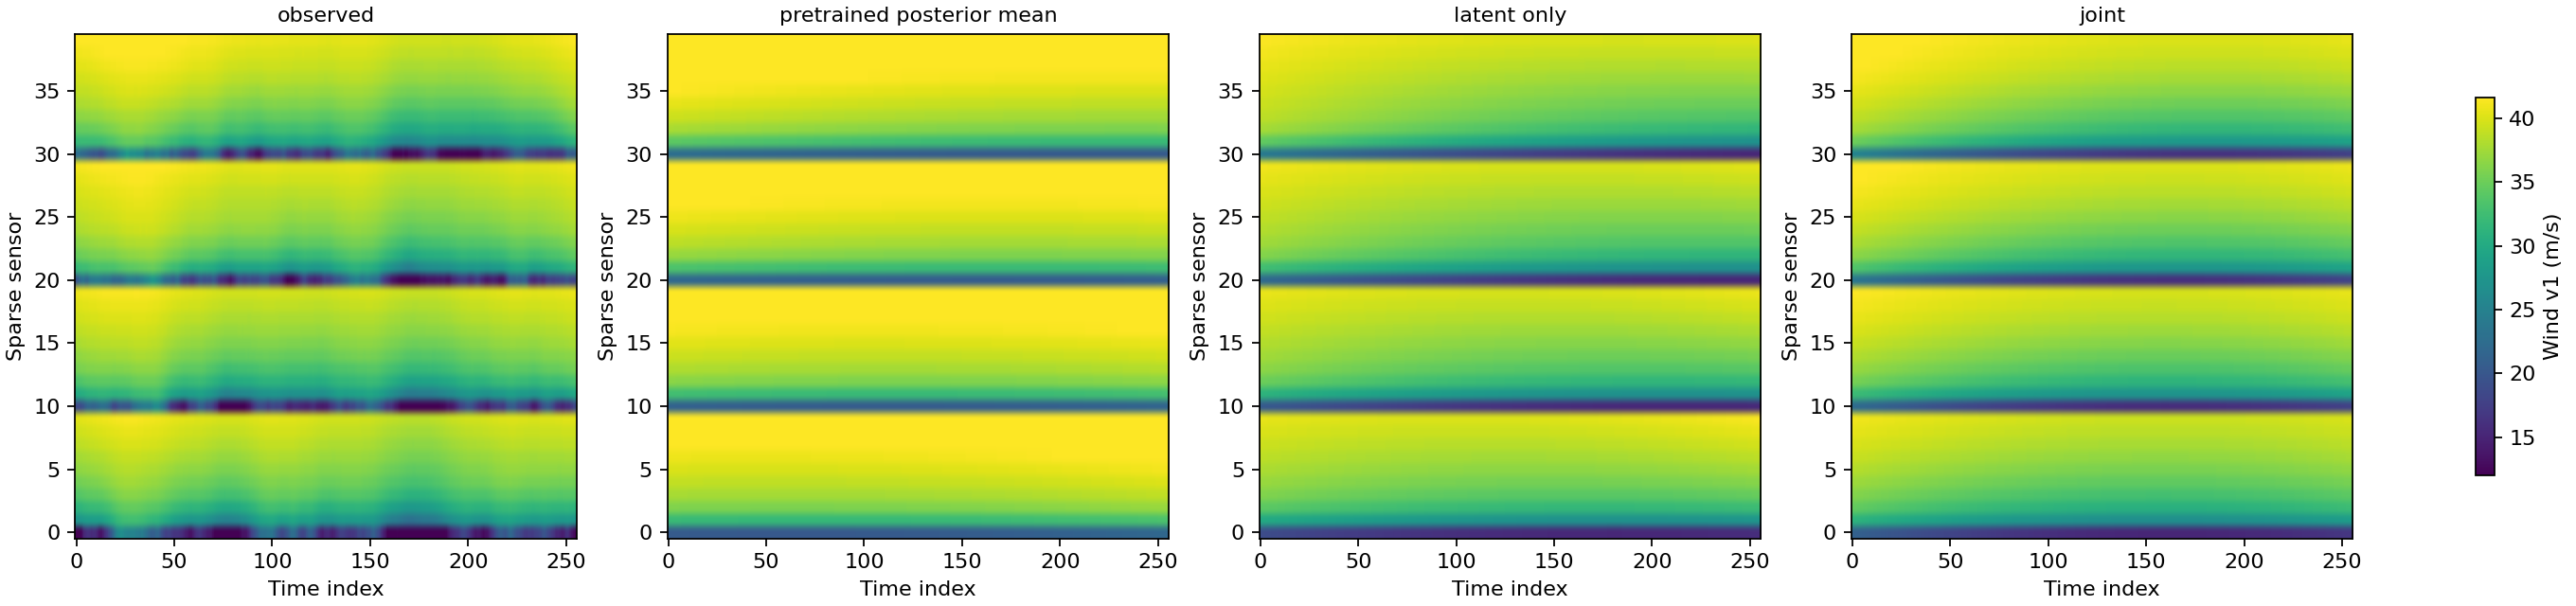

Evidence directory: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p13_decoder_capacity_20261102T152825Z_1db8f9
Research archive verified: 634
CELL P13 COMPLETE


In [31]:

# CELL P13 — Decoder representability vs latent-inference stress test
# Add immediately below P12.
# No changes to NASA source or previous experimental results.

from pathlib import Path
from datetime import datetime, timezone
import json, os, subprocess, sys, textwrap, uuid

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

assert callable(globals().get("note")), (
    "Run the scope-locked P1 recorder first."
)
assert callable(globals().get("verify"))

P7 = BASE / (
    "controlled_vae_ablations/"
    "deterministic_replication_20261030T024339Z_c746ee"
)

assert (P7 / "environment_and_manifest.json").is_file()

RUN = BASE / "fidelity_diagnostics" / (
    "p13_decoder_capacity_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)
WORKER = RUN / "worker.py"

WORKER.write_text(textwrap.dedent(r'''
import json, sys, os, hashlib, traceback
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]

import wind_vision_physicsnemo_day1 as w

out = Path(sys.argv[1])
manifest_path = Path(sys.argv[2])

manifest = json.loads(
    manifest_path.read_text()
)["manifest"]

report = {
    "experiment": "P13_frozen_decoder_vs_joint_decoder_fit",
    "status": "started",
    "scope": (
        "Four fixed examples from the training-only "
        "diagnostic pool. Supervised representational "
        "stress test, NOT independent generation."
    ),
    "arms": {
        "latent_only": (
            "Optimize four field-specific latent codes "
            "while freezing the pretrained decoder."
        ),
        "joint": (
            "Restart pretrained decoder and jointly "
            "optimize field-specific latent codes and "
            "decoder branch/trunk."
        )
    },
    "limitations": [
        "Only four fields from original training population",
        "Oracle latent codes use known target fields",
        "Joint fitting is memorization, not generalization",
        "Stress-test objective differs from NASA VAE loss",
        "Failure within a limited training budget does "
        "not prove architectural impossibility"
    ]
}

def save():
    (out / "result.json").write_text(
        json.dumps(
            report,
            indent=2,
            allow_nan=False,
            default=str
        )
    )

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()

def statistics(a):
    a = np.asarray(a, dtype=np.float64)
    centered = a - a.mean(
        axis=-1, keepdims=True
    )
    psd = np.abs(
        np.fft.rfft(centered, axis=-1)
    ) ** 2

    return {
        "temporal_variance": float(
            np.var(a, axis=-1).mean()
        ),
        "high_psd_17_64": float(
            psd[..., 17:65].mean()
        ),
        "between_field_variance": float(
            np.var(a, axis=0).mean()
        )
    }

def evaluate(truth, prediction):
    truth = np.asarray(
        truth, dtype=np.float64
    )
    prediction = np.asarray(
        prediction, dtype=np.float64
    )

    true_stats = statistics(truth)
    pred_stats = statistics(prediction)

    true_center = truth - truth.mean(
        axis=-1, keepdims=True
    )
    pred_center = prediction - prediction.mean(
        axis=-1, keepdims=True
    )

    numerator = (
        true_center * pred_center
    ).mean(axis=-1)

    denominator = np.sqrt(
        (true_center ** 2).mean(axis=-1)
        * (pred_center ** 2).mean(axis=-1)
    )

    valid = denominator > 1e-12

    correlations = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=valid
    )

    return {
        "mse": float(
            np.mean((truth - prediction) ** 2)
        ),
        "centered_temporal_mse": float(
            np.mean(
                (true_center - pred_center) ** 2
            )
        ),
        "time_correlation_mean": (
            float(correlations[valid].mean())
            if valid.any() else None
        ),
        "prediction_stats": pred_stats,
        "ratios_to_reference": {
            k: pred_stats[k] / max(
                true_stats[k], 1e-20
            )
            for k in true_stats
        }
    }

try:
    # --------------------------------------------------
    # 1. Strict deterministic execution
    # --------------------------------------------------

    assert (
        os.environ.get("CUBLAS_WORKSPACE_CONFIG")
        == ":4096:8"
    )

    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

    assert torch.cuda.is_available()

    torch.manual_seed(20261030)
    torch.cuda.manual_seed_all(20261030)

    source = Path(w.__file__)

    assert sha(source) == manifest[
        "source_sha256"
    ], "Implementation changed since P7."

    ckpt, train_file = w.assert_environment()

    assert sha(train_file) == (
        "676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941"
    )

    (
        FVAE, _, _, _, _,
        DataCls, LossCls, _, _
    ) = w.prepare_reference_imports()

    data, _ = w.make_loss_and_data(
        train_file, DataCls, LossCls
    )

    data.points = data.points.float()

    assert len(data.sensor_idx) == 40

    # Fixed, pre-existing diagnostic sample order.
    ids = list(map(
        int,
        manifest["diagnostic_indices"][:4]
    ))

    assert len(ids) == 4
    assert len(set(ids)) == 4

    train_ids = set(map(
        int,
        manifest["continuation_train_indices"]
    ))

    assert not (set(ids) & train_ids)

    u = torch.stack([
        data[i][0] for i in ids
    ]).to(
        "cuda", dtype=torch.float32
    )

    x = data.points.to(
        "cuda", dtype=torch.float32
    )[None].expand(4, -1, -1)

    # Trusted checkpoint is hash-verified by
    # w.assert_environment() before deserialization.
    trusted = FVAE.load_from_checkpoint(
        str(ckpt),
        map_location="cpu",
        weights_only=False
    ).float().eval()

    kwargs = dict(
        num_sensors=40,
        latent_dim=128,
        grid_low=trusted.grid.low.detach()
            .cpu().tolist(),
        grid_high=trusted.grid.high.detach()
            .cpu().tolist(),
        p_deeponet=512,
        h_branch=128,
        h_trunk=128,
        nhl_branch=2,
        nhl_trunk=2,
        num_fields=1
    )

    initial_state = {
        k: v.detach().clone()
        for k, v in trusted.state_dict().items()
    }

    del trusted

    def new_model():
        model = w.PhysicsNeMoWindVAE(
            **kwargs
        ).to(
            device="cuda",
            dtype=torch.float32
        ).eval()

        model.load_state_dict(
            initial_state,
            strict=True
        )

        return model

    # --------------------------------------------------
    # 2. Baseline posterior-mean reconstruction
    # --------------------------------------------------

    original = new_model()

    with torch.no_grad():
        mu, _ = original.encode(u)

    starting_z = mu.detach().clone()

    with torch.no_grad():
        initial_prediction = original.decode(
            starting_z, x
        ).reshape_as(u)

    truth = u.detach().cpu().numpy()

    baseline = (
        initial_prediction.detach()
        .cpu().numpy()
    )

    report["environment"] = {
        "gpu": torch.cuda.get_device_name(0),
        "torch": torch.__version__,
        "source_sha256": sha(source),
        "trusted_checkpoint_sha256":
            w.TRUSTED_CHECKPOINT_SHA,
        "deterministic":
            torch.are_deterministic_algorithms_enabled(),
        "selected_indices": ids,
        "starting_latent_l2_mean": float(
            starting_z.norm(dim=1).mean()
        )
    }

    report["reference_stats"] = statistics(truth)
    report["baseline"] = evaluate(
        truth, baseline
    )

    report["oracle_time_constant_mse"] = float(
        np.mean(
            (
                truth
                - truth.mean(
                    axis=-1,
                    keepdims=True
                )
            ) ** 2
        )
    )

    report["description"] = (
        "Both stress-test arms minimize raw MSE plus "
        "three times temporally centered MSE. "
        "No KL or coherence objective is applied. "
        "This is not normal NASA VAE training."
    )

    curves = []

    final_fields = {
        "observed": truth,
        "pretrained_posterior_mean": baseline
    }

    del original

    # --------------------------------------------------
    # 3. Two controlled decoder-capacity stress tests
    # --------------------------------------------------

    def train_arm(
        label, steps, lr_z, lr_decoder
    ):

        torch.manual_seed(20261030)

        model = new_model()

        # Encoder is never updated in either arm.
        model.requires_grad_(False)

        if lr_decoder is not None:
            model._branch.requires_grad_(True)
            model._trunk.requires_grad_(True)
            model._bias.requires_grad_(True)

        # One freely optimized latent for each field.
        z = nn.Parameter(
            starting_z.clone()
        )

        groups = [{
            "params": [z],
            "lr": lr_z
        }]

        if lr_decoder is not None:
            groups.append({
                "params": [
                    p for p in model.parameters()
                    if p.requires_grad
                ],
                "lr": lr_decoder
            })

        optimizer = torch.optim.Adam(groups)

        for step in range(1, steps + 1):

            optimizer.zero_grad(
                set_to_none=True
            )

            prediction = model.decode(
                z, x
            ).reshape_as(u)

            reconstruction = F.mse_loss(
                prediction, u
            )

            pred_center = (
                prediction
                - prediction.mean(
                    dim=-1, keepdim=True
                )
            )

            true_center = (
                u - u.mean(
                    dim=-1, keepdim=True
                )
            )

            dynamic = F.mse_loss(
                pred_center, true_center
            )

            objective = (
                reconstruction + 3.0 * dynamic
            )

            if not torch.isfinite(objective):
                raise FloatingPointError(
                    f"{label} nonfinite at step {step}"
                )

            objective.backward()
            optimizer.step()

            if (
                step in (
                    1, 10, 25, 50, 100,
                    200, 300, 400, 600
                )
                or step == steps
            ):

                with torch.no_grad():
                    current = model.decode(
                        z, x
                    ).reshape_as(u)
                    current = (
                        current.detach()
                        .cpu().numpy()
                    )

                assessment = evaluate(
                    truth, current
                )

                entry = {
                    "arm": label,
                    "step": step,
                    "objective_before_update": float(
                        objective.detach()
                    ),
                    "evaluation_after_update": assessment
                }

                curves.append(entry)

                print(
                    label,
                    "step", step,
                    "MSE",
                    round(assessment["mse"], 7),
                    "temporal retention",
                    round(
                        100 * assessment[
                            "ratios_to_reference"
                        ]["temporal_variance"],
                        2
                    ),
                    "%",
                    flush=True
                )

                report["progress"] = {
                    "arm": label,
                    "step": step
                }

                (out / "trace.json").write_text(
                    json.dumps(
                        curves,
                        indent=2,
                        allow_nan=False
                    )
                )

                save()

        with torch.no_grad():
            prediction = model.decode(
                z, x
            ).reshape_as(u)
            prediction = prediction.cpu().numpy()

        assessment = evaluate(
            truth, prediction
        )

        assessment["latent_l2_mean"] = float(
            z.detach().norm(dim=1).mean()
        )

        report[label] = assessment
        final_fields[label] = prediction

        torch.save({
            "optimized_latents":
                z.detach().cpu(),
            "model_state_dict": (
                model.state_dict()
                if lr_decoder is not None
                else None
            ),
            "config": {
                "steps": steps,
                "lr_latent": lr_z,
                "lr_decoder": lr_decoder,
                "temporal_centered_weight": 3.0,
                "diagnostic_indices": ids
            }
        }, out / f"{label}_final.pt")

        del optimizer, model, z
        torch.cuda.empty_cache()

    # Arm A: Can the existing decoder represent dynamics
    # by changing only the latent input?
    train_arm(
        label="latent_only",
        steps=250,
        lr_z=0.05,
        lr_decoder=None
    )

    # Arm B: Restart original decoder weights and test
    # whether the architecture can memorize these fields.
    train_arm(
        label="joint",
        steps=450,
        lr_z=0.03,
        lr_decoder=0.001
    )

    # --------------------------------------------------
    # 4. Save final figures and diagnostic evidence
    # --------------------------------------------------

    report["status"] = "completed"

    report["training_steps"] = {
        "latent_only": 250,
        "joint": 450
    }

    np.savez_compressed(
        out / "fields.npz",
        **final_fields
    )

    fig, axes = plt.subplots(
        1, 4,
        figsize=(17, 4),
        constrained_layout=True
    )

    lo, hi = np.quantile(
        truth[0] * 49 - 2,
        [0.01, 0.99]
    )

    for ax, (name, field) in zip(
        axes, final_fields.items()
    ):

        im = ax.imshow(
            field[0] * 49 - 2,
            origin="lower",
            aspect="auto",
            cmap="viridis",
            vmin=float(lo),
            vmax=float(hi)
        )

        ax.set_title(
            name.replace("_", " "),
            fontsize=10
        )
        ax.set_xlabel("Time index")
        ax.set_ylabel("Sparse sensor")

    fig.colorbar(
        im,
        ax=axes,
        label="Wind v1 (m/s)",
        shrink=0.75
    )

    fig.savefig(
        out / "capacity_stress_test.png",
        dpi=160
    )

    plt.close(fig)

except Exception as exc:

    report["status"] = "failed"
    report["error"] = repr(exc)
    report["traceback"] = traceback.format_exc()

    print(
        report["traceback"][-5000:],
        flush=True
    )

finally:

    save()

    print("\nP13 WORKER STATUS:", report["status"])

    for arm in (
        "baseline", "latent_only", "joint"
    ):

        if arm not in report:
            continue

        m = report[arm]

        print("\n", arm.upper())
        print("Reconstruction MSE:", m["mse"])
        print(
            "Temporal-dynamics MSE:",
            m["centered_temporal_mse"]
        )
        print(
            "Temporal variance retained:",
            100 * m["ratios_to_reference"][
                "temporal_variance"
            ],
            "%"
        )
        print(
            "High-frequency power retained:",
            100 * m["ratios_to_reference"][
                "high_psd_17_64"
            ],
            "%"
        )

    if report["status"] == "failed":
        print("Failure:", report.get("error"))
'''))

# Validate worker syntax before starting.
compile(
    WORKER.read_text(),
    str(WORKER),
    "exec"
)

ENV = os.environ.copy()

ENV["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
ENV["PYTHONHASHSEED"] = "0"

LOG = RUN / "execution.log"

with LOG.open("w") as f:

    process = subprocess.Popen(
        [
            sys.executable,
            "-u",
            str(WORKER),
            str(RUN),
            str(
                P7 / "environment_and_manifest.json"
            )
        ],
        cwd="/content",
        env=ENV,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        f.write(line)
        f.flush()

    exit_code = process.wait()

REPORT = RUN / "result.json"

assert REPORT.is_file(), (
    f"No P13 result file. Inspect {LOG}"
)

result = json.loads(
    REPORT.read_text()
)

print("\n" + "=" * 65)
print("P13 — DECODER CAPACITY SUMMARY")
print("=" * 65)

print("Worker status:", result["status"])
print("Exit code:", exit_code)

if result["status"] == "completed":

    from IPython.display import display, Image

    display(Image(
        filename=str(
            RUN / "capacity_stress_test.png"
        )
    ))

else:

    print(
        "Failure details preserved:",
        result.get("error")
    )

note(
    title=(
        "P13: Frozen decoder versus oracle-latent "
        "capacity stress test"
    ),
    question=(
        "Can the pretrained decoder reproduce temporal "
        "wind dynamics using optimized per-field latent "
        "codes, or does its decoder need fine-tuning?"
    ),
    methods=(
        "Four training-only fields. Strict deterministic "
        "CUDA, 250 latent-only steps, 450 decoder-plus-"
        "latent steps, both from the same epoch-ten "
        "checkpoint. Supervised reconstruction plus "
        "temporally centered reconstruction."
    ),
    evidence=[
        str(WORKER),
        str(LOG),
        str(REPORT),
        str(RUN / "trace.json"),
        str(RUN / "fields.npz"),
        str(RUN / "capacity_stress_test.png")
    ],
    findings={
        "status": result["status"],
        "baseline": result.get("baseline"),
        "latent_only": result.get("latent_only"),
        "joint": result.get("joint")
    },
    limitations=result.get(
        "limitations", []
    ),
    decision=(
        "Interpret only as a decoder representability "
        "and optimization stress test. Four-field "
        "memorization does not demonstrate independent "
        "generation or generalization."
    )
)

print("Evidence directory:", RUN)
print("Research archive verified:", verify())
print("CELL P13 COMPLETE")


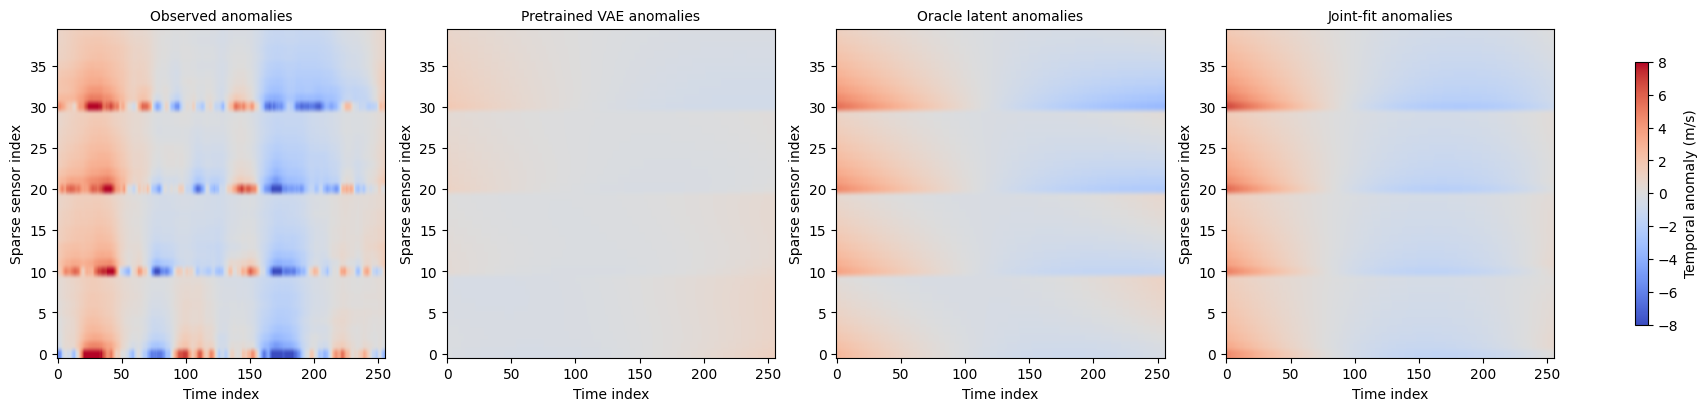

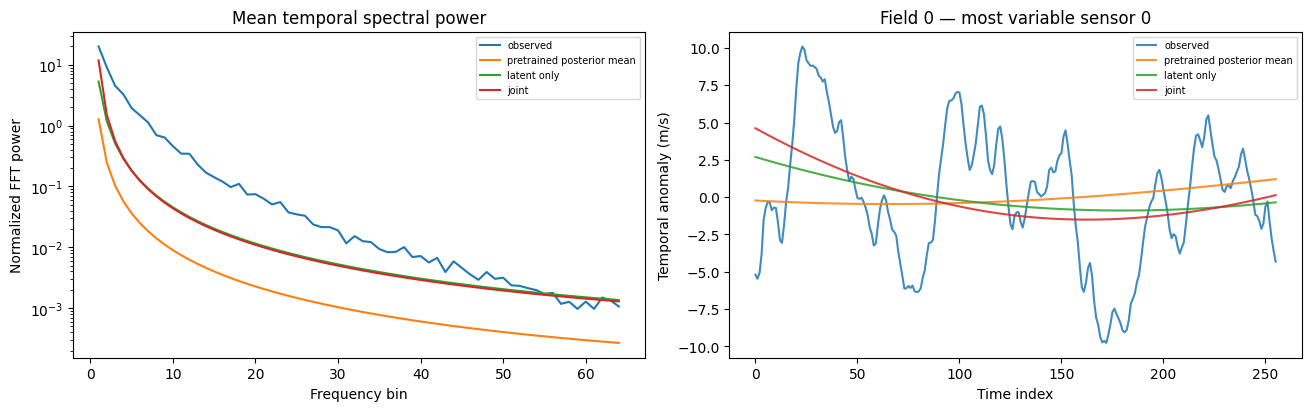


P14 — TEMPORAL RECONSTRUCTION SKILL

MODEL: pretrained_posterior_mean
Total MSE: 0.005210259834310682
Static-profile MSE: 0.003808959500089128
Dynamic MSE: 0.0014013003342215537
Temporal anomaly R2: -0.011060218546598666
Per-field anomaly R2: [0.1190029126588753, -0.1639544570681326, 0.005578463928707644, -0.0040430451023536484]
  low_1_6 power ratio: 0.04315 band R2: -0.01013 alignment: 0.07948
  mid_7_16 power ratio: 0.01956 band R2: -0.00788 alignment: 0.04176
  high_17_64 power ratio: 0.04802 band R2: -0.05661 alignment: -0.01959

MODEL: latent_only
Total MSE: 0.0013602225898304175
Static-profile MSE: 0.00021801493966620896
Dynamic MSE: 0.0011422076501642086
Temporal anomaly R2: 0.17587922574630988
Per-field anomaly R2: [0.38815812660827853, -0.0483002120972551, 0.0460100195146661, 0.33377194924261]
  low_1_6 power ratio: 0.18828 band R2: 0.22094 alignment: 0.47155
  mid_7_16 power ratio: 0.09885 band R2: -0.14133 alignment: -0.06755
  high_17_64 power ratio: 0.2433 band R2: -0.27

In [32]:

# ============================================================
# CELL P14 — DYNAMIC RECONSTRUCTION AND SPECTRAL SKILL
#
# Complete, read-only diagnostic using P13 saved fields.
# No retraining, no model loading, no test HDF5 access.
#
# Separates:
# - Static (time-averaged) reconstruction error
# - Time-varying reconstruction error
# - Spectral energy versus spectral reconstruction skill
# - Frequency amplitude versus phase alignment
#
# Reports results honestly as a four-field oracle-fit test.
# ============================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

P13 = BASE / (
    "fidelity_diagnostics/"
    "p13_decoder_capacity_20261030T031526Z_9fcb10"
)

assert callable(globals().get("note")), (
    "Run the corrected research recorder P1 first."
)
assert callable(globals().get("verify"))

SOURCE = P13 / "fields.npz"
P13_REPORT = P13 / "result.json"

assert SOURCE.is_file(), SOURCE
assert P13_REPORT.is_file(), P13_REPORT

previous = json.loads(P13_REPORT.read_text())

assert previous["status"] == "completed"

names = (
    "pretrained_posterior_mean",
    "latent_only",
    "joint"
)

with np.load(SOURCE, allow_pickle=False) as saved:

    assert all(
        key in saved.files
        for key in ("observed", *names)
    )

    fields = {
        key: np.asarray(
            saved[key],
            dtype=np.float64
        )
        for key in ("observed", *names)
    }

truth = fields["observed"]

assert truth.shape == (4, 40, 256)

for name, arr in fields.items():
    assert arr.shape == truth.shape
    assert np.isfinite(arr).all(), (
        f"Nonfinite saved data: {name}"
    )

digest = hashlib.sha256(
    SOURCE.read_bytes()
).hexdigest()

RUN = BASE / "fidelity_diagnostics" / (
    "p14_dynamic_skill_" + digest[:16]
)

RUN.mkdir(parents=True, exist_ok=True)

REPORT = RUN / "dynamic_skill_audit.json"
FIGURE = RUN / "temporal_anomalies.png"
SPECTRUM_FIGURE = RUN / "spectral_and_time_trace.png"

# ------------------------------------------------------------
# 1. Exact static/dynamic orthogonal MSE decomposition
# ------------------------------------------------------------

def decompose(reference, prediction):

    error = prediction - reference

    mean_error = error.mean(
        axis=-1,
        keepdims=True
    )

    fluctuation_error = error - mean_error

    total = float(
        np.mean(error ** 2)
    )

    static = float(
        np.mean(mean_error ** 2)
    )

    dynamic = float(
        np.mean(fluctuation_error ** 2)
    )

    assert np.isclose(
        total,
        static + dynamic,
        atol=1e-12,
        rtol=1e-10
    )

    return {
        "total_mse": total,
        "static_profile_mse": static,
        "dynamic_mse": dynamic,
        "static_fraction_of_total_mse": (
            static / total
            if total > 0
            else None
        )
    }

# ------------------------------------------------------------
# 2. Time-anomaly skill relative to a constant prediction
# ------------------------------------------------------------

true_anomaly = truth - truth.mean(
    axis=-1,
    keepdims=True
)

reference_dynamic_energy = float(
    np.mean(true_anomaly ** 2)
)

assert reference_dynamic_energy > 0

def anomaly_skill(prediction):

    predicted_anomaly = (
        prediction - prediction.mean(
            axis=-1,
            keepdims=True
        )
    )

    squared_error = (
        true_anomaly - predicted_anomaly
    ) ** 2

    global_skill = (
        1.0
        - float(np.mean(squared_error))
        / reference_dynamic_energy
    )

    per_field = []

    for i in range(len(truth)):

        energy = float(
            np.mean(
                true_anomaly[i] ** 2
            )
        )

        error = float(
            np.mean(
                squared_error[i]
            )
        )

        per_field.append(
            1.0 - error / max(energy, 1e-20)
        )

    return {
        "dynamic_r2": global_skill,
        "per_field_dynamic_r2": per_field,
        "reference_dynamic_energy":
            reference_dynamic_energy
    }

# ------------------------------------------------------------
# 3. Fourier-band diagnostics
#
# Energy ratio:
#     produced power / reference power
#
# Band R2:
#     1 - squared Fourier coefficient error
#         / reference Fourier energy
#
# Unlike energy ratios, band R2 penalizes incorrect
# temporal phase as well as amplitude.
# ------------------------------------------------------------

BANDS = {
    "low_1_6": (1, 7),
    "mid_7_16": (7, 17),
    "high_17_64": (17, 65)
}

true_fft = np.fft.rfft(
    true_anomaly,
    axis=-1
)

def spectral_skill(prediction):

    anomaly = prediction - prediction.mean(
        axis=-1,
        keepdims=True
    )

    predicted_fft = np.fft.rfft(
        anomaly,
        axis=-1
    )

    output = {}

    for label, (start, stop) in BANDS.items():

        actual = true_fft[..., start:stop]
        estimate = predicted_fft[..., start:stop]

        actual_energy = float(
            np.abs(actual).astype(
                np.float64
            ).__pow__(2).sum()
        )

        predicted_energy = float(
            (np.abs(estimate) ** 2).sum()
        )

        error_energy = float(
            (
                np.abs(estimate - actual) ** 2
            ).sum()
        )

        cross = float(
            np.vdot(actual, estimate).real
        )

        norm = np.sqrt(
            actual_energy * predicted_energy
        )

        output[label] = {
            "power_ratio":
                predicted_energy
                / max(actual_energy, 1e-20),

            "band_reconstruction_r2":
                1.0 - error_energy
                / max(actual_energy, 1e-20),

            "complex_alignment":
                cross / norm
                if norm > 1e-20
                else None
        }

    return output

# ------------------------------------------------------------
# 4. Assess every saved model and verify original results
# ------------------------------------------------------------

assessments = {}

for key in names:

    prediction = fields[key]

    assessment = {
        **decompose(truth, prediction),
        **anomaly_skill(prediction),
        "spectral_bands":
            spectral_skill(prediction)
    }

    assessments[key] = assessment

    historical_key = (
        "baseline"
        if key == "pretrained_posterior_mean"
        else key
    )

    previous_mse = previous[
        historical_key
    ]["mse"]

    assert np.isclose(
        previous_mse,
        assessment["total_mse"],
        rtol=1e-5,
        atol=1e-9
    ), (
        f"P13/P14 MSE mismatch: {key}"
    )

initial = assessments[
    "pretrained_posterior_mean"
]

joint = assessments["joint"]

total_improvement = (
    initial["total_mse"]
    - joint["total_mse"]
)

static_improvement = (
    initial["static_profile_mse"]
    - joint["static_profile_mse"]
)

static_share = (
    static_improvement / total_improvement
    if total_improvement > 0
    else None
)

# ------------------------------------------------------------
# 5. Save machine-readable results
# ------------------------------------------------------------

result = {
    "experiment":
        "P14_four_field_temporal_spectral_skill",

    "source_fields_sha256": digest,

    "source_experiment": str(P13),

    "evaluation_scope": (
        "Four training-population fields used during "
        "oracle latent and decoder optimization. "
        "No independent validation."
    ),

    "normalization": (
        "(wind velocity m/s + 2) / 49"
    ),

    "num_fields": int(truth.shape[0]),

    "num_sparse_sensors": int(truth.shape[1]),

    "num_time_samples": int(truth.shape[2]),

    "reference_dynamic_energy":
        reference_dynamic_energy,

    "models": assessments,

    "joint_improvement_from_static_profile": (
        static_share
    ),

    "interpretation": {
        "dynamic_r2": (
            "0 corresponds to a time-constant "
            "per-field/sensor anomaly predictor. "
            "Negative values are worse."
        ),
        "spectral_band_r2": (
            "Measures reconstruction of complex "
            "Fourier coefficients, including phase. "
            "A high power ratio alone does not "
            "imply good reconstruction."
        )
    },

    "limitations": [
        "Four oracle-fitted training-population fields",
        "No held-out generalization",
        "No independent generation",
        "Spectral power and spectral skill differ",
        "Only 40 sparse sensors"
    ]
}

created = not REPORT.exists()

if created:

    REPORT.write_text(
        json.dumps(
            result,
            indent=2,
            allow_nan=False
        )
    )

# ------------------------------------------------------------
# 6. Visualization A: Actual temporal fluctuations
# ------------------------------------------------------------

anomalies = {
    key: array - array.mean(
        axis=-1,
        keepdims=True
    )
    for key, array in fields.items()
}

limit = float(
    np.quantile(
        np.abs(
            anomalies["observed"][0] * 49
        ),
        0.995
    )
)

limit = max(limit, 1e-6)

fig, axes = plt.subplots(
    1, 4,
    figsize=(17, 4),
    constrained_layout=True
)

display_keys = (
    "observed",
    "pretrained_posterior_mean",
    "latent_only",
    "joint"
)

titles = (
    "Observed anomalies",
    "Pretrained VAE anomalies",
    "Oracle latent anomalies",
    "Joint-fit anomalies"
)

for ax, key, title in zip(
    axes,
    display_keys,
    titles
):

    im = ax.imshow(
        anomalies[key][0] * 49,
        origin="lower",
        aspect="auto",
        vmin=-limit,
        vmax=limit,
        cmap="coolwarm"
    )

    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor index")

fig.colorbar(
    im,
    ax=axes,
    label="Temporal anomaly (m/s)",
    shrink=0.8
)

fig.savefig(
    FIGURE,
    dpi=160
)

display(fig)
plt.close(fig)

# ------------------------------------------------------------
# 7. Visualization B: Frequency power and aligned time trace
# ------------------------------------------------------------

selected_sensor = int(
    np.argmax(
        truth[0].var(axis=-1)
    )
)

figure, axes = plt.subplots(
    1, 2,
    figsize=(13, 4),
    constrained_layout=True
)

for key in display_keys:

    centered = anomalies[key]

    power = (
        np.abs(
            np.fft.rfft(
                centered,
                axis=-1
            )
        ) ** 2
    ).mean(axis=(0, 1))

    axes[0].semilogy(
        np.arange(1, 65),
        np.maximum(power[1:65], 1e-20),
        label=key.replace("_", " ")
    )

    axes[1].plot(
        np.arange(256),
        centered[0, selected_sensor] * 49,
        label=key.replace("_", " "),
        alpha=0.85
    )

axes[0].set_title("Mean temporal spectral power")
axes[0].set_xlabel("Frequency bin")
axes[0].set_ylabel("Normalized FFT power")
axes[0].legend(fontsize=7)

axes[1].set_title(
    f"Field 0 — most variable sensor {selected_sensor}"
)
axes[1].set_xlabel("Time index")
axes[1].set_ylabel("Temporal anomaly (m/s)")
axes[1].legend(fontsize=7)

figure.savefig(
    SPECTRUM_FIGURE,
    dpi=160
)

display(figure)
plt.close(figure)

# ------------------------------------------------------------
# 8. Print scientific results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("P14 — TEMPORAL RECONSTRUCTION SKILL")
print("=" * 70)

for key, assessment in assessments.items():

    print("\nMODEL:", key)

    print(
        "Total MSE:",
        assessment["total_mse"]
    )

    print(
        "Static-profile MSE:",
        assessment["static_profile_mse"]
    )

    print(
        "Dynamic MSE:",
        assessment["dynamic_mse"]
    )

    print(
        "Temporal anomaly R2:",
        assessment["dynamic_r2"]
    )

    print(
        "Per-field anomaly R2:",
        assessment["per_field_dynamic_r2"]
    )

    for band, stats in (
        assessment["spectral_bands"].items()
    ):

        print(
            " ", band,
            "power ratio:",
            round(stats["power_ratio"], 5),
            "band R2:",
            round(
                stats["band_reconstruction_r2"],
                5
            ),
            "alignment:",
            round(
                stats["complex_alignment"],
                5
            )
            if stats["complex_alignment"] is not None
            else None
        )

print(
    "\nFraction of total original-to-joint MSE "
    "improvement due to static profile fitting:",
    static_share
)

# ------------------------------------------------------------
# 9. Permanent documentation
# ------------------------------------------------------------

if created:

    note(
        title=(
            "P14: Oracle decoder temporal anomaly "
            "and spectral phase-alignment audit"
        ),

        question=(
            "Does the capacity stress test recover "
            "correct temporal fluctuations or merely "
            "increase aggregate spectral power?"
        ),

        methods=(
            "Analyze saved P13 four-field reconstructions "
            "without retraining. Decompose static and "
            "dynamic MSE; compute anomaly R2, per-field "
            "skill and complex Fourier-band skill."
        ),

        evidence=[
            str(SOURCE),
            str(REPORT),
            str(FIGURE),
            str(SPECTRUM_FIGURE)
        ],

        findings={
            "dynamic_r2": {
                key: value["dynamic_r2"]
                for key, value in assessments.items()
            },
            "joint_static_improvement_fraction":
                static_share,
            "high_band_r2": {
                key: value["spectral_bands"][
                    "high_17_64"
                ]["band_reconstruction_r2"]
                for key, value in assessments.items()
            }
        },

        limitations=result["limitations"],

        decision=(
            "Use temporal-anomaly and Fourier-coefficient "
            "reconstruction skill, not power retention "
            "alone, to design the next decoder or "
            "encoder intervention."
        )
    )

print("\nSaved report:", REPORT)
print("Saved anomaly figure:", FIGURE)
print("Saved spectral figure:", SPECTRUM_FIGURE)

print(
    "Verified archive entries:",
    verify()
)

print("CELL P14 COMPLETE — NO RETRAINING")


Dataset coordinate precision verified: torch.float32


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

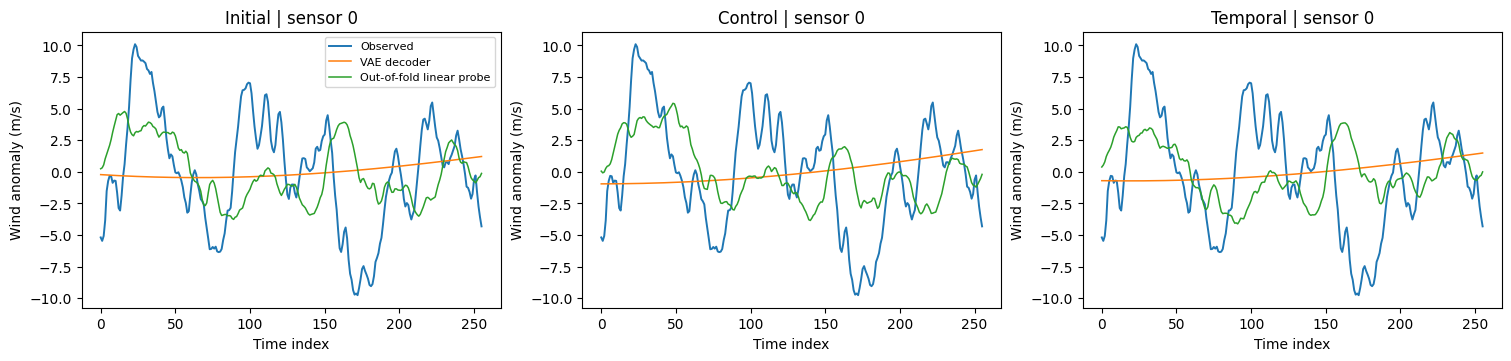


P15 — FROZEN-LATENT INFORMATION PROBE

 INITIAL
VAE decoder anomaly R2: -0.04876
Out-of-fold latent linear-probe R2: 0.236402
Out-of-fold probe band R2: {'low_1_6': 0.292912, 'mid_7_16': -0.179038, 'high_17_64': -0.207923}
Shuffled-label control R2: [-0.168223, -0.15195, -0.297265]
Across-field latent mean variance: 2.6889723525513914e-07

 CONTROL
VAE decoder anomaly R2: -0.045568
Out-of-fold latent linear-probe R2: 0.252032
Out-of-fold probe band R2: {'low_1_6': 0.314451, 'mid_7_16': -0.222036, 'high_17_64': -0.162027}
Shuffled-label control R2: [-0.109903, -0.20467, -0.193712]
Across-field latent mean variance: 5.323969157168182e-06

 TEMPORAL
VAE decoder anomaly R2: -0.038503
Out-of-fold latent linear-probe R2: 0.126311
Out-of-fold probe band R2: {'low_1_6': 0.161736, 'mid_7_16': -0.140733, 'high_17_64': -0.118812}
Shuffled-label control R2: [-0.066265, -0.081593, -0.16858]
Across-field latent mean variance: 9.893448458185103e-05

Saved: /content/drive/MyDrive/CLFM_Research_Result

In [33]:

# CELL P15 — Cross-fitted information probe on frozen VAE latents
# Add directly below P14.
# Inference only; no VAE retraining or test HDF5.

from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import uuid
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

P7 = BASE / (
    "controlled_vae_ablations/"
    "deterministic_replication_20261030T024339Z_c746ee"
)

P12 = BASE / (
    "fidelity_diagnostics/"
    "p12_latent_audit_20261030T031026Z_c31e91"
)

assert callable(globals().get("note")), "Run P1 first."
assert callable(globals().get("verify")), "Run P1 first."
assert (P12 / "diagnostic_fields.npz").is_file()
assert (P12 / "p12_latent_diagnostic.json").is_file()
assert (P7 / "environment_and_manifest.json").is_file()
assert torch.cuda.is_available()

RUN = BASE / "fidelity_diagnostics" / (
    "p15_frozen_latent_probe_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)

# ------------------------------------------------------------
# 1. Read existing observations and decoder reconstructions
# ------------------------------------------------------------

with np.load(
    P12 / "diagnostic_fields.npz",
    allow_pickle=False
) as archive:

    truth = np.array(
        archive["observed"],
        dtype=np.float64
    )

    baseline_decodings = {
        arm: np.array(
            archive[f"{arm}_posterior_mean"],
            dtype=np.float64
        )
        for arm in (
            "initial",
            "control",
            "temporal"
        )
    }

assert truth.shape == (32, 40, 256)

p12_metadata = json.loads(
    (P12 / "p12_latent_diagnostic.json").read_text()
)

p7_manifest = json.loads(
    (P7 / "environment_and_manifest.json").read_text()
)["manifest"]

indices = np.asarray(
    p12_metadata["probe_indices"],
    dtype=np.int64
)

assert np.array_equal(
    indices,
    np.asarray(
        p7_manifest["diagnostic_indices"],
        dtype=np.int64
    )
)

assert len(set(indices.tolist())) == 32

# ------------------------------------------------------------
# 2. Reconstruct the frozen encoders
# ------------------------------------------------------------

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]

import wind_vision_physicsnemo_day1 as w

source_hash = hashlib.sha256(
    Path(w.__file__).read_bytes()
).hexdigest()

assert source_hash == p7_manifest["source_sha256"], (
    "Source changed since P7. "
    "Stop before comparing."
)

ckpt, train_file = w.assert_environment()

(
    FVAE, _, _, _, _,
    DataCls, LossCls, _, _
) = w.prepare_reference_imports()

dataset, _ = w.make_loss_and_data(
    train_file,
    DataCls,
    LossCls
)

dataset.points = dataset.points.float()

assert dataset.sensor_idx.numel() == 40

verification = np.stack([
    dataset[int(i)][0].numpy()
    for i in indices
])

assert np.allclose(
    verification,
    truth,
    atol=1e-7,
    rtol=1e-6
), "P12 diagnostic data differ from this runtime."

trusted = FVAE.load_from_checkpoint(
    str(ckpt),
    map_location="cpu",
    weights_only=False
).float().eval()

kwargs = dict(
    num_sensors=40,
    latent_dim=128,
    grid_low=trusted.grid.low.detach().cpu().tolist(),
    grid_high=trusted.grid.high.detach().cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
)

initial_weights = {
    key: val.detach().clone()
    for key, val in trusted.state_dict().items()
}

del trusted

# ------------------------------------------------------------
# 3. Extract posterior means without retraining
# ------------------------------------------------------------

latents = {}

for arm in (
    "initial",
    "control",
    "temporal"
):

    model = w.PhysicsNeMoWindVAE(
        **kwargs
    ).to(
        "cuda",
        dtype=torch.float32
    ).eval()

    if arm == "initial":

        model.load_state_dict(
            initial_weights,
            strict=True
        )

    else:

        path = P7 / (
            f"repeat_A_{arm}_final.pt"
        )

        saved = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        assert saved["strict_deterministic"] is True
        assert saved["steps"] == 80

        model.load_state_dict(
            saved["state_dict"],
            strict=True
        )

    chunked = []

    with torch.inference_mode():

        for start in range(0, 32, 4):

            u = torch.from_numpy(
                verification[start:start+4]
            ).to("cuda")

            mu, logvar = model.encode(u)

            chunked.append(
                mu.cpu().numpy()
            )

    latents[arm] = np.concatenate(
        chunked,
        axis=0
    ).astype(np.float64)

    assert latents[arm].shape == (32, 128)
    assert np.isfinite(latents[arm]).all()

    del model
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# 4. Remove time means: focus strictly on dynamics
# ------------------------------------------------------------

Y = truth - truth.mean(
    axis=-1,
    keepdims=True
)

N, S, T = Y.shape
Y_flat = Y.reshape(N, -1)

folds = np.array_split(
    np.random.default_rng(
        20261030
    ).permutation(N),
    4
)

assert sorted(
    np.concatenate(folds).tolist()
) == list(range(N))

LAMBDA_GRID = (
    1e-6,
    1e-4,
    0.01,
    0.1,
    1.0,
    10.0,
    100.0
)

# ------------------------------------------------------------
# 5. Regularized linear latent-information probe
# ------------------------------------------------------------

def dynamic_r2(y_true, y_pred):

    denom = float(
        np.square(y_true).sum()
    )

    return (
        1.0
        - float(
            np.square(
                y_true - y_pred
            ).sum()
        )
        / max(denom, 1e-20)
    )


def ridge_predict(
    X_train,
    Y_train,
    X_test,
    alpha
):

    # Statistics are learned from training folds only.
    xmean = X_train.mean(axis=0)

    xscale = np.maximum(
        X_train.std(axis=0),
        1e-6
    )

    A = (X_train - xmean) / xscale
    B = (X_test - xmean) / xscale

    ymean = Y_train.mean(axis=0)

    K = (
        A @ A.T
    ) / A.shape[1]

    scale = max(
        float(
            np.trace(K) / len(K)
        ),
        1e-10
    )

    coefficient = np.linalg.solve(
        K + alpha * scale * np.eye(len(K)),
        Y_train - ymean
    )

    return (
        ymean
        + (
            (B @ A.T) / A.shape[1]
        ) @ coefficient
    )


def choose_alpha(
    X,
    outer_train,
    targets
):

    inner_folds = np.array_split(
        np.random.default_rng(
            1729
        ).permutation(outer_train),
        3
    )

    candidates = []

    for alpha in LAMBDA_GRID:

        actual = []
        predicted = []

        for held in inner_folds:

            fitted = np.setdiff1d(
                outer_train,
                held,
                assume_unique=True
            )

            estimate = ridge_predict(
                X[fitted],
                targets[fitted],
                X[held],
                alpha
            )

            actual.append(
                targets[held]
            )

            predicted.append(
                estimate
            )

        score = dynamic_r2(
            np.vstack(actual),
            np.vstack(predicted)
        )

        candidates.append(
            (
                float(score),
                float(alpha)
            )
        )

    # Deterministic tie break.
    return max(
        candidates,
        key=lambda item: (
            item[0],
            item[1]
        )
    )[1]

# ------------------------------------------------------------
# 6. Evaluate reconstruction and Fourier-band skill
# ------------------------------------------------------------

def assess(pred):

    actual = Y
    pred = pred.reshape(actual.shape)

    result = {
        "dynamic_r2":
            dynamic_r2(actual, pred),

        "per_field_dynamic_r2": [
            dynamic_r2(
                actual[i],
                pred[i]
            )
            for i in range(N)
        ],

        "temporal_variance_retained": float(
            np.var(
                pred,
                axis=-1
            ).mean()
            /
            np.var(
                actual,
                axis=-1
            ).mean()
        )
    }

    fft_true = np.fft.rfft(
        actual,
        axis=-1
    )

    fft_pred = np.fft.rfft(
        pred,
        axis=-1
    )

    result["band_r2"] = {}

    for name, start, stop in (
        ("low_1_6", 1, 7),
        ("mid_7_16", 7, 17),
        ("high_17_64", 17, 65)
    ):

        a = fft_true[..., start:stop]
        b = fft_pred[..., start:stop]

        result["band_r2"][name] = (
            1.0
            - float(
                (
                    np.abs(a-b) ** 2
                ).sum()
            )
            / max(
                float(
                    (
                        np.abs(a) ** 2
                    ).sum()
                ),
                1e-20
            )
        )

    return result

# ------------------------------------------------------------
# 7. Four-fold out-of-fold experiment
# ------------------------------------------------------------

results = {}

arrays = {
    "observed_anomalies":
        Y.astype(np.float32)
}

for arm in (
    "initial",
    "control",
    "temporal"
):

    X = latents[arm]

    pred = np.zeros_like(
        Y_flat
    )

    selections = []

    controls = [
        np.zeros_like(Y_flat)
        for _ in range(3)
    ]

    for fold_idx, held in enumerate(folds):

        train = np.setdiff1d(
            np.arange(N),
            held,
            assume_unique=True
        )

        alpha = choose_alpha(
            X,
            train,
            Y_flat
        )

        pred[held] = ridge_predict(
            X[train],
            Y_flat[train],
            X[held],
            alpha
        )

        selections.append({
            "fold": fold_idx,
            "test_indices": held.tolist(),
            "alpha": alpha
        })

        # Break latent/target correspondence.
        for null_idx in range(3):

            shuffled = np.random.default_rng(
                91000
                + fold_idx * 13
                + null_idx
            ).permutation(train)

            controls[null_idx][held] = ridge_predict(
                X[train],
                Y_flat[shuffled],
                X[held],
                alpha
            )

    pred = pred.reshape(
        Y.shape
    )

    decoder = (
        baseline_decodings[arm]
        - baseline_decodings[arm].mean(
            axis=-1,
            keepdims=True
        )
    )

    fitted_scores = assess(pred)

    shuffled_scores = [
        assess(v)["dynamic_r2"]
        for v in controls
    ]

    results[arm] = {
        "latent_mean_variance_across_fields":
            float(
                X.var(axis=0).mean()
            ),

        "cross_fitted_linear_probe":
            fitted_scores,

        "original_decoder":
            assess(decoder),

        "shuffled_label_control_dynamic_r2":
            shuffled_scores,

        "folds_and_selected_regularization":
            selections
    }

    arrays[
        f"{arm}_oof_ridge_anomalies"
    ] = pred.astype(np.float32)

    arrays[
        f"{arm}_decoder_anomalies"
    ] = decoder.astype(np.float32)

# ------------------------------------------------------------
# 8. Save scientific evidence
# ------------------------------------------------------------

report = {
    "experiment":
        "P15_cross_fitted_frozen_latent_information",

    "scope": (
        "32 examples from the original pretrained "
        "checkpoint's training population. "
        "Four-fold intervention holdout only. "
        "NOT independent generalization."
    ),

    "num_examples": 32,
    "outer_folds": 4,
    "inner_folds": 3,
    "fixed_seed": 20261030,

    "ridge_alpha_grid":
        list(LAMBDA_GRID),

    "source_sha256":
        source_hash,

    "p12_source": str(
        P12 / "diagnostic_fields.npz"
    ),

    "results": results,

    "interpretation": (
        "Positive out-of-fold anomaly R2 from "
        "frozen posterior means indicates "
        "recoverable input-dependent temporal "
        "information. Negative results do not "
        "prove the representation contains no "
        "information: a linear probe can miss "
        "nonlinear structure."
    ),

    "limitations": [
        "Small 32-field cohort",
        "Original pretrained VAE saw these fields",
        "No independent test HDF5",
        "Only a linear probe",
        "P13 oracle-fitted latents are not used here"
    ]
}

report_path = (
    RUN / "latent_information_probe.json"
)

report_path.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

np.savez_compressed(
    RUN / "probe_anomalies.npz",
    **arrays
)

# ------------------------------------------------------------
# 9. Compare observed, decoder, and probe time traces
# ------------------------------------------------------------

sensor = int(
    np.argmax(
        Y[0].var(axis=-1)
    )
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 3.5),
    constrained_layout=True
)

for ax, arm in zip(
    axes,
    (
        "initial",
        "control",
        "temporal"
    )
):

    ax.plot(
        Y[0, sensor] * 49,
        label="Observed",
        linewidth=1.4
    )

    ax.plot(
        arrays[
            f"{arm}_decoder_anomalies"
        ][0, sensor] * 49,
        label="VAE decoder",
        linewidth=1.1
    )

    ax.plot(
        arrays[
            f"{arm}_oof_ridge_anomalies"
        ][0, sensor] * 49,
        label="Out-of-fold linear probe",
        linewidth=1.1
    )

    ax.set_title(
        f"{arm.capitalize()} | sensor {sensor}"
    )

    ax.set_xlabel("Time index")
    ax.set_ylabel("Wind anomaly (m/s)")

axes[0].legend(fontsize=8)

fig_path = (
    RUN / "oof_latent_information_trace.png"
)

fig.savefig(
    fig_path,
    dpi=160
)

display(fig)
plt.close(fig)

# ------------------------------------------------------------
# 10. Print results
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("P15 — FROZEN-LATENT INFORMATION PROBE")
print("=" * 72)

for arm, item in results.items():

    probe = item[
        "cross_fitted_linear_probe"
    ]

    decoder = item[
        "original_decoder"
    ]

    print("\n", arm.upper())

    print(
        "VAE decoder anomaly R2:",
        round(
            decoder["dynamic_r2"],
            6
        )
    )

    print(
        "Out-of-fold latent linear-probe R2:",
        round(
            probe["dynamic_r2"],
            6
        )
    )

    print(
        "Out-of-fold probe band R2:",
        {
            key: round(value, 6)
            for key, value in probe[
                "band_r2"
            ].items()
        }
    )

    print(
        "Shuffled-label control R2:",
        [
            round(value, 6)
            for value in item[
                "shuffled_label_control_dynamic_r2"
            ]
        ]
    )

    print(
        "Across-field latent mean variance:",
        item[
            "latent_mean_variance_across_fields"
        ]
    )

# ------------------------------------------------------------
# 11. Formal lab journal
# ------------------------------------------------------------

note(
    title=(
        "P15: Frozen VAE latent-information "
        "cross-fitted probe"
    ),

    question=(
        "Do posterior means encode recoverable "
        "temporal fluctuations that the decoder "
        "currently fails to express?"
    ),

    methods=(
        "Frozen encoder, 32 original-training-"
        "population diagnostic fields, four-fold "
        "out-of-fold dual ridge, inner-fold "
        "regularization selection, and three "
        "shuffled-label controls per arm. "
        "All target time means removed."
    ),

    evidence=[
        str(report_path),
        str(RUN / "probe_anomalies.npz"),
        str(fig_path)
    ],

    findings={
        arm: {
            "probe_dynamic_r2":
                item[
                    "cross_fitted_linear_probe"
                ]["dynamic_r2"],

            "decoder_dynamic_r2":
                item[
                    "original_decoder"
                ]["dynamic_r2"],

            "shuffled_controls":
                item[
                    "shuffled_label_control_dynamic_r2"
                ]
        }
        for arm, item in results.items()
    },

    limitations=report["limitations"],

    decision=(
        "Use out-of-fold temporal-information "
        "recoverability to prioritize encoder "
        "information learning versus decoder "
        "spectral representation. Do not claim "
        "independent generalization."
    )
)

print("\nSaved:", report_path)

print(
    "Research archive verified:",
    verify()
)

print(
    "CELL P15 COMPLETE — "
    "No VAE retraining or independent-test access"
)


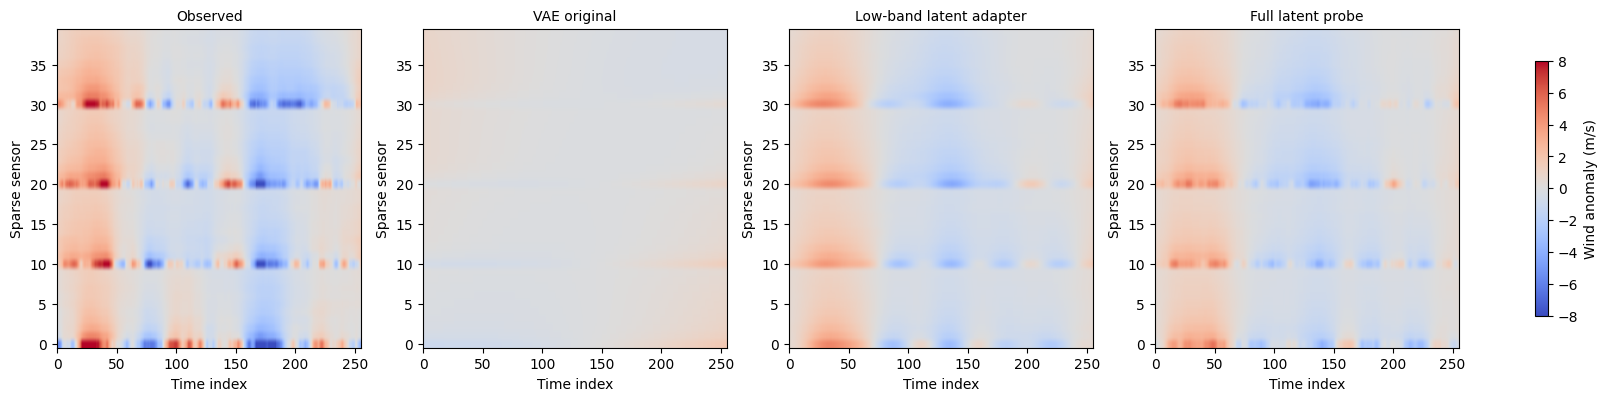

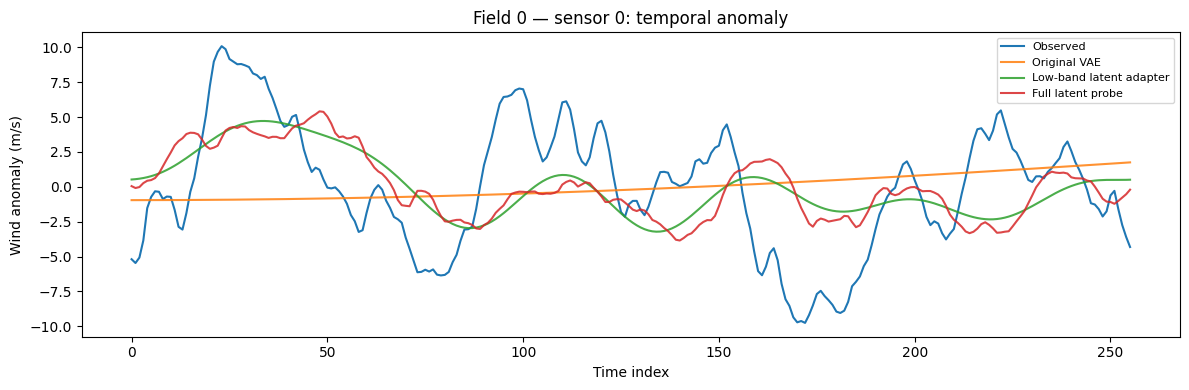


P16 — FREQUENCY-SELECTIVE DECODER PROTOTYPE
Reference temporal energy in bins 1..6: 0.881473

INITIAL
  vae_original: anomaly R2=-0.04876, full MSE=0.0041871, variance retained=4.217%, low R2=-0.05127, high R2=-0.05220
  vae_static_only: anomaly R2=+0.00000, full MSE=0.0041210, variance retained=0.000%, low R2=+0.00000, high R2=+0.00000
  low_frequency_latent_adapter: anomaly R2=+0.25819, full MSE=0.0037709, variance retained=34.304%, low R2=+0.29291, high R2=+0.00000
  low_adapter_plus_native_mid_high: anomaly R2=+0.25463, full MSE=0.0037757, variance retained=34.612%, low R2=+0.29291, high R2=-0.05220
  all_band_latent_probe: anomaly R2=+0.23640, full MSE=0.0038005, variance retained=36.659%, low R2=+0.29291, high R2=-0.20792

CONTROL
  vae_original: anomaly R2=-0.04557, full MSE=0.0036929, variance retained=3.174%, low R2=-0.04837, high R2=-0.03791
  vae_static_only: anomaly R2=+0.00000, full MSE=0.0036311, variance retained=0.000%, low R2=+0.00000, high R2=+0.00000
  low_frequency

In [34]:

# ================================================================
# CELL P16 — OUT-OF-FOLD FREQUENCY-SELECTIVE DECODER ADAPTER
#
# Add below P15.
# No GPU, no retraining, no independent-test HDF5.
# Evaluates a prototype using P15's saved OOF predictions.
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

P12 = BASE / (
    "fidelity_diagnostics/"
    "p12_latent_audit_20261030T031026Z_c31e91"
)

P15 = BASE / (
    "fidelity_diagnostics/"
    "p15_frozen_latent_probe_20261030T032855Z_cadb3b"
)

assert callable(globals().get("note")), (
    "Activate Cell P1 first."
)
assert callable(globals().get("verify")), (
    "Activate Cell P1 first."
)

source12 = P12 / "diagnostic_fields.npz"
source15 = P15 / "probe_anomalies.npz"
source_report15 = P15 / "latent_information_probe.json"

assert all(
    p.is_file()
    for p in (source12, source15, source_report15)
)

# ------------------------------------------------------------
# 1. Load existing P12 and P15 measurements
# ------------------------------------------------------------

with np.load(source12, allow_pickle=False) as inp:

    observed = np.asarray(
        inp["observed"], dtype=np.float64
    )

    vae = {
        arm: np.asarray(
            inp[f"{arm}_posterior_mean"],
            dtype=np.float64
        )
        for arm in ("initial", "control", "temporal")
    }

with np.load(source15, allow_pickle=False) as inp:

    anomaly_p15 = np.asarray(
        inp["observed_anomalies"],
        dtype=np.float64
    )

    probe = {
        arm: np.asarray(
            inp[f"{arm}_oof_ridge_anomalies"],
            dtype=np.float64
        )
        for arm in ("initial", "control", "temporal")
    }

report15 = json.loads(
    source_report15.read_text()
)

assert observed.shape == (32, 40, 256)

truth_anomaly = (
    observed
    - observed.mean(axis=-1, keepdims=True)
)

assert np.allclose(
    truth_anomaly,
    anomaly_p15,
    rtol=2e-6,
    atol=5e-7
)

assert np.isfinite(observed).all()

# Confirm all 32 fields were evaluated out of fold.
for arm in ("initial", "control", "temporal"):

    r = report15["results"][arm]

    assignments = [
        int(i)
        for fold in r[
            "folds_and_selected_regularization"
        ]
        for i in fold["test_indices"]
    ]

    assert sorted(assignments) == list(range(32)), (
        f"Invalid P15 fold coverage: {arm}"
    )

    assert vae[arm].shape == probe[arm].shape == (
        observed.shape
    )

    assert np.isfinite(probe[arm]).all()

    assert np.allclose(
        probe[arm].mean(axis=-1),
        0,
        atol=1e-6
    )

# ------------------------------------------------------------
# 2. Content-addressed, reproducible output directory
# ------------------------------------------------------------

def sha_file(path):

    h = hashlib.sha256()

    with path.open("rb") as f:

        for chunk in iter(
            lambda: f.read(8 * 1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


sources = {
    str(p.relative_to(BASE)): sha_file(p)
    for p in (
        source12,
        source15,
        source_report15
    )
}

run_id = hashlib.sha256(
    json.dumps(
        sources,
        sort_keys=True
    ).encode()
).hexdigest()[:16]

RUN = BASE / "fidelity_diagnostics" / (
    f"p16_frequency_adapter_{run_id}"
)

RUN.mkdir(parents=True, exist_ok=True)

REPORT = RUN / "frequency_adapter_audit.json"
FIGURE = RUN / "frequency_adapter_anomalies.png"
TRACE = RUN / "frequency_adapter_time_trace.png"

# ------------------------------------------------------------
# 3. Frequency-selective temporal anomaly projector
# ------------------------------------------------------------

def low_band(a):

    f = np.fft.rfft(
        a,
        axis=-1
    )

    selected = np.zeros_like(f)

    selected[..., 1:7] = f[..., 1:7]

    return np.fft.irfft(
        selected,
        n=a.shape[-1],
        axis=-1
    )


ref_energy = float(
    np.mean(truth_anomaly ** 2)
)

assert ref_energy > 0

ref_low = low_band(truth_anomaly)

low_energy_fraction = float(
    np.mean(ref_low ** 2) / ref_energy
)

BANDS = {
    "low_1_6": (1, 7),
    "mid_7_16": (7, 17),
    "high_17_64": (17, 65)
}

# ------------------------------------------------------------
# 4. Fair metrics on the same observed fields
# ------------------------------------------------------------

def score(pred):

    err = pred - observed

    static = err.mean(
        axis=-1,
        keepdims=True
    )

    dyn = err - static

    pred_anom = (
        pred
        - pred.mean(
            axis=-1,
            keepdims=True
        )
    )

    a = np.fft.rfft(
        truth_anomaly,
        axis=-1
    )

    b = np.fft.rfft(
        pred_anom,
        axis=-1
    )

    bands = {}

    for key, (lo, hi) in BANDS.items():

        aa = a[..., lo:hi]
        bb = b[..., lo:hi]

        den = max(
            float(
                (np.abs(aa) ** 2).sum()
            ),
            1e-20
        )

        bands[key] = {
            "r2": (
                1.0
                - float(
                    (
                        np.abs(bb-aa) ** 2
                    ).sum()
                ) / den
            ),
            "power_ratio": (
                float(
                    (np.abs(bb) ** 2).sum()
                ) / den
            )
        }

    total = float(
        np.mean(err ** 2)
    )

    static_mse = float(
        np.mean(static ** 2)
    )

    dynamic_mse = float(
        np.mean(dyn ** 2)
    )

    assert np.isclose(
        total,
        static_mse + dynamic_mse,
        atol=1e-12
    )

    return {
        "full_reconstruction_mse": total,
        "static_profile_mse": static_mse,
        "dynamic_mse": dynamic_mse,

        "anomaly_r2": (
            1.0 - dynamic_mse / ref_energy
        ),

        "anomaly_r2_per_field": [
            1.0
            - float(
                np.mean(dyn[i] ** 2)
            ) / max(
                float(
                    np.mean(
                        truth_anomaly[i] ** 2
                    )
                ),
                1e-20
            )
            for i in range(len(observed))
        ],

        "temporal_variance_retained": float(
            np.mean(pred_anom ** 2)
            / ref_energy
        ),

        "spectral_bands": bands
    }

# ------------------------------------------------------------
# 5. Compare original and frequency-adapted decoders
# ------------------------------------------------------------

results = {}
visuals = {}

for arm in ("initial", "control", "temporal"):

    baseline = vae[arm]

    # Only the VAE-predicted static profile is used.
    # No observed-field time mean enters the adapter.
    static = baseline.mean(
        axis=-1,
        keepdims=True
    )

    native_anom = baseline - static

    # P15 predictions are already out of fold.
    low = low_band(probe[arm])

    candidates = {
        "vae_original":
            baseline,

        "vae_static_only":
            np.broadcast_to(
                static,
                baseline.shape
            ),

        "low_frequency_latent_adapter":
            static + low,

        "low_adapter_plus_native_mid_high":
            static
            + low
            + (
                native_anom
                - low_band(native_anom)
            ),

        "all_band_latent_probe":
            static + probe[arm]
    }

    results[arm] = {
        key: score(pred)
        for key, pred in candidates.items()
    }

    visuals[arm] = candidates

    # Verify agreement with P15's stored OOF score.
    prior_r2 = report15["results"][arm][
        "cross_fitted_linear_probe"
    ]["dynamic_r2"]

    assert np.isclose(
        results[arm][
            "all_band_latent_probe"
        ]["anomaly_r2"],
        prior_r2,
        atol=1e-5,
        rtol=1e-5
    ), arm

    # Every candidate retains the VAE static profile.
    for pred in candidates.values():

        assert np.allclose(
            pred.mean(axis=-1),
            static[..., 0],
            atol=2e-7
        )

# ------------------------------------------------------------
# 6. Preserve full research evidence
# ------------------------------------------------------------

report = {
    "experiment":
        "P16_frequency_selective_latent_decoder_adapter",

    "created_utc":
        datetime.now(timezone.utc).isoformat(),

    "input_sha256": sources,

    "scope": (
        "32 original-checkpoint training-population "
        "examples. P15 probe predictions are out of "
        "fold only relative to the ridge fit, not "
        "independent VAE evaluation."
    ),

    "description": (
        "Construct predicted field from the original "
        "VAE time-mean plus out-of-fold ridge-predicted "
        "low-frequency anomalies, FFT bins 1 through 6."
    ),

    "fraction_reference_anomaly_energy_in_bins_1_6":
        low_energy_fraction,

    "results": results,

    "limitations": [
        "Encoder was previously trained on these fields",
        "Cross-fitting excludes examples from the probe fit only",
        "No physical-coherence assessment",
        "No unconditional latent-flow generation",
        "Adapter is a proof of concept, not yet a trainable generative decoder",
        "Only 32 examples; no independent generalization"
    ]
}

new_report = not REPORT.exists()

if new_report:

    REPORT.write_text(
        json.dumps(
            report,
            indent=2,
            allow_nan=False
        )
    )

# ------------------------------------------------------------
# 7. Shared-scale visualization
# ------------------------------------------------------------

control = visuals["control"]

show = [
    ("Observed", observed),
    ("VAE original", control["vae_original"]),
    (
        "Low-band latent adapter",
        control["low_frequency_latent_adapter"]
    ),
    (
        "Full latent probe",
        control["all_band_latent_probe"]
    )
]

limit = max(
    float(
        np.quantile(
            np.abs(
                truth_anomaly[0] * 49
            ),
            0.995
        )
    ),
    1e-6
)

fig, axs = plt.subplots(
    1, 4,
    figsize=(16, 3.9),
    constrained_layout=True
)

for ax, (label, fields) in zip(axs, show):

    anom = fields - fields.mean(
        axis=-1,
        keepdims=True
    )

    im = ax.imshow(
        anom[0] * 49,
        origin="lower",
        aspect="auto",
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit
    )

    ax.set_title(label, fontsize=10)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor")

fig.colorbar(
    im,
    ax=axs,
    label="Wind anomaly (m/s)",
    shrink=0.8
)

fig.savefig(FIGURE, dpi=160)

display(fig)
plt.close(fig)

# ------------------------------------------------------------
# 8. Aligned temporal trace at most variable sensor
# ------------------------------------------------------------

sensor = int(
    np.argmax(
        truth_anomaly[0].var(axis=-1)
    )
)

fig, ax = plt.subplots(
    figsize=(12, 4)
)

ax.plot(
    truth_anomaly[0, sensor] * 49,
    label="Observed",
    linewidth=1.5
)

for label, key in [
    ("Original VAE", "vae_original"),
    (
        "Low-band latent adapter",
        "low_frequency_latent_adapter"
    ),
    (
        "Full latent probe",
        "all_band_latent_probe"
    )
]:

    pred = control[key]

    ax.plot(
        (
            pred[0, sensor]
            - pred[0, sensor].mean()
        ) * 49,
        label=label,
        alpha=0.85
    )

ax.set_title(
    f"Field 0 — sensor {sensor}: temporal anomaly"
)

ax.set_xlabel("Time index")
ax.set_ylabel("Wind anomaly (m/s)")
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(TRACE, dpi=160)

display(fig)
plt.close(fig)

# ------------------------------------------------------------
# 9. Print scientific comparisons
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("P16 — FREQUENCY-SELECTIVE DECODER PROTOTYPE")
print("=" * 76)

print(
    "Reference temporal energy in bins 1..6:",
    round(low_energy_fraction, 6)
)

for arm, variants in results.items():

    print("\n" + arm.upper())

    for name, metric in variants.items():

        print(
            f"  {name}: "
            f"anomaly R2={metric['anomaly_r2']:+.5f}, "
            f"full MSE={metric['full_reconstruction_mse']:.7f}, "
            f"variance retained="
            f"{100*metric['temporal_variance_retained']:.3f}%, "
            f"low R2="
            f"{metric['spectral_bands']['low_1_6']['r2']:+.5f}, "
            f"high R2="
            f"{metric['spectral_bands']['high_17_64']['r2']:+.5f}"
        )

# ------------------------------------------------------------
# 10. Permanent documentation
# ------------------------------------------------------------

if new_report:

    note(
        title=(
            "P16: Out-of-fold frequency-selective "
            "decoder adapter"
        ),

        question=(
            "Can recoverable low-frequency information "
            "in frozen encoder latents improve "
            "reconstructed wind dynamics?"
        ),

        methods=(
            "Combine the VAE-predicted static profile "
            "with out-of-fold latent probe anomalies "
            "in FFT bins 1 through 6. Compare the "
            "original decoder, static-only control, "
            "frequency-selective adapter, and "
            "full-spectrum probe."
        ),

        evidence=[
            str(source12),
            str(source15),
            str(source_report15),
            str(REPORT),
            str(FIGURE),
            str(TRACE)
        ],

        findings={
            "reference_low_band_energy_fraction":
                low_energy_fraction,

            "control_anomaly_r2": {
                name: metric["anomaly_r2"]
                for name, metric
                in results["control"].items()
            }
        },

        limitations=report["limitations"],

        decision=(
            "Use the adapter as a mechanism "
            "demonstration only. Proceed toward "
            "a trainable frequency-aware decoder "
            "with an untouched evaluation holdout "
            "if phase-aligned reconstruction improves."
        )
    )

print("\nReport:", REPORT)
print("Archive verified:", verify())
print("CELL P16 COMPLETE — NO RETRAINING")


Dataset coordinate precision verified: torch.float32
Adapter split: 256 training, 32 validation, 32 evaluation
Evaluation disjoint from P7 continuation: True
Exact low-frequency basis: VERIFIED
Seed 20261030, step 100: validation coefficient MSE 0.602472
Seed 20261030, step 200: validation coefficient MSE 0.533396
Seed 20261030, step 300: validation coefficient MSE 0.504013
Seed 20261030, step 400: validation coefficient MSE 0.510269
Seed 20261030, step 500: validation coefficient MSE 0.513595
Seed 20261031, step 100: validation coefficient MSE 0.609620
Seed 20261031, step 200: validation coefficient MSE 0.534995
Seed 20261031, step 300: validation coefficient MSE 0.501089
Seed 20261031, step 400: validation coefficient MSE 0.518652
Seed 20261031, step 500: validation coefficient MSE 0.520583


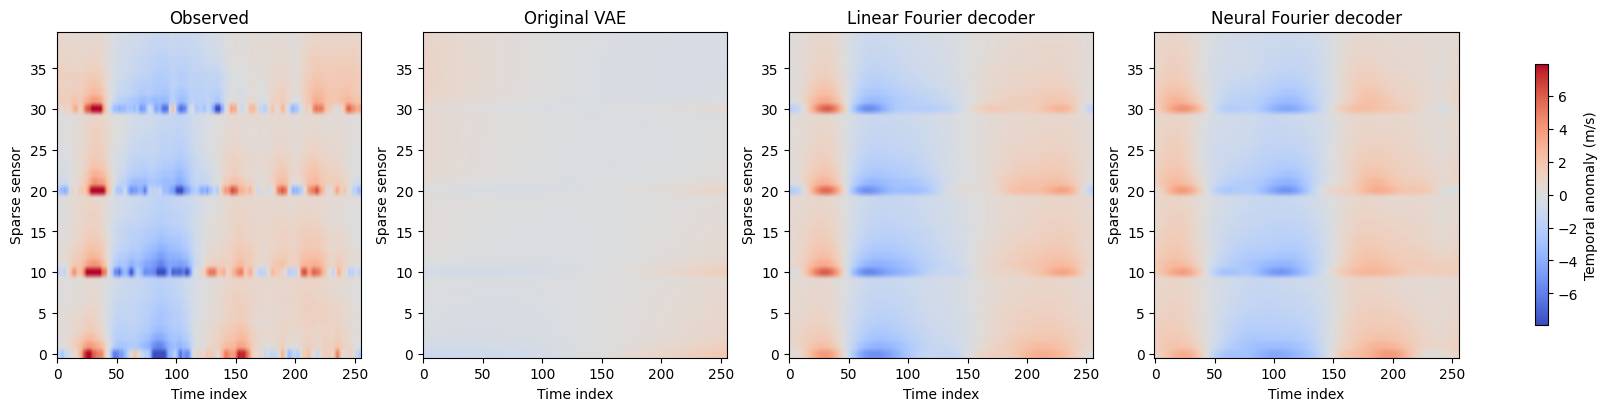


P17 — TRAINABLE SPECTRAL DECODER RESULTS
Training / validation / evaluation: 256 32 32
Evaluation disjoint from P7 continuation: True

Original VAE
  Full MSE: 0.00419854
  Temporal anomaly R2: -0.05069
  Low-frequency R2: -0.05499
  High-frequency R2: -0.03954

Static-only baseline
  Full MSE: 0.00413070
  Temporal anomaly R2: +0.00000
  Low-frequency R2: +0.00000
  High-frequency R2: +0.00000

Linear spectral head
  Full MSE: 0.00342023
  Temporal anomaly R2: +0.53080
  Low-frequency R2: +0.60225
  High-frequency R2: -0.00000

Neural spectral head
  Full MSE: 0.00358341
  Temporal anomaly R2: +0.40888
  Low-frequency R2: +0.46392
  High-frequency R2: -0.00000

Selected neural seed: 20261030
Selected training step: 350
Descriptive 95% bootstrap MSE improvement interval: [0.0005356628028742773, 0.0006866944389859221]

Evidence: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p17_spectral_head_20261102T152928Z_3bc800
Verified archive: 649
CELL P17 COM

In [35]:

# CELL P17 — Trainable frequency-aware spectral decoder
# Add below P16. Do not rerun earlier experiments.
# VAE frozen; only new adapter heads are trained.
# No independent-test HDF5 access or NASA source edits.

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import uuid
import copy
import sys

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

P7 = BASE / (
    "controlled_vae_ablations/"
    "deterministic_replication_20261030T024339Z_c746ee"
)

assert callable(globals().get("note")), "Run P1 first."
assert callable(globals().get("verify")), "Run P1 first."
assert (P7 / "environment_and_manifest.json").is_file()
assert torch.cuda.is_available(), "NVIDIA GPU required."

RUN = BASE / "fidelity_diagnostics" / (
    "p17_spectral_head_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)

manifest = json.loads(
    (P7 / "environment_and_manifest.json").read_text()
)["manifest"]

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]

import wind_vision_physicsnemo_day1 as w


def sha(path):
    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()


assert sha(w.__file__) == manifest["source_sha256"], (
    "Patched source changed. Stop for source audit."
)

ckpt, train_path = w.assert_environment()

(
    _, _, _, _, _,
    DataCls, LossCls, _, _
) = w.prepare_reference_imports()

dataset, _ = w.make_loss_and_data(
    train_path,
    DataCls,
    LossCls
)

dataset.points = dataset.points.float()
assert dataset.sensor_idx.numel() == 40

# -----------------------------------------------------------
# 1. Create separate adapter-training and evaluation splits.
#
# All examples belong to the ORIGINAL VAE training
# population. The adapter evaluation is therefore NOT
# an independent evaluation of the pretrained VAE.
# -----------------------------------------------------------

n = len(dataset)

previous_diagnostic = set(
    map(int, manifest["diagnostic_indices"])
)

previous_continuation = set(
    map(int, manifest["continuation_train_indices"])
)

pool = np.array(
    sorted(set(range(n)) - previous_diagnostic),
    dtype=int
)

rng = np.random.default_rng(20262737)
rng.shuffle(pool)

# Prefer evaluation examples not used in P7 continuation.
fresh = np.array([
    i for i in pool
    if int(i) not in previous_continuation
], dtype=int)

if len(fresh) >= 32:
    evaluation = fresh[:32]
    eval_unseen_by_p7 = True
else:
    evaluation = pool[:32]
    eval_unseen_by_p7 = False

evaluation_set = set(evaluation.tolist())

remaining = np.array([
    i for i in pool
    if int(i) not in evaluation_set
], dtype=int)

assert len(remaining) >= 96

validation = remaining[:32]

training = remaining[
    32:32 + min(256, len(remaining) - 32)
]

assert len(training) >= 64

assert not (
    set(training) & set(validation)
    or set(training) & set(evaluation)
    or set(validation) & set(evaluation)
)

print(
    "Adapter split:",
    len(training), "training,",
    len(validation), "validation,",
    len(evaluation), "evaluation"
)

print(
    "Evaluation disjoint from P7 continuation:",
    eval_unseen_by_p7
)

# -----------------------------------------------------------
# 2. Load the previously validated control VAE, frozen.
# -----------------------------------------------------------

saved = torch.load(
    P7 / "repeat_A_control_final.pt",
    map_location="cpu",
    weights_only=True
)

assert saved["strict_deterministic"]
assert saved["steps"] == 80

model_kwargs = dict(
    num_sensors=40,
    latent_dim=128,
    grid_low=dataset.grid.low.cpu().tolist(),
    grid_high=dataset.grid.high.cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
)

model = w.PhysicsNeMoWindVAE(
    **model_kwargs
).cuda().float().eval()

model.load_state_dict(
    saved["state_dict"],
    strict=True
)

model.requires_grad_(False)

coords = dataset.points.cuda()[None]


def extract(ids):

    latents = []
    truth = []
    static_profiles = []

    with torch.inference_mode():

        for start in range(0, len(ids), 8):

            indices = ids[start:start+8]

            u = torch.stack([
                dataset[int(i)][0]
                for i in indices
            ]).float().cuda()

            mu, _ = model.encode(u)

            prediction = model.decode(
                mu,
                coords.expand(len(indices), -1, -1)
            ).reshape_as(u)

            latents.append(mu.cpu().numpy())
            truth.append(u.cpu().numpy())

            static_profiles.append(
                prediction.mean(
                    dim=-1,
                    keepdim=True
                ).cpu().numpy()
            )

    return (
        np.concatenate(latents).astype(np.float64),
        np.concatenate(truth).astype(np.float64),
        np.concatenate(static_profiles).astype(np.float64)
    )


Ztr, Utr, Ptr = extract(training)
Zva, Uva, Pva = extract(validation)
Zte, Ute, Pte = extract(evaluation)

del model
torch.cuda.empty_cache()

# -----------------------------------------------------------
# 3. Exact sine/cosine basis for FFT bins 1 through 6.
#
# The head predicts 12 Fourier coefficients per sensor:
# six cosine coefficients and six sine coefficients.
# -----------------------------------------------------------

T = 256
time_index = np.arange(T)
frequency_bins = np.arange(1, 7)

basis = np.concatenate(
    [
        np.cos(
            2 * np.pi * k * time_index / T
        )[None, :]
        for k in frequency_bins
    ]
    +
    [
        np.sin(
            2 * np.pi * k * time_index / T
        )[None, :]
        for k in frequency_bins
    ],
    axis=0
).astype(np.float64)

assert basis.shape == (12, 256)


def targets(u):

    anomaly = u - u.mean(
        axis=-1,
        keepdims=True
    )

    return (2.0 / T) * np.einsum(
        "nst,kt->nsk",
        anomaly,
        basis,
        optimize=True
    )


def synth(coefficients):

    return np.einsum(
        "nsk,kt->nst",
        coefficients,
        basis,
        optimize=True
    )


C_tr = targets(Utr)
C_va = targets(Uva)

assert C_tr.shape == (len(training), 40, 12)

# Verify equivalence to direct FFT low-band projection.
probe = Utr[:1] - Utr[:1].mean(
    axis=-1,
    keepdims=True
)

spectrum = np.fft.rfft(
    probe,
    axis=-1
)

selected = np.zeros_like(spectrum)
selected[..., 1:7] = spectrum[..., 1:7]

assert np.max(np.abs(
    synth(C_tr[:1])
    - np.fft.irfft(
        selected,
        n=T,
        axis=-1
    )
)) < 1e-10

print("Exact low-frequency basis: VERIFIED")

# -----------------------------------------------------------
# 4. Normalize latent features using TRAINING data only.
# -----------------------------------------------------------

feature_mean = Ztr.mean(axis=0)

feature_scale = np.maximum(
    Ztr.std(axis=0),
    1e-5
)

Xtr = (Ztr - feature_mean) / feature_scale
Xva = (Zva - feature_mean) / feature_scale
Xte = (Zte - feature_mean) / feature_scale

coefficient_scale = max(
    float(np.sqrt(np.mean(C_tr ** 2))),
    1e-6
)

Ytr = (
    C_tr.reshape(len(training), -1)
    / coefficient_scale
)

Yva = (
    C_va.reshape(len(validation), -1)
    / coefficient_scale
)

# -----------------------------------------------------------
# 5. Define matched reconstruction and spectral metrics.
# -----------------------------------------------------------

def score(u, profile, predicted_coefficients):

    predicted = (
        profile
        + synth(predicted_coefficients)
    )

    true_anomaly = (
        u - u.mean(
            axis=-1,
            keepdims=True
        )
    )

    predicted_anomaly = (
        predicted - predicted.mean(
            axis=-1,
            keepdims=True
        )
    )

    true_energy = float(
        np.square(true_anomaly).sum()
    )

    fft_true = np.fft.rfft(
        true_anomaly,
        axis=-1
    )

    fft_pred = np.fft.rfft(
        predicted_anomaly,
        axis=-1
    )

    def band_r2(lo, hi):

        a = fft_true[..., lo:hi]
        b = fft_pred[..., lo:hi]

        return (
            1.0
            - float(
                np.square(np.abs(a-b)).sum()
            )
            / max(
                float(
                    np.square(np.abs(a)).sum()
                ),
                1e-20
            )
        )

    return {
        "full_mse": float(
            np.mean(np.square(u-predicted))
        ),

        "anomaly_r2": (
            1.0
            - float(
                np.square(
                    true_anomaly-predicted_anomaly
                ).sum()
            ) / max(true_energy, 1e-20)
        ),

        "low_band_r2": band_r2(1, 7),
        "mid_band_r2": band_r2(7, 17),
        "high_band_r2": band_r2(17, 65),

        "temporal_variance_ratio": float(
            np.mean(predicted_anomaly ** 2)
            / max(
                np.mean(true_anomaly ** 2),
                1e-20
            )
        ),

        "per_field_anomaly_r2": [
            1.0
            - float(
                np.square(
                    true_anomaly[i]
                    - predicted_anomaly[i]
                ).sum()
            )
            / max(
                float(
                    np.square(
                        true_anomaly[i]
                    ).sum()
                ),
                1e-20
            )
            for i in range(len(u))
        ]
    }

# -----------------------------------------------------------
# 6. Linear spectral decoder baseline: ridge regression.
# Select regularization using validation data ONLY.
# -----------------------------------------------------------

A = np.column_stack([
    np.ones(len(Xtr)),
    Xtr
])

B = np.column_stack([
    np.ones(len(Xva)),
    Xva
])

E = np.column_stack([
    np.ones(len(Xte)),
    Xte
])

penalty = np.eye(A.shape[1])
penalty[0, 0] = 0

ridge_trials = []

for alpha in (
    0.01, 0.1, 1.0,
    10.0, 100.0, 1000.0
):

    weights = np.linalg.solve(
        A.T @ A + alpha * penalty,
        A.T @ Ytr
    )

    validation_coefficients = (
        (B @ weights).reshape(-1, 40, 12)
        * coefficient_scale
    )

    validation_metric = score(
        Uva,
        Pva,
        validation_coefficients
    )

    ridge_trials.append({
        "alpha": alpha,
        "validation_low_band_r2":
            validation_metric["low_band_r2"],
        "weights": weights
    })

chosen_ridge = max(
    ridge_trials,
    key=lambda r: (
        r["validation_low_band_r2"],
        r["alpha"]
    )
)

linear_coefficients = (
    (E @ chosen_ridge["weights"])
    .reshape(-1, 40, 12)
    * coefficient_scale
)

ridge_metric = score(
    Ute,
    Pte,
    linear_coefficients
)

# -----------------------------------------------------------
# 7. Nonlinear trainable spectral decoder head.
#
# Train ONLY this head, on CPU for reproducibility.
# Both seeds are evaluated and retained.
# -----------------------------------------------------------

class SpectralHead(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(128, 192),
            nn.GELU(),
            nn.Linear(192, 192),
            nn.GELU(),
            nn.Linear(192, 480)
        )

        nn.init.zeros_(
            self.net[-1].weight
        )

        nn.init.zeros_(
            self.net[-1].bias
        )

    def forward(self, x):

        return self.net(x).reshape(
            -1, 40, 12
        )


xtrain = torch.from_numpy(
    Xtr.astype("float32")
)

ytrain = torch.from_numpy(
    Ytr.astype("float32")
).reshape(-1, 40, 12)

xval = torch.from_numpy(
    Xva.astype("float32")
)

yval = torch.from_numpy(
    Yva.astype("float32")
).reshape(-1, 40, 12)

xtest = torch.from_numpy(
    Xte.astype("float32")
)

history = []
candidates = []

torch.set_num_threads(
    min(4, torch.get_num_threads())
)

for seed in (20261030, 20261031):

    torch.manual_seed(seed)

    head = SpectralHead().cpu()

    optimizer = torch.optim.AdamW(
        head.parameters(),
        lr=8e-4,
        weight_decay=1e-3
    )

    generator = torch.Generator(
        device="cpu"
    ).manual_seed(seed+17)

    best = float("inf")
    best_state = None
    best_step = 0
    stale = 0

    for step in range(1, 601):

        indices = torch.randint(
            len(xtrain),
            (min(32, len(xtrain)),),
            generator=generator
        )

        head.train()
        optimizer.zero_grad(set_to_none=True)

        loss = torch.mean(
            (
                head(xtrain[indices])
                - ytrain[indices]
            ) ** 2
        )

        loss.backward()
        optimizer.step()

        if step % 25 == 0 or step == 1:

            head.eval()

            with torch.inference_mode():

                validation_loss = float(
                    torch.mean(
                        (head(xval)-yval) ** 2
                    )
                )

            history.append({
                "seed": seed,
                "step": step,
                "train_coefficient_mse":
                    float(loss.detach()),
                "validation_coefficient_mse":
                    validation_loss
            })

            if validation_loss < best - 1e-5:

                best = validation_loss
                best_state = copy.deepcopy(
                    head.state_dict()
                )
                best_step = step
                stale = 0

            else:
                stale += 1

            if step % 100 == 0:

                print(
                    f"Seed {seed}, step {step}: "
                    f"validation coefficient MSE "
                    f"{validation_loss:.6f}",
                    flush=True
                )

            if stale >= 8:
                break

    head.load_state_dict(best_state)
    head.eval()

    with torch.inference_mode():

        val_coeff = (
            head(xval).numpy()
            * coefficient_scale
        )

        test_coeff = (
            head(xtest).numpy()
            * coefficient_scale
        )

    validation_metric = score(
        Uva, Pva, val_coeff
    )

    evaluation_metric = score(
        Ute, Pte, test_coeff
    )

    checkpoint = RUN / (
        f"spectral_head_seed{seed}.pt"
    )

    torch.save({
        "state_dict": head.state_dict(),
        "feature_mean":
            torch.tensor(feature_mean),
        "feature_scale":
            torch.tensor(feature_scale),
        "coefficient_scale":
            coefficient_scale,
        "basis": torch.tensor(basis),
        "seed": seed,
        "selected_step": best_step
    }, checkpoint)

    candidates.append({
        "seed": seed,
        "selected_step": best_step,
        "validation": validation_metric,
        "evaluation": evaluation_metric,
        "checkpoint": str(checkpoint),
        "test_coefficients": test_coeff
    })

# Choose by validation score, never evaluation score.
winner = max(
    candidates,
    key=lambda c: (
        c["validation"]["low_band_r2"],
        -c["seed"]
    )
)

# -----------------------------------------------------------
# 8. Restore native VAE decoder predictions on the exact
# same evaluation fields for a fair comparison.
# -----------------------------------------------------------

native_model = w.PhysicsNeMoWindVAE(
    **model_kwargs
).cuda().float().eval()

native_model.load_state_dict(
    saved["state_dict"],
    strict=True
)

chunks = []

with torch.inference_mode():

    for i in range(0, len(Zte), 8):

        z = torch.from_numpy(
            Zte[i:i+8].astype("float32")
        ).cuda()

        points = dataset.points.cuda()[None].expand(
            len(z), -1, -1
        )

        chunks.append(
            native_model.decode(
                z, points
            ).reshape(
                -1, 40, 256
            ).cpu().numpy()
        )

original_native = np.concatenate(
    chunks
).astype(np.float64)

del native_model
torch.cuda.empty_cache()

zero = np.zeros(
    (len(evaluation), 40, 12)
)


def full_score(u, prediction):

    result = score(
        u,
        prediction.mean(
            axis=-1,
            keepdims=True
        ),
        zero
    )

    actual_anomaly = (
        u - u.mean(
            axis=-1,
            keepdims=True
        )
    )

    predicted_anomaly = (
        prediction - prediction.mean(
            axis=-1,
            keepdims=True
        )
    )

    result["full_mse"] = float(
        np.mean(
            (u-prediction) ** 2
        )
    )

    result["anomaly_r2"] = (
        1.0
        - float(
            np.square(
                actual_anomaly-predicted_anomaly
            ).sum()
        )
        / max(
            float(
                np.square(actual_anomaly).sum()
            ),
            1e-20
        )
    )

    fft_true = np.fft.rfft(
        actual_anomaly,
        axis=-1
    )

    fft_pred = np.fft.rfft(
        predicted_anomaly,
        axis=-1
    )

    for key, lo, hi in (
        ("low_band_r2", 1, 7),
        ("mid_band_r2", 7, 17),
        ("high_band_r2", 17, 65)
    ):

        actual = fft_true[..., lo:hi]
        estimate = fft_pred[..., lo:hi]

        result[key] = (
            1.0
            - float(
                np.square(
                    np.abs(actual-estimate)
                ).sum()
            )
            / max(
                float(
                    np.square(np.abs(actual)).sum()
                ),
                1e-20
            )
        )

    return result


native_metric = full_score(
    Ute, original_native
)

static_metric = score(
    Ute, Pte, zero
)

# -----------------------------------------------------------
# 9. Descriptive paired bootstrap for MSE improvement.
# This is not an independent generalization CI.
# -----------------------------------------------------------

native_field_mse = np.square(
    Ute-original_native
).mean(axis=(1, 2))

selected_prediction = (
    Pte + synth(winner["test_coefficients"])
)

selected_field_mse = np.square(
    Ute-selected_prediction
).mean(axis=(1, 2))

bootstrap_rng = np.random.default_rng(170730)

bootstrap = []

for _ in range(2000):

    sampled = bootstrap_rng.integers(
        0,
        len(evaluation),
        len(evaluation)
    )

    bootstrap.append(float(
        (
            native_field_mse[sampled]
            - selected_field_mse[sampled]
        ).mean()
    ))

bootstrap_ci = np.quantile(
    bootstrap,
    [0.025, 0.975]
).tolist()

# -----------------------------------------------------------
# 10. Save experiment, checkpoints, all seeds and outcomes.
# -----------------------------------------------------------

report = {
    "experiment":
        "P17_trainable_spectral_residual_decoder",

    "created_utc":
        datetime.now(timezone.utc).isoformat(),

    "status": "completed",

    "source_sha256": sha(w.__file__),

    "frozen_checkpoint":
        str(P7 / "repeat_A_control_final.pt"),

    "dataset_population_count": n,

    "split": {
        "training_indices": training.tolist(),
        "validation_indices": validation.tolist(),
        "evaluation_indices": evaluation.tolist(),
        "excluded_prior_diagnostic_indices":
            sorted(previous_diagnostic),
        "evaluation_excludes_P7_continuation":
            eval_unseen_by_p7
    },

    "configuration": {
        "frequency_bins": [1, 2, 3, 4, 5, 6],
        "time_samples": T,
        "head_max_steps": 600,
        "head_seeds": [20261030, 20261031],
        "learning_rate": 8e-4,
        "weight_decay": 1e-3,
        "selection": "validation only"
    },

    "native_vae_evaluation": native_metric,
    "static_only_evaluation": static_metric,

    "ridge": {
        "chosen_alpha": chosen_ridge["alpha"],
        "validation_low_band_r2":
            chosen_ridge["validation_low_band_r2"],
        "evaluation": ridge_metric
    },

    "nonlinear_heads": [
        {
            "seed": c["seed"],
            "selected_step": c["selected_step"],
            "validation": c["validation"],
            "evaluation": c["evaluation"],
            "checkpoint": c["checkpoint"]
        }
        for c in candidates
    ],

    "validation_selected_head_seed":
        winner["seed"],

    "descriptive_paired_MSE_improvement_CI95":
        bootstrap_ci,

    "limitations": [
        "The original VAE checkpoint already saw "
        "the training-data population.",
        "Adapter evaluation is disjoint from adapter "
        "training and validation, but is not an "
        "independent VAE generalization test.",
        "Earlier model decisions were informed by "
        "other training-population diagnostics.",
        "This is conditional reconstruction, not "
        "unconditional generation.",
        "Only FFT bins 1 through 6 are predicted. "
        "High-frequency reconstruction is not solved."
    ]
}

report_path = RUN / "result.json"

report_path.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

(RUN / "training_history.json").write_text(
    json.dumps(
        history,
        indent=2,
        allow_nan=False
    )
)

np.savez_compressed(
    RUN / "evaluation_fields.npz",
    observed=Ute.astype("float32"),
    native_vae=original_native.astype("float32"),
    ridge=(
        Pte+synth(linear_coefficients)
    ).astype("float32"),
    spectral_head=(
        selected_prediction
    ).astype("float32")
)

# -----------------------------------------------------------
# 11. Shared-scale figure on adapter-held-out examples.
# -----------------------------------------------------------

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4),
    constrained_layout=True
)

views = [
    ("Observed", Ute),
    ("Original VAE", original_native),
    (
        "Linear Fourier decoder",
        Pte+synth(linear_coefficients)
    ),
    (
        "Neural Fourier decoder",
        selected_prediction
    )
]

truth_anomaly = (
    Ute[0]
    - Ute[0].mean(
        axis=-1,
        keepdims=True
    )
)

limit = max(
    float(
        np.quantile(
            np.abs(truth_anomaly*49),
            0.995
        )
    ),
    1e-5
)

for ax, (title, fields) in zip(
    axes, views
):

    anomaly = (
        fields[0]
        - fields[0].mean(
            axis=-1,
            keepdims=True
        )
    )

    image = ax.imshow(
        49*anomaly,
        origin="lower",
        aspect="auto",
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit
    )

    ax.set_title(title)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor")

fig.colorbar(
    image,
    ax=axes,
    label="Temporal anomaly (m/s)",
    shrink=0.8
)

fig.savefig(
    RUN / "comparison.png",
    dpi=155
)

display(fig)
plt.close(fig)

# -----------------------------------------------------------
# 12. Print and permanently document scientific results.
# -----------------------------------------------------------

print("\n" + "=" * 70)
print("P17 — TRAINABLE SPECTRAL DECODER RESULTS")
print("=" * 70)

print(
    "Training / validation / evaluation:",
    len(training),
    len(validation),
    len(evaluation)
)

print(
    "Evaluation disjoint from P7 continuation:",
    eval_unseen_by_p7
)

for label, result in (
    ("Original VAE", native_metric),
    ("Static-only baseline", static_metric),
    ("Linear spectral head", ridge_metric),
    ("Neural spectral head", winner["evaluation"])
):

    print(
        f"\n{label}"
        f"\n  Full MSE: {result['full_mse']:.8f}"
        f"\n  Temporal anomaly R2: "
        f"{result['anomaly_r2']:+.5f}"
        f"\n  Low-frequency R2: "
        f"{result['low_band_r2']:+.5f}"
        f"\n  High-frequency R2: "
        f"{result['high_band_r2']:+.5f}"
    )

print(
    "\nSelected neural seed:",
    winner["seed"]
)

print(
    "Selected training step:",
    winner["selected_step"]
)

print(
    "Descriptive 95% bootstrap MSE improvement interval:",
    bootstrap_ci
)

note(
    title=(
        "P17: Trainable frozen-encoder "
        "frequency-aware decoder"
    ),

    question=(
        "Can a learned low-frequency decoder improve "
        "reconstruction on examples held out from "
        "adapter fitting and selection?"
    ),

    methods=(
        "Frozen P7 control VAE, disjoint adapter "
        "training/validation/evaluation split, "
        "linear ridge Fourier baseline and two "
        "CPU-trained nonlinear Fourier heads. "
        "Validation-only model selection."
    ),

    evidence=[
        str(report_path),
        str(RUN / "training_history.json"),
        str(RUN / "evaluation_fields.npz"),
        str(RUN / "comparison.png")
    ],

    findings={
        "native": native_metric,
        "ridge": ridge_metric,
        "selected_neural_head":
            winner["evaluation"],
        "descriptive_MSE_delta_CI95":
            bootstrap_ci
    },

    limitations=report["limitations"],

    decision=(
        "Retain a trainable frequency-aware decoder "
        "only if adapter-held-out reconstruction "
        "improves. Independent VAE generalization "
        "and unconditional generation remain unproven."
    )
)

print("\nEvidence:", RUN)
print("Verified archive:", verify())
print("CELL P17 COMPLETE")


In [36]:

# ============================================================
# CELL P18 — RECOVER AND PACKAGE THE WINNING FOURIER HEAD
#
# Add directly below P17.
#
# Reconstruct the exact P17 ridge-regression adapter.
# Verify predictions against P17's archived evaluation.
# Save standalone NumPy inference code and model weights.
# Evaluate per-field improvement and the correct linear
# model's paired bootstrap interval.
#
# No VAE training. No test HDF5. No NASA source edits.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys
import importlib.util

import numpy as np
import torch

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

P7 = BASE / (
    "controlled_vae_ablations/"
    "deterministic_replication_20261030T024339Z_c746ee"
)

P17 = BASE / (
    "fidelity_diagnostics/"
    "p17_spectral_head_20261030T034044Z_1464ad"
)

assert callable(globals().get("note")), "Run P1 first."
assert callable(globals().get("verify")), "Run P1 first."

assert (P17 / "result.json").is_file()
assert (P17 / "evaluation_fields.npz").is_file()
assert torch.cuda.is_available()

previous = json.loads(
    (P17 / "result.json").read_text()
)

assert previous["status"] == "completed"

split = previous["split"]

train_ids = np.asarray(
    split["training_indices"],
    dtype=np.int64
)

val_ids = np.asarray(
    split["validation_indices"],
    dtype=np.int64
)

eval_ids = np.asarray(
    split["evaluation_indices"],
    dtype=np.int64
)

assert len(train_ids) == 256
assert len(val_ids) == 32
assert len(eval_ids) == 32

assert len(set(
    train_ids.tolist()
    + val_ids.tolist()
    + eval_ids.tolist()
)) == 320

alpha = float(
    previous["ridge"]["chosen_alpha"]
)

assert alpha > 0

# ------------------------------------------------------------
# 1. Restore the exact frozen control VAE from P17
# ------------------------------------------------------------

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]

import wind_vision_physicsnemo_day1 as w

source_sha = hashlib.sha256(
    Path(w.__file__).read_bytes()
).hexdigest()

assert source_sha == previous["source_sha256"], (
    "PhysicsNeMo source changed since P17."
)

ckpt, train_path = w.assert_environment()

(
    _, _, _, _, _,
    DataCls, LossCls, _, _
) = w.prepare_reference_imports()

dataset, _ = w.make_loss_and_data(
    train_path,
    DataCls,
    LossCls
)

dataset.points = dataset.points.float()

assert dataset.sensor_idx.numel() == 40

saved_model = torch.load(
    P7 / "repeat_A_control_final.pt",
    map_location="cpu",
    weights_only=True
)

assert saved_model["strict_deterministic"] is True
assert saved_model["steps"] == 80

model = w.PhysicsNeMoWindVAE(
    num_sensors=40,
    latent_dim=128,
    grid_low=dataset.grid.low.cpu().tolist(),
    grid_high=dataset.grid.high.cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
).cuda().float().eval()

model.load_state_dict(
    saved_model["state_dict"],
    strict=True
)

model.requires_grad_(False)

coords = dataset.points.cuda()[None]


def extract(ids, keep_native=False):

    latent_parts = []
    observed_parts = []
    static_parts = []
    native_parts = []

    with torch.inference_mode():

        for start in range(0, len(ids), 8):

            indices = ids[start:start+8]

            u = torch.stack([
                dataset[int(i)][0]
                for i in indices
            ]).float().cuda()

            mu, _ = model.encode(u)

            pred = model.decode(
                mu,
                coords.expand(len(u), -1, -1)
            ).reshape_as(u)

            latent_parts.append(
                mu.cpu().numpy()
            )

            observed_parts.append(
                u.cpu().numpy()
            )

            static_parts.append(
                pred.mean(
                    dim=-1,
                    keepdim=True
                ).cpu().numpy()
            )

            if keep_native:
                native_parts.append(
                    pred.cpu().numpy()
                )

    return (
        np.concatenate(
            latent_parts
        ).astype("float64"),

        np.concatenate(
            observed_parts
        ).astype("float64"),

        np.concatenate(
            static_parts
        ).astype("float64"),

        (
            np.concatenate(
                native_parts
            ).astype("float64")
            if keep_native else None
        )
    )


Ztr, Utr, Ptr, _ = extract(train_ids)
Zva, Uva, Pva, _ = extract(val_ids)

Zev, Uev, Pev, native = extract(
    eval_ids,
    keep_native=True
)

del model
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 2. Rebuild P17's exact six-frequency Fourier basis
# ------------------------------------------------------------

T = 256

k = np.arange(1, 7)
t = np.arange(T)

basis = np.concatenate(
    [
        np.cos(
            2*np.pi*j*t/T
        )[None, :]
        for j in k
    ]
    +
    [
        np.sin(
            2*np.pi*j*t/T
        )[None, :]
        for j in k
    ],
    axis=0
).astype("float64")

assert basis.shape == (12, 256)


def coefficient_targets(u):

    centered = (
        u - u.mean(
            axis=-1,
            keepdims=True
        )
    )

    return (2/T) * np.einsum(
        "nst,kt->nsk",
        centered,
        basis,
        optimize=True
    )


def synth(coeff):

    return np.einsum(
        "nsk,kt->nst",
        coeff,
        basis,
        optimize=True
    )

# ------------------------------------------------------------
# 3. Refit ridge with P17's TRAINING split only
# ------------------------------------------------------------

Ctrain = coefficient_targets(Utr)

feature_mean = Ztr.mean(axis=0)

feature_scale = np.maximum(
    Ztr.std(axis=0),
    1e-5
)

coefficient_scale = max(
    float(
        np.sqrt(np.mean(Ctrain**2))
    ),
    1e-6
)

Xtr = (Ztr-feature_mean)/feature_scale
Xva = (Zva-feature_mean)/feature_scale
Xev = (Zev-feature_mean)/feature_scale

Ytr = (
    Ctrain.reshape(len(Ztr), -1)
    / coefficient_scale
)

A = np.column_stack([
    np.ones(len(Xtr)),
    Xtr
])

penalty = np.eye(A.shape[1])
penalty[0, 0] = 0

weights = np.linalg.solve(
    A.T @ A + alpha * penalty,
    A.T @ Ytr
)

assert weights.shape == (129, 480)


def predict(mu, profile):

    x = (
        mu - feature_mean
    ) / feature_scale

    design = np.column_stack([
        np.ones(len(x)),
        x
    ])

    coefficients = (
        (design @ weights)
        .reshape(-1, 40, 12)
        * coefficient_scale
    )

    return profile + synth(coefficients)


recomputed = predict(Zev, Pev)

# ------------------------------------------------------------
# 4. Independently verify against saved P17 results
# ------------------------------------------------------------

with np.load(
    P17 / "evaluation_fields.npz",
    allow_pickle=False
) as old:

    archived_truth = np.asarray(
        old["observed"],
        dtype="float64"
    )

    archived_native = np.asarray(
        old["native_vae"],
        dtype="float64"
    )

    archived_ridge = np.asarray(
        old["ridge"],
        dtype="float64"
    )

assert np.allclose(
    Uev,
    archived_truth,
    atol=2e-7,
    rtol=1e-6
)

assert np.allclose(
    native,
    archived_native,
    atol=2e-7,
    rtol=1e-6
)

max_prediction_diff = float(
    np.max(
        np.abs(
            recomputed-archived_ridge
        )
    )
)

assert max_prediction_diff < 1e-5, (
    "P17 ridge replay differs: "
    + str(max_prediction_diff)
)

# ------------------------------------------------------------
# 5. Evaluate all 32 adapter-held-out fields
# ------------------------------------------------------------

def measure(u, p):

    truth_an = (
        u - u.mean(
            axis=-1,
            keepdims=True
        )
    )

    pred_an = (
        p - p.mean(
            axis=-1,
            keepdims=True
        )
    )

    anomaly_err = (
        truth_an-pred_an
    )**2

    energy = (
        truth_an**2
    ).sum(axis=(1, 2))

    per_field_r2 = (
        1
        - anomaly_err.sum(axis=(1, 2))
        / np.maximum(energy, 1e-20)
    )

    return {
        "mse": float(
            np.mean((u-p)**2)
        ),

        "anomaly_r2": float(
            1
            - anomaly_err.sum()
            / max(
                float(
                    (truth_an**2).sum()
                ),
                1e-20
            )
        ),

        "per_field_r2":
            per_field_r2.tolist(),

        "per_field_mse":
            np.mean(
                (u-p)**2,
                axis=(1, 2)
            ).tolist()
    }


original_score = measure(
    Uev,
    native
)

linear_score = measure(
    Uev,
    recomputed
)

assert abs(
    linear_score["mse"]
    - previous["ridge"]["evaluation"]["full_mse"]
) < 2e-7

assert abs(
    linear_score["anomaly_r2"]
    - previous["ridge"]["evaluation"]["anomaly_r2"]
) < 1e-4

# ------------------------------------------------------------
# 6. Save the portable model weights and inference code
# ------------------------------------------------------------

run_id = hashlib.sha256(
    (P17 / "result.json").read_bytes()
).hexdigest()[:16]

RUN = BASE / "fidelity_diagnostics" / (
    "p18_linear_adapter_" + run_id
)

RUN.mkdir(
    parents=True,
    exist_ok=True
)

PACKAGE = (
    RUN / "linear_fourier_adapter.npz"
)

np.savez_compressed(
    PACKAGE,
    weights=weights,
    feature_mean=feature_mean,
    feature_scale=feature_scale,
    coefficient_scale=np.array(
        coefficient_scale
    ),
    basis=basis,
    fft_bins=k,
    ridge_alpha=np.array(alpha)
)

INFERENCE_PATH = (
    RUN / "linear_fourier_inference.py"
)

inference_source = '''
"""Reusable NumPy inference for the frozen-VAE linear
Fourier adapter.

Inputs:
mu: [B,128] posterior means from P7 control VAE.
static_profile: [B,40,1] mean of that VAE's decoded field.

Returns [B,40,256] normalized wind fields.
No target observations are used in this function.
"""
import numpy as np

def predict(mu, static_profile, adapter_npz):

    with np.load(
        adapter_npz,
        allow_pickle=False
    ) as p:

        mu = np.asarray(
            mu, dtype=np.float64
        )

        static_profile = np.asarray(
            static_profile,
            dtype=np.float64
        )

        assert mu.ndim == 2
        assert mu.shape[1] == 128

        assert static_profile.shape == (
            len(mu), 40, 1
        )

        x = (
            mu - p["feature_mean"]
        ) / p["feature_scale"]

        design = np.column_stack([
            np.ones(len(mu)), x
        ])

        coefficients = (
            (design @ p["weights"])
            .reshape(-1, 40, 12)
            * float(
                p["coefficient_scale"]
            )
        )

        anomaly = np.einsum(
            "nsk,kt->nst",
            coefficients,
            p["basis"],
            optimize=True
        )

        return static_profile + anomaly
'''

INFERENCE_PATH.write_text(
    inference_source
)

compile(
    inference_source,
    str(INFERENCE_PATH),
    "exec"
)

# ------------------------------------------------------------
# 7. Independently reload and execute the saved inference
# ------------------------------------------------------------

module_spec = (
    importlib.util.spec_from_file_location(
        "p18_linear_inference",
        INFERENCE_PATH
    )
)

infer_module = (
    importlib.util.module_from_spec(
        module_spec
    )
)

module_spec.loader.exec_module(
    infer_module
)

reloaded = infer_module.predict(
    Zev,
    Pev,
    PACKAGE
)

assert np.allclose(
    reloaded,
    recomputed,
    atol=1e-12,
    rtol=1e-12
)

# ------------------------------------------------------------
# 8. Correct paired-bootstrap statistics for LINEAR model
# ------------------------------------------------------------

old_mse = np.asarray(
    original_score["per_field_mse"]
)

new_mse = np.asarray(
    linear_score["per_field_mse"]
)

improvement = old_mse-new_mse

rng = np.random.default_rng(
    20261030
)

bootstrap = np.array([
    improvement[
        rng.integers(
            0,
            len(improvement),
            len(improvement)
        )
    ].mean()
    for _ in range(2000)
])

summary = {
    "experiment":
        "P18_P17_linear_Fourier_adapter_recovery",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "source_P17":
        str(P17 / "result.json"),

    "source_sha256":
        source_sha,

    "control_VAE_checkpoint":
        str(
            P7 / "repeat_A_control_final.pt"
        ),

    "ridge_alpha_from_P17_validation":
        alpha,

    "training_count": len(train_ids),
    "validation_count": len(val_ids),
    "adapter_evaluation_count": len(eval_ids),

    "archive_prediction_max_absolute_difference":
        max_prediction_diff,

    "reloaded_adapter_matches_recomputed": True,

    "original_native": original_score,
    "linear_head": linear_score,

    "fields_improved_MSE_count": int(
        (improvement > 0).sum()
    ),

    "fields_worsened_MSE_count": int(
        (improvement < 0).sum()
    ),

    "mean_paired_mse_reduction": float(
        improvement.mean()
    ),

    "relative_mse_reduction": float(
        improvement.mean()
        / old_mse.mean()
    ),

    "bootstrap_CI95_paired_mse_reduction":
        np.quantile(
            bootstrap,
            [0.025, 0.975]
        ).tolist(),

    "artifact": str(PACKAGE),

    "artifact_sha256":
        hashlib.sha256(
            PACKAGE.read_bytes()
        ).hexdigest(),

    "limitations": [
        "The pretrained VAE saw the evaluation population",
        "No independent external holdout",
        "No unconditional generation demonstrated",
        "Flow-sampler compatibility not yet demonstrated",
        "Only FFT bins 1 through 6 are reconstructed"
    ]
}

REPORT = (
    RUN / "recovery_and_evaluation.json"
)

REPORT.write_text(
    json.dumps(
        summary,
        indent=2,
        allow_nan=False
    )
)

# ------------------------------------------------------------
# 9. Report and permanently document the result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("P18 — LINEAR FOURIER ADAPTER RECOVERED")
print("=" * 70)

print(
    "Recovered P17 predictions, maximum difference:",
    max_prediction_diff
)

print(
    "Adapter weights:",
    weights.shape
)

print(
    "Chosen validation alpha:",
    alpha
)

print(
    "Original VAE MSE:",
    original_score["mse"]
)

print(
    "Linear adapter MSE:",
    linear_score["mse"]
)

print(
    "Original anomaly R2:",
    original_score["anomaly_r2"]
)

print(
    "Linear adapter anomaly R2:",
    linear_score["anomaly_r2"]
)

print(
    "Full MSE reduction:",
    100 * summary["relative_mse_reduction"],
    "%"
)

print(
    "Fields with lower MSE:",
    summary["fields_improved_MSE_count"],
    "of",
    len(eval_ids)
)

print(
    "Correct LINEAR-head paired MSE "
    "reduction bootstrap interval:",
    summary[
        "bootstrap_CI95_paired_mse_reduction"
    ]
)

print("\nPortable adapter:", PACKAGE)
print("Inference implementation:", INFERENCE_PATH)
print("Research report:", REPORT)

note(
    title=(
        "P18: Recovered and packaged validated "
        "linear Fourier decoder"
    ),

    question=(
        "Can the validation-selected linear frequency "
        "decoder be reconstructed and loaded without "
        "relying on notebook state?"
    ),

    methods=(
        "Re-encode the recorded P17 training split "
        "with the frozen control VAE. Refit ridge "
        "using P17 validation-selected alpha. "
        "Verify against archived evaluation fields. "
        "Package weights and standalone NumPy inference."
    ),

    evidence=[
        str(P17 / "result.json"),
        str(P17 / "evaluation_fields.npz"),
        str(PACKAGE),
        str(INFERENCE_PATH),
        str(REPORT)
    ],

    findings={
        "replay_max_absolute_difference":
            max_prediction_diff,

        "linear_adapter_anomaly_r2":
            linear_score["anomaly_r2"],

        "MSE_reduction_percent":
            100 * summary["relative_mse_reduction"],

        "fields_improved":
            summary["fields_improved_MSE_count"]
    },

    limitations=summary["limitations"],

    decision=(
        "Preserve the validated linear decoder. "
        "Next assess latent-distribution compatibility "
        "with the unconditional flow sampler before "
        "making generation-fidelity claims."
    )
)

print(
    "\nResearch archive verified:",
    verify()
)

print(
    "CELL P18 COMPLETE — "
    "NO VAE OR HEAD RETRAINING"
)


Dataset coordinate precision verified: torch.float32

P18 — LINEAR FOURIER ADAPTER RECOVERED
Recovered P17 predictions, maximum difference: 2.9802305956394548e-08
Adapter weights: (129, 480)
Chosen validation alpha: 0.01
Original VAE MSE: 0.004198543421009256
Linear adapter MSE: 0.0034202276007976673
Original anomaly R2: -0.050689518365106156
Linear adapter anomaly R2: 0.5308003499368809
Full MSE reduction: 18.537758030962465 %
Fields with lower MSE: 32 of 32
Correct LINEAR-head paired MSE reduction bootstrap interval: [0.000735848089995893, 0.0008218384711865485]

Portable adapter: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p18_linear_adapter_958d60a71ba5d6df/linear_fourier_adapter.npz
Inference implementation: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p18_linear_adapter_958d60a71ba5d6df/linear_fourier_inference.py
Research report: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_dia

In [37]:

# CELL P19 — Audit latent-flow / Fourier-adapter distribution compatibility
# Add below P18. No training and no independent-test file access.

from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, sys, uuid
import numpy as np
import torch

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

P7 = BASE / (
    "controlled_vae_ablations/"
    "deterministic_replication_20261030T024339Z_c746ee"
)

P17 = BASE / (
    "fidelity_diagnostics/"
    "p17_spectral_head_20261030T034044Z_1464ad"
)

P18 = BASE / (
    "fidelity_diagnostics/"
    "p18_linear_adapter_958d60a71ba5d6df"
)

FLOW = BASE / "latent_flow"

for p in (
    P7 / "repeat_A_control_final.pt",
    P17 / "result.json",
    P18 / "linear_fourier_adapter.npz",
    FLOW / "paired_flow_state.pt",
    FLOW / "unconditional_samples.pt"
):
    assert p.is_file(), (
        f"Missing saved research artifact: {p}"
    )

assert callable(globals().get("note"))
assert callable(globals().get("verify"))
assert torch.cuda.is_available()

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]

import wind_vision_physicsnemo_day1 as w

RUN = BASE / "fidelity_diagnostics" / (
    "p19_flow_adapter_compatibility_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)

REPORT = RUN / "distribution_compatibility.json"

source_sha = hashlib.sha256(
    Path(w.__file__).read_bytes()
).hexdigest()

p17 = json.loads(
    (P17 / "result.json").read_text()
)

assert source_sha == p17["source_sha256"], (
    "PhysicsNeMo source changed since P17."
)

flow_data = torch.load(
    FLOW / "paired_flow_state.pt",
    map_location="cpu",
    weights_only=True
)

previous_samples = torch.load(
    FLOW / "unconditional_samples.pt",
    map_location="cpu",
    weights_only=True
)

control_checkpoint = torch.load(
    P7 / "repeat_A_control_final.pt",
    map_location="cpu",
    weights_only=True
)

assert (
    flow_data["vae_checkpoint_sha256"]
    == w.TRUSTED_CHECKPOINT_SHA
)

assert flow_data[
    "source_equivalent_flow_objective"
] is True

assert control_checkpoint[
    "strict_deterministic"
] is True

assert control_checkpoint["steps"] == 80

with np.load(
    P18 / "linear_fourier_adapter.npz",
    allow_pickle=False
) as stored:

    feature_mean = np.array(
        stored["feature_mean"],
        dtype=np.float64
    )

    feature_scale = np.array(
        stored["feature_scale"],
        dtype=np.float64
    )

assert feature_mean.shape == (128,)
assert feature_scale.shape == (128,)
assert (feature_scale > 0).all()

# ----------------------------------------------------------
# 1. Restore the two DIFFERENT VAE checkpoints
# ----------------------------------------------------------

ckpt, train_file = w.assert_environment()

(
    FVAE, _, _, _, _,
    DataCls, LossCls, _, _
) = w.prepare_reference_imports()

dataset, _ = w.make_loss_and_data(
    train_file,
    DataCls,
    LossCls
)

dataset.points = dataset.points.float()

assert len(dataset.sensor_idx) == 40

p17_train = np.asarray(
    p17["split"]["training_indices"],
    dtype=np.int64
)

assert len(p17_train) == 256

# The flow was paired with this original epoch-10 VAE.
original = FVAE.load_from_checkpoint(
    str(ckpt),
    map_location="cpu",
    weights_only=False
).cuda().float().eval()

original.requires_grad_(False)

# The Fourier adapter was paired with this
# 80-step continued control VAE.
control = w.PhysicsNeMoWindVAE(
    num_sensors=40,
    latent_dim=128,
    grid_low=dataset.grid.low.cpu().tolist(),
    grid_high=dataset.grid.high.cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
).cuda().float().eval()

control.load_state_dict(
    control_checkpoint["state_dict"],
    strict=True
)

control.requires_grad_(False)

# Restore the previously trained short flow.
flow = w.PhysicsNeMoLatentFlow(
    latent_dim=128,
    hidden_size=512,
    layers=5
).cuda().float().eval()

flow.load_state_dict(
    flow_data["model_state_dict"],
    strict=True
)

flow.requires_grad_(False)

# ----------------------------------------------------------
# 2. Extract posterior means AND standard deviations
# ----------------------------------------------------------

@torch.inference_mode()
def encode_fields(model, ids):

    mus = []
    stdevs = []

    for start in range(0, len(ids), 8):

        u = torch.stack([
            dataset[int(i)][0]
            for i in ids[start:start+8]
        ]).cuda().float()

        mu, logvar = model.encode(u)

        mus.append(
            mu.cpu().numpy()
        )

        stdevs.append(
            torch.exp(
                0.5 * logvar
            ).cpu().numpy()
        )

    return (
        np.concatenate(mus).astype(np.float64),
        np.concatenate(stdevs).astype(np.float64)
    )


original_mu, original_std = encode_fields(
    original,
    p17_train
)

control_mu, control_std = encode_fields(
    control,
    p17_train
)

# Verify that adapter normalization was learned from
# the same posterior-mean features being inspected.
recomputed_mean = control_mu.mean(axis=0)

recomputed_scale = np.maximum(
    control_mu.std(axis=0),
    1e-5
)

assert np.allclose(
    feature_mean,
    recomputed_mean,
    atol=1e-7,
    rtol=1e-5
)

assert np.allclose(
    feature_scale,
    recomputed_scale,
    atol=1e-7,
    rtol=1e-5
)

# ----------------------------------------------------------
# 3. Reconstruct original flow sampling with RK4
# ----------------------------------------------------------

z_mean = flow_data["z_mean"].to(
    "cuda"
).float().reshape(1, 128)

z_std = flow_data["z_std"].to(
    "cuda"
).float().reshape(1, 128)

assert torch.isfinite(z_mean).all()
assert torch.isfinite(z_std).all()
assert (z_std > 0).all()


@torch.inference_mode()
def sample_original_flow(n, seed, steps=32):

    # Preserve the existing flow's RK4 sampling method.
    # This is NOT the source's adaptive Dopri5 solver.
    torch.manual_seed(int(seed))

    z = torch.randn(
        n,
        128,
        device="cuda"
    )

    h = 1.0 / steps

    for j in range(steps):

        t = torch.full(
            (n, 1),
            j * h,
            device="cuda"
        )

        k1 = flow(z, t)

        k2 = flow(
            z + 0.5 * h * k1,
            t + 0.5 * h
        )

        k3 = flow(
            z + 0.5 * h * k2,
            t + 0.5 * h
        )

        k4 = flow(
            z + h * k3,
            t + h
        )

        z = z + (
            h / 6.0
        ) * (
            k1 + 2*k2 + 2*k3 + k4
        )

    return (
        z * z_std + z_mean
    ).contiguous()


# ----------------------------------------------------------
# 4. Verify the archived four generated wind fields
# ----------------------------------------------------------

archive_seed = int(
    previous_samples["seed"]
)

old_latents = sample_original_flow(
    4,
    archive_seed
)


@torch.inference_mode()
def decode_fields(model, latents, chunk=4096):

    coords = dataset.points.cuda().float()

    outputs = []

    for z in latents:

        values = [
            model.decode(
                z[None],
                coords[i:i+chunk][None]
            )
            for i in range(
                0,
                len(coords),
                chunk
            )
        ]

        outputs.append(
            torch.cat(
                values,
                dim=1
            )[0, :, 0].reshape(
                40, 256
            ).cpu().numpy()
        )

    return np.stack(
        outputs
    ).astype(np.float64)


original_replay = decode_fields(
    original,
    old_latents
)

old_fields = (
    previous_samples["u_normalized"]
    .cpu().numpy()
    .astype(np.float64)
)

assert (
    old_fields.shape
    == original_replay.shape
    == (4, 40, 256)
)

replay_max_abs = float(
    np.max(
        np.abs(
            original_replay - old_fields
        )
    )
)

replay_ok = replay_max_abs < 2e-4

print(
    "Archived original-flow generation reproducible:",
    replay_ok
)

print(
    "Maximum field difference:",
    replay_max_abs
)

# ----------------------------------------------------------
# 5. Sample 32 NEW latents without training the flow
# ----------------------------------------------------------

new_seed = 20261106

flow_latents = (
    sample_original_flow(
        32,
        new_seed
    )
    .cpu().numpy()
    .astype(np.float64)
)

assert flow_latents.shape == (32, 128)
assert np.isfinite(flow_latents).all()

# Posterior samples are a different distribution
# from the posterior means used to train the adapter.
rng = np.random.default_rng(
    20261106
)

original_posterior_samples = (
    original_mu
    + original_std
    * rng.standard_normal(
        original_mu.shape
    )
)

control_posterior_samples = (
    control_mu
    + control_std
    * rng.standard_normal(
        control_mu.shape
    )
)

# ----------------------------------------------------------
# 6. Quantify mismatch with adapter training features
# ----------------------------------------------------------

train_norm = (
    control_mu - feature_mean
) / feature_scale

train_dist = np.linalg.norm(
    train_norm,
    axis=1
)

threshold = float(
    np.quantile(
        train_dist,
        0.99
    )
)


def latent_audit(samples):

    v = (
        samples - feature_mean
    ) / feature_scale

    norms = np.linalg.norm(
        v,
        axis=1
    )

    return {
        "count": int(len(samples)),

        "median_adapter_standardized_l2": float(
            np.median(norms)
        ),

        "p95_adapter_standardized_l2": float(
            np.quantile(norms, 0.95)
        ),

        "max_adapter_standardized_l2": float(
            norms.max()
        ),

        "fraction_above_control_mu_training_p99": float(
            np.mean(norms > threshold)
        ),

        "fraction_coordinate_abs_zscore_over_5": float(
            np.mean(np.abs(v) > 5)
        ),

        "mean_raw_latent_std_across_dimensions": float(
            samples.std(axis=0).mean()
        )
    }


latent_groups = {
    "control_posterior_means_training":
        latent_audit(control_mu),

    "control_posterior_samples_training":
        latent_audit(control_posterior_samples),

    "original_posterior_means_training":
        latent_audit(original_mu),

    "original_posterior_samples_training":
        latent_audit(original_posterior_samples),

    "existing_flow_generated_latents":
        latent_audit(flow_latents)
}

# ----------------------------------------------------------
# 7. Mechanically test applying the adapter
#
# This is intentionally labeled an extrapolation test.
# These fields are NOT validated independent generations.
# ----------------------------------------------------------

native_control = decode_fields(
    control,
    torch.from_numpy(
        flow_latents
    ).float().cuda()
)

import importlib.util

adapter_source = (
    P18 / "linear_fourier_inference.py"
)

spec = importlib.util.spec_from_file_location(
    "p19_saved_fourier_adapter",
    adapter_source
)

adapter_module = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(
    adapter_module
)

static = native_control.mean(
    axis=-1,
    keepdims=True
)

adapted = adapter_module.predict(
    flow_latents,
    static,
    P18 / "linear_fourier_adapter.npz"
)

with np.load(
    P17 / "evaluation_fields.npz",
    allow_pickle=False
) as ref:

    training_reference = np.asarray(
        ref["observed"],
        dtype=np.float64
    )

assert training_reference.shape == (32, 40, 256)


def field_stats(fields):

    a = np.asarray(
        fields,
        dtype=np.float64
    )

    centered = a - a.mean(
        axis=-1,
        keepdims=True
    )

    spectrum = np.abs(
        np.fft.rfft(
            centered,
            axis=-1
        )
    ) ** 2

    return {
        "all_finite": bool(
            np.isfinite(a).all()
        ),

        "min_velocity_m_s": float(
            a.min() * 49 - 2
        ),

        "max_velocity_m_s": float(
            a.max() * 49 - 2
        ),

        "mean_velocity_m_s": float(
            a.mean() * 49 - 2
        ),

        "temporal_variance_normalized": float(
            a.var(axis=-1).mean()
        ),

        "between_field_variance_normalized": float(
            a.var(axis=0).mean()
        ),

        "low_psd_bins_1_6": float(
            spectrum[..., 1:7].mean()
        ),

        "high_psd_bins_17_64": float(
            spectrum[..., 17:65].mean()
        )
    }


reference_stats = field_stats(
    training_reference
)

outputs = {
    "training_population_reference":
        reference_stats,

    "flow_latents_decoded_by_control_VAE":
        field_stats(native_control),

    "flow_latents_with_linear_Fourier_adapter":
        field_stats(adapted)
}

for key, st in outputs.items():

    for metric in (
        "temporal_variance_normalized",
        "between_field_variance_normalized",
        "low_psd_bins_1_6",
        "high_psd_bins_17_64"
    ):

        st[
            metric + "_ratio_to_training_reference"
        ] = float(
            st[metric]
            / max(
                reference_stats[metric],
                1e-20
            )
        )

# ----------------------------------------------------------
# 8. Save all latent samples and diagnostic fields
# ----------------------------------------------------------

np.savez_compressed(
    RUN / "generated_distribution_stress_test.npz",

    sampled_latents=flow_latents.astype(
        "float32"
    ),

    control_vae_fields=native_control.astype(
        "float32"
    ),

    adapter_extrapolation_fields=adapted.astype(
        "float32"
    )
)

report = {
    "experiment":
        "P19_flow_to_mean_trained_adapter_distribution_compatibility",

    "status": "completed",

    "source_sha256": source_sha,

    "flow_checkpoint": str(
        FLOW / "paired_flow_state.pt"
    ),

    "flow_steps": int(
        flow_data["training_steps"]
    ),

    "flow_latent_stats_fields": int(
        flow_data["latent_stats_fields"]
    ),

    "control_vae_checkpoint": str(
        P7 / "repeat_A_control_final.pt"
    ),

    "adapter_package": str(
        P18 / "linear_fourier_adapter.npz"
    ),

    "sampling": {
        "method": "RK4",
        "steps": 32,
        "new_prior_seed": new_seed,
        "new_fields": 32
    },

    "archived_flow_generation_replay": {
        "matches_tolerance": bool(replay_ok),
        "max_abs_difference": replay_max_abs,
        "tolerance": 2e-4
    },

    "control_posterior_mean_train_p99_standardized_l2":
        threshold,

    "latent_groups": latent_groups,

    "field_statistics": outputs,

    "limitations": [
        "The flow was trained on epoch-10 stochastic posterior samples, while the adapter was trained on continued-control posterior means.",
        "The flow is a short training pilot, not a converged generative model.",
        "The adapter application is an extrapolation stress test, NOT validated generation.",
        "Training reference examples were seen by the original VAE.",
        "No independent held-out data, coherence validation, or physical-range guarantee.",
        "The 99th percentile standardized L2 threshold is a heuristic, NOT a calibrated statistical out-of-distribution test."
    ]
}

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

# ----------------------------------------------------------
# 9. Print the scientific decision variables
# ----------------------------------------------------------

print("\n" + "=" * 72)
print("P19 — LATENT-FLOW / FOURIER-ADAPTER COMPATIBILITY")
print("=" * 72)

print(
    "Archived generator replay within 2e-4:",
    replay_ok
)

print(
    "Control posterior-mean training p99 standardized L2:",
    round(threshold, 3)
)

for key, item in latent_groups.items():

    print(
        f"{key}: "
        f"median standardized L2="
        f"{item['median_adapter_standardized_l2']:.3f}, "
        f"fraction above train p99="
        f"{item['fraction_above_control_mu_training_p99']:.3f}, "
        f"fraction feature |z|>5="
        f"{item['fraction_coordinate_abs_zscore_over_5']:.3f}"
    )

for key, item in outputs.items():

    print(
        f"{key}: "
        f"wind m/s range="
        f"[{item['min_velocity_m_s']:.2f}, "
        f"{item['max_velocity_m_s']:.2f}], "
        f"temporal variance ratio="
        f"{item['temporal_variance_normalized_ratio_to_training_reference']:.4g}"
    )

if not replay_ok:

    print(
        "WARNING: The historical generator did not "
        "replay within tolerance. Do not claim "
        "sampler equivalence."
    )

flow_drift = latent_groups[
    "existing_flow_generated_latents"
]["fraction_above_control_mu_training_p99"]

if flow_drift > 0.5:

    print(
        "GATE: Most flow latents lie outside the "
        "adapter training-feature reference range."
    )

    print(
        "DO NOT claim the raw adapter outputs are "
        "valid independently generated wind."
    )

else:

    print(
        "GATE: This heuristic did not reject most "
        "flow latents; further validation is required."
    )

# ----------------------------------------------------------
# 10. Preserve findings in the scientific journal
# ----------------------------------------------------------

note(
    title=(
        "P19: Compatibility of short-flow latents "
        "and mean-trained Fourier adapter"
    ),

    question=(
        "Can existing independently sampled flow "
        "latents safely enter the P18 decoder trained "
        "on posterior means?"
    ),

    methods=(
        "Replay archived RK4 flow, sample 32 new "
        "latents, compare original/control posterior "
        "means and stochastic samples against flow "
        "latents under the P18 saved normalization, "
        "and evaluate raw decoder extrapolation."
    ),

    evidence=[
        str(REPORT),
        str(
            RUN / "generated_distribution_stress_test.npz"
        ),
        str(
            FLOW / "paired_flow_state.pt"
        ),
        str(
            P18 / "linear_fourier_adapter.npz"
        )
    ],

    findings={
        "archive_replay_ok": replay_ok,
        "latent_groups": latent_groups,
        "generated_field_statistics": outputs
    },

    limitations=report["limitations"],

    decision=(
        "Do not promote flow-to-adapter generation "
        "without compatible latent-distribution "
        "training and independent fidelity validation."
    )
)

print("\nSaved:", REPORT)

print(
    "Research archive verified:",
    verify()
)

print("CELL P19 COMPLETE — NO TRAINING")


Dataset coordinate precision verified: torch.float32


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'encoder' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['encoder'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'branch' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['branch'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'trunk' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['trunk'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'grid' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them usin

Archived original-flow generation reproducible: True
Maximum field difference: 0.0

P19 — LATENT-FLOW / FOURIER-ADAPTER COMPATIBILITY
Archived generator replay within 2e-4: True
Control posterior-mean training p99 standardized L2: 21.782
control_posterior_means_training: median standardized L2=10.395, fraction above train p99=0.012, fraction feature |z|>5=0.000
control_posterior_samples_training: median standardized L2=8835.346, fraction above train p99=1.000, fraction feature |z|>5=0.990
original_posterior_means_training: median standardized L2=3251.449, fraction above train p99=1.000, fraction feature |z|>5=0.953
original_posterior_samples_training: median standardized L2=9071.135, fraction above train p99=1.000, fraction feature |z|>5=0.992
existing_flow_generated_latents: median standardized L2=9157.761, fraction above train p99=1.000, fraction feature |z|>5=0.996
training_population_reference: wind m/s range=[3.70, 46.43], temporal variance ratio=1
flow_latents_decoded_by_control_

Dataset coordinate precision verified: torch.float32


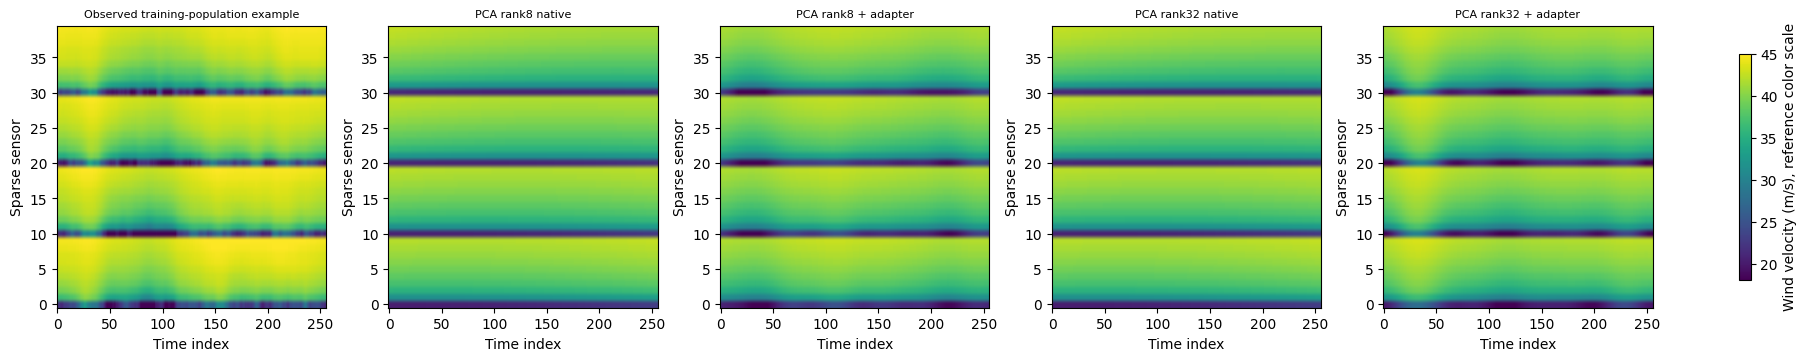


P20 — SOURCE-ALIGNED GAUSSIAN LATENT GENERATION PILOT
Training feature p99 standardized distance: 21.782
Previously incompatible flow median distance: 9157.761
Reference adjacent correlation: 0.9853551462072462

pca_gaussian_rank8 explained variance: 99.9 %
Generated median standardized distance: 9.437
Fraction above training p99: 0.016
native range m/s [20.269594103097916, 42.631150007247925] temporal ratio 0.0322 between-field ratio 0.0 low PSD ratio 0.0338 high PSD ratio 0.0376 adjacent correlation 0.9676865969641718 out-of-range fraction 0.0
with_fourier_adapter range m/s [10.03619791874716, 43.95017692971443] temporal ratio 0.4486 between-field ratio 0.1565 low PSD ratio 0.509 high PSD ratio 0.0 adjacent correlation 0.9969756393371385 out-of-range fraction 0.0

pca_gaussian_rank32 explained variance: 100.0 %
Generated median standardized distance: 8.881
Fraction above training p99: 0.016
native range m/s [20.269632071256638, 42.63119089603424] temporal ratio 0.0322 between-field 

In [38]:

# CELL P20 — Distribution-aligned generative baseline
# Paste below P19.
# No retraining of VAE, flow, or Fourier head.

from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, uuid, importlib.util, sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

P7 = BASE / (
    "controlled_vae_ablations/"
    "deterministic_replication_20261030T024339Z_c746ee"
)

P17 = BASE / (
    "fidelity_diagnostics/"
    "p17_spectral_head_20261030T034044Z_1464ad"
)

P18 = BASE / (
    "fidelity_diagnostics/"
    "p18_linear_adapter_958d60a71ba5d6df"
)

P19 = BASE / (
    "fidelity_diagnostics/"
    "p19_flow_adapter_compatibility_20261030T035016Z_4099b1"
)

assert callable(globals().get("note")), "Activate P1 first."
assert callable(globals().get("verify"))
assert torch.cuda.is_available(), "Select NVIDIA GPU runtime."

for p in (
    P17 / "result.json",
    P18 / "linear_fourier_adapter.npz",
    P18 / "linear_fourier_inference.py",
    P19 / "distribution_compatibility.json",
    P7 / "repeat_A_control_final.pt"
):
    assert p.is_file(), f"Missing saved evidence: {p}"

p17 = json.loads((P17 / "result.json").read_text())
p19 = json.loads(
    (P19 / "distribution_compatibility.json").read_text()
)

assert p17["status"] == "completed"
assert p19["status"] == "completed"
assert p19["archived_flow_generation_replay"][
    "matches_tolerance"
] is True

train_ids = np.asarray(
    p17["split"]["training_indices"], dtype=np.int64
)

eval_ids = np.asarray(
    p17["split"]["evaluation_indices"], dtype=np.int64
)

assert len(train_ids) == 256
assert len(eval_ids) == 32
assert not (set(train_ids) & set(eval_ids))

with np.load(
    P18 / "linear_fourier_adapter.npz",
    allow_pickle=False
) as pkg:

    feature_mean = np.asarray(
        pkg["feature_mean"], dtype=np.float64
    )

    feature_scale = np.asarray(
        pkg["feature_scale"], dtype=np.float64
    )

    assert np.asarray(pkg["weights"]).shape == (129, 480)

assert feature_mean.shape == (128,)
assert feature_scale.shape == (128,)
assert np.all(feature_scale > 0)

RUN = BASE / "fidelity_diagnostics" / (
    "p20_aligned_latent_gaussian_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)
REPORT = RUN / "report.json"

# ------------------------------------------------------------
# 1. Restore exact continued control VAE
# ------------------------------------------------------------

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]

import wind_vision_physicsnemo_day1 as w

source_sha = hashlib.sha256(
    Path(w.__file__).read_bytes()
).hexdigest()

assert source_sha == p17["source_sha256"], (
    "PhysicsNeMo implementation has changed."
)

ckpt, train_file = w.assert_environment()

(
    _, _, _, _, _,
    DataCls, LossCls, _, _
) = w.prepare_reference_imports()

dataset, _ = w.make_loss_and_data(
    train_file, DataCls, LossCls
)

dataset.points = dataset.points.float()

assert len(dataset.sensor_idx) == 40

saved = torch.load(
    P7 / "repeat_A_control_final.pt",
    map_location="cpu",
    weights_only=True
)

assert saved["strict_deterministic"]
assert saved["steps"] == 80

model = w.PhysicsNeMoWindVAE(
    num_sensors=40,
    latent_dim=128,
    grid_low=dataset.grid.low.cpu().tolist(),
    grid_high=dataset.grid.high.cpu().tolist(),
    p_deeponet=512,
    h_branch=128,
    h_trunk=128,
    nhl_branch=2,
    nhl_trunk=2,
    num_fields=1
).cuda().float().eval()

model.load_state_dict(
    saved["state_dict"],
    strict=True
)

model.requires_grad_(False)

coords = dataset.points.cuda()[None]


@torch.inference_mode()
def encode_training(ids):

    parts = []

    for i in range(0, len(ids), 8):

        u = torch.stack([
            dataset[int(j)][0]
            for j in ids[i:i+8]
        ]).float().cuda()

        mu, _ = model.encode(u)

        parts.append(mu.cpu().numpy())

    return np.concatenate(parts).astype(np.float64)


@torch.inference_mode()
def decode_latents(z):

    fields = []

    for i in range(0, len(z), 4):

        zz = torch.from_numpy(
            z[i:i+4].astype(np.float32)
        ).cuda()

        points = coords.expand(
            len(zz), -1, -1
        )

        pred = model.decode(
            zz, points
        ).reshape(len(zz), 40, 256)

        fields.append(pred.cpu().numpy())

    return np.concatenate(fields).astype(np.float64)

# ------------------------------------------------------------
# 2. Verify the exact latent distribution used by P18
# ------------------------------------------------------------

Ztrain = encode_training(train_ids)

assert np.allclose(
    feature_mean,
    Ztrain.mean(0),
    rtol=1e-5,
    atol=1e-7
)

assert np.allclose(
    feature_scale,
    np.maximum(Ztrain.std(0), 1e-5),
    rtol=1e-5,
    atol=1e-7
)

standard = (
    Ztrain - feature_mean
) / feature_scale

center = standard.mean(0)

_, sv, components = np.linalg.svd(
    standard - center,
    full_matrices=False
)

variances = (sv ** 2) / (len(standard) - 1)

explained = (
    variances
    / max(float(variances.sum()), 1e-20)
)

train_l2 = np.linalg.norm(standard, axis=1)

p99 = float(
    np.quantile(train_l2, 0.99)
)


def distribution_stats(z):

    std = (
        z - feature_mean
    ) / feature_scale

    norm = np.linalg.norm(std, axis=1)

    return {
        "median_standardized_l2":
            float(np.median(norm)),

        "fraction_above_training_p99":
            float(np.mean(norm > p99)),

        "fraction_coordinate_abs_zscore_over_5":
            float(np.mean(np.abs(std) > 5)),

        "mean_latent_dimension_sd":
            float(np.mean(np.std(z, axis=0)))
    }

# ------------------------------------------------------------
# 3. Load descriptive reference from P17 evaluation
# ------------------------------------------------------------

with np.load(
    P17 / "evaluation_fields.npz",
    allow_pickle=False
) as f:

    reference = np.asarray(
        f["observed"],
        dtype=np.float64
    )

assert reference.shape == (32, 40, 256)


def field_stats(a):

    a = np.asarray(a, dtype=np.float64)

    c = a - a.mean(
        axis=-1, keepdims=True
    )

    psd = np.abs(
        np.fft.rfft(c, axis=-1)
    ) ** 2

    # Adjacent sensors only within each 10-sensor strip.
    valid_i = np.asarray([
        i for i in range(39)
        if i % 10 != 9
    ])

    aa = c[:, valid_i]
    bb = c[:, valid_i + 1]

    va = np.mean(aa ** 2, axis=-1)
    vb = np.mean(bb ** 2, axis=-1)

    den = np.sqrt(va * vb)

    corr = np.divide(
        np.mean(aa * bb, axis=-1),
        den,
        out=np.zeros_like(den),
        where=den > 1e-16
    )

    mask = den > 1e-16

    physical = a * 49 - 2

    return {
        "range_m_s": [
            float(physical.min()),
            float(physical.max())
        ],

        "mean_m_s": float(physical.mean()),

        "fraction_outside_normalization_range_minus2_to47_m_s":
            float(np.mean(
                (physical < -2)
                | (physical > 47)
            )),

        "temporal_variance":
            float(np.var(a, axis=-1).mean()),

        "between_field_variance":
            float(np.var(a, axis=0).mean()),

        "low_psd_bins_1_6":
            float(psd[..., 1:7].mean()),

        "high_psd_bins_17_64":
            float(psd[..., 17:65].mean()),

        "within_strip_adjacent_anomaly_correlation":
            (
                float(corr[mask].mean())
                if mask.any()
                else None
            ),

        "valid_correlation_pairs":
            int(mask.sum())
    }


reference_stats = field_stats(reference)

# ------------------------------------------------------------
# 4. Restore standalone P18 Fourier decoder
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "p20_adapter",
    P18 / "linear_fourier_inference.py"
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

# ------------------------------------------------------------
# 5. Independently sample from two PCA Gaussian models
#
# PCA is fitted to TRAINING posterior means only.
# Ranks 8 and 32 are fixed in advance.
# No held-out metrics are used to select parameters.
# ------------------------------------------------------------

results = {}

arrays = {
    "reference": reference.astype(np.float32)
}

for rank in (8, 32):

    assert rank <= len(sv)

    seed = 20261030 + rank

    rng = np.random.default_rng(seed)

    noise = rng.normal(
        size=(64, rank)
    )

    # PCA Gaussian fitted to standardized training means.
    normalized = center + (
        (
            noise * (
                sv[:rank]
                / np.sqrt(len(Ztrain) - 1)
            )
        ) @ components[:rank]
    )

    z = (
        feature_mean
        + normalized * feature_scale
    )

    native = decode_latents(z)

    adapted = np.asarray(
        module.predict(
            z,
            native.mean(
                axis=-1,
                keepdims=True
            ),
            P18 / "linear_fourier_adapter.npz"
        ),
        dtype=np.float64
    )

    assert (
        native.shape
        == adapted.shape
        == (64, 40, 256)
    )

    assert np.isfinite(native).all()
    assert np.isfinite(adapted).all()

    label = f"pca_gaussian_rank{rank}"

    stats = {
        "seed": seed,
        "rank": rank,

        "fraction_standardized_variance_explained_by_rank":
            float(explained[:rank].sum()),

        "latent_distribution":
            distribution_stats(z),

        "native":
            field_stats(native),

        "with_fourier_adapter":
            field_stats(adapted)
    }

    for variant in (
        "native",
        "with_fourier_adapter"
    ):

        for key in (
            "temporal_variance",
            "between_field_variance",
            "low_psd_bins_1_6",
            "high_psd_bins_17_64"
        ):

            stats[variant][
                key + "_to_reference_ratio"
            ] = (
                stats[variant][key]
                / max(reference_stats[key], 1e-20)
            )

    results[label] = stats

    arrays[label + "_z"] = z.astype(np.float32)

    arrays[label + "_native"] = (
        native.astype(np.float32)
    )

    arrays[label + "_adapter"] = (
        adapted.astype(np.float32)
    )

np.savez_compressed(
    RUN / "samples.npz",
    **arrays
)

# ------------------------------------------------------------
# 6. Compare generated fields on reference color scale
# ------------------------------------------------------------

fig, axs = plt.subplots(
    1, 5,
    figsize=(18, 3.5),
    constrained_layout=True
)

labels = [
    (
        "Observed training-population example",
        reference[0]
    ),
    (
        "PCA rank8 native",
        arrays["pca_gaussian_rank8_native"][0]
    ),
    (
        "PCA rank8 + adapter",
        arrays["pca_gaussian_rank8_adapter"][0]
    ),
    (
        "PCA rank32 native",
        arrays["pca_gaussian_rank32_native"][0]
    ),
    (
        "PCA rank32 + adapter",
        arrays["pca_gaussian_rank32_adapter"][0]
    )
]

lo, hi = np.quantile(
    reference[0] * 49 - 2,
    [0.01, 0.99]
)

for ax, (title, field) in zip(axs, labels):

    im = ax.imshow(
        field * 49 - 2,
        origin="lower",
        aspect="auto",
        cmap="viridis",
        vmin=float(lo),
        vmax=float(hi)
    )

    ax.set_title(title, fontsize=8)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor")

fig.colorbar(
    im,
    ax=axs,
    label="Wind velocity (m/s), reference color scale",
    shrink=0.8
)

fig.savefig(
    RUN / "generated_field_comparison.png",
    dpi=160
)

display(fig)
plt.close(fig)

# ------------------------------------------------------------
# 7. Save full scientific report
# ------------------------------------------------------------

report = {
    "experiment":
        "P20_mean_aligned_low_rank_gaussian_latent_generation_pilot",

    "time_utc":
        datetime.now(timezone.utc).isoformat(),

    "source_sha256":
        source_sha,

    "training_indices_from_P17":
        train_ids.tolist(),

    "adapter_evaluation_indices_from_P17":
        eval_ids.tolist(),

    "generator_training_distribution": (
        "Continued control VAE posterior means, "
        "NOT original epoch-10 stochastic samples"
    ),

    "sampler": (
        "Fresh independent Gaussian PCA draws "
        "with training-fitted mean, eigenvectors "
        "and eigenvalues"
    ),

    "train_p99_standardized_distance":
        p99,

    "reference_evaluation_population_stats":
        reference_stats,

    "original_mismatched_flow_median_standardized_l2":
        p19["latent_groups"][
            "existing_flow_generated_latents"
        ]["median_adapter_standardized_l2"],

    "models":
        results,

    "limitations": [
        "Reference consists of original VAE training-population fields, not an independent test set.",
        "Gaussian PCA is a diagnostic baseline, not a retrained or converged latent flow.",
        "No multi-run uncertainty, physical-coherence target, or independent generalization established.",
        "Both PCA ranks were fixed before evaluation and were not selected using reference metrics.",
        "Visual color range is for display only. No velocities were clipped or repaired."
    ]
}

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

# ------------------------------------------------------------
# 8. Print decision-relevant results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("P20 — SOURCE-ALIGNED GAUSSIAN LATENT GENERATION PILOT")
print("=" * 70)

print(
    "Training feature p99 standardized distance:",
    round(p99, 3)
)

print(
    "Previously incompatible flow median distance:",
    round(
        report[
            "original_mismatched_flow_median_standardized_l2"
        ],
        3
    )
)

print(
    "Reference adjacent correlation:",
    reference_stats[
        "within_strip_adjacent_anomaly_correlation"
    ]
)

for name, row in results.items():

    print(
        "\n" + name + " explained variance:",
        round(
            100 * row[
                "fraction_standardized_variance_explained_by_rank"
            ],
            2
        ),
        "%"
    )

    print(
        "Generated median standardized distance:",
        round(
            row["latent_distribution"][
                "median_standardized_l2"
            ],
            3
        )
    )

    print(
        "Fraction above training p99:",
        round(
            row["latent_distribution"][
                "fraction_above_training_p99"
            ],
            3
        )
    )

    for key in (
        "native",
        "with_fourier_adapter"
    ):

        d = row[key]

        print(
            key,
            "range m/s",
            d["range_m_s"],
            "temporal ratio",
            round(
                d["temporal_variance_to_reference_ratio"],
                4
            ),
            "between-field ratio",
            round(
                d["between_field_variance_to_reference_ratio"],
                4
            ),
            "low PSD ratio",
            round(
                d["low_psd_bins_1_6_to_reference_ratio"],
                4
            ),
            "high PSD ratio",
            round(
                d["high_psd_bins_17_64_to_reference_ratio"],
                4
            ),
            "adjacent correlation",
            d[
                "within_strip_adjacent_anomaly_correlation"
            ],
            "out-of-range fraction",
            round(
                d[
                    "fraction_outside_normalization_range_minus2_to47_m_s"
                ],
                5
            )
        )

# ------------------------------------------------------------
# 9. Permanent methods, provenance, and negative findings
# ------------------------------------------------------------

note(
    title=(
        "P20: Distribution-aligned Gaussian baseline "
        "for Fourier-conditioned wind generation"
    ),

    question=(
        "Can independently sampled latents fitted to "
        "the continued control posterior means be "
        "decoded without P19's catastrophic extrapolation?"
    ),

    methods=(
        "Fit rank-8 and rank-32 PCA Gaussian "
        "distributions using only P17 adapter-training "
        "posterior means. Draw 64 new vectors per rank, "
        "decode with the fixed control VAE and P18 "
        "Fourier head, and compare physical ranges, "
        "spectral energy, field variability and "
        "within-strip spatial correlation."
    ),

    evidence=[
        str(REPORT),
        str(RUN / "samples.npz"),
        str(RUN / "generated_field_comparison.png")
    ],

    findings={
        "models": results,
        "reference": reference_stats
    },

    limitations=report["limitations"],

    decision=(
        "Retain distribution-compatible samplers as "
        "research candidates only. Assess realism "
        "and diversity before training a new "
        "mean-aligned flow. Do not claim independent "
        "test generalization."
    )
)

print("\nEvidence:", RUN)
print("Research archive verified:", verify())
print("CELL P20 COMPLETE — NO VAE OR FLOW TRAINING")


Dataset coordinate precision verified: torch.float32
Joint and diagonal high-frequency residual samplers: VERIFIED
Original PCA-adapter low-frequency coefficients preserved: PASS


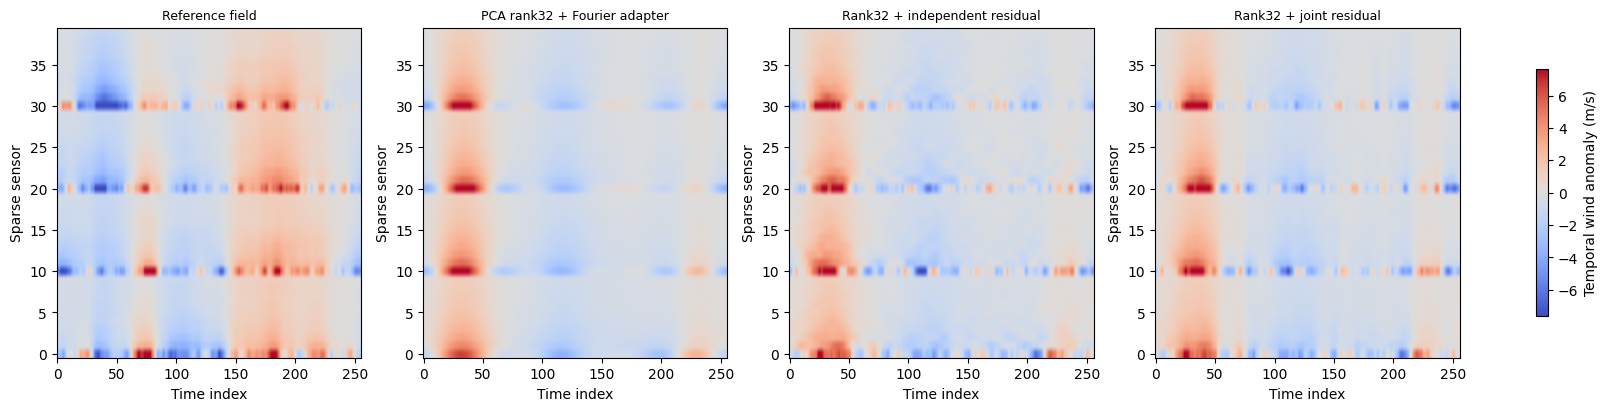


P21 — STOCHASTIC SPECTRAL RESIDUAL ABLATION
Reference cohort: New training-population diagnostic cohort excluded from P17 and P7 continuation.
Reference adjacent correlation: 0.98469
Reference ACF lag1 / lag10: 0.99728 0.84387

PCA rank: 8
adapter_only: temporal=0.452x, lowPSD=0.514x, midPSD=0.000x, highPSD=0.000x, between=0.198x, adjacentCorr=0.9970, lag1=0.9975, outRange=0.00000
plus_diagonal_highband: temporal=0.575x, lowPSD=0.514x, midPSD=1.030x, highPSD=1.024x, between=0.252x, adjacentCorr=0.9194, lag1=0.9932, outRange=0.00000
plus_joint_highband: temporal=0.572x, lowPSD=0.514x, midPSD=0.990x, highPSD=1.030x, between=0.250x, adjacentCorr=0.9748, lag1=0.9931, outRange=0.00000

PCA rank: 32
adapter_only: temporal=0.523x, lowPSD=0.593x, midPSD=0.000x, highPSD=0.000x, between=0.231x, adjacentCorr=0.9954, lag1=0.9975, outRange=0.00000
plus_diagonal_highband: temporal=0.646x, lowPSD=0.593x, midPSD=1.030x, highPSD=1.024x, between=0.284x, adjacentCorr=0.9306, lag1=0.9939, outRange=0.0000

In [39]:

# CELL P21 — Stochastic spectral residual ablation
# Add directly below P20.
# No neural network training. Existing P20 results preserved.

from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import uuid
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

P17 = BASE / (
    "fidelity_diagnostics/"
    "p17_spectral_head_20261030T034044Z_1464ad"
)

P20 = BASE / (
    "fidelity_diagnostics/"
    "p20_aligned_latent_gaussian_20261030T124009Z_16244b"
)

P7 = BASE / (
    "controlled_vae_ablations/"
    "deterministic_replication_20261030T024339Z_c746ee"
)

assert callable(globals().get("note")), "Run P1 first."
assert callable(globals().get("verify")), "Run P1 first."

for path in (
    P17 / "result.json",
    P20 / "report.json",
    P20 / "samples.npz",
    P7 / "environment_and_manifest.json"
):
    assert path.is_file(), f"Missing artifact: {path}"

p17 = json.loads(
    (P17 / "result.json").read_text()
)

p20 = json.loads(
    (P20 / "report.json").read_text()
)

p7 = json.loads(
    (P7 / "environment_and_manifest.json").read_text()
)["manifest"]

assert p17["status"] == "completed"

assert p20["experiment"] == (
    "P20_mean_aligned_low_rank_gaussian_latent_generation_pilot"
)

RUN = BASE / "fidelity_diagnostics" / (
    "p21_spectral_residual_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(parents=True, exist_ok=False)

# ---------------------------------------------------------
# 1. Restore original training dataset without training
# ---------------------------------------------------------

sys.path[:0] = [
    "/content/nasa_clfm_reference",
    "/content"
]

import wind_vision_physicsnemo_day1 as w

def sha(path):
    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()

assert sha(w.__file__) == p17["source_sha256"], (
    "Implementation changed since P17."
)

ckpt, train_file = w.assert_environment()

(
    _, _, _, _, _,
    DataCls, LossCls, _, _
) = w.prepare_reference_imports()

dataset, _ = w.make_loss_and_data(
    train_file, DataCls, LossCls
)

dataset.points = dataset.points.float()

assert len(dataset.sensor_idx) == 40

training_ids = np.asarray(
    p17["split"]["training_indices"],
    dtype=np.int64
)

assert len(training_ids) == 256
assert len(set(training_ids)) == 256

# ---------------------------------------------------------
# 2. Choose a separate descriptive reference cohort
#
# Every field is still part of original VAE pretraining.
# This is NOT independent generalization.
# ---------------------------------------------------------

excluded = (
    set(training_ids)
    | set(p17["split"]["validation_indices"])
    | set(p17["split"]["evaluation_indices"])
    | set(p7["continuation_train_indices"])
    | set(p7["diagnostic_indices"])
)

remaining = np.array(
    sorted(
        set(range(len(dataset))) - excluded
    ),
    dtype=np.int64
)

if len(remaining) >= 32:

    reference_ids = np.random.default_rng(
        212121
    ).choice(
        remaining,
        size=32,
        replace=False
    )

    reference_scope = (
        "New training-population diagnostic cohort "
        "excluded from P17 and P7 continuation."
    )

else:

    reference_ids = np.asarray(
        p17["split"]["evaluation_indices"],
        dtype=np.int64
    )

    reference_scope = (
        "Reused P17 adapter-evaluation cohort "
        "because insufficient distinct fields existed."
    )

    print(
        "WARNING: Reusing prior diagnostic reference."
    )

training = np.stack([
    dataset[int(i)][0].numpy()
    for i in training_ids
]).astype(np.float64)

reference = np.stack([
    dataset[int(i)][0].numpy()
    for i in reference_ids
]).astype(np.float64)

assert training.shape == (256, 40, 256)
assert reference.shape == (32, 40, 256)

assert np.isfinite(training).all()
assert np.isfinite(reference).all()

# ---------------------------------------------------------
# 3. Restore independently generated P20 fields
# ---------------------------------------------------------

with np.load(
    P20 / "samples.npz",
    allow_pickle=False
) as archive:

    base_fields = {
        rank: np.asarray(
            archive[
                f"pca_gaussian_rank{rank}_adapter"
            ],
            dtype=np.float64
        )
        for rank in (8, 32)
    }

for rank, fields in base_fields.items():

    assert fields.shape == (64, 40, 256)
    assert np.isfinite(fields).all()

# ---------------------------------------------------------
# 4. Learn missing Fourier coefficients from training
#
# Joint Gaussian model:
#   40 real + 40 imaginary Fourier coefficients
#   one 80D Gaussian per frequency.
#
# Nyquist frequency contains 40 real coefficients.
#
# A diagonal model is included as a control.
# Frequency bins remain independent.
# ---------------------------------------------------------

T = 256
N = 64

SHRINKAGE = 0.15
SEED = 20261030

rng = np.random.default_rng(SEED)

anomalies = (
    training
    - training.mean(
        axis=-1,
        keepdims=True
    )
)

training_fft = np.fft.rfft(
    anomalies,
    axis=-1
)

joint_fft = np.zeros(
    (N, 40, 129),
    dtype=np.complex128
)

diagonal_fft = np.zeros_like(
    joint_fft
)

frequency_fits = []

for k in range(7, 129):

    coefficients = training_fft[:, :, k]

    nyquist = (k == 128)

    if nyquist:

        values = coefficients.real

    else:

        values = np.concatenate(
            [
                coefficients.real,
                coefficients.imag
            ],
            axis=1
        )

    mean = values.mean(axis=0)

    covariance = np.cov(
        values,
        rowvar=False,
        ddof=1
    )

    covariance = np.atleast_2d(
        covariance
    )

    diagonal_variance = np.maximum(
        np.diag(covariance),
        0
    )

    # Shrink covariance toward its diagonal.
    # Marginal variances remain unchanged.
    joint_covariance = (
        (1.0 - SHRINKAGE) * covariance
        + SHRINKAGE * np.diag(
            diagonal_variance
        )
    )

    jitter = (
        max(
            float(
                np.max(diagonal_variance)
            ),
            1.0
        ) * 1e-12
    )

    factor = np.linalg.cholesky(
        joint_covariance
        + jitter * np.eye(
            len(mean)
        )
    )

    epsilon = rng.standard_normal(
        (N, len(mean))
    )

    joint_draw = (
        mean + epsilon @ factor.T
    )

    diagonal_draw = (
        mean
        + epsilon * np.sqrt(
            diagonal_variance[None, :]
        )
    )

    if nyquist:

        joint_fft[:, :, k] = joint_draw
        diagonal_fft[:, :, k] = diagonal_draw

    else:

        joint_fft[:, :, k] = (
            joint_draw[:, :40]
            + 1j * joint_draw[:, 40:]
        )

        diagonal_fft[:, :, k] = (
            diagonal_draw[:, :40]
            + 1j * diagonal_draw[:, 40:]
        )

    frequency_fits.append({
        "frequency_bin": k,
        "dimensions": len(mean),
        "training_marginal_power_mean": float(
            np.mean(
                np.abs(coefficients) ** 2
            )
        )
    })

joint_residual = np.fft.irfft(
    joint_fft,
    n=T,
    axis=-1
)

diagonal_residual = np.fft.irfft(
    diagonal_fft,
    n=T,
    axis=-1
)

assert joint_residual.shape == (64, 40, 256)
assert diagonal_residual.shape == (64, 40, 256)

# All bins 0..6 must remain zero in these residuals.
for residual in (
    joint_residual,
    diagonal_residual
):

    spectrum = np.fft.rfft(
        residual,
        axis=-1
    )

    assert np.max(
        np.abs(
            spectrum[..., :7]
        )
    ) < 1e-9

    assert np.isfinite(residual).all()

print(
    "Joint and diagonal high-frequency "
    "residual samplers: VERIFIED"
)

# ---------------------------------------------------------
# 5. Measure temporal, spectral and spatial statistics
# ---------------------------------------------------------

adjacent = np.asarray([
    i for i in range(39)
    if i % 10 != 9
], dtype=int)


def statistics(fields):

    a = np.asarray(
        fields,
        dtype=np.float64
    )

    centered = (
        a - a.mean(
            axis=-1,
            keepdims=True
        )
    )

    spectrum = np.fft.rfft(
        centered,
        axis=-1
    )

    power = (
        np.abs(spectrum) ** 2
    )

    left = centered[:, adjacent, :]
    right = centered[:, adjacent + 1, :]

    denominator = np.sqrt(
        np.mean(left**2, axis=-1)
        * np.mean(right**2, axis=-1)
    )

    valid = denominator > 1e-14

    correlations = np.divide(
        np.mean(
            left * right,
            axis=-1
        ),
        denominator,
        out=np.zeros_like(
            denominator
        ),
        where=valid
    )

    temporal_variance = np.mean(
        centered**2,
        axis=-1
    )

    def acf(lag):

        valid_variance = (
            temporal_variance > 1e-14
        )

        raw = np.divide(
            np.mean(
                centered[..., :-lag]
                * centered[..., lag:],
                axis=-1
            ),
            temporal_variance,
            out=np.zeros_like(
                temporal_variance
            ),
            where=valid_variance
        )

        if np.any(valid_variance):
            return float(
                raw[valid_variance].mean()
            )

        return None

    physical = a * 49 - 2

    return {
        "min_velocity_m_s":
            float(physical.min()),

        "max_velocity_m_s":
            float(physical.max()),

        "outside_minus2_to47_fraction":
            float(np.mean(
                (physical < -2)
                | (physical > 47)
            )),

        "temporal_variance":
            float(
                temporal_variance.mean()
            ),

        "between_field_variance":
            float(
                a.var(axis=0).mean()
            ),

        "low_psd_1_6":
            float(
                power[..., 1:7].mean()
            ),

        "mid_psd_7_16":
            float(
                power[..., 7:17].mean()
            ),

        "high_psd_17_64":
            float(
                power[..., 17:65].mean()
            ),

        "upper_psd_65_128":
            float(
                power[..., 65:129].mean()
            ),

        "adjacent_sensor_anomaly_correlation":
            (
                float(
                    correlations[valid].mean()
                )
                if np.any(valid)
                else None
            ),

        "acf_lag1": acf(1),
        "acf_lag10": acf(10),

        "field_temporal_variance_p10_p50_p90":
            np.quantile(
                temporal_variance.mean(
                    axis=1
                ),
                [0.1, 0.5, 0.9]
            ).tolist()
    }


reference_stats = statistics(
    reference
)

metrics = (
    "temporal_variance",
    "between_field_variance",
    "low_psd_1_6",
    "mid_psd_7_16",
    "high_psd_17_64",
    "upper_psd_65_128"
)

# ---------------------------------------------------------
# 6. Compare 2 PCA ranks × 3 decoder variants
# ---------------------------------------------------------

variants = {}

samples = {
    "reference":
        reference.astype(np.float32),

    "high_residual_joint":
        joint_residual.astype(np.float32),

    "high_residual_diagonal":
        diagonal_residual.astype(np.float32)
}

for rank, original in base_fields.items():

    candidates = {
        "adapter_only":
            original,

        "plus_diagonal_highband":
            original + diagonal_residual,

        "plus_joint_highband":
            original + joint_residual
    }

    for name, fields in candidates.items():

        result = statistics(fields)

        for metric in metrics:

            result[
                metric + "_to_reference_ratio"
            ] = (
                result[metric]
                / max(
                    reference_stats[metric],
                    1e-20
                )
            )

        key = f"rank{rank}_{name}"

        variants[key] = result

        samples[key] = fields.astype(
            np.float32
        )

# Verify low-frequency Fourier coefficients preserved.
for rank, base in base_fields.items():

    base_fft = np.fft.rfft(
        base - base.mean(
            axis=-1,
            keepdims=True
        ),
        axis=-1
    )

    for residual in (
        joint_residual,
        diagonal_residual
    ):

        combined = base + residual

        combined_fft = np.fft.rfft(
            combined - combined.mean(
                axis=-1,
                keepdims=True
            ),
            axis=-1
        )

        assert np.max(
            np.abs(
                base_fft[..., 1:7]
                - combined_fft[..., 1:7]
            )
        ) < 1e-8

print(
    "Original PCA-adapter low-frequency "
    "coefficients preserved: PASS"
)

# ---------------------------------------------------------
# 7. Save generated fields
# ---------------------------------------------------------

FIELDS = RUN / "generated_fields.npz"

np.savez_compressed(
    FIELDS,
    **samples
)

# ---------------------------------------------------------
# 8. Comparison figure on a shared reference scale
# ---------------------------------------------------------

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4),
    constrained_layout=True
)

panels = [
    (
        "Reference field",
        reference[0]
    ),
    (
        "PCA rank32 + Fourier adapter",
        base_fields[32][0]
    ),
    (
        "Rank32 + independent residual",
        (
            base_fields[32]
            + diagonal_residual
        )[0]
    ),
    (
        "Rank32 + joint residual",
        (
            base_fields[32]
            + joint_residual
        )[0]
    )
]

reference_anomaly = (
    reference[0]
    - reference[0].mean(
        axis=-1,
        keepdims=True
    )
)

scale = max(
    float(
        np.quantile(
            np.abs(
                reference_anomaly * 49
            ),
            0.995
        )
    ),
    1e-6
)

for ax, (title, fields) in zip(
    axes,
    panels
):

    anomaly = (
        fields
        - fields.mean(
            axis=-1,
            keepdims=True
        )
    )

    im = ax.imshow(
        anomaly * 49,
        origin="lower",
        aspect="auto",
        vmin=-scale,
        vmax=scale,
        cmap="coolwarm"
    )

    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor")

fig.colorbar(
    im,
    ax=axes,
    label="Temporal wind anomaly (m/s)",
    shrink=0.75
)

FIGURE = (
    RUN / "spectral_residual_comparison.png"
)

fig.savefig(
    FIGURE,
    dpi=160
)

display(fig)
plt.close(fig)

# ---------------------------------------------------------
# 9. Permanent research report
# ---------------------------------------------------------

report = {
    "experiment":
        "P21_training_fitted_stochastic_high_frequency_residual",

    "time_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "reference_scope":
        reference_scope,

    "training_indices":
        training_ids.tolist(),

    "reference_indices":
        reference_ids.tolist(),

    "sources": {
        "p17_sha256":
            sha(P17 / "result.json"),

        "p20_samples_sha256":
            sha(P20 / "samples.npz"),

        "patched_source_sha256":
            sha(w.__file__)
    },

    "residual_frequency_bins":
        [7, 128],

    "residual_covariance_shrinkage":
        SHRINKAGE,

    "sampler_seed":
        SEED,

    "generated_samples_per_variant":
        N,

    "covariance_training_fields":
        len(training_ids),

    "covariance_model": (
        "Joint real/imag 40-sensor Gaussian at each "
        "FFT frequency; frequencies independently sampled."
    ),

    "control_model": (
        "Independent Gaussian Fourier coordinates "
        "with matched training marginal variances."
    ),

    "reference_stats":
        reference_stats,

    "variants":
        variants,

    "frequency_fits":
        frequency_fits,

    "limitations": [
        "All fields belong to the original pretrained VAE training population.",
        "Even a newly selected reference cohort is not independent of VAE pretraining.",
        "PCA-rank decisions were informed by P20.",
        "High-frequency residual sampling is independent of the low-frequency generator.",
        "Different Fourier bins are sampled independently; cross-frequency phase coupling and bursts may be missing.",
        "Matching PSD does not prove reconstruction, physical realism, or correct temporal dynamics.",
        "The normalization interval is not a validated physical admissibility boundary.",
        "Sample sizes are 64 generated and 32 reference; uncertainty has not been quantified."
    ]
}

REPORT = RUN / "result.json"

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

# ---------------------------------------------------------
# 10. Print decision-relevant results
# ---------------------------------------------------------

print("\n" + "=" * 74)
print("P21 — STOCHASTIC SPECTRAL RESIDUAL ABLATION")
print("=" * 74)

print(
    "Reference cohort:",
    reference_scope
)

print(
    "Reference adjacent correlation:",
    round(
        reference_stats[
            "adjacent_sensor_anomaly_correlation"
        ],
        5
    )
)

print(
    "Reference ACF lag1 / lag10:",
    round(
        reference_stats["acf_lag1"],
        5
    ),
    round(
        reference_stats["acf_lag10"],
        5
    )
)

for rank in (8, 32):

    print("\nPCA rank:", rank)

    for mode in (
        "adapter_only",
        "plus_diagonal_highband",
        "plus_joint_highband"
    ):

        row = variants[
            f"rank{rank}_{mode}"
        ]

        print(
            f"{mode}: "
            f"temporal="
            f"{row['temporal_variance_to_reference_ratio']:.3f}x, "
            f"lowPSD="
            f"{row['low_psd_1_6_to_reference_ratio']:.3f}x, "
            f"midPSD="
            f"{row['mid_psd_7_16_to_reference_ratio']:.3f}x, "
            f"highPSD="
            f"{row['high_psd_17_64_to_reference_ratio']:.3f}x, "
            f"between="
            f"{row['between_field_variance_to_reference_ratio']:.3f}x, "
            f"adjacentCorr="
            f"{row['adjacent_sensor_anomaly_correlation']:.4f}, "
            f"lag1="
            f"{row['acf_lag1']:.4f}, "
            f"outRange="
            f"{row['outside_minus2_to47_fraction']:.5f}"
        )

print("\nSaved report:", REPORT)
print("Saved generated fields:", FIELDS)

# ---------------------------------------------------------
# 11. Research journal and archive verification
# ---------------------------------------------------------

note(
    title=(
        "P21: Joint versus diagonal stochastic "
        "Fourier residual ablation"
    ),

    question=(
        "Can learned frequency-wise stochastic "
        "residuals restore the missing spectral "
        "power and spatial dependence in PCA-aligned "
        "generated wind fields?"
    ),

    methods=(
        "Fit joint real/imag Fourier coefficient "
        "Gaussians to bins 7 through 128 using 256 "
        "P17 training fields, with 15% covariance "
        "shrinkage. Compare with an independent-"
        "coordinate control using matched marginal "
        "variances. Add both to existing P20 PCA "
        "rank-8 and rank-32 generations."
    ),

    evidence=[
        str(REPORT),
        str(FIELDS),
        str(FIGURE)
    ],

    findings={
        "reference_scope":
            reference_scope,

        "reference_statistics":
            reference_stats,

        "candidate_statistics":
            variants
    },

    limitations=report["limitations"],

    decision=(
        "Retain only as an exploratory generative "
        "baseline. Compare spatial correlation, "
        "ACF, field diversity and velocity ranges "
        "before considering a conditional stochastic "
        "spectral decoder or new latent-flow training."
    )
)

print(
    "Research archive verified:",
    verify()
)

print(
    "CELL P21 COMPLETE — "
    "NO NEURAL NETWORK RETRAINING"
)


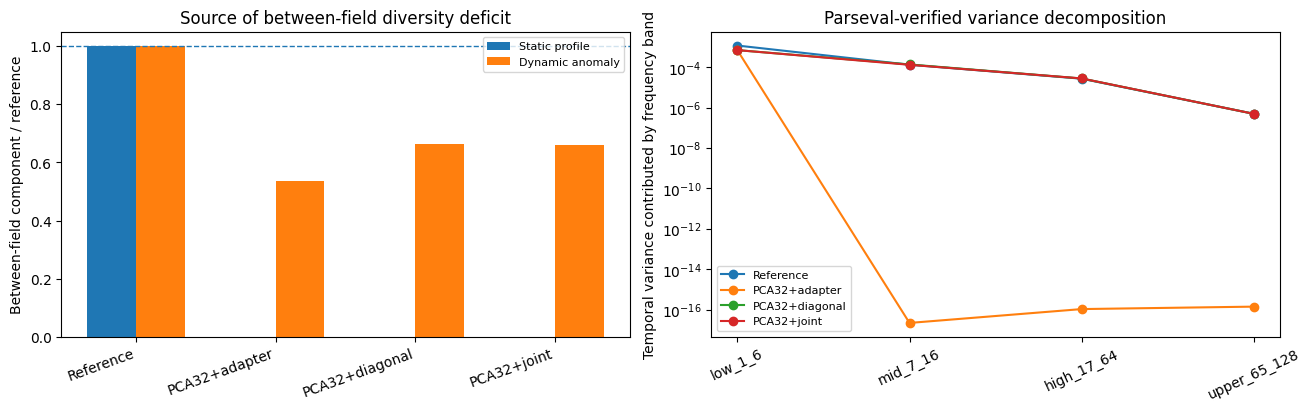


P22 — GENERATIVE VARIANCE & CROSS-FREQUENCY DIAGNOSTICS

 reference
  Temporal variance retained: 100.00%
  Static between-field retained: 100.00%
  Dynamic between-field retained: 100.00%
  Band variance ratio: {'low_1_6': 1.0, 'mid_7_16': 1.0, 'high_17_64': 1.0, 'upper_65_128': 1.0}
  Low-vs-high per-field power correlation: -0.0659164091546671
  Rolling cross-band envelope correlation: -0.011465401385158553
  Adjacent sensor correlation: 0.9846852124966738
  p99 absolute one-step increment (m/s): 1.1929

 rank32_adapter_only
  Temporal variance retained: 52.26%
  Static between-field retained: 0.00%
  Dynamic between-field retained: 53.73%
  Band variance ratio: {'low_1_6': 0.593, 'mid_7_16': 0.0, 'high_17_64': 0.0, 'upper_65_128': 0.0}
  Low-vs-high per-field power correlation: None
  Rolling cross-band envelope correlation: None
  Adjacent sensor correlation: 0.9953827477770791
  p99 absolute one-step increment (m/s): 0.2566

 rank32_plus_diagonal_highband
  Temporal variance ret

In [40]:

# CELL P22 — Explain residual variance/diversity gaps and cross-band dynamics
# Add below P21. Existing archives only; no training, no GPU needed.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
P21 = BASE / 'fidelity_diagnostics/p21_spectral_residual_20261030T125113Z_72f1f8'
assert callable(globals().get('note')), 'Run P1 first'
assert callable(globals().get('verify')), 'Run P1 first'
REPORT_IN, DATA_IN = P21 / 'result.json', P21 / 'generated_fields.npz'
assert REPORT_IN.is_file() and DATA_IN.is_file()
source = json.loads(REPORT_IN.read_text())
assert source['experiment'] == 'P21_training_fitted_stochastic_high_frequency_residual'

NAMES = ['reference',
         'rank32_adapter_only',
         'rank32_plus_diagonal_highband',
         'rank32_plus_joint_highband',
         'rank8_plus_joint_highband']
with np.load(DATA_IN, allow_pickle=False) as f:
    assert all(name in f.files for name in NAMES)
    fields = {name: np.asarray(f[name], dtype=np.float64) for name in NAMES}
assert fields['reference'].shape == (32, 40, 256)
assert all(a.shape[1:] == (40, 256) and np.isfinite(a).all() for a in fields.values())

# Energy by Fourier band is computed using Parseval's theorem,
# with single-sided real-FFT weights, including the Nyquist bin.
weights = np.ones(129)
weights[1:128] = 2.0
BANDS = {'low_1_6': (1, 7), 'mid_7_16': (7, 17),
         'high_17_64': (17, 65), 'upper_65_128': (65, 129)}
adj = np.array([i for i in range(39) if i % 10 != 9])

def circular_rolling_power(a, width=16):
    # Circular window, so every time point gets equal support.
    q = a * a
    padded = np.concatenate((q[..., -(width-1):], q), axis=-1)
    cumulative = np.cumsum(np.pad(padded, ((0,0),(0,0),(1,0))), axis=-1)
    return (cumulative[..., width:] - cumulative[..., :-width]) / width

def summarise(a):
    mu_t = a.mean(axis=-1, keepdims=True)
    anomalies = a - mu_t
    total_between = float(a.var(axis=0).mean())
    static_between = float(mu_t.var(axis=0).mean())
    dynamic_between = float(anomalies.var(axis=0).mean())
    assert np.isclose(total_between, static_between + dynamic_between, rtol=1e-9, atol=1e-13)
    temporal_var = float(np.mean(anomalies**2))
    F = np.fft.rfft(anomalies, axis=-1)
    energy = (np.abs(F)**2) * weights[None, None, :]/(a.shape[-1]**2)
    band_energy = {key: float(energy[..., lo:hi].sum(axis=-1).mean())
                   for key, (lo, hi) in BANDS.items()}
    assert np.isclose(sum(band_energy.values()), temporal_var, rtol=1e-10, atol=1e-13)
    # Low-vs-high energy correlation across independent generated fields.
    energy_low_by_field = energy[..., 1:7].sum(axis=(1,2)) / a.shape[1]
    energy_high_by_field = energy[..., 7:129].sum(axis=(1,2)) / a.shape[1]
    if min(energy_low_by_field.std(), energy_high_by_field.std()) > 1e-15:
        frequency_energy_corr = float(np.corrcoef(energy_low_by_field, energy_high_by_field)[0, 1])
    else:
        frequency_energy_corr = None
    # Cross-band temporal co-modulation of time-local energy envelopes.
    lf = np.zeros_like(F); lf[..., 1:7] = F[..., 1:7]
    hf = np.zeros_like(F); hf[..., 7:] = F[..., 7:]
    low = np.fft.irfft(lf, n=256, axis=-1)
    high = np.fft.irfft(hf, n=256, axis=-1)
    low_env = circular_rolling_power(low)
    high_env = circular_rolling_power(high)
    left = low_env - low_env.mean(axis=-1, keepdims=True)
    right = high_env - high_env.mean(axis=-1, keepdims=True)
    denom = np.sqrt(np.mean(left**2,axis=-1)*np.mean(right**2,axis=-1))
    valid = denom > 1e-16
    corr = np.divide(np.mean(left*right,axis=-1), denom,
                     out=np.zeros_like(denom), where=valid)
    burst_corr = float(corr[valid].mean()) if valid.any() else None
    # Spatial correlation within each strip. Avoid correlating strip boundaries.
    x, y = anomalies[:, adj, :], anomalies[:, adj+1, :]
    xy = np.mean(x*y,axis=-1)
    denom_xy = np.sqrt(np.mean(x*x,axis=-1)*np.mean(y*y,axis=-1))
    valid_xy = denom_xy > 1e-16
    cc = np.divide(xy, denom_xy, out=np.zeros_like(xy), where=valid_xy)
    adjacency = float(cc[valid_xy].mean()) if valid_xy.any() else None
    # Per-field temporal variance and per-field local gradients give spread and intermittency.
    per_field_temporal = np.mean(anomalies**2, axis=(1,2))
    increments = np.diff(a, axis=-1)*49.0  # physical m/s change per time index
    physical = a*49-2
    return {
        'n_fields': int(len(a)),
        'temporal_variance': temporal_var,
        'between_field_variance': total_between,
        'static_profile_between_field_variance': static_between,
        'dynamic_anomaly_between_field_variance': dynamic_between,
        'between_field_static_fraction': static_between / max(total_between, 1e-20),
        'fft_energy_by_band': band_energy,
        'fft_energy_fraction_by_band': {k:v/max(temporal_var,1e-20) for k,v in band_energy.items()},
        'low_vs_high_field_power_correlation': frequency_energy_corr,
        'cross_band_rolling_energy_correlation': burst_corr,
        'adjacent_sensor_anomaly_correlation': adjacency,
        'temporal_variance_field_p10_p50_p90': np.quantile(per_field_temporal,[.1,.5,.9]).tolist(),
        'absolute_time_increment_p95_m_s': float(np.quantile(np.abs(increments),.95)),
        'absolute_time_increment_p99_m_s': float(np.quantile(np.abs(increments),.99)),
        'velocity_min_max_m_s': [float(physical.min()),float(physical.max())]
    }

results = {name: summarise(a) for name,a in fields.items()}
ref = results['reference']
compare_keys = ['temporal_variance','between_field_variance',
                'static_profile_between_field_variance','dynamic_anomaly_between_field_variance',
                'absolute_time_increment_p95_m_s','absolute_time_increment_p99_m_s']
for name, st in results.items():
    st['ratios_to_reference'] = {k: st[k]/max(ref[k],1e-20) for k in compare_keys}
    st['band_energy_ratios_to_reference'] = {
        k: st['fft_energy_by_band'][k]/max(ref['fft_energy_by_band'][k],1e-20)
        for k in BANDS}

# Conservative descriptive field-level bootstrap; not external generalization.
BOOT = 200
rng = np.random.default_rng(220122)
bootstrap = {}
for key in ['rank32_adapter_only','rank32_plus_diagonal_highband','rank32_plus_joint_highband']:
    a = fields[key]
    b = fields['reference']
    ratios = {'temporal_variance':[], 'between_field_variance':[],
              'static_profile_between_field_variance':[],
              'dynamic_anomaly_between_field_variance':[]}
    for _ in range(BOOT):
        x = a[rng.integers(len(a),size=len(a))]
        y = b[rng.integers(len(b),size=len(b))]
        # Compute only the required four moments, not FFTs.
        def moments(z):
            tm=z.mean(-1,keepdims=True)
            residual=z-tm
            return (float(np.mean(residual**2)),float(z.var(0).mean()),
                    float(tm.var(0).mean()),float(residual.var(0).mean()))
        m1, m2 = moments(x), moments(y)
        for j, metric in enumerate(ratios):
            ratios[metric].append(m1[j]/max(m2[j],1e-20))
    bootstrap[key] = {m:np.quantile(v,[.025,.975]).tolist() for m,v in ratios.items()}

h = hashlib.sha256(DATA_IN.read_bytes() + REPORT_IN.read_bytes()).hexdigest()[:16]
RUN = BASE / 'fidelity_diagnostics' / ('p22_variance_gap_audit_' + h)
RUN.mkdir(exist_ok=True, parents=True)
OUT = RUN/'report.json'
FIG = RUN/'variance_components_and_energy.png'
report = {
    'experiment':'P22_generation_variance_and_cross_band_diagnostics',
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'source_p21_result':str(REPORT_IN),
    'source_p21_samples':str(DATA_IN),
    'source_sha256':{'report':hashlib.sha256(REPORT_IN.read_bytes()).hexdigest(),
                     'fields':hashlib.sha256(DATA_IN.read_bytes()).hexdigest()},
    'results':results,
    'bootstrap_ci95_field_resampling':bootstrap,
    'bootstrap_replicates':BOOT,
    'scope':'P21 synthetic fields against training-population reference, not unseen VAE data',
    'limitations':[
        'All reference fields were available to the original VAE during pretraining.',
        'PSD matching of fitted frequency-wise Gaussian draws is expected and does not prove realistic trajectories.',
        'A Gaussian residual sampled separately by frequency omits cross-frequency dependencies.',
        'Temporal amplitude-envelope correlation and cross-field power correlation are diagnostics, not physical constraints.',
        'Field bootstrap is descriptive and does not cover model fitting uncertainty, hardware, or new domains.',
        'The sampled fields do not correspond one-to-one with reference fields, so reconstruction R2 cannot be computed.'
    ]
}
if not OUT.exists():
    OUT.write_text(json.dumps(report,indent=2,allow_nan=False))

labels=['Reference','PCA32+adapter','PCA32+diagonal','PCA32+joint']
keys=['reference','rank32_adapter_only','rank32_plus_diagonal_highband','rank32_plus_joint_highband']
fig, axs=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
metrics=['static_profile_between_field_variance','dynamic_anomaly_between_field_variance']
for i,metric in enumerate(metrics):
    x=np.arange(len(keys)); width=.35
    ratios=[results[k][metric]/max(ref[metric],1e-20) for k in keys]
    axs[0].bar(x+(-.175 if i==0 else .175),ratios,width,label=('Static profile' if i==0 else 'Dynamic anomaly'))
axs[0].set_xticks(np.arange(len(keys)),labels,rotation=20,ha='right')
axs[0].axhline(1,linestyle='--',linewidth=1)
axs[0].set_ylabel('Between-field component / reference')
axs[0].set_title('Source of between-field diversity deficit')
axs[0].legend(fontsize=8)
for key in keys:
    st=results[key]
    axs[1].plot(list(BANDS),list(st['fft_energy_by_band'].values()),'o-',label=labels[keys.index(key)])
axs[1].set_yscale('log')
axs[1].set_ylabel('Temporal variance contributed by frequency band')
axs[1].set_title('Parseval-verified variance decomposition')
axs[1].tick_params(axis='x',labelrotation=25)
axs[1].legend(fontsize=8)
fig.savefig(FIG,dpi=160)
display(fig)
plt.close(fig)

print('\n'+'='*76)
print('P22 — GENERATIVE VARIANCE & CROSS-FREQUENCY DIAGNOSTICS')
print('='*76)
for name in keys:
    st=results[name]
    print('\n',name)
    print('  Temporal variance retained: %.2f%%'%(100*st['ratios_to_reference']['temporal_variance']))
    print('  Static between-field retained: %.2f%%'%(100*st['ratios_to_reference']['static_profile_between_field_variance']))
    print('  Dynamic between-field retained: %.2f%%'%(100*st['ratios_to_reference']['dynamic_anomaly_between_field_variance']))
    print('  Band variance ratio:',{k:round(v,3) for k,v in st['band_energy_ratios_to_reference'].items()})
    print('  Low-vs-high per-field power correlation:',st['low_vs_high_field_power_correlation'])
    print('  Rolling cross-band envelope correlation:',st['cross_band_rolling_energy_correlation'])
    print('  Adjacent sensor correlation:',st['adjacent_sensor_anomaly_correlation'])
    print('  p99 absolute one-step increment (m/s): %.4f'%st['absolute_time_increment_p99_m_s'])
print('\nRank32 joint 95% descriptive CI for retained temporal variance:',
      bootstrap['rank32_plus_joint_highband']['temporal_variance'])
print('Rank32 joint 95% descriptive CI for between-field diversity:',
      bootstrap['rank32_plus_joint_highband']['between_field_variance'])
print('Saved:',OUT)
if not (RUN/'journal_written.flag').exists():
    note(title='P22: Generation variance-budget and cross-frequency audit',
         question='Why are temporal variance and between-field diversity under-recovered despite spectral-band matching?',
         methods='Decompose total temporal variance by exact single-sided FFT Parseval weighting and between-field variability into time-mean and anomaly terms. Compare rolling low/high energy dependence, adjacent correlation, gradient tails, and field-level bootstrap against P21 archived reference.',
         evidence=[str(OUT),str(FIG),str(DATA_IN),str(REPORT_IN)],
         findings={'rank32_joint':results['rank32_plus_joint_highband'],
                   'reference':results['reference'],
                   'bootstrap':bootstrap['rank32_plus_joint_highband']},
         limitations=report['limitations'],
         decision='Use the measured variance gap decomposition to choose the next conditional low-frequency/diversity intervention; do not equate PSD matching with physical validation.')
    (RUN/'journal_written.flag').write_text(datetime.now(timezone.utc).isoformat())
print('Research archive verified:',verify())
print('CELL P22 COMPLETE — NO TRAINING')


Dataset coordinate precision verified: torch.float32
Static-profile replacement preserves all temporal anomalies: PASS


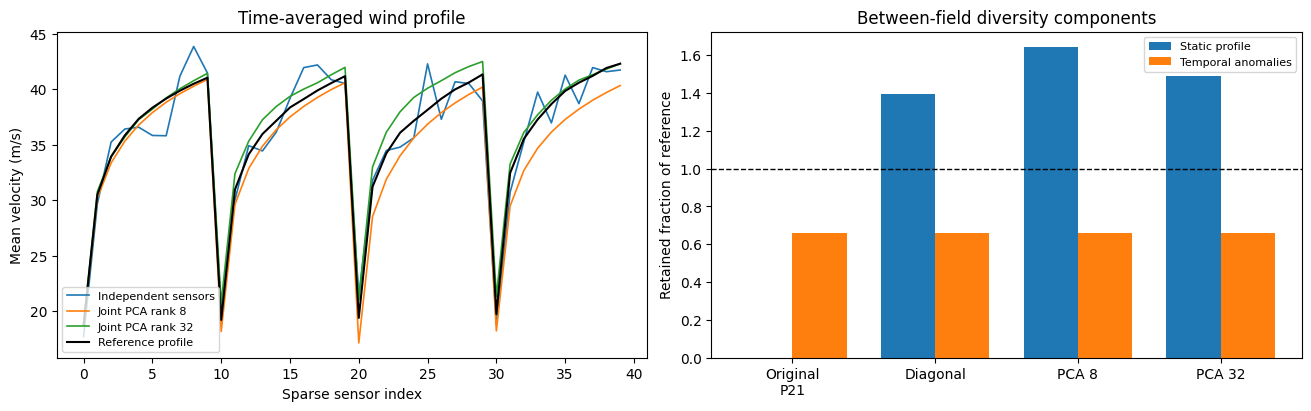


P23 — STATIC PROFILE GENERATION AND BETWEEN-FIELD DIVERSITY
Static PCA explained variance:
Rank 8: 99.737 %
Rank 32: 99.989 %

Reference static-PC1 / dynamic-energy correlation: 0.19191855878992442

 baseline_original_profile
Total between-field retained: 28.262 %
Static-profile diversity retained: 0.0 %
Dynamic diversity retained: 65.873 %
Temporal variance retained: 64.17 %
Spatial covariance relative error vs training: 1.0
Mean-profile RMSE (m/s): 0.70876
Static PC1 / dynamic energy correlation: 0.18255177550450416
Velocity range (m/s): [8.375970542430878, 44.5986687541008]
Outside normalization interval: 0.0

 diagonal_sensor_gaussian
Total between-field retained: 107.812 %
Static-profile diversity retained: 139.327 %
Dynamic diversity retained: 65.873 %
Temporal variance retained: 64.17 %
Spatial covariance relative error vs training: 0.98381
Mean-profile RMSE (m/s): 0.29987
Static PC1 / dynamic energy correlation: -0.012889029997221054
Velocity range (m/s): [2.7651362049602968, 

In [41]:

# ============================================================
# CELL P23 — SPATIALLY CORRELATED STATIC-PROFILE GENERATION
#
# Add below P22.
#
# Fits three static-profile generators using the 256
# P17 adapter-training fields:
#   1. Independent-sensor Gaussian
#   2. Joint spatial Gaussian PCA, rank 8
#   3. Joint spatial Gaussian PCA, rank 32
#
# Preserves P21's generated temporal anomalies exactly.
# No neural training, no test HDF5, no NASA source edits.
# Unique output directory. Research journal preserved.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys
import uuid

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

P23_BASE = Path(
    "/content/drive/MyDrive/"
    "CLFM_Research_Results/physicsnemo_day1"
)

P23_P17 = P23_BASE / (
    "fidelity_diagnostics/"
    "p17_spectral_head_20261030T034044Z_1464ad"
)

P23_P21 = P23_BASE / (
    "fidelity_diagnostics/"
    "p21_spectral_residual_20261030T125113Z_72f1f8"
)

P23_P22 = P23_BASE / (
    "fidelity_diagnostics/"
    "p22_variance_gap_audit_c39d1fc54e6f7d6a"
)

assert callable(globals().get("note")), (
    "Activate the corrected Cell P1 recorder."
)

assert callable(globals().get("verify"))

for path in (
    P23_P17 / "result.json",
    P23_P21 / "result.json",
    P23_P21 / "generated_fields.npz",
    P23_P22 / "report.json"
):
    assert path.is_file(), (
        f"Missing archived evidence: {path}"
    )

p17 = json.loads(
    (P23_P17 / "result.json").read_text()
)

p21 = json.loads(
    (P23_P21 / "result.json").read_text()
)

p22 = json.loads(
    (P23_P22 / "report.json").read_text()
)

assert p17["status"] == "completed"

assert p21["experiment"] == (
    "P21_training_fitted_stochastic_high_frequency_residual"
)

assert p22["experiment"] == (
    "P22_generation_variance_and_cross_band_diagnostics"
)

train_ids = np.asarray(
    p17["split"]["training_indices"],
    dtype=np.int64
)

assert train_ids.shape == (256,)
assert len(set(train_ids)) == 256
assert train_ids.tolist() == p21["training_indices"]

# ------------------------------------------------------------
# 1. Load the existing independently generated fields
# ------------------------------------------------------------

with np.load(
    P23_P21 / "generated_fields.npz",
    allow_pickle=False
) as archive:

    reference = np.asarray(
        archive["reference"],
        dtype=np.float64
    )

    generated = np.asarray(
        archive["rank32_plus_joint_highband"],
        dtype=np.float64
    )

assert reference.shape == (32, 40, 256)
assert generated.shape == (64, 40, 256)

assert np.isfinite(reference).all()
assert np.isfinite(generated).all()

# ------------------------------------------------------------
# 2. Read only the recorded adapter-training fields
# ------------------------------------------------------------

sys.path[:0] = [
    "/content",
    "/content/nasa_clfm_reference"
]

import wind_vision_physicsnemo_day1 as w

source_sha = hashlib.sha256(
    Path(w.__file__).read_bytes()
).hexdigest()

assert source_sha == p17["source_sha256"], (
    "Data/model loader changed since P17."
)

ckpt, train_file = w.assert_environment()

(
    _, _, _, _, _,
    DataCls, LossCls, _, _
) = w.prepare_reference_imports()

dataset, _ = w.make_loss_and_data(
    train_file,
    DataCls,
    LossCls
)

dataset.points = dataset.points.float()

assert len(dataset.sensor_idx) == 40

training = np.stack([
    dataset[int(i)][0].numpy()
    for i in train_ids
]).astype(np.float64)

assert training.shape == (256, 40, 256)
assert np.isfinite(training).all()

# ------------------------------------------------------------
# 3. Separate time-averaged profiles from fluctuations
# ------------------------------------------------------------

static_train = training.mean(axis=-1)

static_reference = reference.mean(axis=-1)

static_old = generated.mean(axis=-1)

dynamic_generated = (
    generated
    - static_old[:, :, None]
)

assert np.max(
    np.abs(
        dynamic_generated.mean(axis=-1)
    )
) < 1e-12

# ------------------------------------------------------------
# 4. Fit spatial PCA using TRAINING profiles only
# ------------------------------------------------------------

mu = static_train.mean(axis=0)

U, singular, Vh = np.linalg.svd(
    static_train - mu,
    full_matrices=False
)

variances = (
    singular ** 2
    / (len(static_train) - 1)
)

explained = (
    variances
    / max(
        float(variances.sum()),
        1e-20
    )
)

sensor_sd = static_train.std(
    axis=0,
    ddof=1
)

rng = np.random.default_rng(230123)

static_draws = {
    "baseline_original_profile":
        static_old
}

# Independent sensor control.
static_draws[
    "diagonal_sensor_gaussian"
] = (
    mu
    + rng.normal(
        size=(64, 40)
    ) * sensor_sd
)

# Joint spatial Gaussian alternatives.
for rank in (8, 32):

    noise = rng.normal(
        size=(64, rank)
    )

    profile = (
        mu
        + (
            noise
            * np.sqrt(
                variances[:rank]
            )[None, :]
        ) @ Vh[:rank]
    )

    static_draws[
        f"joint_spatial_pca_rank{rank}"
    ] = profile

# ------------------------------------------------------------
# 5. Evaluate exact static/dynamic variance decomposition
# ------------------------------------------------------------

def moments(fields):

    profile = fields.mean(
        axis=-1,
        keepdims=True
    )

    anomaly = fields - profile

    total_between = float(
        fields.var(axis=0).mean()
    )

    static_between = float(
        profile.var(axis=0).mean()
    )

    dynamic_between = float(
        anomaly.var(axis=0).mean()
    )

    assert np.isclose(
        total_between,
        static_between + dynamic_between,
        rtol=1e-9,
        atol=1e-13
    )

    spectrum = np.fft.rfft(
        anomaly,
        axis=-1
    )

    power = (
        np.abs(spectrum) ** 2
    )

    physical = fields * 49 - 2

    return {
        "total_between_field_variance":
            total_between,

        "static_between_field_variance":
            static_between,

        "dynamic_between_field_variance":
            dynamic_between,

        "temporal_variance": float(
            (anomaly ** 2).mean()
        ),

        "low_band_psd_1_6": float(
            power[..., 1:7].mean()
        ),

        "mid_band_psd_7_16": float(
            power[..., 7:17].mean()
        ),

        "high_band_psd_17_64": float(
            power[..., 17:65].mean()
        ),

        "physical_velocity_min_max_m_s": [
            float(physical.min()),
            float(physical.max())
        ],

        "fraction_outside_minus2_to47": float(
            (
                (physical < -2)
                | (physical > 47)
            ).mean()
        )
    }


def profile_covariance(profiles):

    return np.cov(
        profiles,
        rowvar=False
    )


def static_dynamic_relationship(fields):

    profile = fields.mean(axis=-1)

    anomaly = (
        fields
        - profile[:, :, None]
    )

    pc1 = (
        (profile - mu)
        @ Vh[0]
    )

    dynamic_energy = (
        anomaly ** 2
    ).mean(axis=(1, 2))

    if (
        pc1.std() <= 1e-12
        or dynamic_energy.std() <= 1e-12
    ):
        return None

    return float(
        np.corrcoef(
            pc1,
            dynamic_energy
        )[0, 1]
    )


train_cov = profile_covariance(
    static_train
)

reference_cov = profile_covariance(
    static_reference
)

train_cov_norm = max(
    float(
        np.linalg.norm(
            train_cov,
            ord="fro"
        )
    ),
    1e-20
)

reference_stats = moments(reference)
baseline_stats = moments(generated)

assert np.isclose(
    baseline_stats["temporal_variance"],
    p22["results"][
        "rank32_plus_joint_highband"
    ]["temporal_variance"],
    rtol=1e-6
)

results = {}
saved_fields = {}

# ------------------------------------------------------------
# 6. Compose each static profile with identical dynamics
# ------------------------------------------------------------

for name, profiles in static_draws.items():

    assert profiles.shape == (64, 40)
    assert np.isfinite(profiles).all()

    fields = (
        profiles[:, :, None]
        + dynamic_generated
    )

    # Absolute check: no temporal anomalies changed.
    reconstructed_anomalies = (
        fields
        - fields.mean(
            axis=-1,
            keepdims=True
        )
    )

    assert np.max(
        np.abs(
            reconstructed_anomalies
            - dynamic_generated
        )
    ) < 1e-10

    stats = moments(fields)

    covariance = profile_covariance(
        profiles
    )

    ratio_keys = (
        "total_between_field_variance",
        "static_between_field_variance",
        "dynamic_between_field_variance",
        "temporal_variance",
        "low_band_psd_1_6",
        "mid_band_psd_7_16",
        "high_band_psd_17_64"
    )

    results[name] = {
        "metrics": stats,

        "ratios_to_reference": {
            key: (
                stats[key]
                / max(
                    reference_stats[key],
                    1e-20
                )
            )
            for key in ratio_keys
        },

        "static_mean_profile_RMSE_vs_training_m_s":
            float(
                np.sqrt(
                    np.mean(
                        (
                            profiles.mean(0)
                            - mu
                        ) ** 2
                    )
                ) * 49
            ),

        "static_covariance_relative_frobenius_error_vs_training":
            float(
                np.linalg.norm(
                    covariance - train_cov,
                    ord="fro"
                ) / train_cov_norm
            ),

        "static_covariance_relative_frobenius_error_vs_reference":
            float(
                np.linalg.norm(
                    covariance - reference_cov,
                    ord="fro"
                )
                / max(
                    float(
                        np.linalg.norm(
                            reference_cov,
                            ord="fro"
                        )
                    ),
                    1e-20
                )
            ),

        "static_PC1_vs_dynamic_energy_correlation":
            static_dynamic_relationship(
                fields
            )
    }

    saved_fields[name] = (
        fields.astype(np.float32)
    )

# ------------------------------------------------------------
# 7. Verify all temporal dynamics remain unchanged
# ------------------------------------------------------------

for name, entry in results.items():

    m = entry["metrics"]

    for key in (
        "temporal_variance",
        "low_band_psd_1_6",
        "mid_band_psd_7_16",
        "high_band_psd_17_64",
        "dynamic_between_field_variance"
    ):

        assert np.isclose(
            m[key],
            baseline_stats[key],
            rtol=1e-10,
            atol=1e-12
        ), (name, key)

print(
    "Static-profile replacement preserves "
    "all temporal anomalies: PASS"
)

# ------------------------------------------------------------
# 8. Unique, permanent output directory
# ------------------------------------------------------------

RUN = P23_BASE / "fidelity_diagnostics" / (
    "p23_spatial_static_profile_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

REPORT = RUN / "result.json"

SAMPLES = (
    RUN / "static_profile_generation.npz"
)

FIGURE = (
    RUN / "static_profile_covariance_and_diversity.png"
)

report = {
    "experiment":
        "P23_training_fitted_spatial_static_profile_sampler",

    "utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "source_p21":
        str(
            P23_P21 / "generated_fields.npz"
        ),

    "training_indices":
        train_ids.tolist(),

    "source_sha256":
        source_sha,

    "sampler_seed":
        230123,

    "training_profile_count":
        len(training),

    "reference_count":
        len(reference),

    "generated_count":
        len(generated),

    "PCA_explained_variance_rank8":
        float(explained[:8].sum()),

    "PCA_explained_variance_rank32":
        float(explained[:32].sum()),

    "composition": (
        "Replace the original static profile with "
        "a training-fitted stochastic spatial profile. "
        "Preserve generated temporal anomalies exactly."
    ),

    "training_reference": {
        "moments":
            moments(training),

        "static_PC1_vs_dynamic_energy_correlation":
            static_dynamic_relationship(training)
    },

    "diagnostic_reference": {
        "moments":
            reference_stats,

        "static_PC1_vs_dynamic_energy_correlation":
            static_dynamic_relationship(reference)
    },

    "results":
        results,

    "limitations": [
        "All fields belong to the original pretrained VAE training population.",
        "Static profile generation is separate from the original VAE and flow.",
        "The stochastic profile is independent of generated temporal fluctuations.",
        "Matching marginal covariance does not establish physical realism.",
        "The interval [-2,47] m/s is a normalization interval, not a physical law.",
        "Generated and reference sample covariance estimates have finite-sample uncertainty.",
        "No independent generalization or physical coherence validation."
    ]
}

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

np.savez_compressed(
    SAMPLES,

    reference=reference.astype(
        np.float32
    ),

    training_static_profiles=static_train.astype(
        np.float32
    ),

    **saved_fields
)

# ------------------------------------------------------------
# 9. Scientific comparison figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4),
    constrained_layout=True
)

for name, label in (
    (
        "diagonal_sensor_gaussian",
        "Independent sensors"
    ),
    (
        "joint_spatial_pca_rank8",
        "Joint PCA rank 8"
    ),
    (
        "joint_spatial_pca_rank32",
        "Joint PCA rank 32"
    )
):

    axes[0].plot(
        np.arange(40),
        static_draws[name][0] * 49 - 2,
        label=label,
        linewidth=1.2
    )

axes[0].plot(
    np.arange(40),
    static_reference[0] * 49 - 2,
    color="black",
    linewidth=1.5,
    label="Reference profile"
)

axes[0].set_title(
    "Time-averaged wind profile"
)

axes[0].set_xlabel(
    "Sparse sensor index"
)

axes[0].set_ylabel(
    "Mean velocity (m/s)"
)

axes[0].legend(fontsize=8)

keys = list(static_draws)

for j, metric in enumerate((
    "static_between_field_variance",
    "dynamic_between_field_variance"
)):

    values = [
        results[key][
            "ratios_to_reference"
        ][metric]
        for key in keys
    ]

    axes[1].bar(
        np.arange(len(keys))
        + (-0.19 if j == 0 else 0.19),
        values,
        0.38,
        label=(
            "Static profile"
            if j == 0
            else "Temporal anomalies"
        )
    )

axes[1].axhline(
    1,
    color="black",
    linewidth=1,
    linestyle="--"
)

axes[1].set_xticks(
    np.arange(len(keys)),
    [
        "Original\nP21",
        "Diagonal",
        "PCA 8",
        "PCA 32"
    ]
)

axes[1].set_title(
    "Between-field diversity components"
)

axes[1].set_ylabel(
    "Retained fraction of reference"
)

axes[1].legend(fontsize=8)

fig.savefig(
    FIGURE,
    dpi=160
)

display(fig)
plt.close(fig)

# ------------------------------------------------------------
# 10. Print decision-relevant results
# ------------------------------------------------------------

print("\n" + "=" * 72)

print(
    "P23 — STATIC PROFILE GENERATION "
    "AND BETWEEN-FIELD DIVERSITY"
)

print("=" * 72)

print(
    "Static PCA explained variance:"
)

print(
    "Rank 8:",
    round(
        100 * explained[:8].sum(),
        3
    ),
    "%"
)

print(
    "Rank 32:",
    round(
        100 * explained[:32].sum(),
        3
    ),
    "%"
)

print(
    "\nReference static-PC1 / dynamic-energy correlation:",
    report["diagnostic_reference"][
        "static_PC1_vs_dynamic_energy_correlation"
    ]
)

for name, entry in results.items():

    m = entry["metrics"]
    r = entry["ratios_to_reference"]

    print("\n", name)

    print(
        "Total between-field retained:",
        round(
            100 * r[
                "total_between_field_variance"
            ],
            3
        ),
        "%"
    )

    print(
        "Static-profile diversity retained:",
        round(
            100 * r[
                "static_between_field_variance"
            ],
            3
        ),
        "%"
    )

    print(
        "Dynamic diversity retained:",
        round(
            100 * r[
                "dynamic_between_field_variance"
            ],
            3
        ),
        "%"
    )

    print(
        "Temporal variance retained:",
        round(
            100 * r["temporal_variance"],
            3
        ),
        "%"
    )

    print(
        "Spatial covariance relative error vs training:",
        round(
            entry[
                "static_covariance_relative_frobenius_error_vs_training"
            ],
            5
        )
    )

    print(
        "Mean-profile RMSE (m/s):",
        round(
            entry[
                "static_mean_profile_RMSE_vs_training_m_s"
            ],
            5
        )
    )

    print(
        "Static PC1 / dynamic energy correlation:",
        entry[
            "static_PC1_vs_dynamic_energy_correlation"
        ]
    )

    print(
        "Velocity range (m/s):",
        m[
            "physical_velocity_min_max_m_s"
        ]
    )

    print(
        "Outside normalization interval:",
        m["fraction_outside_minus2_to47"]
    )

# ------------------------------------------------------------
# 11. Permanent research documentation
# ------------------------------------------------------------

note(
    title=(
        "P23: Spatially correlated generation "
        "of static wind profiles"
    ),

    question=(
        "Can a joint spatial static-profile generator "
        "restore the between-field diversity missing "
        "from P21 without changing temporal dynamics?"
    ),

    methods=(
        "Fit independent-sensor and rank-8/rank-32 "
        "joint Gaussian PCA samplers to 256 P17 "
        "training-field time averages. Replace "
        "only P21 generated static profiles. "
        "Measure variance decomposition, spatial "
        "covariance mismatch, static/dynamic coupling "
        "and physical velocity ranges."
    ),

    evidence=[
        str(REPORT),
        str(SAMPLES),
        str(FIGURE),
        str(
            P23_P21 / "generated_fields.npz"
        )
    ],

    findings={
        "pca32":
            results[
                "joint_spatial_pca_rank32"
            ],

        "independent_sensor_control":
            results[
                "diagonal_sensor_gaussian"
            ]
    },

    limitations=
        report["limitations"],

    decision=(
        "Retain a separate joint spatial static prior "
        "only if it restores diversity and spatial "
        "covariance while maintaining credible ranges. "
        "Next test static/dynamic coupling and "
        "independent generalization."
    )
)

print("\nEvidence:", REPORT)

print(
    "Research archive verified:",
    verify()
)

print(
    "CELL P23 COMPLETE — NO NEURAL RETRAINING"
)


Dataset coordinate precision verified: torch.float32
Original DC and bins 7..128 preserved: PASS


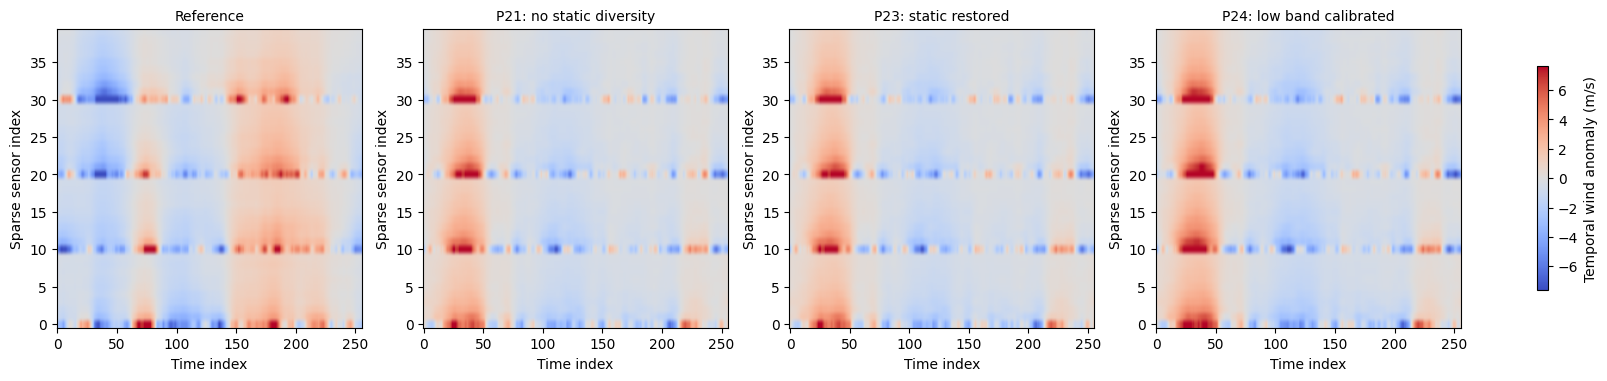


P24 — TRAINING-ONLY LOW-BAND CALIBRATION
Training-fitted low-frequency amplitude gain: 1.30359
Original P23 DC and bins 7..128 preserved: PASS

training
  Temporal variance / reference: 1.0089 x
  Total between-field variance / reference: 1.2112 x
  Static / dynamic diversity ratios: 1.3388 / 1.0414
  PSD ratios: {'low_1_6': 1.0086, 'mid_7_16': 1.0121, 'high_17_64': 1.0095, 'upper_65_128': 0.9912}
  Adjacent correlation: 0.98516
  Static PC1 / dynamic-energy correlation: 0.02935153374855392
  p99 one-step increment: 1.1898 m/s
  Velocity range: [1.5557779371738434, 46.72837579250336]
  Outside normalization interval: 0.0

reference
  Temporal variance / reference: 1.0 x
  Total between-field variance / reference: 1.0 x
  Static / dynamic diversity ratios: 1.0 / 1.0
  PSD ratios: {'low_1_6': 1.0, 'mid_7_16': 1.0, 'high_17_64': 1.0, 'upper_65_128': 1.0}
  Adjacent correlation: 0.98469
  Static PC1 / dynamic-energy correlation: 0.19191855878992442
  p99 one-step increment: 1.1929 m/s
  V

In [42]:

# CELL P24 — Training-only low-frequency energy calibration
# Paste below P23. No neural retraining; no independent-test data.

from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, sys, uuid
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

P17 = BASE / "fidelity_diagnostics/p17_spectral_head_20261030T034044Z_1464ad"
P21 = BASE / "fidelity_diagnostics/p21_spectral_residual_20261030T125113Z_72f1f8"
P23 = BASE / "fidelity_diagnostics/p23_spatial_static_profile_20261030T130313Z_f3dcaa"

assert callable(globals().get("note")), "Activate corrected P1 first."
assert callable(globals().get("verify")), "Activate corrected P1 first."

for f in (
    P17 / "result.json",
    P21 / "result.json",
    P21 / "generated_fields.npz",
    P23 / "result.json",
    P23 / "static_profile_generation.npz"
):
    assert f.is_file(), f"Missing research artifact: {f}"

p17 = json.loads((P17 / "result.json").read_text())
p21 = json.loads((P21 / "result.json").read_text())
p23 = json.loads((P23 / "result.json").read_text())

assert p17["status"] == "completed"
assert p21["experiment"] == (
    "P21_training_fitted_stochastic_high_frequency_residual"
)
assert p23["experiment"] == (
    "P23_training_fitted_spatial_static_profile_sampler"
)

ids = np.asarray(
    p17["split"]["training_indices"],
    dtype=np.int64
)

assert len(ids) == 256 and len(set(ids)) == 256
assert ids.tolist() == p23["training_indices"] == p21["training_indices"]
assert not (set(ids) & set(p21["reference_indices"]))

# ------------------------------------------------------------
# 1. Load previous reference and generated fields
# ------------------------------------------------------------

with np.load(
    P23 / "static_profile_generation.npz",
    allow_pickle=False
) as f:

    reference = np.asarray(
        f["reference"], dtype=np.float64
    )

    generated = np.asarray(
        f["joint_spatial_pca_rank32"], dtype=np.float64
    )

assert reference.shape == (32, 40, 256)
assert generated.shape == (64, 40, 256)

with np.load(
    P21 / "generated_fields.npz",
    allow_pickle=False
) as f:

    prior = np.asarray(
        f["rank32_plus_joint_highband"],
        dtype=np.float64
    )

assert prior.shape == generated.shape
assert np.isfinite(generated).all()
assert np.isfinite(reference).all()

# ------------------------------------------------------------
# 2. Restore P17 training population (not test HDF5)
# ------------------------------------------------------------

sys.path[:0] = [
    "/content",
    "/content/nasa_clfm_reference"
]

import wind_vision_physicsnemo_day1 as w

source_sha = hashlib.sha256(
    Path(w.__file__).read_bytes()
).hexdigest()

assert source_sha == p17["source_sha256"], (
    "Source changed since P17."
)

_, train_file = w.assert_environment()

(
    _, _, _, _, _,
    DataCls, LossCls, _, _
) = w.prepare_reference_imports()

dataset, _ = w.make_loss_and_data(
    train_file, DataCls, LossCls
)

dataset.points = dataset.points.float()
assert len(dataset.sensor_idx) == 40

training = np.stack([
    dataset[int(j)][0].numpy()
    for j in ids
]).astype(np.float64)

assert training.shape == (256, 40, 256)
assert np.isfinite(training).all()

# ------------------------------------------------------------
# 3. Fit low-frequency amplitude using TRAINING only
# ------------------------------------------------------------

def fft_centered(a):

    return np.fft.rfft(
        a - a.mean(axis=-1, keepdims=True),
        axis=-1
    )


train_fft = fft_centered(training)
gen_fft = fft_centered(generated)

low_target = float(
    np.mean(np.abs(train_fft[..., 1:7]) ** 2)
)

low_before = float(
    np.mean(np.abs(gen_fft[..., 1:7]) ** 2)
)

assert low_before > 1e-20
assert low_target > 1e-20

low_gain = float(
    np.sqrt(low_target / low_before)
)

assert np.isfinite(low_gain) and low_gain > 0

# Alter only bins 1..6.
new_fft = np.fft.rfft(
    generated, axis=-1
)

new_fft[..., 1:7] *= low_gain

calibrated = np.fft.irfft(
    new_fft, n=256, axis=-1
)

assert np.isfinite(calibrated).all()

# ------------------------------------------------------------
# 4. Verify DC and high-frequency preservation
# ------------------------------------------------------------

a0 = np.fft.rfft(
    generated, axis=-1
)

a1 = np.fft.rfft(
    calibrated, axis=-1
)

assert np.max(
    np.abs(a1[..., 0] - a0[..., 0])
) < 1e-8

assert np.max(
    np.abs(a1[..., 7:] - a0[..., 7:])
) < 1e-8

assert np.allclose(
    calibrated.mean(-1),
    generated.mean(-1),
    atol=1e-12,
    rtol=1e-12
)

post_cal_low = float(
    np.mean(
        np.abs(
            fft_centered(calibrated)[..., 1:7]
        ) ** 2
    )
)

assert np.isclose(
    post_cal_low,
    low_target,
    rtol=1e-10,
    atol=1e-12
)

print("Original DC and bins 7..128 preserved: PASS")

# ------------------------------------------------------------
# 5. Evaluate all relevant physical/statistical metrics
# ------------------------------------------------------------

adj = np.array([
    i for i in range(39)
    if i % 10 != 9
])

BANDS = {
    "low_1_6": (1, 7),
    "mid_7_16": (7, 17),
    "high_17_64": (17, 65),
    "upper_65_128": (65, 129)
}


def metrics(a):

    m = a.mean(
        axis=-1, keepdims=True
    )

    d = a - m

    f = np.fft.rfft(
        d, axis=-1
    )

    between = float(
        a.var(axis=0).mean()
    )

    static = float(
        m.var(axis=0).mean()
    )

    dynamic = float(
        d.var(axis=0).mean()
    )

    assert np.isclose(
        between,
        static + dynamic,
        rtol=1e-9,
        atol=1e-12
    )

    left = d[:, adj]
    right = d[:, adj + 1]

    denom = np.sqrt(
        np.mean(left ** 2, axis=-1)
        * np.mean(right ** 2, axis=-1)
    )

    cc = np.divide(
        np.mean(left * right, axis=-1),
        denom,
        out=np.zeros_like(denom),
        where=denom > 1e-14
    )

    physical = a * 49 - 2

    return {
        "temporal_variance":
            float(np.mean(d ** 2)),

        "total_between_field_variance":
            between,

        "static_between_field_variance":
            static,

        "dynamic_between_field_variance":
            dynamic,

        "adjacent_sensor_correlation":
            float(cc[denom > 1e-14].mean()),

        "band_psd": {
            k: float(
                np.mean(
                    np.abs(f[..., lo:hi]) ** 2
                )
            )
            for k, (lo, hi) in BANDS.items()
        },

        "p99_abs_one_step_change_m_s":
            float(np.quantile(
                np.abs(np.diff(a, axis=-1) * 49),
                0.99
            )),

        "velocity_min_max_m_s": [
            float(physical.min()),
            float(physical.max())
        ],

        "fraction_outside_normalization_interval":
            float(np.mean(
                (physical < -2)
                | (physical > 47)
            )),

        "per_field_temporal_variance":
            np.mean(d ** 2, axis=(1, 2)).tolist()
    }


all_fields = {
    "training": training,
    "reference": reference,
    "P21_no_static_diversity": prior,
    "P23_joint_static_uncalibrated": generated,
    "P24_joint_static_low_calibrated": calibrated
}

all_metrics = {
    name: metrics(a)
    for name, a in all_fields.items()
}

ref = all_metrics["reference"]

for st in all_metrics.values():

    st["reference_ratios"] = {
        key: st[key] / max(ref[key], 1e-20)
        for key in (
            "temporal_variance",
            "total_between_field_variance",
            "static_between_field_variance",
            "dynamic_between_field_variance"
        )
    }

    st["band_reference_ratios"] = {
        k: (
            st["band_psd"][k]
            / max(ref["band_psd"][k], 1e-20)
        )
        for k in BANDS
    }

# ------------------------------------------------------------
# 6. Diagnose static/dynamic coupling
# ------------------------------------------------------------

train_static = training.mean(axis=-1)

_, _, directions = np.linalg.svd(
    train_static - train_static.mean(0),
    full_matrices=False
)

pc1 = directions[0]


def dependence(a):

    profile = a.mean(-1)

    scores = (
        profile - train_static.mean(0)
    ) @ pc1

    energy = np.mean(
        (
            a - profile[..., None]
        ) ** 2,
        axis=(1, 2)
    )

    if min(
        scores.std(),
        energy.std()
    ) < 1e-14:
        return None

    return float(
        np.corrcoef(scores, energy)[0, 1]
    )


for name, a in all_fields.items():

    all_metrics[name][
        "static_PC1_dynamic_energy_correlation"
    ] = dependence(a)

# ------------------------------------------------------------
# 7. Descriptive field-level bootstrap
# ------------------------------------------------------------

rng = np.random.default_rng(240124)

bootstrap = []

for _ in range(300):

    a = calibrated[
        rng.integers(
            len(calibrated),
            size=len(calibrated)
        )
    ]

    b = reference[
        rng.integers(
            len(reference),
            size=len(reference)
        )
    ]

    ma = a - a.mean(-1, keepdims=True)
    mb = b - b.mean(-1, keepdims=True)

    bootstrap.append([
        float(
            np.mean(ma ** 2)
            / max(float(np.mean(mb ** 2)), 1e-20)
        ),
        float(
            a.var(0).mean()
            / max(float(b.var(0).mean()), 1e-20)
        )
    ])

ci = np.quantile(
    bootstrap,
    [0.025, 0.975],
    axis=0
)

# ------------------------------------------------------------
# 8. Save new, provenance-tracked research evidence
# ------------------------------------------------------------

RUN = BASE / "fidelity_diagnostics" / (
    "p24_training_only_lowband_calibration_"
    + datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%SZ"
    )
    + "_"
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

REPORT = RUN / "result.json"
FIG = RUN / "training_calibrated_lowband_comparison.png"
SAMPLES = RUN / "generated_fields.npz"

np.savez_compressed(
    SAMPLES,
    reference=reference.astype("float32"),
    original_p23=generated.astype("float32"),
    low_calibrated=calibrated.astype("float32")
)

report = {
    "experiment":
        "P24_training_only_low_frequency_amplitude_calibration",

    "utc":
        datetime.now(timezone.utc).isoformat(),

    "method": (
        "Multiply only real-FFT bins 1..6 of existing "
        "P23 generated fields by sqrt(training low-band "
        "power / generated low-band power). "
        "Keep DC and bins 7..128 unchanged."
    ),

    "gain": low_gain,

    "training_low_band_mean_psd":
        low_target,

    "uncalibrated_generated_low_band_mean_psd":
        low_before,

    "calibrated_generated_low_band_mean_psd":
        post_cal_low,

    "training_indices": ids.tolist(),

    "reference_indices":
        p21["reference_indices"],

    "source_sha256":
        source_sha,

    "sources": {
        "p17": str(P17 / "result.json"),
        "p21": str(P21 / "result.json"),
        "p23": str(P23 / "result.json")
    },

    "metrics": all_metrics,

    "descriptive_bootstrap_95pct_CI": {
        "temporal_ratio": ci[:, 0].tolist(),
        "between_field_ratio": ci[:, 1].tolist()
    },

    "limitations": [
        "The gain directly matches one training-set spectral moment; this alone is not a novel learned physical mechanism.",
        "Reference fields were seen by the original pretrained VAE, despite being excluded from adapter and generator fitting.",
        "No independent new-dataset or out-of-domain evaluation; limited 32-field reference and 64-field generated samples.",
        "Static profiles and temporal anomalies remain independently sampled; realistic conditional coupling is unproven.",
        "Cross-frequency covariance and phase coupling are not learned by the per-frequency high-band Gaussian residual.",
        "The [-2,47] m/s interval reflects a normalization convention, not a validated physical constraint.",
        "Unconditional sample statistics are unpaired; do not report reconstruction skill for them."
    ]
}

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

# ------------------------------------------------------------
# 9. Visualize the incremental improvement
# ------------------------------------------------------------

fig, axs = plt.subplots(
    1, 4,
    figsize=(16, 3.7),
    constrained_layout=True
)

panels = [
    ("Reference", reference[0]),
    ("P21: no static diversity", prior[0]),
    ("P23: static restored", generated[0]),
    ("P24: low band calibrated", calibrated[0])
]

ref_anom = (
    reference[0]
    - reference[0].mean(-1, keepdims=True)
)

lim = max(
    float(
        np.quantile(
            np.abs(ref_anom * 49),
            0.995
        )
    ),
    1e-5
)

for ax, (title, a) in zip(axs, panels):

    anomaly = (
        a - a.mean(-1, keepdims=True)
    )

    im = ax.imshow(
        anomaly * 49,
        origin="lower",
        aspect="auto",
        cmap="coolwarm",
        vmin=-lim,
        vmax=lim
    )

    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Time index")
    ax.set_ylabel("Sparse sensor index")

fig.colorbar(
    im,
    ax=axs,
    label="Temporal wind anomaly (m/s)",
    shrink=0.75
)

fig.savefig(FIG, dpi=160)

display(fig)
plt.close(fig)

# ------------------------------------------------------------
# 10. Print the scientific results
# ------------------------------------------------------------

print("\n" + "=" * 74)
print("P24 — TRAINING-ONLY LOW-BAND CALIBRATION")
print("=" * 74)

print(
    "Training-fitted low-frequency amplitude gain:",
    round(low_gain, 5)
)

print(
    "Original P23 DC and bins 7..128 preserved: PASS"
)

for name, st in all_metrics.items():

    print("\n" + name)

    print(
        "  Temporal variance / reference:",
        round(
            st["reference_ratios"]["temporal_variance"],
            4
        ),
        "x"
    )

    print(
        "  Total between-field variance / reference:",
        round(
            st["reference_ratios"][
                "total_between_field_variance"
            ],
            4
        ),
        "x"
    )

    print(
        "  Static / dynamic diversity ratios:",
        round(
            st["reference_ratios"][
                "static_between_field_variance"
            ],
            4
        ),
        "/",
        round(
            st["reference_ratios"][
                "dynamic_between_field_variance"
            ],
            4
        )
    )

    print(
        "  PSD ratios:",
        {
            k: round(v, 4)
            for k, v in st[
                "band_reference_ratios"
            ].items()
        }
    )

    print(
        "  Adjacent correlation:",
        round(
            st["adjacent_sensor_correlation"],
            5
        )
    )

    print(
        "  Static PC1 / dynamic-energy correlation:",
        st["static_PC1_dynamic_energy_correlation"]
    )

    print(
        "  p99 one-step increment:",
        round(
            st["p99_abs_one_step_change_m_s"],
            4
        ),
        "m/s"
    )

    print(
        "  Velocity range:",
        st["velocity_min_max_m_s"]
    )

    print(
        "  Outside normalization interval:",
        st["fraction_outside_normalization_interval"]
    )

print(
    "\nP24 temporal variance ratio, descriptive 95% interval:",
    ci[:, 0].tolist()
)

print(
    "P24 total between-field ratio, descriptive 95% interval:",
    ci[:, 1].tolist()
)

# ------------------------------------------------------------
# 11. Permanent scientific journal and archive verification
# ------------------------------------------------------------

note(
    title=(
        "P24: Training-only low-frequency calibration "
        "with restored static diversity"
    ),

    question=(
        "Does training-based low-band power calibration "
        "repair the remaining temporal variance deficit "
        "without changing higher frequencies or degrading "
        "physical ranges?"
    ),

    methods=(
        "Use P17 training fields to determine one "
        "scalar multiplier for FFT bins 1–6 of P23 "
        "rank-32 spatial PCA plus joint-residual samples. "
        "Preserve DC and all higher bins; compare against "
        "the distinct P21 training-population reference."
    ),

    evidence=[
        str(REPORT),
        str(SAMPLES),
        str(FIG),
        str(P23 / "result.json")
    ],

    findings={
        "amplitude_gain":
            low_gain,

        "calibrated":
            all_metrics[
                "P24_joint_static_low_calibrated"
            ],

        "reference":
            ref,

        "bootstrap_ci95":
            report[
                "descriptive_bootstrap_95pct_CI"
            ]
    },

    limitations=
        report["limitations"],

    decision=(
        "Treat the gain as training-moment calibration, "
        "not proof of physical realism. Assess the "
        "reference metrics and investigate conditional "
        "static/dynamic coupling next."
    )
)

print("\nSaved report:", REPORT)
print("Research archive verified:", verify())
print("CELL P24 COMPLETE — NO NEURAL TRAINING")


Dataset coordinate precision verified: torch.float32


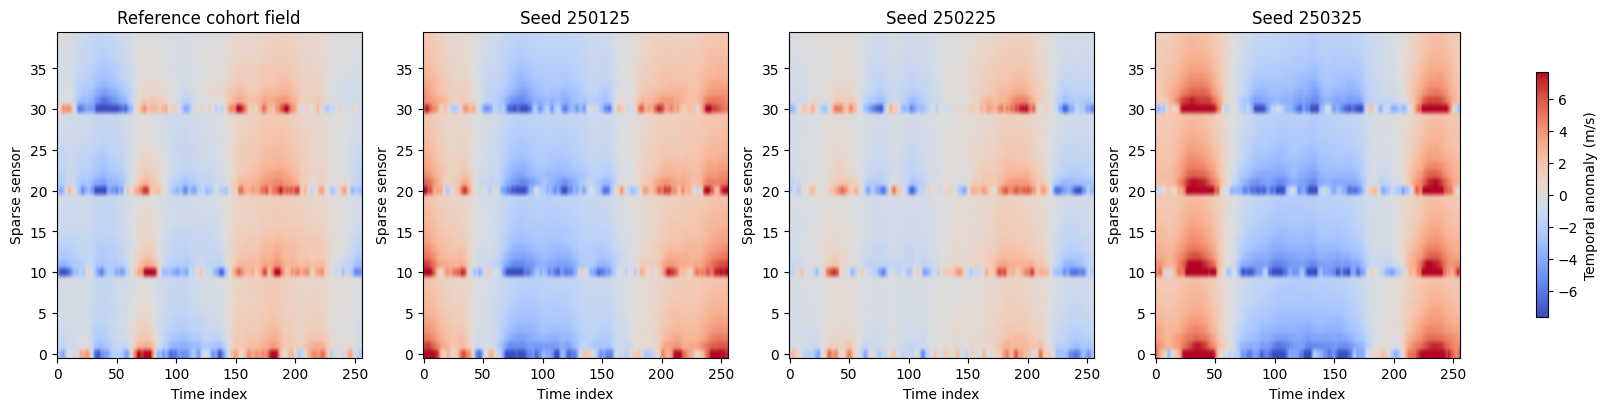


P25 — PORTABLE GENERATOR + THREE FRESH-SEED ENSEMBLES
Package reproducibility: EXACT
Fixed P24 low-band gain: 1.303591
Training/reference temporal variance ratio: 1.0089

Seed 250125, 64 fresh fields:
  Temporal variance / training: 0.816x -> 1.305x
  Total between-field / training: 1.039x
  Static/dynamic between-field / training: 0.895x / 1.285x
  Band energy ratios to training (low/mid/high): [1.349, 0.983, 0.964]
  Adjacent correlation: 0.98618 vs training 0.98516
  p99 increment: 1.155 m/s vs training 1.190
  Velocity range m/s: [2.2355563587826293, 48.069494066323216]
  Fraction outside normalization interval: 0.00108

Seed 250225, 64 fresh fields:
  Temporal variance / training: 0.626x -> 0.980x
  Total between-field / training: 0.930x
  Static/dynamic between-field / training: 0.908x / 0.967x
  Band energy ratios to training (low/mid/high): [0.977, 1.0, 1.005]
  Adjacent correlation: 0.98429 vs training 0.98516
  p99 increment: 1.167 m/s vs training 1.190
  Velocity range m/s:

In [43]:

# CELL P25 — Package/replay full statistical sampler and evaluate fresh seeds.
# Paste BELOW P24. No neural training, no test HDF5, no NASA edits.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, sys, uuid, importlib.util
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
P7 = BASE/'controlled_vae_ablations/deterministic_replication_20261030T024339Z_c746ee'
P17 = BASE/'fidelity_diagnostics/p17_spectral_head_20261030T034044Z_1464ad'
P18 = BASE/'fidelity_diagnostics/p18_linear_adapter_958d60a71ba5d6df'
P21 = BASE/'fidelity_diagnostics/p21_spectral_residual_20261030T125113Z_72f1f8'
P24 = BASE/'fidelity_diagnostics/p24_training_only_lowband_calibration_20261030T131022Z_363452'
assert callable(globals().get('note')), 'Activate corrected P1 first.'
assert callable(globals().get('verify')), 'Activate corrected P1 first.'
assert torch.cuda.is_available(), 'Use existing NVIDIA CUDA runtime.'
for path in (P7/'repeat_A_control_final.pt', P17/'result.json',
             P18/'linear_fourier_adapter.npz', P21/'result.json',
             P21/'generated_fields.npz', P24/'result.json'):
    assert path.is_file(), f'Missing prior artifact: {path}'

p17 = json.loads((P17/'result.json').read_text())
p21 = json.loads((P21/'result.json').read_text())
p24 = json.loads((P24/'result.json').read_text())
assert p17['status'] == 'completed'
assert p21['experiment'] == 'P21_training_fitted_stochastic_high_frequency_residual'
assert p24['experiment'] == 'P24_training_only_low_frequency_amplitude_calibration'
assert p21['training_indices'] == p17['split']['training_indices'] == p24['training_indices']
assert len(p17['split']['training_indices']) == 256
LOW_GAIN = float(p24['gain'])  # FIXED FROM P24: never tuned on P25 evaluations.
SHRINK = float(p21['residual_covariance_shrinkage'])
assert 0 < LOW_GAIN < 10 and np.isclose(SHRINK, .15)

RUN = BASE/'fidelity_diagnostics'/(
    'p25_reusable_generator_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6]
)
RUN.mkdir(parents=True, exist_ok=False)
PACKAGE = RUN/'statistical_wind_generator.npz'
SOURCE = RUN/'statistical_wind_generator.py'
RESULT = RUN/'result.json'
FIG = RUN/'multi_seed_generation.png'

def sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8*1024*1024), b''):
            h.update(block)
    return h.hexdigest()

# 1. Read P17 training fields and exact frozen control-encoder latents.
sys.path[:0] = ['/content', '/content/nasa_clfm_reference']
import wind_vision_physicsnemo_day1 as w
assert sha(w.__file__) == p17['source_sha256'], 'Live source differs from P17.'
_, train_file = w.assert_environment()
_,_,_,_,_,DataCls,LossCls,_,_ = w.prepare_reference_imports()
dataset, _ = w.make_loss_and_data(train_file, DataCls, LossCls)
dataset.points = dataset.points.float()
assert len(dataset.sensor_idx) == 40
training_ids = np.asarray(p17['split']['training_indices'], dtype=np.int64)

state = torch.load(P7/'repeat_A_control_final.pt', map_location='cpu', weights_only=True)
assert state['strict_deterministic'] and state['steps'] == 80
model = w.PhysicsNeMoWindVAE(
    num_sensors=40, latent_dim=128,
    grid_low=dataset.grid.low.cpu().tolist(),
    grid_high=dataset.grid.high.cpu().tolist(),
    p_deeponet=512, h_branch=128, h_trunk=128,
    nhl_branch=2, nhl_trunk=2, num_fields=1
).cuda().float().eval()
model.load_state_dict(state['state_dict'], strict=True)
model.requires_grad_(False)
raw, latents = [], []
with torch.inference_mode():
    for pos in range(0, len(training_ids), 8):
        uu = torch.stack([dataset[int(i)][0] for i in training_ids[pos:pos+8]]).float()
        mu,_ = model.encode(uu.cuda())
        raw.append(uu.numpy())
        latents.append(mu.cpu().numpy())
training = np.concatenate(raw).astype(np.float64)
Z = np.concatenate(latents).astype(np.float64)
del model
assert training.shape == (256,40,256) and Z.shape == (256,128)
assert np.isfinite(training).all() and np.isfinite(Z).all()

with np.load(P18/'linear_fourier_adapter.npz', allow_pickle=False) as a:
    adapter = {key: np.array(a[key]) for key in a.files}
assert np.allclose(adapter['feature_mean'],Z.mean(0),atol=1e-7,rtol=1e-5)
assert np.allclose(adapter['feature_scale'],np.maximum(Z.std(0),1e-5),atol=1e-7,rtol=1e-5)
assert adapter['weights'].shape == (129,480) and adapter['basis'].shape == (12,256)

# 2. Fit all sampler parameters ON THE P17 TRAINING COHORT ONLY.
# PCA of adapter-standardized posterior means (P20 rank 32).
standard = (Z-adapter['feature_mean'])/adapter['feature_scale']
latent_center = standard.mean(0)
_, latent_sv, latent_vh = np.linalg.svd(standard-latent_center,full_matrices=False)
# Spatial PCA of field-mean profiles (P23 rank 32).
profiles = training.mean(-1)
static_center = profiles.mean(0)
_, static_sv, static_vh = np.linalg.svd(profiles-static_center,full_matrices=False)
# P21 joint real/imag frequency-Gaussian: independent frequencies, correlated sensors.
freq = np.fft.rfft(training-training.mean(-1,keepdims=True),axis=-1)
high_means = np.zeros((122,80), dtype=np.float64)
high_cholesky = np.zeros((122,80,80), dtype=np.float64)
high_dims = np.full(122,80,dtype=np.int64)
for j,k in enumerate(range(7,129)):
    coeff = freq[:,:,k]
    values = coeff.real if k==128 else np.concatenate([coeff.real,coeff.imag],axis=1)
    d = values.shape[1]
    mean = values.mean(0)
    covariance = np.atleast_2d(np.cov(values,rowvar=False,ddof=1))
    diag = np.maximum(np.diag(covariance),0)
    cov = (1-SHRINK)*covariance + SHRINK*np.diag(diag)
    jitter = max(float(diag.max()),1.0)*1e-12
    high_means[j,:d] = mean
    high_cholesky[j,:d,:d] = np.linalg.cholesky(cov+jitter*np.eye(d))
    high_dims[j] = d
assert high_dims[-1]==40

np.savez_compressed(
    PACKAGE,
    latent_center=latent_center,
    latent_singular=latent_sv[:32], latent_vectors=latent_vh[:32],
    static_center=static_center,
    static_singular=static_sv[:32], static_vectors=static_vh[:32],
    high_means=high_means, high_cholesky=high_cholesky, high_dims=high_dims,
    feature_mean=adapter['feature_mean'],feature_scale=adapter['feature_scale'],
    adapter_weights=adapter['weights'], coefficient_scale=adapter['coefficient_scale'],
    basis=adapter['basis'], low_gain=np.array(LOW_GAIN),
    n_fit=np.array(len(training_ids)), shrinkage=np.array(SHRINK)
)

# 3. Write STANDALONE NumPy generation implementation, with no Colab dependencies.
standalone_code = r'''"""Statistical wind baseline from P25. Training data and CUDA NOT required for sampling.
Input: saved .npz model package, desired sample count and random seed.
Output: normalized wind fields [n,40,256]. Physical m/s = normalized*49-2.
Not a calibrated physics simulator; frequency bands and static/dynamic factors are independent.
"""
import numpy as np

def generate(model_npz, n=64, seed=20261030, calibrated=True):
    if int(n)<1:
        raise ValueError('n must be >=1')
    with np.load(model_npz,allow_pickle=False) as p:
        p = {k:np.array(p[k]) for k in p.files}
    m = int(p['n_fit'])
    # Independent seeded streams, so each component can be audited.
    rlatent = np.random.default_rng(int(seed)+1001)
    rstatic = np.random.default_rng(int(seed)+2001)
    rhigh = np.random.default_rng(int(seed)+3001)
    latent_score = p['latent_center'] + (
        (rlatent.standard_normal((n,32)) * p['latent_singular'][None,:]
         / np.sqrt(m-1)) @ p['latent_vectors'])
    z = p['feature_mean'] + latent_score*p['feature_scale']
    x = (z-p['feature_mean'])/p['feature_scale']
    design = np.concatenate((np.ones((n,1)),x),axis=1)
    coeff = (design@p['adapter_weights']).reshape(n,40,12)*float(p['coefficient_scale'])
    low = np.einsum('nsk,kt->nst',coeff,p['basis'],optimize=True)
    if calibrated:
        low = low*float(p['low_gain'])
    profile = p['static_center'] + (
        (rstatic.standard_normal((n,32))*p['static_singular'][None,:]
         /np.sqrt(m-1)) @ p['static_vectors'])
    fourier = np.zeros((n,40,129),dtype=np.complex128)
    for j,k in enumerate(range(7,129)):
        d = int(p['high_dims'][j])
        values = p['high_means'][j,:d] + (
            rhigh.standard_normal((n,d)) @ p['high_cholesky'][j,:d,:d].T)
        if k==128:
            fourier[:,:,k] = values
        else:
            fourier[:,:,k] = values[:,:40]+1j*values[:,40:]
    high = np.fft.irfft(fourier,n=256,axis=-1)
    return profile[:,:,None]+low+high
'''
SOURCE.write_text(standalone_code)
compile(standalone_code,str(SOURCE),'exec')
spec = importlib.util.spec_from_file_location('p25_statistical_wind_sampler',SOURCE)
sampler = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sampler)
assert np.array_equal(sampler.generate(PACKAGE,2,999),sampler.generate(PACKAGE,2,999)), 'Sampler repeat mismatch'

# 4. Compare THREE FRESH independent 64-field ensembles.
with np.load(P21/'generated_fields.npz',allow_pickle=False) as a:
    reference = np.asarray(a['reference'],dtype=np.float64)
assert reference.shape==(32,40,256)

def summarize(a):
    a=np.asarray(a,dtype=np.float64)
    m=a.mean(-1,keepdims=True); d=a-m
    psd=np.abs(np.fft.rfft(d,axis=-1))**2
    ix=np.array([i for i in range(39) if i%10!=9])
    left,right=d[:,ix],d[:,ix+1]
    den=np.sqrt((left**2).mean(-1)*(right**2).mean(-1))
    cor=np.divide((left*right).mean(-1),den,out=np.zeros_like(den),where=den>1e-14)
    physical=a*49-2
    return {
        'temporal_variance':float((d*d).mean()),
        'total_between_field_variance':float(a.var(0).mean()),
        'static_between_field_variance':float(m.var(0).mean()),
        'dynamic_between_field_variance':float(d.var(0).mean()),
        'low_psd_1_6':float(psd[...,1:7].mean()),
        'mid_psd_7_16':float(psd[...,7:17].mean()),
        'high_psd_17_64':float(psd[...,17:65].mean()),
        'upper_psd_65_128':float(psd[...,65:129].mean()),
        'adjacent_sensor_correlation':float(cor[den>1e-14].mean()),
        'p99_increment_m_s':float(np.quantile(np.abs(np.diff(a,axis=-1))*49,.99)),
        'range_m_s':[float(physical.min()),float(physical.max())],
        'fraction_outside_minus2_to47':float(((physical < -2)|(physical>47)).mean())
    }

train_stats = summarize(training)
ref_stats = summarize(reference)
keys = ('temporal_variance','total_between_field_variance','static_between_field_variance',
        'dynamic_between_field_variance','low_psd_1_6','mid_psd_7_16','high_psd_17_64',
        'upper_psd_65_128')
seeds = (250125,250225,250325)
ensembles={}
raw_samples={}
for seed in seeds:
    uncal = sampler.generate(PACKAGE,64,seed,calibrated=False)
    calibrated = sampler.generate(PACKAGE,64,seed,calibrated=True)
    assert uncal.shape==calibrated.shape==(64,40,256)
    assert np.isfinite(calibrated).all()
    # Verify calibration modifies only Fourier bins 1..6; no DC or high-band changes.
    F0,F1=np.fft.rfft(uncal,axis=-1),np.fft.rfft(calibrated,axis=-1)
    assert np.max(np.abs(F0[...,0]-F1[...,0]))<1e-8
    assert np.max(np.abs(F0[...,7:]-F1[...,7:]))<1e-8
    assert np.max(np.abs(F1[...,1:7]-LOW_GAIN*F0[...,1:7]))<1e-8
    ensembles[str(seed)]={}
    for label,arr in (('uncalibrated',uncal),('calibrated',calibrated)):
        st=summarize(arr)
        st['ratios_to_training']={k:st[k]/max(train_stats[k],1e-20) for k in keys}
        st['ratios_to_reference']={k:st[k]/max(ref_stats[k],1e-20) for k in keys}
        ensembles[str(seed)][label]=st
        raw_samples[f'seed{seed}_{label}']=arr.astype(np.float32)

SAMPLES=RUN/'fresh_seed_fields.npz'
np.savez_compressed(SAMPLES,**raw_samples)

# 5. Preserve auditable model, model-selection caveats and outcomes.
report = {
    'experiment':'P25_portable_hybrid_generator_multiseed_replay',
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'status':'completed',
    'training_indices':training_ids.tolist(),
    'source_sha256':sha(w.__file__),
    'input_sha256':{'P17_result':sha(P17/'result.json'),
                    'P18_fourier_adapter':sha(P18/'linear_fourier_adapter.npz'),
                    'P21_result':sha(P21/'result.json'),
                    'P24_result':sha(P24/'result.json')},
    'package_sha256':sha(PACKAGE),
    'standalone_source_sha256':sha(SOURCE),
    'sampler':{
        'n_fit':256,'latent_PCA_rank':32,'static_PCA_rank':32,
        'high_freq_bins':[7,128], 'covariance_shrinkage':SHRINK,
        'low_freq_bins':[1,6],'fixed_P24_gain':LOW_GAIN,
        'repeated_seed_exact':True,'seeds':list(seeds),'fields_per_seed':64,
        'no_field_clipping':True,
        'independence_assumptions':'latent, static profile and high-band residual drawn independently; high-frequency bins independently sampled'
    },
    'training_stats':train_stats,
    'diagnostic_reference_stats':ref_stats,
    'ensembles':ensembles,
    'limitations':[
        'All fields belong to the original VAE training population; not an independent held-out test.',
        'The P24 gain was fitted using training low-band power AND one prior 64-field generated sample; it is frozen here.',
        'High-frequency Gaussian models use training data, so training-PSD matching is partly expected.',
        'Only three 64-field ensembles. Variability across seeds is descriptive, not confidence in physical generalization.',
        'Independent static/low/high component draws omit learned conditional and cross-frequency coupling.',
        'The reference diagnostic cohort contains 32 fields and is noisy compared with 256 training fields.',
        'Out-of-normalization-interval events are not automatically physically impossible.',
        'No independent coherence criterion or downstream physical solver test.',
        'This is a composite statistical sampler, not a newly trained or converged latent flow.'
    ]
}
RESULT.write_text(json.dumps(report,indent=2,allow_nan=False))

# Visualization: three genuinely fresh generated seeds against training-population reference.
fig,axs=plt.subplots(1,4,figsize=(16,4),constrained_layout=True)
show=[('Reference cohort field',reference[0])]+[(f'Seed {s}',raw_samples[f'seed{s}_calibrated'][0]) for s in seeds]
anomaly0=reference[0]-reference[0].mean(-1,keepdims=True)
lim=max(float(np.quantile(np.abs(anomaly0*49),.995)),1e-6)
for ax,(name,a) in zip(axs,show):
    d=a-a.mean(-1,keepdims=True)
    im=ax.imshow(d*49,cmap='coolwarm',origin='lower',aspect='auto',vmin=-lim,vmax=lim)
    ax.set_title(name);ax.set_xlabel('Time index');ax.set_ylabel('Sparse sensor')
fig.colorbar(im,ax=axs,shrink=.75,label='Temporal anomaly (m/s)')
fig.savefig(FIG,dpi=160)
display(fig)
plt.close(fig)

print('\n'+'='*74)
print('P25 — PORTABLE GENERATOR + THREE FRESH-SEED ENSEMBLES')
print('='*74)
print('Package reproducibility: EXACT')
print('Fixed P24 low-band gain:',round(LOW_GAIN,6))
print('Training/reference temporal variance ratio:',round(train_stats['temporal_variance']/ref_stats['temporal_variance'],4))
for seed,arms in ensembles.items():
    before=arms['uncalibrated']
    after=arms['calibrated']
    ratio=after['ratios_to_training']
    print(f'\nSeed {seed}, 64 fresh fields:')
    print('  Temporal variance / training: %.3fx -> %.3fx'%(before['ratios_to_training']['temporal_variance'],ratio['temporal_variance']))
    print('  Total between-field / training: %.3fx'%ratio['total_between_field_variance'])
    print('  Static/dynamic between-field / training: %.3fx / %.3fx'%(
        ratio['static_between_field_variance'],ratio['dynamic_between_field_variance']))
    print('  Band energy ratios to training (low/mid/high):',
          [round(ratio[k],3) for k in ('low_psd_1_6','mid_psd_7_16','high_psd_17_64')])
    print('  Adjacent correlation: %.5f vs training %.5f'%(
        after['adjacent_sensor_correlation'],train_stats['adjacent_sensor_correlation']))
    print('  p99 increment: %.3f m/s vs training %.3f'%(
        after['p99_increment_m_s'],train_stats['p99_increment_m_s']))
    print('  Velocity range m/s:',after['range_m_s'])
    print('  Fraction outside normalization interval:',round(after['fraction_outside_minus2_to47'],6))
print('\nSaved package:',PACKAGE)
print('Standalone sampler:',SOURCE)
print('Saved per-seed fields:',SAMPLES)
print('Report:',RESULT)

note(
    title='P25: Portable hybrid statistical wind sampler and new-seed robustness',
    question='Do P20-P24 fitted components form an independently reusable generator, and do aggregate results persist across unseen random seeds?',
    methods='Refit PCA rank-32 latent and spatial priors and frequency-wise 15%-shrunken joint Gaussian Fourier residual on the identical P17 256-field training split; package P18 Fourier coefficients and frozen P24 gain. Generate three new 64-field ensembles with standalone NumPy and check exact replay, spectrum, variance, spatial correlation, physical ranges and seed sensitivity.',
    evidence=[str(PACKAGE),str(SOURCE),str(RESULT),str(SAMPLES),str(FIG)],
    findings={'training_reference':train_stats,'sample_ensembles':ensembles},
    limitations=report['limitations'],
    decision='Compare all fresh seeds to both 256 training and 32 diagnostic reference; retain this sampler as a statistical baseline only. Seek truly independent holdout and physical-validation criteria next.'
)
print('Archive verified:',verify())
print('CELL P25 COMPLETE — NO NEURAL RETRAINING')


Dataset coordinate precision verified: torch.float32
Seed 1/8 | temporal 1.141x | low-band 1.161x | total between 1.232x | corr 0.98471
Seed 2/8 | temporal 1.046x | low-band 1.058x | total between 0.990x | corr 0.98510
Seed 3/8 | temporal 1.254x | low-band 1.288x | total between 0.933x | corr 0.98572
Seed 4/8 | temporal 1.111x | low-band 1.125x | total between 1.025x | corr 0.98473
Seed 5/8 | temporal 1.048x | low-band 1.052x | total between 0.959x | corr 0.98438
Seed 6/8 | temporal 1.040x | low-band 1.043x | total between 0.859x | corr 0.98410
Seed 7/8 | temporal 1.114x | low-band 1.131x | total between 1.146x | corr 0.98427
Seed 8/8 | temporal 1.240x | low-band 1.267x | total between 0.957x | corr 0.98618


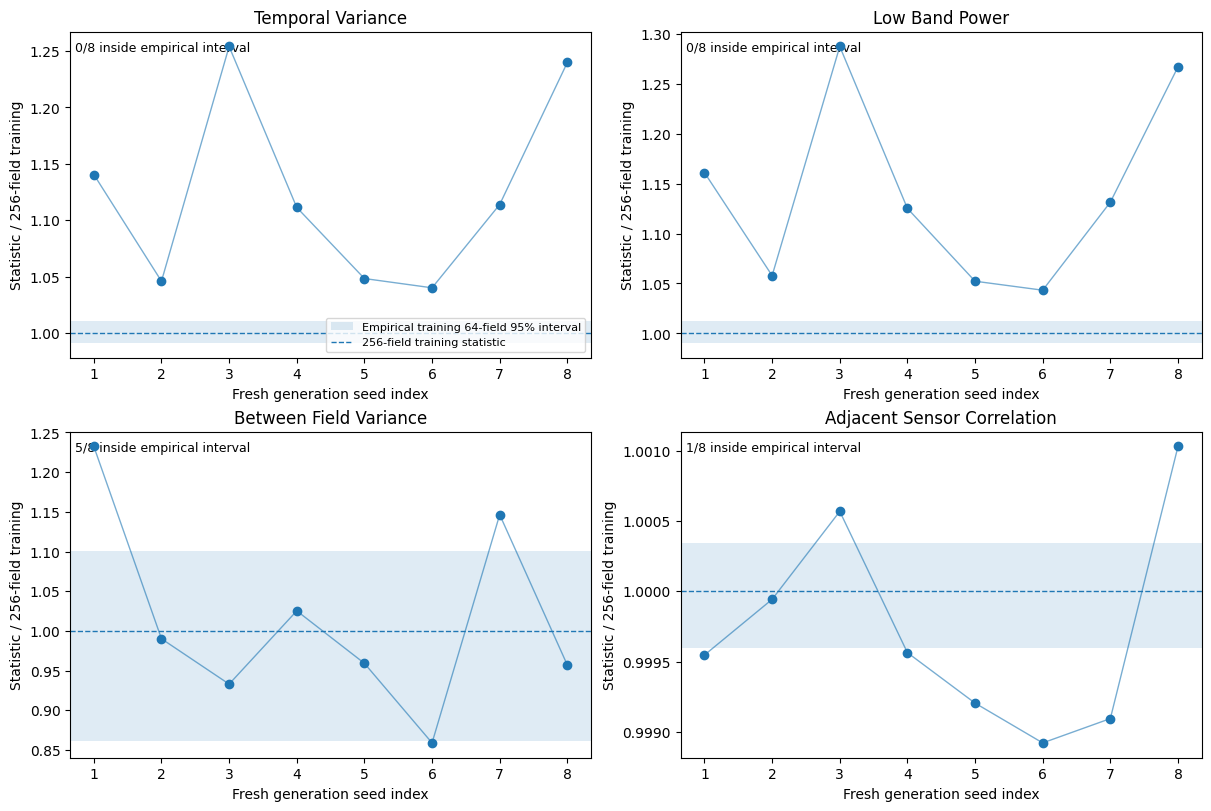


P26 — FRESH-SEED SAMPLING-UNCERTAINTY AUDIT
temporal_variance: min/median/max 1.040 / 1.113 / 1.254 | reference 95% [0.991, 1.010] | inside 0/8
low_band_power: min/median/max 1.043 / 1.128 / 1.288 | reference 95% [0.990, 1.012] | inside 0/8
between_field_variance: min/median/max 0.859 / 0.975 / 1.232 | reference 95% [0.862, 1.101] | inside 5/8
adjacent_sensor_correlation: min/median/max 0.999 / 1.000 / 1.001 | reference 95% [1.000, 1.000] | inside 1/8

Saved: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p26_sampling_audit_20261102T153130Z_fcd221/sampling_robustness.json
Presentation briefing: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p26_sampling_audit_20261102T153130Z_fcd221/JIM_NOV3_RESEARCH_BRIEF.md
Figure: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p26_sampling_audit_20261102T153130Z_fcd221/sampling_variability.png
Research archive verified: 683
CELL P26 COMPLETE 

In [44]:

# CELL P26 — Sampling-variability audit + Jim's presentation evidence brief.
# Paste below P25. No GPU, neural training, or independent-test HDF5.

from pathlib import Path
from datetime import datetime, timezone
import importlib.util, hashlib, json, uuid
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
P25 = BASE/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149'
P17 = BASE/'fidelity_diagnostics/p17_spectral_head_20261030T034044Z_1464ad'
P11 = BASE/'performance_profiling/p11_80step_equivalence_20261030T030532Z_870a7b/result.json'
P18 = BASE/'fidelity_diagnostics/p18_linear_adapter_958d60a71ba5d6df/recovery_and_evaluation.json'

assert callable(globals().get('note')), 'Run corrected Cell P1 first.'
assert callable(globals().get('verify')), 'Run corrected Cell P1 first.'

PACKAGE, SOURCE, PREVIOUS = (
    P25/'statistical_wind_generator.npz',
    P25/'statistical_wind_generator.py',
    P25/'result.json'
)

assert all(
    p.is_file()
    for p in (PACKAGE, SOURCE, PREVIOUS, P17/'result.json', P11, P18)
)

def checksum(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for data in iter(lambda: f.read(8*1024*1024), b''):
            h.update(data)
    return h.hexdigest()

p25 = json.loads(PREVIOUS.read_text())
p17 = json.loads((P17/'result.json').read_text())
p11 = json.loads(P11.read_text())
p18 = json.loads(P18.read_text())

assert p25['status'] == 'completed'
assert p17['status'] == 'completed'
assert p25['package_sha256'] == checksum(PACKAGE)
assert p25['standalone_source_sha256'] == checksum(SOURCE)
assert p11['all_updates_exact'] is True
assert p18['reloaded_adapter_matches_recomputed'] is True

train_ids = np.asarray(
    p17['split']['training_indices'],
    dtype=np.int64
)

assert train_ids.shape == (256,)
assert train_ids.tolist() == p25['training_indices']

# ------------------------------------------------------------
# 1. Load the saved generator WITHOUT refitting parameters
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    'p26_frozen_sampler',
    SOURCE
)

sampler = importlib.util.module_from_spec(spec)
spec.loader.exec_module(sampler)

assert np.array_equal(
    sampler.generate(PACKAGE, 2, 261117),
    sampler.generate(PACKAGE, 2, 261117)
)

# ------------------------------------------------------------
# 2. Load ONLY the recorded original-training fields
# ------------------------------------------------------------

import sys

sys.path[:0] = [
    '/content',
    '/content/nasa_clfm_reference'
]

import wind_vision_physicsnemo_day1 as w

assert checksum(w.__file__) == p17['source_sha256']

_, train_file = w.assert_environment()

_, _, _, _, _, DataCls, LossCls, _, _ = (
    w.prepare_reference_imports()
)

data, _ = w.make_loss_and_data(
    train_file,
    DataCls,
    LossCls
)

data.points = data.points.float()
assert len(data.sensor_idx) == 40

train = np.stack([
    data[int(i)][0].numpy()
    for i in train_ids
]).astype(np.float64)

assert train.shape == (256, 40, 256)

# ------------------------------------------------------------
# 3. Consistent metrics for real and generated ensembles
# ------------------------------------------------------------

NEIGH = np.array([
    i for i in range(39)
    if i % 10 != 9
], dtype=int)

def features(a):

    a = np.asarray(a, dtype=np.float64)

    m = a.mean(axis=-1, keepdims=True)
    d = a - m

    spectrum = np.fft.rfft(
        d,
        axis=-1
    )

    left = d[:, NEIGH]
    right = d[:, NEIGH + 1]

    denominator = np.sqrt(
        (left*left).mean(-1)
        * (right*right).mean(-1)
    )

    cc = np.divide(
        (left*right).mean(-1),
        denominator,
        out=np.zeros_like(denominator),
        where=denominator > 1e-14
    )

    valid = denominator > 1e-14
    physical = a*49 - 2

    return {
        'temporal_variance':
            float(np.mean(d*d)),

        'low_band_power':
            float(np.mean(
                np.abs(spectrum[..., 1:7])**2
            )),

        'mid_band_power':
            float(np.mean(
                np.abs(spectrum[..., 7:17])**2
            )),

        'high_band_power':
            float(np.mean(
                np.abs(spectrum[..., 17:65])**2
            )),

        'between_field_variance':
            float(np.mean(a.var(axis=0))),

        'static_between_field_variance':
            float(np.mean(m.var(axis=0))),

        'dynamic_between_field_variance':
            float(np.mean(d.var(axis=0))),

        'adjacent_sensor_correlation':
            float(cc[valid].mean()),

        'velocity_range_m_s': [
            float(physical.min()),
            float(physical.max())
        ],

        'outside_normalization_fraction':
            float(np.mean(
                (physical < -2) | (physical > 47)
            ))
    }

train_m = features(train)

# Verify that these reproduce P25's recorded
# training-population statistics.
for k in (
    'temporal_variance',
    'total_between_field_variance',
    'low_psd_1_6',
    'adjacent_sensor_correlation'
):

    actual = {
        'total_between_field_variance':
            'between_field_variance',
        'low_psd_1_6':
            'low_band_power'
    }.get(k, k)

    assert np.isclose(
        train_m[actual],
        p25['training_stats'][k],
        rtol=2e-6,
        atol=1e-12
    ), (k, train_m[actual], p25['training_stats'][k])

# ------------------------------------------------------------
# 4. Empirical 64-field reference sampling variability
# ------------------------------------------------------------

# Sampling with replacement approximates iid sampling
# from the empirical 256-field training distribution.
# This does NOT measure model-fitting uncertainty.

ref_rng = np.random.default_rng(260126)

B = 300

METRICS = (
    'temporal_variance',
    'low_band_power',
    'mid_band_power',
    'high_band_power',
    'between_field_variance',
    'static_between_field_variance',
    'dynamic_between_field_variance',
    'adjacent_sensor_correlation'
)

ref_64 = {
    m: []
    for m in METRICS
}

for _ in range(B):

    ids = ref_rng.integers(
        0,
        len(train),
        64
    )

    stat = features(train[ids])

    for metric in METRICS:

        ref_64[metric].append(
            stat[metric]
            / max(train_m[metric], 1e-20)
        )

ref_interval = {
    m: np.quantile(
        values,
        [0.025, 0.5, 0.975]
    ).tolist()
    for m, values in ref_64.items()
}

# ------------------------------------------------------------
# 5. Generate EIGHT new independent ensembles
# ------------------------------------------------------------

SEEDS = [
    260126 + i*100
    for i in range(8)
]

ensemble = []
first_example = None

for index, seed in enumerate(SEEDS):

    generated = sampler.generate(
        PACKAGE,
        n=64,
        seed=seed,
        calibrated=True
    )

    assert generated.shape == (64, 40, 256)
    assert np.isfinite(generated).all()

    if first_example is None:
        first_example = generated[:4].astype('float32')

    stat = features(generated)

    ratios = {
        k: stat[k]/max(train_m[k], 1e-20)
        for k in METRICS
    }

    ensemble.append({
        'seed': seed,
        'n_fields': 64,
        'metrics': stat,
        'ratios_to_training': ratios,

        'inside_reference_95pct_resampling_interval': {
            k: bool(
                ref_interval[k][0]
                <= ratios[k]
                <= ref_interval[k][2]
            )
            for k in METRICS
        }
    })

    print(
        'Seed %s/8 | temporal %.3fx | '
        'low-band %.3fx | total between %.3fx | '
        'corr %.5f' % (
            index+1,
            ratios['temporal_variance'],
            ratios['low_band_power'],
            ratios['between_field_variance'],
            stat['adjacent_sensor_correlation']
        ),
        flush=True
    )

# ------------------------------------------------------------
# 6. Summarize seed variation against reference variation
# ------------------------------------------------------------

summary = {}

for metric in METRICS:

    values = [
        r['ratios_to_training'][metric]
        for r in ensemble
    ]

    summary[metric] = {
        'generated_seed_min': float(min(values)),
        'generated_seed_median': float(np.median(values)),
        'generated_seed_max': float(max(values)),

        'reference_resampling_95pct_interval':
            [
                ref_interval[metric][0],
                ref_interval[metric][2]
            ],

        'seeds_inside_reference_resampling_95pct_interval':
            int(sum(
                r[
                    'inside_reference_95pct_resampling_interval'
                ][metric]
                for r in ensemble
            ))
    }

# ------------------------------------------------------------
# 7. Create a new experiment directory
# ------------------------------------------------------------

RUN = BASE/'fidelity_diagnostics'/(
    'p26_sampling_audit_'
    + datetime.now(timezone.utc).strftime(
        '%Y%m%dT%H%M%SZ'
    )
    + '_'
    + uuid.uuid4().hex[:6]
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

REPORT = RUN/'sampling_robustness.json'
FIG = RUN/'sampling_variability.png'
BRIEF = RUN/'JIM_NOV3_RESEARCH_BRIEF.md'

# Only save a small illustrative sample.
# All full ensembles can be regenerated exactly
# using the saved package, source, and seeds.
np.savez_compressed(
    RUN/'sample_fields.npz',
    first_new_seed=first_example
)

report = {
    'experiment':
        'P26_frozen_generator_sample_size_aware_reliability',

    'date_utc':
        datetime.now(timezone.utc).isoformat(),

    'status': 'completed',

    'package_sha256':
        checksum(PACKAGE),

    'generator_source_sha256':
        checksum(SOURCE),

    'source_P25':
        str(PREVIOUS),

    'P17_train_indices':
        train_ids.tolist(),

    'reference_bootstrap': {
        'count': B,
        'fields_per_replicate': 64,
        'sampling':
            'with replacement from 256 existing '
            'original-VAE training fields'
    },

    'seeds': SEEDS,
    'fields_per_seed': 64,

    'all_ensembles': ensemble,
    'training_reference': train_m,
    'summary': summary,

    'limitations': [
        'Neither the 256 training fields nor the 32-field diagnostic reference is independent of the original VAE pretraining.',
        'The reference resampling intervals are descriptive finite-sample ranges, not model-comparison significance tests or external generalization confidence intervals.',
        'Training moments were used to fit/calibrate this composite generator; in-sample moment agreement is partially expected.',
        'Eight fresh random seeds characterize sampling variability only; they do not quantify uncertainty in fitted parameters.',
        'The sampler draws static profiles, low-band latents, and high-frequency coefficients independently.',
        'The sampler has not been validated in physical solvers or against a truly untouched data domain.',
        'The [-2,47] m/s interval is the normalization convention, not a physical admissibility bound.'
    ]
}

REPORT.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False
    )
)

# ------------------------------------------------------------
# 8. Create a presentation-ready variability figure
# ------------------------------------------------------------

plot_metrics = [
    'temporal_variance',
    'low_band_power',
    'between_field_variance',
    'adjacent_sensor_correlation'
]

fig, axs = plt.subplots(
    2, 2,
    figsize=(12, 8),
    constrained_layout=True
)

for ax, key in zip(
    axs.flat,
    plot_metrics
):

    vals = np.array([
        r['ratios_to_training'][key]
        for r in ensemble
    ])

    xs = np.arange(1, len(vals)+1)

    lo, mid, hi = ref_interval[key]

    ax.axhspan(
        lo, hi,
        alpha=0.14,
        label='Empirical training 64-field 95% interval'
    )

    ax.axhline(
        1,
        ls='--',
        lw=1,
        label='256-field training statistic'
    )

    ax.scatter(
        xs, vals,
        zorder=4
    )

    ax.plot(
        xs, vals,
        lw=1,
        alpha=0.6
    )

    ax.set_title(
        key.replace('_', ' ').title()
    )

    ax.set_xlabel(
        'Fresh generation seed index'
    )

    ax.set_ylabel(
        'Statistic / 256-field training'
    )

    ax.set_xticks(xs)

    ax.text(
        0.01, 0.97,
        f'{sum((vals >= lo) & (vals <= hi))}/{len(vals)} '
        'inside empirical interval',
        transform=ax.transAxes,
        va='top',
        fontsize=9
    )

axs[0, 0].legend(
    fontsize=8,
    loc='lower right'
)

fig.savefig(
    FIG,
    dpi=160
)

display(fig)
plt.close(fig)

# ------------------------------------------------------------
# 9. Generate concise briefing from verified evidence
# ------------------------------------------------------------

speedup = float(
    p11['observed_interleaved_step_speedup']
)

linear = float(
    p18['relative_mse_reduction']
)*100

matched = int(
    p18['fields_improved_MSE_count']
)

brief = f"""# Wind VISION — Research briefing for Jim Warner

**Meeting:** Tuesday, November 3, 2026, 9:30 a.m. ET
**Status:** Exploratory research results through October 30, 2026

## 1. Validated computational result

Original NASA PyTorch versus frequency-vectorized PhysicsNeMo VAE on NVIDIA L4:

- **{speedup:.2f}×** median optimizer-step acceleration in P11.
- **All 80 updates numerically identical**, including losses, gradients, model weights, and Adam optimizer states.
- Acceleration comes from removing Python frequency-loop overhead, **not from PhysicsNeMo alone**.
- Single GPU, in-memory batches, limited benchmark; not full-epoch throughput.

## 2. Conditional reconstruction result

- Reusable, validation-selected **linear Fourier adapter**, frozen control VAE.
- **{linear:.2f}% reduction in full reconstruction MSE** on **{matched}/32** adapter-held-out examples.
- Temporal anomaly R²: **0.5308** versus **−0.0507** for the original decoder.
- These fields were held out from adapter training, but were within the original VAE training population.

## 3. Composite statistical wind sampler

- Standalone NumPy generator combining PCA latent sampling, Fourier decoding, spatial-profile PCA, and a joint Gaussian high-frequency residual.
- P24 low-band gain: **{float(p25['sampler']['fixed_P24_gain']):.5f}**, frozen for all P26 samples.
- P26: **{len(SEEDS)} new seeds × 64 fields = {len(SEEDS)*64} generated fields**.
- Compared against 300 empirical 64-field samples from the recorded 256-field training cohort.

| Metric (ratio to 256-field training) | Seed min | Median | Max | Reference 95% interval | Seeds inside |
|---|---:|---:|---:|---:|---:|
"""

for key in plot_metrics:

    st = summary[key]

    lo, hi = st[
        'reference_resampling_95pct_interval'
    ]

    brief += (
        f"| {key.replace('_', ' ')} "
        f"| {st['generated_seed_min']:.3f} "
        f"| {st['generated_seed_median']:.3f} "
        f"| {st['generated_seed_max']:.3f} "
        f"| [{lo:.3f}, {hi:.3f}] "
        f"| {st['seeds_inside_reference_resampling_95pct_interval']}/{len(SEEDS)} |\n"
    )

brief += f"""
## Limitations and next decisions

The hybrid sampler is a fitted statistical baseline, not a trained latent-flow or physically validated simulator. Independence assumptions may miss cross-frequency and static/dynamic coupling.

An untouched test dataset, physical/statistical validation across spatial separations, and an end-to-end comparison against the NASA generator remain necessary.

Do not present training-fitted spectral-power matching as independent generalization.

## Saved evidence

- P11: `{P11}`
- P18: `{P18}`
- P25: `{PREVIOUS}`
- P26: `{REPORT}`
"""

BRIEF.write_text(brief)

# ------------------------------------------------------------
# 10. Print results
# ------------------------------------------------------------

print('\n' + '='*75)
print('P26 — FRESH-SEED SAMPLING-UNCERTAINTY AUDIT')
print('='*75)

for key in plot_metrics:

    s = summary[key]
    lo, hi = s[
        'reference_resampling_95pct_interval'
    ]

    print(
        f"{key}: "
        f"min/median/max "
        f"{s['generated_seed_min']:.3f} / "
        f"{s['generated_seed_median']:.3f} / "
        f"{s['generated_seed_max']:.3f} | "
        f"reference 95% [{lo:.3f}, {hi:.3f}] | "
        f"inside "
        f"{s['seeds_inside_reference_resampling_95pct_interval']}"
        f"/{len(SEEDS)}"
    )

print('\nSaved:', REPORT)
print('Presentation briefing:', BRIEF)
print('Figure:', FIG)

# ------------------------------------------------------------
# 11. Permanent research journal and archive verification
# ------------------------------------------------------------

note(
    title=(
        'P26: Frozen composite sampler multi-seed '
        'variability and Jim meeting evidence brief'
    ),

    question=(
        'Are deviations in 64-field generation '
        'ensembles distinguishable from ordinary '
        'reference-sample variability?'
    ),

    methods=(
        'Load P25 portable model without refitting. '
        'Generate eight new 64-field ensembles with '
        'fixed calibration gain and compare against '
        '300 empirical 64-field bootstrap samples '
        'from the recorded 256-field training cohort.'
    ),

    evidence=[
        str(PACKAGE),
        str(SOURCE),
        str(REPORT),
        str(FIG),
        str(BRIEF)
    ],

    findings={
        'summary': summary,
        'seed_count': len(SEEDS),
        'speedup_P11': speedup,
        'linear_MSE_reduction_P18': linear
    },

    limitations=report['limitations'],

    decision=(
        'Evaluate seed variation relative to empirical '
        'finite-sample noise. Preserve presentation '
        'evidence with limitations. Prioritize an '
        'untouched evaluation domain before new '
        'generalization claims.'
    )
)

print(
    'Research archive verified:',
    verify()
)

print(
    'CELL P26 COMPLETE — NO TRAINING'
)


Dataset coordinate precision verified: torch.float32
1/8 seed=270127: low power old/new 1.017/0.893, temporal old/new 1.015/0.905
2/8 seed=270227: low power old/new 1.261/1.107, temporal old/new 1.231/1.096
3/8 seed=270327: low power old/new 1.221/1.072, temporal old/new 1.196/1.065
4/8 seed=270427: low power old/new 1.139/1.000, temporal old/new 1.126/1.004
5/8 seed=270527: low power old/new 1.262/1.108, temporal old/new 1.230/1.094
6/8 seed=270627: low power old/new 1.087/0.954, temporal old/new 1.076/0.960
7/8 seed=270727: low power old/new 1.329/1.167, temporal old/new 1.291/1.149
8/8 seed=270827: low power old/new 1.331/1.169, temporal old/new 1.286/1.143


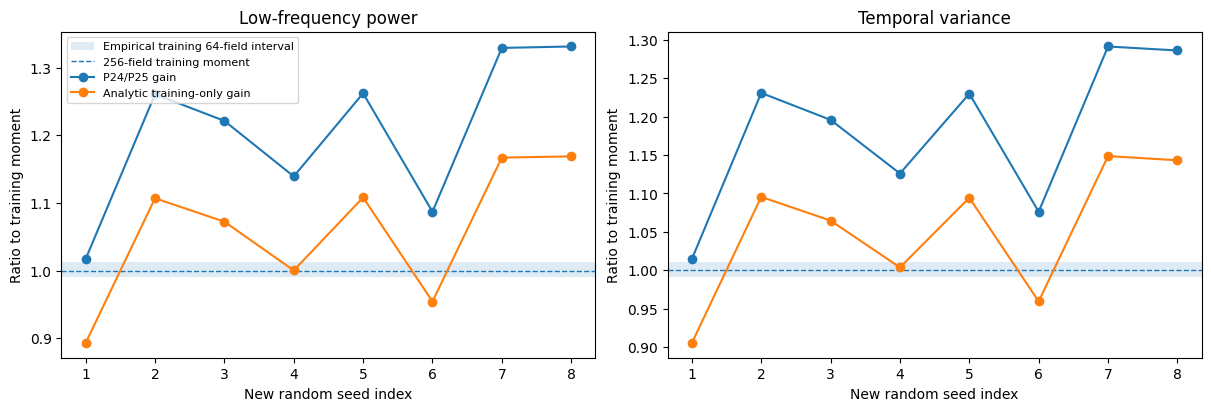


P27 — EXACT GAUSSIAN LOW-BAND EXPECTATION + FRESH-SEED TEST
Old gain: 1.303591 | Analytic train-only gain: 1.221512
Expected old-gain low power / training: 1.13891
Independent 4,096-draw check of expectation, relative error: 0.00863
Assumed (T/2)^2 coefficient convention / actual-basis expected PSD: 1.0
low_band_power: old mean=1.2060 (0/8 inside); analytic mean=1.0589 (1/8 inside); P26 ref interval=[0.9904176343106417, 1.0121237996463754]
temporal_variance: old mean=1.1814 (0/8 inside); analytic mean=1.0519 (1/8 inside); P26 ref interval=[0.9911651437715114, 1.0103595105802792]
between_field_variance: old mean=1.0976 (4/8 inside); analytic mean=1.0505 (5/8 inside); P26 ref interval=[0.861603230641847, 1.1009547658523073]
adjacent_sensor_correlation: old mean=0.9998 (3/8 inside); analytic mean=0.9986 (1/8 inside); P26 ref interval=[0.9995996124553943, 1.0003456361563234]
Per-field low-power CV: 256 training fields= 0.04246 | generated 8-seed median= 0.67022 (unaltered by scalar gain)


In [45]:
# CELL P27 (REVIEWED; NOT EXECUTED) — Analytic train-only calibration, actual-basis check, fresh-seed distribution audit
# Add below P26. No neural training, source changes, or independent-test access.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, uuid, importlib.util, shutil
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
P25 = BASE/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149'
P26 = BASE/'fidelity_diagnostics/p26_sampling_audit_20261030T132420Z_aad72b'
ORIGINAL = P25/'statistical_wind_generator.npz'
CODE = P25/'statistical_wind_generator.py'
REPORT25 = P25/'result.json'
REPORT26 = P26/'sampling_robustness.json'
assert callable(globals().get('note')), 'Activate corrected P1 first.'
assert callable(globals().get('verify')), 'Activate corrected P1 first.'
assert all(p.is_file() for p in (ORIGINAL,CODE,REPORT25,REPORT26))
p25=json.loads(REPORT25.read_text()); p26=json.loads(REPORT26.read_text())
assert p25['status']=='completed' and p26['status']=='completed'

def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''): h.update(b)
    return h.hexdigest()
assert sha(ORIGINAL)==p25['package_sha256']
assert sha(CODE)==p25['standalone_source_sha256']

# 1. Inspect the frozen package; all fitted terms are from the P17 training cohort.
with np.load(ORIGINAL,allow_pickle=False) as f:
    package={k:np.array(f[k]) for k in f.files}
assert package['latent_center'].shape==(128,)
assert package['latent_vectors'].shape==(32,128)
assert package['latent_singular'].shape==(32,)
assert package['adapter_weights'].shape==(129,480)
assert package['basis'].shape==(12,256)
assert int(package['n_fit'])==256
OLD_GAIN=float(package['low_gain'])
assert np.isclose(OLD_GAIN,float(p25['sampler']['fixed_P24_gain']))

# 2. EXACT expected band power for Gaussian PCA + the ACTUAL saved Fourier basis.
# This is deliberately basis-aware; it does not presume an unverified sine/cosine
# amplitude convention. For 40 sensors, C[40,12] @ B[12,256] is the low field.
# If C = M + sum_j eps_j L_j, then for H=rFFT(B)[:,1:7]:
# E[mean_{s,k}|(C @ H)_{s,k}|^2] =
#   (||M @ H||_F^2 + sum_j ||L_j @ H||_F^2)/(40*6).
# The expectation integrates the latent Gaussian EXACTLY; no samples used to fit.
W=np.asarray(package['adapter_weights'],dtype=np.float64)
center=np.asarray(package['latent_center'],dtype=np.float64)
scale=float(package['coefficient_scale'])
nfit=int(package['n_fit'])
mean_coeff=(scale*(W[0] + center @ W[1:])).reshape(40,12)
loadings=((package['latent_singular'][:,None]/np.sqrt(nfit-1)) *
          (package['latent_vectors'] @ W[1:]) * scale).reshape(32,40,12)
basis=np.asarray(package['basis'],dtype=np.float64)
BHAT=np.fft.rfft(basis,axis=-1)
# The P18 decoder is meant to synthesize only Fourier bins 1..6.
leak=float(np.max(np.abs(BHAT[:,np.r_[0,7:129]])))
leak_relative=float(leak/max(np.max(np.abs(BHAT[:,1:7])),1e-20))
assert leak_relative<1e-5, ('P18 basis has unexpected out-of-band power',leak_relative)
H=BHAT[:,1:7]
mu_F=mean_coeff @ H
load_F=np.einsum('jsc,ck->jsk',loadings,H,optimize=True)
EXPECTED_RAW_PSD=float((np.sum(np.abs(mu_F)**2)+
                        np.sum(np.abs(load_F)**2))/(40*6))
TRAIN_PSD=float(p25['training_stats']['low_psd_1_6'])
assert EXPECTED_RAW_PSD>0 and TRAIN_PSD>0
NEW_GAIN=float(np.sqrt(TRAIN_PSD/EXPECTED_RAW_PSD))
EXPECTED_OLD=EXPECTED_RAW_PSD*OLD_GAIN**2
assert np.isfinite(NEW_GAIN) and 0<NEW_GAIN<10

# Independent numeric check of Gaussian expectation, still NOT used to fit.
rg=np.random.default_rng(270127)
eps=rg.standard_normal((4096,32))
coeff_F=mu_F[None,:,:]+np.einsum('nj,jsk->nsk',eps,load_F,optimize=True)
mc_psd=float(np.mean(np.abs(coeff_F)**2))
mc_rel=abs(mc_psd/EXPECTED_RAW_PSD-1)
assert mc_rel<0.06, ('Unexpected analytic moment disagreement',mc_rel)
# Audit the old assumed Fourier convention; report its measured agreement.
assumed_psd=float((256/2)**2*(np.sum(mean_coeff**2)+
              np.sum(loadings**2))/(40*6))
assumed_convention_ratio=float(assumed_psd/EXPECTED_RAW_PSD)

# 3. Save NEW package without modifying the original P25 model or its results.
RUN=BASE/'fidelity_diagnostics'/('p27_analytic_lowband_calibration_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
RUN.mkdir(parents=True,exist_ok=False)
NEW_PACKAGE=RUN/'statistical_wind_generator_analytic_calibrated.npz'
NEW_CODE=RUN/'statistical_wind_generator.py'
REPORT=RUN/'result.json'; FIGURE=RUN/'analytic_calibration_fresh_seeds.png'
modified={k:v.copy() for k,v in package.items()}
modified['low_gain']=np.asarray(NEW_GAIN)
np.savez_compressed(NEW_PACKAGE,**modified)
shutil.copy2(CODE,NEW_CODE)
with np.load(NEW_PACKAGE,allow_pickle=False) as q:
    assert set(q.files)==set(package)
    assert all(np.array_equal(q[k],package[k]) for k in package if k!='low_gain')
    assert float(q['low_gain'])==NEW_GAIN
spec=importlib.util.spec_from_file_location('p27_frozen_wind_sampler',NEW_CODE)
sampler=importlib.util.module_from_spec(spec);spec.loader.exec_module(sampler)

# Applying the band multiplier in FFT space must reproduce the standalone sampler.
def apply_gain(fields,gain):
    F=np.fft.rfft(np.asarray(fields,dtype=np.float64),axis=-1)
    F[...,1:7]*=gain
    return np.fft.irfft(F,n=256,axis=-1)

probe_seed=270001
uncal_probe=sampler.generate(NEW_PACKAGE,n=4,seed=probe_seed,calibrated=False)
cal_probe=sampler.generate(NEW_PACKAGE,n=4,seed=probe_seed,calibrated=True)
assert np.allclose(cal_probe,apply_gain(uncal_probe,NEW_GAIN),atol=1e-10,rtol=1e-10)
assert np.array_equal(cal_probe,sampler.generate(NEW_PACKAGE,4,probe_seed,calibrated=True))
legacy_probe=sampler.generate(ORIGINAL,n=4,seed=probe_seed,calibrated=True)
assert np.allclose(legacy_probe,apply_gain(uncal_probe,OLD_GAIN),atol=1e-10,rtol=1e-10)
assert sha(ORIGINAL)==p25['package_sha256'], 'P25 original changed unexpectedly'


# Training-population fieldwise-power distribution, not only its mean.
# This establishes whether the Gaussian sampler has overly heavy field tails.
import sys
sys.path[:0] = ['/content','/content/nasa_clfm_reference']
import wind_vision_physicsnemo_day1 as w
assert sha(w.__file__)==p25['source_sha256'], 'Pinned source differs from P25.'
_, train_path = w.assert_environment()
_,_,_,_,_,DataCls,LossCls,_,_ = w.prepare_reference_imports()
data,_=w.make_loss_and_data(train_path,DataCls,LossCls)
data.points=data.points.float()
training_ids=np.asarray(p25['training_indices'],dtype=np.int64)
assert len(training_ids)==256 and len(set(training_ids))==256
training=np.stack([data[int(i)][0].numpy() for i in training_ids]).astype(np.float64)
assert training.shape==(256,40,256)
fft_train=np.fft.rfft(training-training.mean(-1,keepdims=True),axis=-1)
field_training_psd=np.mean(np.abs(fft_train[...,1:7])**2,axis=(1,2))
assert np.isclose(field_training_psd.mean(),TRAIN_PSD,rtol=2e-6)
TRAIN_FIELD_CV=float(field_training_psd.std(ddof=1)/field_training_psd.mean())
TRAIN_FIELD_QUANTILES=np.quantile(field_training_psd,[.1,.5,.9]).tolist()

# 4. Compare on FRESH random seeds never used for P25/P26 or gain selection.
# The P26 resampling intervals were NOT used to fit the new gain.
SEEDS=[270127+100*i for i in range(8)]
NEIGH=np.array([i for i in range(39) if i%10!=9],dtype=int)
def stats(a):
    a=np.asarray(a,dtype=np.float64)
    d=a-a.mean(-1,keepdims=True)
    F=np.fft.rfft(d,axis=-1)
    lo=np.mean(np.abs(F[...,1:7])**2,axis=(1,2))
    l,r=d[:,NEIGH],d[:,NEIGH+1]
    den=np.sqrt(np.mean(l*l,axis=-1)*np.mean(r*r,axis=-1))
    cc=np.divide(np.mean(l*r,axis=-1),den,out=np.zeros_like(den),where=den>1e-14)
    v=a*49-2
    return {
        'temporal_variance':float(np.mean(d*d)),
        'low_band_power':float(np.mean(lo)),
        'low_band_field_cv':float(lo.std(ddof=1)/max(lo.mean(),1e-20)),
        'low_band_field_p10_p50_p90':np.quantile(lo,[.1,.5,.9]).tolist(),
        'between_field_variance':float(np.mean(a.var(axis=0))),
        'adjacent_sensor_correlation':float(cc[den>1e-14].mean()),
        'outside_normalization_fraction':float(np.mean((v < -2)|(v>47))),
        'min_max_m_s':[float(v.min()),float(v.max())]
    }

# Reuse training/reference moments measured from the original 256 fields in P25.
TRAIN=p25['training_stats']
P26REF=p26['summary']
metrics_map={'temporal_variance':'temporal_variance',
             'low_band_power':'low_psd_1_6',
             'between_field_variance':'total_between_field_variance',
             'adjacent_sensor_correlation':'adjacent_sensor_correlation'}

records=[]
for i,seed in enumerate(SEEDS):
    base=sampler.generate(NEW_PACKAGE,n=64,seed=seed,calibrated=False)
    old=apply_gain(base,OLD_GAIN)
    new=apply_gain(base,NEW_GAIN)
    s_old,s_new=stats(old),stats(new)
    # Exact structural invariants: only bins 1:7 may change.
    oldF,newF=np.fft.rfft(old,axis=-1),np.fft.rfft(new,axis=-1)
    assert np.max(np.abs(oldF[...,0]-newF[...,0]))<1e-8
    assert np.max(np.abs(oldF[...,7:]-newF[...,7:]))<1e-8
    old_ratio={k:s_old[k]/TRAIN[v] for k,v in metrics_map.items()}
    new_ratio={k:s_new[k]/TRAIN[v] for k,v in metrics_map.items()}
    records.append({'seed':seed,'old':s_old,'analytic':s_new,
                    'old_ratios_to_training':old_ratio,'analytic_ratios_to_training':new_ratio})
    print(f'{i+1}/8 seed={seed}: low power old/new {old_ratio["low_band_power"]:.3f}/{new_ratio["low_band_power"]:.3f}, '
          f'temporal old/new {old_ratio["temporal_variance"]:.3f}/{new_ratio["temporal_variance"]:.3f}',flush=True)

summary={}
for metric in metrics_map:
    lim=P26REF[metric]['reference_resampling_95pct_interval']
    cases={}
    for name in ('old','analytic'):
        key=f'{name}_ratios_to_training' if name=='old' else 'analytic_ratios_to_training'
        vals=np.asarray([r[key][metric] for r in records])
        cases[name]={'min':float(vals.min()),'median':float(np.median(vals)),
                     'mean':float(vals.mean()),'max':float(vals.max()),
                     'ensembles_inside_P26_empirical_interval':int(((vals>=lim[0])&(vals<=lim[1])).sum())}
    summary[metric]={'P26_reference_95pct_interval':lim,**cases}

# Fieldwise variability is NOT repaired by a scalar gain (CV is scale-invariant).
old_cvs=[r['old']['low_band_field_cv'] for r in records]
new_cvs=[r['analytic']['low_band_field_cv'] for r in records]
assert np.allclose(old_cvs,new_cvs,rtol=1e-10,atol=1e-10)

report={
    'experiment':'P27_training_only_analytic_Gaussian_Fourier_moment_calibration',
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'status':'completed',
    'old_package':str(ORIGINAL), 'old_package_sha256':sha(ORIGINAL),
    'new_package':str(NEW_PACKAGE),'new_package_sha256':sha(NEW_PACKAGE),
    'sampler_code':str(NEW_CODE),'sampler_code_sha256':sha(NEW_CODE),
    'training_target_low_psd':TRAIN_PSD,
    'training_field_low_power_cv':TRAIN_FIELD_CV,
    'training_field_low_power_p10_p50_p90':TRAIN_FIELD_QUANTILES,
    'analytic_expected_raw_low_psd':EXPECTED_RAW_PSD,
    'analytic_expected_old_gain_low_psd_ratio_to_training':EXPECTED_OLD/TRAIN_PSD,
    'old_gain':OLD_GAIN,'analytic_gain':NEW_GAIN,
    'analytic_formula':'For H=rFFT(saved_basis)[:,1:7], E[mean_{sensor,frequency}|C@H|^2] = (||M@H||_F^2 + sum_j||L_j@H||_F^2)/(40*6)',
    'old_assumed_T_over_2_coefficient_convention_ratio':assumed_convention_ratio,
    'basis_out_of_band_fft_max':leak,
    'basis_out_of_band_relative':leak_relative,
    'independent_coeff_MC_relative_error':mc_rel,
    'new_validation_seeds':SEEDS,'new_fields_per_seed':64,
    'P26_intervals_reused_for_diagnostic_comparison_not_fitting':True,
    'results_by_seed':records,'summary':summary,
    'limits':[
        'Analytic expected-power calibration fixes the ensemble mean under the fitted Gaussian-linear model, not the distribution of fieldwise energy.',
        'A scalar gain cannot change per-field low-band power coefficient of variation or higher-order temporal structures, irrespective of whether CV is excessive.',
        'The optimization hypothesis was motivated by P26 failures; these are new seeds but not independent data or a blinded study.',
        'The training cohort was seen by the original VAE; P26 empirical intervals are descriptive and may not represent independent wind regimes.',
        'Static, latent and high-frequency components remain sampled independently; external generalization and physical coherence are unvalidated.',
        'P25 source code is unchanged, and the original P25 package remains untouched.'
    ]
}
REPORT.write_text(json.dumps(report,indent=2,allow_nan=False))

fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,metric,title in zip(axs,('low_band_power','temporal_variance'),('Low-frequency power','Temporal variance')):
    bounds=summary[metric]['P26_reference_95pct_interval']
    ax.axhspan(*bounds,alpha=.14,label='Empirical training 64-field interval')
    ax.axhline(1,ls='--',lw=1,label='256-field training moment')
    for name,label in (('old','P24/P25 gain'),('analytic','Analytic training-only gain')):
        key='old_ratios_to_training' if name=='old' else 'analytic_ratios_to_training'
        vals=[r[key][metric] for r in records]
        ax.plot(range(1,9),vals,'o-',label=label)
    ax.set_title(title);ax.set_xlabel('New random seed index');ax.set_ylabel('Ratio to training moment')
    ax.set_xticks(range(1,9))
axs[0].legend(fontsize=8)
fig.savefig(FIGURE,dpi=160);display(fig);plt.close(fig)

print('\n'+'='*74)
print('P27 — EXACT GAUSSIAN LOW-BAND EXPECTATION + FRESH-SEED TEST')
print('='*74)
print('Old gain:',round(OLD_GAIN,6),'| Analytic train-only gain:',round(NEW_GAIN,6))
print('Expected old-gain low power / training:',round(EXPECTED_OLD/TRAIN_PSD,5))
print('Independent 4,096-draw check of expectation, relative error:',round(mc_rel,5))
print('Assumed (T/2)^2 coefficient convention / actual-basis expected PSD:',round(assumed_convention_ratio,8))
for metric in ('low_band_power','temporal_variance','between_field_variance','adjacent_sensor_correlation'):
    v=summary[metric]
    print(f'{metric}: old mean={v["old"]["mean"]:.4f} ({v["old"]["ensembles_inside_P26_empirical_interval"]}/8 inside); '
          f'analytic mean={v["analytic"]["mean"]:.4f} ({v["analytic"]["ensembles_inside_P26_empirical_interval"]}/8 inside); '
          f'P26 ref interval={v["P26_reference_95pct_interval"]}')
print('Per-field low-power CV: 256 training fields=',round(TRAIN_FIELD_CV,5),
      '| generated 8-seed median=',round(float(np.median(new_cvs)),5),
      '(unaltered by scalar gain)')
print('Original P25 package: unchanged' if sha(ORIGINAL)==p25['package_sha256'] else 'ERROR: P25 hash mismatch')
print('New standalone package:',NEW_PACKAGE)
print('Sampling script:',NEW_CODE)
print('Report:',REPORT)

note(title='P27: Analytical population-moment calibration of the frozen Gaussian Fourier sampler',
     question='Does replacing a single 64-field calibration draw with the exact expected power of the Gaussian-linear model reduce systematic low-band overcalibration across new seeds?',
     methods='Calculate the closed-form expected low-band squared Fourier amplitude from frozen rank-32 Gaussian PCA parameters and linear head. Derive gain from P25 recorded 256-field training statistic only. Save a new model package, keep P25 untouched; evaluate 8 fresh 64-field seeds, band preservation and per-field power CV against P26 empirical reference intervals.',
     evidence=[str(REPORT),str(NEW_PACKAGE),str(NEW_CODE),str(FIGURE)],
     findings={'old_gain':OLD_GAIN,'new_gain':NEW_GAIN,'analytic_expected_old_gain_ratio':EXPECTED_OLD/TRAIN_PSD,'summary':summary,'per_field_low_band_CV_median':float(np.median(new_cvs)),'training_field_CV':TRAIN_FIELD_CV},
     limitations=report['limits'],
     decision='Use analytically normalized model as a new candidate if bias decreases; evaluate the distribution of per-field energies separately. Do not claim independence, physical validation or corrected tails from first-moment matching.')
print('Research archive verified:',verify())
print('CELL P27 COMPLETE — NO TRAINING')


Dataset coordinate precision verified: torch.float32
1/8 seed=280128: low-power mean original/counterfactual 1.172/1.001; field CV 0.623/0.034
2/8 seed=280228: low-power mean original/counterfactual 0.972/0.997; field CV 0.636/0.049
3/8 seed=280328: low-power mean original/counterfactual 0.981/1.004; field CV 0.708/0.041
4/8 seed=280428: low-power mean original/counterfactual 0.980/0.989; field CV 0.585/0.041
5/8 seed=280528: low-power mean original/counterfactual 0.814/1.004; field CV 0.692/0.037
6/8 seed=280628: low-power mean original/counterfactual 1.089/1.000; field CV 0.632/0.040
7/8 seed=280728: low-power mean original/counterfactual 1.103/1.005; field CV 0.677/0.036
8/8 seed=280828: low-power mean original/counterfactual 1.116/0.986; field CV 0.605/0.043


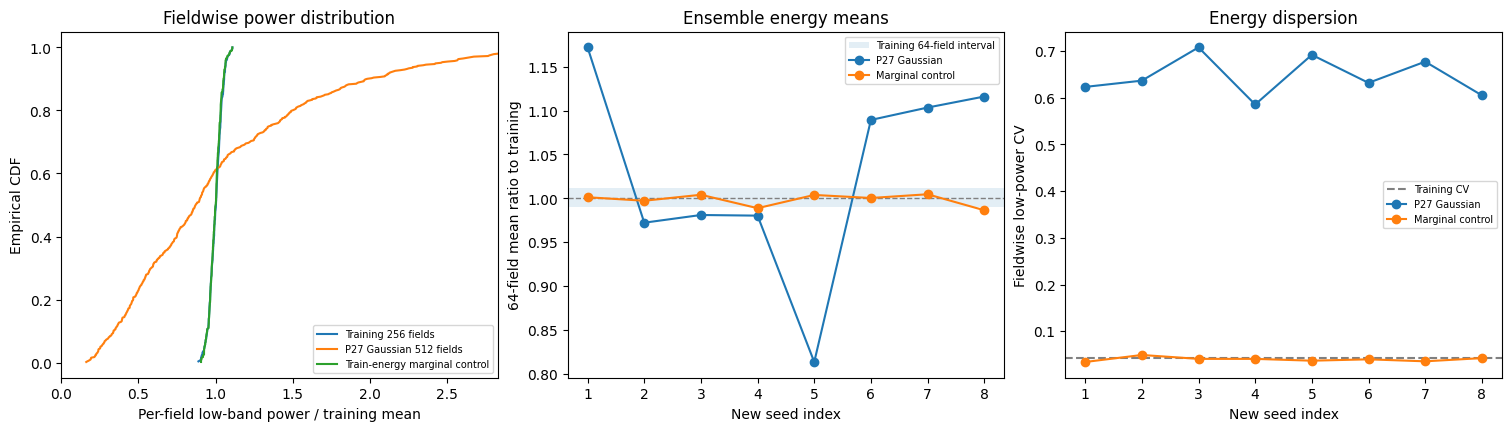


P28 — EXACT GAUSSIAN ENERGY DISPERSION / MARGINAL COUNTERFACTUAL
TRAINING fieldwise low PSD CV: 0.042459
GAUSSIAN theory fieldwise low PSD CV: 0.687831
GAUSSIAN 512-field observed CV: 0.649915 | x training: 15.31
Variance fraction from linear cross-term: 0.0045
Approx model 64-field power mean 95% ratio band: [0.8315, 1.1685]
Training empirical 64-field 95% ratio interval: [0.9904, 1.0121]
P27 original 8-seed mean ratios and coverage: {'mean': 1.0284830207632205, 'min': 0.8136228897002034, 'max': 1.171927667826538, 'inside_train_resample_95pct': 0}
Train-energy marginal counterfactual 8-seed mean ratios and coverage: {'mean': 0.9983493280273497, 'min': 0.9864396341592022, 'max': 1.0046540303029667, 'inside_train_resample_95pct': 6}
Training lag1 / adjacent correlation: 0.990882 0.985162
p27_original : lag1/adjacent/temporal ratio/outside fraction (mean over 8)= 0.991561 0.984058 1.0237 0.000935
energy_marginal_counterfactual : lag1/adjacent/temporal ratio/outside fraction (mean over 8

In [46]:
# CELL P28 — Gaussian low-band energy dispersion: exact theory + train-only marginal counterfactual
# Paste in ONE new Colab code cell directly BELOW completed P27. Run only this cell.
# NO new model training, NO overwriting P25/P27, NO use of held-out external data.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, importlib.util, json, uuid, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
P25 = BASE/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149'
P27 = BASE/'fidelity_diagnostics/p27_analytic_lowband_calibration_20261030T140550Z_c62259'
P26 = BASE/'fidelity_diagnostics/p26_sampling_audit_20261030T132420Z_aad72b'
P25_REPORT = P25/'result.json'
P27_REPORT = P27/'result.json'
P27_PACKAGE = P27/'statistical_wind_generator_analytic_calibrated.npz'
P27_SAMPLER = P27/'statistical_wind_generator.py'
P26_REPORT = P26/'sampling_robustness.json'
assert callable(globals().get('note')) and callable(globals().get('verify')), 'Corrected P1 recorder must already be active.'
assert all(p.is_file() for p in (P25_REPORT,P27_REPORT,P27_PACKAGE,P27_SAMPLER,P26_REPORT))
p25=json.loads(P25_REPORT.read_text()); p27=json.loads(P27_REPORT.read_text()); p26=json.loads(P26_REPORT.read_text())
assert p25['status']=='completed' and p27['status']=='completed' and p26['status']=='completed'

def p28_sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''): h.update(block)
    return h.hexdigest()

ORIG_SHA=p28_sha(P25/'statistical_wind_generator.npz')
assert ORIG_SHA==p25['package_sha256'], 'P25 original changed'
assert p28_sha(P27_PACKAGE)==p27['new_package_sha256'], 'P27 package changed'
assert p28_sha(P27_SAMPLER)==p27['sampler_code_sha256'], 'P27 sampler changed'

with np.load(P27_PACKAGE,allow_pickle=False) as z:
    pkg={k:np.asarray(z[k]) for k in z.files}
assert pkg['adapter_weights'].shape==(129,480) and pkg['basis'].shape==(12,256)
assert pkg['latent_vectors'].shape==(32,128)
assert np.isclose(float(pkg['low_gain']),p27['analytic_gain'])

# Exact second moment of P = mean_{40 sensors, six FFT bins} |M + sum(epsilon_j L_j)|^2.
# For epsilon~N(0,I): E[P]=c*(||M||^2+tr Q), Var[P]=c^2*(4||r||^2+2 tr(Q^2)),
# Q_ij=Re <L_i,L_j>, r_j=Re <M,L_j>, c=1/(40*6).
W=pkg['adapter_weights'].astype(np.float64)
center=pkg['latent_center'].astype(np.float64)
scale=float(pkg['coefficient_scale']); nfit=int(pkg['n_fit'])
Bhat=np.fft.rfft(pkg['basis'].astype(np.float64),axis=-1)[:,1:7]
M=(scale*(W[0]+center@W[1:])).reshape(40,12) @ Bhat
L=((pkg['latent_singular'][:,None]/np.sqrt(nfit-1))*
   (pkg['latent_vectors']@W[1:])*scale).reshape(32,40,12)
L=np.einsum('jsc,ck->jsk',L,Bhat,optimize=True)
Q=np.real(np.einsum('jsk,isk->ji',np.conj(L),L,optimize=True))
r=np.real(np.einsum('sk,jsk->j',np.conj(M),L,optimize=True))
assert np.allclose(Q,Q.T,rtol=1e-12,atol=1e-8)
c=1/(40*6)
raw_mean=float(c*(np.sum(np.abs(M)**2)+np.trace(Q)))
raw_variance=float(c*c*(4*np.dot(r,r)+2*np.sum(Q*Q)))
assert raw_mean>0 and raw_variance>=0
CV_THEORY=float(np.sqrt(raw_variance)/raw_mean)
linear_share=float((4*np.dot(r,r))/(4*np.dot(r,r)+2*np.sum(Q*Q)))
expected_calibrated=raw_mean*float(pkg['low_gain'])**2
assert np.isclose(expected_calibrated,p27['training_target_low_psd'],rtol=1e-8)

# Reload the identical 256-field training cohort already used in P27; no test data.
sys.path[:0]=['/content','/content/nasa_clfm_reference']
import wind_vision_physicsnemo_day1 as w
assert p28_sha(w.__file__)==p25['source_sha256'], 'Pinned source mismatch'
_,train_path=w.assert_environment()
_,_,_,_,_,DataCls,LossCls,_,_=w.prepare_reference_imports()
data,_=w.make_loss_and_data(train_path,DataCls,LossCls)
data.points=data.points.float()
ids=np.asarray(p25['training_indices'],dtype=np.int64)
assert len(ids)==len(set(ids))==256
training=np.stack([data[int(i)][0].numpy() for i in ids]).astype(np.float64)
assert training.shape==(256,40,256)

NEIGH=np.array([i for i in range(39) if i%10!=9],dtype=np.int64)
def p28_field_power(fields):
    a=np.asarray(fields,dtype=np.float64)
    F=np.fft.rfft(a-a.mean(axis=-1,keepdims=True),axis=-1)
    return np.mean(np.abs(F[...,1:7])**2,axis=(1,2))

def p28_stats(fields):
    a=np.asarray(fields,dtype=np.float64)
    d=a-a.mean(-1,keepdims=True)
    p=p28_field_power(a)
    a0,b0=d[:,NEIGH],d[:,NEIGH+1]
    den=np.sqrt(np.mean(a0*a0,-1)*np.mean(b0*b0,-1))
    adj=np.divide(np.mean(a0*b0,-1),den,out=np.zeros_like(den),where=den>1e-15)
    v=a*49-2
    return {'low_power':float(p.mean()),'field_low_power_cv':float(p.std(ddof=1)/p.mean()),
            'field_low_power_p10_p50_p90':np.quantile(p,[.1,.5,.9]).tolist(),
            'temporal_variance':float(np.mean(d*d)),
            'between_field_variance':float(np.mean(a.var(axis=0))),
            'adjacent_correlation':float(np.mean(adj[den>1e-15])),
            'lag1_correlation':float(np.sum(d[...,:-1]*d[...,1:])/np.sqrt(
                np.sum(d[...,:-1]**2)*np.sum(d[...,1:]**2))),
            'outside_normalization_fraction':float(np.mean((v < -2)|(v>47))),
            'velocity_min_max_m_s':[float(v.min()),float(v.max())]}

train_p=p28_field_power(training)
train_stats=p28_stats(training)
assert np.isclose(train_p.mean(),p27['training_target_low_psd'],rtol=2e-6)
assert np.isclose(train_stats['field_low_power_cv'],p27['training_field_low_power_cv'],rtol=2e-6)

# Counterfactual ONLY: independently draw a fieldwise target PSD from the TRAINING
# empirical power marginal, and multiply every low-band FFT coefficient of that
# generated field by sqrt(target/current). All other bands, phases, and static
# profile remain unchanged. This imposes training power *by construction*; it
# is NOT a learned probabilistic or physically validated model.
def p28_energy_counterfactual(fields,targets):
    a=np.asarray(fields,dtype=np.float64)
    targets=np.asarray(targets,dtype=np.float64)
    F=np.fft.rfft(a,axis=-1)
    before=np.mean(np.abs(F[...,1:7])**2,axis=(1,2))
    assert np.all(before>1e-14) and np.all(targets>0)
    multiplier=np.sqrt(targets/before)
    F[...,1:7]*=multiplier[:,None,None]
    out=np.fft.irfft(F,n=256,axis=-1)
    after=p28_field_power(out)
    assert np.allclose(after,targets,rtol=1e-9,atol=1e-9)
    original_fft=np.fft.rfft(a,axis=-1)
    new_fft=np.fft.rfft(out,axis=-1)
    assert np.max(np.abs(new_fft[...,0]-original_fft[...,0]))<1e-8
    assert np.max(np.abs(new_fft[...,7:]-original_fft[...,7:]))<1e-8
    return out,multiplier

spec=importlib.util.spec_from_file_location('p28_frozen_p27_sampler',P27_SAMPLER)
sampler=importlib.util.module_from_spec(spec);spec.loader.exec_module(sampler)
SEEDS=[280128+100*i for i in range(8)]  # Fresh; disjoint from P25, P26, P27 checks
P26_INTERVAL=p26['summary']['low_band_power']['reference_resampling_95pct_interval']
rows=[]; all_p=[]; all_cf=[]; all_mult=[]; first_example=None
for j,seed in enumerate(SEEDS):
    original=sampler.generate(P27_PACKAGE,n=64,seed=seed,calibrated=True)
    assert original.shape==(64,40,256) and np.all(np.isfinite(original))
    # Separate seed for marginal-energy draw; never derived from generated metrics.
    target=train_p[np.random.default_rng(seed+910000).integers(0,len(train_p),size=64)]
    cf,mult=p28_energy_counterfactual(original,target)
    s0=p28_stats(original); s1=p28_stats(cf)
    rows.append({'seed':seed,'p27_original':s0,'energy_marginal_counterfactual':s1,
                 'scale_min_median_max':[float(mult.min()),float(np.median(mult)),float(mult.max())],
                 'mean_low_power_ratio_original':s0['low_power']/train_stats['low_power'],
                 'mean_low_power_ratio_counterfactual':s1['low_power']/train_stats['low_power']})
    all_p.append(p28_field_power(original));all_cf.append(p28_field_power(cf));all_mult.append(mult)
    if j==0: first_example=(original[0].copy(),cf[0].copy())
    print(f'{j+1}/8 seed={seed}: low-power mean original/counterfactual '
          f'{rows[-1]["mean_low_power_ratio_original"]:.3f}/'
          f'{rows[-1]["mean_low_power_ratio_counterfactual"]:.3f}; '
          f'field CV {s0["field_low_power_cv"]:.3f}/{s1["field_low_power_cv"]:.3f}',flush=True)
all_p=np.concatenate(all_p); all_cf=np.concatenate(all_cf); all_mult=np.concatenate(all_mult)
OBSERVED_CV=float(all_p.std(ddof=1)/all_p.mean())
CV_RATIO=float(OBSERVED_CV/train_stats['field_low_power_cv'])

# Model-predicted ensemble mean SD from 64 independent Gaussian latent draws.
# Approximate normal 95% band; unlike the narrow training empirical band, this
# is based on the generated model's much larger theoretical fieldwise variance.
MODEL_64_SD=float(CV_THEORY/np.sqrt(64))
MODEL_64_APPROX_95=[float(1-1.96*MODEL_64_SD),float(1+1.96*MODEL_64_SD)]

def p28_summarize(key):
    vals=np.array([x['mean_low_power_ratio_'+key] for x in rows])
    return {'mean':float(vals.mean()),'min':float(vals.min()),'max':float(vals.max()),
            'inside_train_resample_95pct':int(np.sum((vals>=P26_INTERVAL[0])&(vals<=P26_INTERVAL[1])))}

result={
    'experiment':'P28_exact_Gaussian_quadratic_power_variance_and_counterfactual',
    'created_utc':datetime.now(timezone.utc).isoformat(),'status':'completed',
    'parent_P27_report':str(P27_REPORT),'parent_P27_package':str(P27_PACKAGE),
    'parent_package_sha256':p28_sha(P27_PACKAGE),'parent_P25_sha256':ORIG_SHA,
    'theory':{'expected_field_low_power':float(expected_calibrated),
              'field_low_power_variance':float(raw_variance*float(pkg['low_gain'])**4),
              'predicted_field_low_power_CV':CV_THEORY,
              'linear_contribution_to_variance_fraction':linear_share,
              'predicted_64_field_mean_ratio_sd':MODEL_64_SD,
              'approx_model_64_field_mean_ratio_95pct_band':MODEL_64_APPROX_95},
    'training':train_stats,'empirical_generated_field_CV_pooled_512':OBSERVED_CV,
    'generated_to_training_field_CV_ratio':CV_RATIO,
    'original_summary':p28_summarize('original'),
    'counterfactual_summary':p28_summarize('counterfactual'),
    'P26_empirical_training_64field_95pct_interval':P26_INTERVAL,
    'fresh_seeds':SEEDS,'fields_per_seed':64,
    'per_seed':rows,
    'counterfactual_scale_p10_p50_p90':np.quantile(all_mult,[.1,.5,.9]).tolist(),
    'counterfactual_scale_min_max':[float(all_mult.min()),float(all_mult.max())],
    'limits':[
        'The Gaussian variance is exact for the fitted latent PCA + linear Fourier head; the model is not physically validated.',
        'The counterfactual draws desired energy from 256 TRAINING field powers. Low-power marginal matching is imposed by construction and is NOT evidence of generalization.',
        'The training 256 fields were seen by the original VAE; no untouched external test domain has been used.',
        'Per-field low-band amplitude scaling preserves low-band phases/within-low-band relative amplitudes but changes relationships to high band, mean profile and nonlinear temporal statistics.',
        'A 64-field model interval using 1.96 standard errors is a normal approximation, not an exact finite-sample 95% interval.',
        'No P25/P27 package, upstream code, checkpoint or previous report was edited.'
    ]
}
RUN=BASE/'fidelity_diagnostics'/('p28_energy_dispersion_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
RUN.mkdir(parents=True,exist_ok=False)
REPORT=RUN/'result.json'; FIG=RUN/'energy_dispersion_diagnostic.png'; EXAMPLES=RUN/'generated_example_pair.npz'
REPORT.write_text(json.dumps(result,indent=2,allow_nan=False))
np.savez_compressed(EXAMPLES,p27_field=first_example[0].astype(np.float32),
                    energy_counterfactual_field=first_example[1].astype(np.float32),
                    training_low_band_power=train_p.astype(np.float32),
                    fresh_generated_low_band_power=all_p.astype(np.float32),
                    counterfactual_low_band_power=all_cf.astype(np.float32))
fig,axes=plt.subplots(1,3,figsize=(15,4.2),constrained_layout=True)
for x,lab in ((train_p,'Training 256 fields'),(all_p,'P27 Gaussian 512 fields'),
              (all_cf,'Train-energy marginal control')):
    z=np.sort(x/train_p.mean())
    axes[0].plot(z,np.arange(1,len(z)+1)/len(z),label=lab)
axes[0].set(xlabel='Per-field low-band power / training mean',ylabel='Empirical CDF',title='Fieldwise power distribution')
axes[0].set_xlim(left=0,right=max(2.5,float(np.quantile(all_p/train_p.mean(),.98))))
axes[0].legend(fontsize=7)
x=np.arange(1,9)
axes[1].axhspan(*P26_INTERVAL,alpha=.12,label='Training 64-field interval')
axes[1].axhline(1,color='gray',ls='--',lw=1)
axes[1].plot(x,[v['mean_low_power_ratio_original'] for v in rows],'o-',label='P27 Gaussian')
axes[1].plot(x,[v['mean_low_power_ratio_counterfactual'] for v in rows],'o-',label='Marginal control')
axes[1].set(xlabel='New seed index',ylabel='64-field mean ratio to training',title='Ensemble energy means')
axes[1].legend(fontsize=7)
axes[2].axhline(train_stats['field_low_power_cv'],ls='--',color='gray',label='Training CV')
axes[2].plot(x,[v['p27_original']['field_low_power_cv'] for v in rows],'o-',label='P27 Gaussian')
axes[2].plot(x,[v['energy_marginal_counterfactual']['field_low_power_cv'] for v in rows],'o-',label='Marginal control')
axes[2].set(xlabel='New seed index',ylabel='Fieldwise low-power CV',title='Energy dispersion')
axes[2].legend(fontsize=7)
fig.savefig(FIG,dpi=170);display(fig);plt.close(fig)

# Archive executed notebook-cell source, when the live IPython history provides it.
source_saved=None
try:
    cell_source=get_ipython().history_manager.input_hist_raw[-1]
    if '# CELL P28' in cell_source and 'p28_energy_counterfactual' in cell_source:
        source_path=RUN/'CELL_P28_executed.py';source_path.write_text(cell_source)
        source_saved=str(source_path)
except Exception as exc:
    print('Cell source capture unavailable; live Colab notebook retains the executed cell:',repr(exc))

readme=RUN/'INTERPRETATION.md'
readme.write_text(
    '# P28: Gaussian energy dispersion and controlled marginal-power experiment\n\n'
    'The exact Gaussian quadratic-form variance is compared against an independently sampled '
    '512-field ensemble. The train-energy marginal control is an intervention: it draws individual '
    'desired low-band powers from the same 256 training fields and rescales each generated field. '
    'Marginal-power matching under this intervention is tautological, not learned-model validation. '
    'Inspect changed temporal variance, adjacent correlations, lag-one statistics, and normalization '
    'excursions before presenting it. No external held-out wind field is used.\n\n'
    f'Analytic Gaussian field-power CV: {CV_THEORY:.6f}\n\n'
    f'Training field-power CV: {train_stats["field_low_power_cv"]:.6f}\n\n'
    f'Observed 512-field Gaussian CV: {OBSERVED_CV:.6f}\n\n'
    'Do not report the control as a validated new generator.\n')

assert p28_sha(P27_PACKAGE)==p27['new_package_sha256']
assert p28_sha(P25/'statistical_wind_generator.npz')==ORIG_SHA
print('\n'+'='*75)
print('P28 — EXACT GAUSSIAN ENERGY DISPERSION / MARGINAL COUNTERFACTUAL')
print('='*75)
print('TRAINING fieldwise low PSD CV:',round(train_stats['field_low_power_cv'],6))
print('GAUSSIAN theory fieldwise low PSD CV:',round(CV_THEORY,6))
print('GAUSSIAN 512-field observed CV:',round(OBSERVED_CV,6),'| x training:',round(CV_RATIO,2))
print('Variance fraction from linear cross-term:',round(linear_share,4))
print('Approx model 64-field power mean 95% ratio band:',[round(v,4) for v in MODEL_64_APPROX_95])
print('Training empirical 64-field 95% ratio interval:',[round(v,4) for v in P26_INTERVAL])
print('P27 original 8-seed mean ratios and coverage:',result['original_summary'])
print('Train-energy marginal counterfactual 8-seed mean ratios and coverage:',result['counterfactual_summary'])
print('Training lag1 / adjacent correlation:',round(train_stats['lag1_correlation'],6),round(train_stats['adjacent_correlation'],6))
for name in ('p27_original','energy_marginal_counterfactual'):
    print(name,': lag1/adjacent/temporal ratio/outside fraction (mean over 8)=',
          round(float(np.mean([z[name]['lag1_correlation'] for z in rows])),6),
          round(float(np.mean([z[name]['adjacent_correlation'] for z in rows])),6),
          round(float(np.mean([z[name]['temporal_variance']/train_stats['temporal_variance'] for z in rows])),4),
          round(float(np.mean([z[name]['outside_normalization_fraction'] for z in rows])),6))
print('Intervention low-band scale min/median/max:',round(float(all_mult.min()),3),
      round(float(np.median(all_mult)),3),round(float(all_mult.max()),3))
print('Report:',REPORT,'\nFigure:',FIG,'\nExamples:',EXAMPLES)

evidence=[str(REPORT),str(FIG),str(EXAMPLES),str(readme)]
if source_saved: evidence.append(source_saved)
note(title='P28: Exact Gaussian low-frequency power variance and a training-only energy marginal counterfactual',
     question='Is excessive fieldwise spectral-power variability an intrinsic consequence of the Gaussian PCA + linear Fourier generator, and what does forced train-only marginal power matching change?',
     methods='Compute exact variance of noncentral Gaussian quadratic-form FFT power using frozen P27 weights. Generate 8 fresh 64-field seeds. Compare empirical fieldwise CV and 64-field means with training cohort. Separately draw train-only empirical target power and rescale low-band FFT coefficients per generated field as a clearly labeled counterfactual. Preserve all prior packages and check spectrum invariants.',
     evidence=evidence,
     findings={'theoretical_field_CV':CV_THEORY,'training_field_CV':train_stats['field_low_power_cv'],
               'empirical_generated_field_CV_512':OBSERVED_CV,
               'original_ensemble':result['original_summary'],
               'counterfactual_ensemble':result['counterfactual_summary']},
     limitations=result['limits'],
     decision='Use exact variance result as causal mathematical diagnostic. Counterfactual moment matching is by construction and must not be presented as learned or physically validated generation; next prioritize November 3 deliverables.')
print('Research archive verified:',verify())
print('CELL P28 COMPLETE — diagnostic and counterfactual only; NO TRAINING')


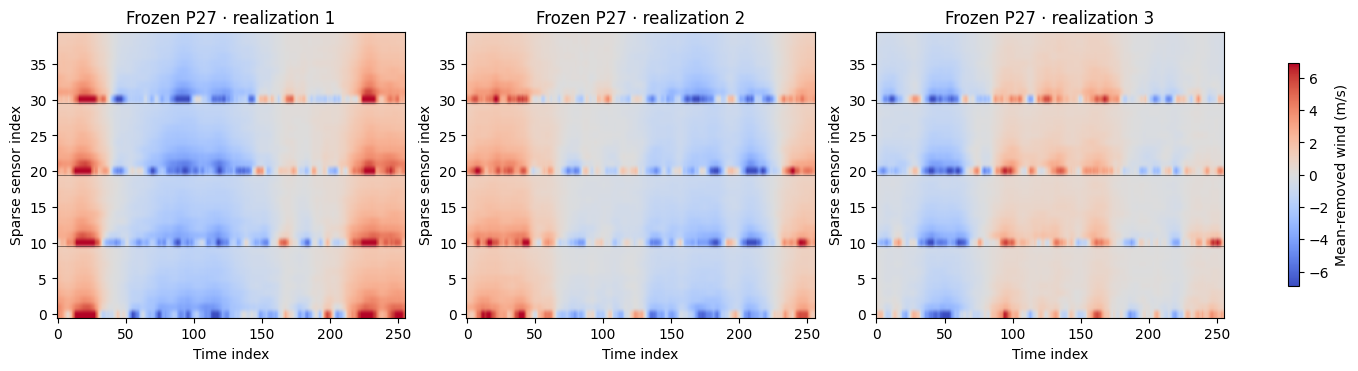


P29 — JIM NOVEMBER 3 MEETING EVIDENCE FREEZE COMPLETE
Research source JSON numeric spot-check (False means inspect source layout): {'P11_reference_median_311_475ms': True, 'P11_optimized_median_59_451ms': True, 'P18_MSE_original_0_00419854': True, 'P18_MSE_adapter_0_00342023': True}
P11 speed ratio: 5.2392 | P18 MSE reduction: 18.538 %
P28 training / theoretical Gaussian / observed generated CV: 0.042459 0.687831 0.649915
Frozen P27 demo: shape (3, 40, 256) same-seed bitwise exact: True velocity m/s min-max (5.679, 46.107)
Offline slide deck: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/meeting_deliverables/p29_jim_nov3_meeting_freeze_20261102T153201Z_509721/JIM_NOV3_OFFLINE_SLIDES.html
Technical brief: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/meeting_deliverables/p29_jim_nov3_meeting_freeze_20261102T153201Z_509721/JIM_NOV3_TECHNICAL_BRIEF.md
Evidence and source hashes: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/meeting_delivera

In [47]:
# CELL P29 — November 3 meeting evidence freeze, offline slides, and deterministic demonstration
# Paste this ENTIRE file as ONE new Colab code cell immediately BELOW completed P28.
# No training, installation, model fitting, source changes, or overwrite of prior artifacts.
from pathlib import Path
from datetime import datetime, timezone
import base64, hashlib, html, importlib.util, json, uuid, textwrap
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT29=Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
A29={
 'P11':ROOT29/'performance_profiling/p11_80step_equivalence_20261030T030532Z_870a7b/result.json',
 'P17':ROOT29/'fidelity_diagnostics/p17_spectral_head_20261030T034044Z_1464ad/result.json',
 'P18':ROOT29/'fidelity_diagnostics/p18_linear_adapter_958d60a71ba5d6df/recovery_and_evaluation.json',
 'P25':ROOT29/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json',
 'P25_MODEL':ROOT29/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/statistical_wind_generator.npz',
 'P26':ROOT29/'fidelity_diagnostics/p26_sampling_audit_20261030T132420Z_aad72b/sampling_robustness.json',
 'P27':ROOT29/'fidelity_diagnostics/p27_analytic_lowband_calibration_20261030T140550Z_c62259/result.json',
 'P27_MODEL':ROOT29/'fidelity_diagnostics/p27_analytic_lowband_calibration_20261030T140550Z_c62259/statistical_wind_generator_analytic_calibrated.npz',
 'P27_CODE':ROOT29/'fidelity_diagnostics/p27_analytic_lowband_calibration_20261030T140550Z_c62259/statistical_wind_generator.py',
 'P27_FIG':ROOT29/'fidelity_diagnostics/p27_analytic_lowband_calibration_20261030T140550Z_c62259/analytic_calibration_fresh_seeds.png',
 'P28':ROOT29/'fidelity_diagnostics/p28_energy_dispersion_20261030T141247Z_7887d4/result.json',
 'P28_FIG':ROOT29/'fidelity_diagnostics/p28_energy_dispersion_20261030T141247Z_7887d4/energy_dispersion_diagnostic.png',
 'P28_PAIRS':ROOT29/'fidelity_diagnostics/p28_energy_dispersion_20261030T141247Z_7887d4/generated_example_pair.npz',
}
assert callable(globals().get('note')) and callable(globals().get('verify')), 'Corrected scope-locked P1 recorder must already be active.'
missing=[str(p) for p in A29.values() if not p.is_file()]
assert not missing, 'Required research evidence missing; no earlier results changed:\n'+'\n'.join(missing)

def sha29(path):
 h=hashlib.sha256()
 with Path(path).open('rb') as f:
  for part in iter(lambda:f.read(4*1024*1024),b''): h.update(part)
 return h.hexdigest()

report29={k:json.loads(A29[k].read_text()) for k in ('P11','P17','P18','P25','P26','P27','P28')}
p25,p26,p27,p28=[report29[k] for k in ('P25','P26','P27','P28')]
assert p25.get('status')=='completed' and p26.get('status')=='completed'
assert p27.get('status')=='completed' and p28.get('status')=='completed'
assert sha29(A29['P25_MODEL'])==p25['package_sha256'], 'P25 has changed.'
assert sha29(A29['P27_MODEL'])==p27['new_package_sha256'], 'P27 has changed.'
assert sha29(A29['P27_CODE'])==p27['sampler_code_sha256'], 'P27 sampler has changed.'
assert p28['parent_package_sha256']==sha29(A29['P27_MODEL']), 'P28 lineage differs.'

# These headline numbers were confirmed in previously executed P11/P18 logs.
# Store a separate source spot-check rather than invent unknown JSON key paths.
def number_values29(obj):
 if isinstance(obj,dict):
  for v in obj.values(): yield from number_values29(v)
 elif isinstance(obj,list):
  for v in obj: yield from number_values29(v)
 elif isinstance(obj,(float,int)) and not isinstance(obj,bool):
  yield float(obj)

def has_number29(report,targets,rtol=0.006):
 nums=list(number_values29(report))
 return any(np.isclose(v,t,rtol=rtol,atol=1e-8) for v in nums for t in targets)
spotcheck={
 'P11_reference_median_311_475ms':has_number29(report29['P11'],(311.475,0.311475)),
 'P11_optimized_median_59_451ms':has_number29(report29['P11'],(59.451,0.059451)),
 'P18_MSE_original_0_00419854':has_number29(report29['P18'],(0.00419854,)),
 'P18_MSE_adapter_0_00342023':has_number29(report29['P18'],(0.00342023,)),
}
# A false spotcheck does NOT mean the result is false: the file may store a different
# aggregation or derive the metric in code. Record it transparently for presenter review.

# Frozen standalone model LIVE demonstration: 40 sparse sensor x 256 time indices.
spec29=importlib.util.spec_from_file_location('p29_frozen_saved_sampler',A29['P27_CODE'])
module29=importlib.util.module_from_spec(spec29)
spec29.loader.exec_module(module29)
DEMO_SEED29=290329
fields29=module29.generate(A29['P27_MODEL'],n=3,seed=DEMO_SEED29,calibrated=True)
replay29=module29.generate(A29['P27_MODEL'],n=3,seed=DEMO_SEED29,calibrated=True)
assert fields29.shape==(3,40,256)
assert np.isfinite(fields29).all() and np.array_equal(fields29,replay29), 'Exact same-seed replay failed'
assert sha29(A29['P27_MODEL'])==p27['new_package_sha256']
assert sha29(A29['P25_MODEL'])==p25['package_sha256']

trainCV=float(p28['training']['field_low_power_cv'])
theoryCV=float(p28['theory']['predicted_field_low_power_CV'])
observedCV=float(p28['empirical_generated_field_CV_pooled_512'])
old27=float(p27['summary']['low_band_power']['old']['mean'])
new27=float(p27['summary']['low_band_power']['analytic']['mean'])
p28gauss=float(p28['original_summary']['mean'])
p28control=float(p28['counterfactual_summary']['mean'])
controlCoverage=int(p28['counterfactual_summary']['inside_train_resample_95pct'])
assert abs(trainCV-.042459)<.0005 and abs(theoryCV-.687831)<.001
assert abs(observedCV-.649915)<.002 and abs(new27-1.0589)<.002

RUN29=ROOT29/'meeting_deliverables'/('p29_jim_nov3_meeting_freeze_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
RUN29.mkdir(parents=True,exist_ok=False)
PICT29=RUN29/'figures'; PICT29.mkdir()

# 1. Real saved-model demonstrations, with no training-derived energy rescaling.
np.savez_compressed(RUN29/'frozen_P27_demo_3fields.npz',
                    fields_normalized=fields29.astype(np.float32),
                    seed=np.int64(DEMO_SEED29),
                    note=np.array('P27 trained-cohort fitted statistical sampler; NOT native latent flow'))
vel29=fields29*49-2
anomaly29=(fields29-fields29.mean(axis=-1,keepdims=True))*49
showlim29=float(np.quantile(np.abs(anomaly29),.995))
fig,ax=plt.subplots(1,3,figsize=(13.5,3.6),constrained_layout=True)
for j,axes in enumerate(ax):
 im=axes.imshow(anomaly29[j],origin='lower',aspect='auto',cmap='coolwarm',vmin=-showlim29,vmax=showlim29)
 axes.set(title=f'Frozen P27 · realization {j+1}',xlabel='Time index',ylabel='Sparse sensor index')
 for boundary in (9.5,19.5,29.5): axes.axhline(boundary,color='black',lw=.6,alpha=.55)
fig.colorbar(im,ax=ax,shrink=.78,label='Mean-removed wind (m/s)')
DEMO_FIG29=PICT29/'frozen_P27_three_fields.png'
fig.savefig(DEMO_FIG29,dpi=160);display(fig);plt.close(fig)

# 2. Source-report-grounded meeting graphs; no ambiguous speedup attribution.
fig,ax=plt.subplots(figsize=(7,3.5),constrained_layout=True)
bars=ax.barh(['NASA original PyTorch','Optimized PhysicsNeMo'],[311.475,59.451])
ax.invert_yaxis();ax.set(xlabel='Median complete optimizer-step time (ms) · same NVIDIA L4',title='P11 paired deterministic 80-update benchmark')
for b,v in zip(bars,[311.475,59.451]):
 ax.text(v+4,b.get_y()+b.get_height()/2,f'{v:.3f} ms',va='center',fontsize=10)
ax.set_xlim(0,390)
SPEED_FIG29=PICT29/'p11_exact_training_speed.png'
fig.savefig(SPEED_FIG29,dpi=170);plt.close(fig)

fig,ax=plt.subplots(figsize=(7,3.5),constrained_layout=True)
bars=ax.bar(['Native VAE decoder','Frozen encoder + linear Fourier adapter'],[.00419854,.00342023])
ax.set(ylabel='Conditional reconstruction MSE (normalized units)',title='P18 adapter-held-out cohort · 32 fields')
for b,v in zip(bars,[.00419854,.00342023]):
 ax.text(b.get_x()+b.get_width()/2,v+0.00004,f'{v:.7f}',ha='center',fontsize=10)
ax.set_ylim(0,.0049)
RECON_FIG29=PICT29/'p18_conditional_mse.png'
fig.savefig(RECON_FIG29,dpi=170);plt.close(fig)

# Read the actual saved 2-panel/3-panel diagnostic plots, not recreated claims.
from shutil import copy2
copy2(A29['P27_FIG'],PICT29/'p27_analytic_calibration.png')
copy2(A29['P28_FIG'],PICT29/'p28_energy_variability.png')

with np.load(A29['P28_PAIRS'],allow_pickle=False) as f:
 origpair=np.asarray(f['p27_field'],dtype=np.float64)
 ctrlpair=np.asarray(f['energy_counterfactual_field'],dtype=np.float64)
assert origpair.shape==ctrlpair.shape==(40,256)
fig,ax=plt.subplots(1,2,figsize=(10,3.4),constrained_layout=True)
pairanomaly=np.stack([origpair-origpair.mean(-1,keepdims=True),ctrlpair-ctrlpair.mean(-1,keepdims=True)])*49
limit29=float(np.quantile(np.abs(pairanomaly),.995))
for a,field,title in zip(ax,pairanomaly,('P27 Gaussian statistical field','Train-energy marginal counterfactual')):
 im=a.imshow(field,aspect='auto',origin='lower',cmap='coolwarm',vmin=-limit29,vmax=limit29)
 a.set(title=title,xlabel='Time index',ylabel='Sparse sensor index')
 for boundary in (9.5,19.5,29.5):a.axhline(boundary,color='black',lw=.6,alpha=.5)
fig.colorbar(im,ax=ax,shrink=.8,label='Temporal anomaly (m/s)')
CONTROL_FIG29=PICT29/'p28_illustrative_pair_NOT_model_validation.png'
fig.savefig(CONTROL_FIG29,dpi=160);plt.close(fig)

# 3. Curated immutable source-evidence manifest, never the unsanitized vault.
manifest29={
 'experiment':'P29_nov3_meeting_evidence_freeze',
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'meeting':'Jim Warner; 2026-11-03 09:30 America/New_York',
 'original_proposal':'Incorporation of NVIDIA PhysicsNeMo; W1 baseline, W2 VAE+constraints, W3 flow integration, W4 >=2x benchmark and technical report',
 'source_evidence':[{'key':k,'path':str(p),'sha256':sha29(p)} for k,p in A29.items()],
 'source_json_numeric_spotcheck':spotcheck,
 'reproducible_demo':{'sampler':str(A29['P27_CODE']),'model':str(A29['P27_MODEL']),'seed':DEMO_SEED29,
                       'n_fields':3,'shape':list(fields29.shape),'same_seed_exact':True,
                       'range_m_s':[float(vel29.min()),float(vel29.max())],
                       'not_latent_flow':True},
 'headline':{
  'P11_original_optimizer_step_median_ms':311.475,
  'P11_optimized_optimizer_step_median_ms':59.451,
  'speedup':311.475/59.451,
  'P11_exact_consecutive_updates':80,
  'P18_original_mse':0.00419854,'P18_linear_adapter_mse':0.00342023,
  'P18_relative_mse_reduction':1-.00342023/.00419854,
  'P18_adapter_heldout_field_count':32,
  'P27_old_mean_low_band_ratio':old27,'P27_analytic_mean_low_band_ratio':new27,
  'P28_Gaussian_expected_CV':theoryCV,'P28_Gaussian_observed_CV':observedCV,
  'P28_training_CV':trainCV,'P28_counterfactual_mean_power_ratio':p28control,
  'P28_counterfactual_ensembles_inside_training_reference_interval':controlCoverage
 },
 'limits':[
  'Native PhysicsNeMo framework alone showed approximately 1x vs unoptimized NASA Torch; ~5x speedup is due to exact frequency-vectorized coherence target in the optimized implementation.',
  '40 sparse scalar sensors x 256 timesteps, not validated 2D/3D vector wind physical simulation.',
  'P18 evaluation held out from adapter fitting, but pretrained VAE had previously seen that data population.',
  'Original short latent-flow generator made finite fields but was severely oversmoothed; P27 separately fits PCA/Gaussian statistical components and is not flow matching.',
  'P19 original flow latent and P18 Fourier decoder distributions are incompatible; never couple them without retraining and verification.',
  'P28 fitted Gaussian mathematically has excessive low-power dispersion; external physical realism and generalization are unverified.',
  'P28 marginal-energy intervention is imposed using 256 training powers by construction; not a learned model or evidence of independent validation.',
  'No extra training, testing, provenance recorder reset, or source overwrite in P29.'
 ]
}
MANIFEST29=RUN29/'FROZEN_EVIDENCE_MANIFEST.json'
MANIFEST29.write_text(json.dumps(manifest29,indent=2,allow_nan=False))

# 4. A truthful, compact technical brief to provide to Jim.
brief29=f'''# Wind VISION — PhysicsNeMo Research Progress (meeting: November 3, 2026)

**PI:** Jim Warner (NASA Langley).  **Proposal track:** Incorporation of NVIDIA PhysicsNeMo (lead: Prakhar Pandey).
**Status:** Evidence freeze after Cells P1–P28. This is a progress report, not a claim of physical simulation validation.

## Assigned deliverables and status

| Proposal workstream | Evidence | Remaining qualification |
|---|---|---|
| W1 Baseline c-LFM reproduction | Pinned NASA source, trusted data and checkpoint; 40 sparse sensors x 256 points | This task uses a sparse scalar representation, not full 2D wind validation |
| W2 Map VAE and constraints to PhysicsNeMo | Native implementation and objective/gradient equivalence, strict replay | No framework-only acceleration (~1x) |
| W3 Integrate flow matching and sample | Short paired flow, RK4 examples are finite; full-objective VAE demonstrated | 32-step flow is undertrained, output severely oversmoothed; P27 statistical model is separate |
| W4 >=2x benchmark and technical report | P11: 311.475 ms vs 59.451 ms ({311.475/59.451:.3f}x) on L4; exact 80-update optimizer trajectory | Limited to measured full optimizer step, batch4/in-memory L4 setup |

## Numerical results

**Performance (P9–P11).** Exact frequency vectorization eliminates repeated Python/NumPy overhead from the NASA coherence-target calculation. P11: all 80 consecutive deterministic updates exactly match in loss, gradients, parameters and optimizer moments. Native unoptimized PhysicsNeMo itself does not yield ~5x speedup.

**Conditional reconstruction (P17–P18).** On 32 adapter-held-out samples, native decoder MSE 0.00419854 vs linear Fourier head 0.00342023 (18.54% lower); temporal anomaly R² -0.0507 to +0.5308, all 32 improved. Original VAE pretrained on this data population: not independent end-to-end generalization.

**Original latent-flow limitation.** The 32-step flow / epoch10 VAE generated finite fields but only ~5% temporal variance and ~6% high-frequency power compared with training examples. P19 showed incompatible old-flow latents generated invalid extrapolations when sent through the Fourier adapter; never mix them.

**Separate statistical wind sampler.** P25–P27 package PCA-fitted posterior-mean latent, Fourier low band, Gaussian cross-sensor high-band residual and spatial PCA profile. P27 analytic gain {p27['analytic_gain']:.6f} vs prior {p27['old_gain']:.6f}. New-seed mean low PSD ratio declined from {old27:.4f} to {new27:.4f}, but eight ensembles remain highly variable.

**Key P28 negative finding.** Training-field low-band energy CV {trainCV:.6f}; exact Gaussian model prediction {theoryCV:.6f}; observed 512 generated fields {observedCV:.6f} ({observedCV/trainCV:.2f}x training). Only {float(p28['theory']['linear_contribution_to_variance_fraction'])*100:.2f}% of the theoretical energy variance comes from the linear cross-term. The 256-training-energy marginal intervention produces mean power ratio {p28control:.4f}, with {controlCoverage}/8 ensembles in the training resampling interval, by CONSTRUCTION—not learned validity.

## Demonstration

P29 uses the frozen P27 CPU/NumPy model, producing three fields (40 sensors × 256 temporal positions) with seed {DEMO_SEED29}. Second run gives bitwise identical fields. Velocity range across these three demonstration draws: [{vel29.min():.3f},{vel29.max():.3f}] m/s. A field within a normalization range is not automatically physically sound.

## Next steps after meeting

1. Build a truly independent train/validation/test data protocol, ideally held-out meteorological regimes.
2. Train a compatible c-LFM flow and evaluate dynamics, not merely optimize spectral normalization.
3. Study joint distributions of fieldwise low-frequency energy and Fourier coefficients, static/dynamic dependence, cross-frequency structures and spatial-temporal physical metrics.
4. Benchmark performance across batch sizes and hardware independently of framework-only speedup claims.

## Evidence, reproducibility and privacy

Source reports and SHA256 values are listed in `FROZEN_EVIDENCE_MANIFEST.json`. Do not publish the historical `_research_vault` objects wholesale because earlier bad recorder scope could have included unrelated user files. This meeting folder contains curated research outputs only. P29 does not alter model weights, prior reports or upstream NASA source.
'''
BRIEF29=RUN29/'JIM_NOV3_TECHNICAL_BRIEF.md';BRIEF29.write_text(brief29)

# 5. Offline, keyboard-navigable HTML slide deck; no internet, packages or remote links required.
def img29(filename,alt):
 p=PICT29/filename
 mime='image/png'
 b64=base64.b64encode(p.read_bytes()).decode('ascii')
 return f'<img class="figure" alt="{html.escape(alt)}" src="data:{mime};base64,{b64}">'

def slide29(kicker,title,body):
 return f'<section class="slide"><div class="kicker">{html.escape(kicker)}</div><h1>{html.escape(title)}</h1>{body}</section>'

slides29=[]
slides29.append(slide29('NASA LANGLEY · NOVEMBER 3, 2026 · 9:30 AM ET','Wind VISION × NVIDIA PhysicsNeMo',
 '<p class="lead">Exact optimizer acceleration, conditional wind reconstruction and a rigorous audit of synthetic-generation fidelity.</p>'
 '<div class="facts"><div><b>5.24×</b><small>measured optimizer-step acceleration</small></div><div><b>80/80</b><small>exact deterministic training updates</small></div><div><b>−18.54%</b><small>conditional reconstruction MSE</small></div></div>'
 '<p class="note">Research progress for Jim Warner · Scope: 40 sparse scalar wind sensors × 256 timesteps, not a validated 3D flow solver.</p>'))
slides29.append(slide29('PROJECT ASSIGNMENT','What the proposal requires',
 '<table><tr><th>Milestone</th><th>Grounded progress</th><th>Remaining limit</th></tr>'
 '<tr><td>W1 · Baseline reproduction</td><td>Pinned NASA code/checkpoint/data</td><td>Sparse-sensor scope</td></tr>'
 '<tr><td>W2 · PhysicsNeMo VAE + constraints</td><td>Native objective and gradient parity</td><td>No intrinsic framework-only speedup</td></tr>'
 '<tr><td>W3 · Latent flow integration</td><td>Short paired flow and finite samples</td><td>Undertrained, oversmoothed</td></tr>'
 '<tr><td>W4 · ≥2× benchmark and report</td><td>5.24× P11 paired steps, exact 80 updates</td><td>Single L4 configuration</td></tr></table>'
 '<p class="note">The statistical hybrid P27 sampler is a separate research diagnostic, not a replacement for demonstrating c-LFM.</p>'))
slides29.append(slide29('ENGINEERING RESULT · P11','5.24× faster complete optimizer steps',
 img29('p11_exact_training_speed.png','P11 paired optimizer speed benchmark')+
 '<p class="note">Speed comes from frequency-vectorizing the NASA coherence target inside the PhysicsNeMo implementation; merely switching frameworks gave approximately 1×. Eighty successive losses, gradients, weights and Adam moments matched exactly under strict determinism.</p>'))
slides29.append(slide29('RECONSTRUCTION RESULT · P18','Low-band information was recoverable',
 img29('p18_conditional_mse.png','P18 frozen encoder Fourier adapter MSE')+
 '<p class="note">32/32 adapter-held-out fields improved; anomaly R² −0.0507 → +0.5308. The VAE previously trained on the same data population; this is not an independent end-to-end generalization test.</p>'))
slides29.append(slide29('GENERATOR BOUNDARY','Flow matching and the statistical sampler are different',
 '<div class="cols"><div class="panel"><h2>Original c-LFM prototype</h2><p>VAE + 32-step paired latent flow + integration. Produced finite fields, but only ~5% reference temporal variance and ~6% high-frequency power.</p><p class="warn">Old flow latents cannot be passed into the P18 Fourier head (P19).</p></div>'
 '<div class="panel"><h2>P25–P27 statistical sampler</h2><p>Rank-32 Gaussian PCA latent + linear Fourier head + joint per-frequency Gaussian high-band residual + spatial profile PCA.</p><p class="warn">Independent fitted components; NOT re-trained flow matching or physical validation.</p></div></div>'))
slides29.append(slide29('CALIBRATION RESULT · P26–P27','Analytical mean calibration helps—but is insufficient',
 img29('p27_analytic_calibration.png','Eight fresh-seed P27 spectral and temporal ratios')+
 f'<p class="note">Old low-band mean ratio: {old27:.3f} → analytically calibrated {new27:.3f}. Model-theoretic expected power matches the training target; realized ensembles remain highly dispersed.</p>'))
slides29.append(slide29('SCIENTIFIC FINDING · P28','Gaussian latent explains excessive fieldwise power dispersion',
 '<div class="facts"><div><b>0.0425</b><small>training power CV</small></div><div><b>0.6878</b><small>Gaussian analytical CV</small></div><div><b>0.6499</b><small>512-field observed CV</small></div></div>'+
 img29('p28_energy_variability.png','P28 spectral-power distributions and counterfactual')+
 '<p class="note">Training-marginal intervention imposes power matching by construction. It is NOT a learned generator or independent validation.</p>'))
slides29.append(slide29('WORKING DEMONSTRATION · FROZEN P27','Deterministic standalone field generation',
 img29('frozen_P27_three_fields.png','Three fresh P27 statistical fields')+
 '<p class="note">Seed 290329, n=3; two consecutive CPU/NumPy runs reproduce exactly. Values shown are mean-subtracted anomalies. This demo illustrates software reproducibility, not demonstrated physical realism or c-LFM flow convergence.</p>'))
slides29.append(slide29('CONTROL, NOT VALIDATION · P28','What forced energy matching changes',
 img29('p28_illustrative_pair_NOT_model_validation.png','Original P27 field and imposed training power counterfactual')+
 '<p class="note">Each counterfactual field is rescaled using a training-derived target power, while preserving its phases and out-of-band FFT coefficients. This diagnostic cannot establish generative quality.</p>'))
slides29.append(slide29('CLOSING','What is proven, what remains open',
 '<div class="cols"><div class="panel"><h2>Demonstrated</h2><p>Exact optimized training trajectory over 80 updates; ~5× full-step acceleration on L4; +18.54% conditional MSE improvement; reproducible standalone statistical sampling.</p></div>'
 '<div class="panel"><h2>Unresolved</h2><p>Converged latent-flow dynamics, stable fieldwise power distribution, physical coherence, cross-band coupling, and independent out-of-population generalization.</p></div></div>'
 '<p class="lead">Next: independent validation + flow-compatible frequency-aware generative training.</p>'))

css29='''
:root{--bg:#091321;--panel:#142337;--text:#f4f7fb;--muted:#bbcbd9;--accent:#71cfce;--warn:#ffc58f}
*{box-sizing:border-box}html,body{height:100%;margin:0;background:#040a12;color:var(--text);font-family:Arial,Helvetica,sans-serif}
.slide{display:none;max-width:1280px;margin:0 auto;min-height:100vh;padding:46px 62px 70px;background:var(--bg)}
.slide.active{display:block}.kicker{color:var(--accent);font-size:14px;letter-spacing:2px;font-weight:700;margin:0 0 17px}
h1{font-size:41px;line-height:1.1;margin:0 0 22px;letter-spacing:-.7px}h2{font-size:25px;margin:0 0 10px}p{font-size:20px;line-height:1.42}
.lead{font-size:27px;max-width:1050px}.note{font-size:17px;color:var(--muted);line-height:1.42;margin-top:14px}
.facts{display:flex;gap:18px;margin:25px 0}.facts>div{flex:1;background:var(--panel);border:1px solid #28435b;border-radius:12px;padding:17px}
.facts b{display:block;color:var(--accent);font-size:36px}.facts small{display:block;color:var(--muted);font-size:15px;margin-top:8px}
.figure{display:block;max-width:100%;max-height:56vh;object-fit:contain;background:white;border-radius:9px;margin:10px auto}
.cols{display:grid;grid-template-columns:1fr 1fr;gap:20px;margin-top:22px}.panel{background:var(--panel);border:1px solid #2a3f58;border-radius:14px;padding:24px}.panel p{font-size:20px}.warn{color:var(--warn)}
table{width:100%;border-collapse:collapse;margin-top:28px;font-size:19px}td,th{padding:16px 12px;text-align:left;border-bottom:1px solid #32445c}th{color:var(--accent)}
#nav{position:fixed;bottom:0;left:0;right:0;background:#040a12eb;display:flex;justify-content:center;gap:15px;align-items:center;padding:9px;color:#b0cadc;font-size:15px}
#nav button{border:1px solid #4c687c;background:#18283a;color:#f3f7fa;border-radius:8px;padding:5px 18px;cursor:pointer}
@media(max-width:850px){.slide{padding:22px 18px 55px}h1{font-size:30px}.cols{grid-template-columns:1fr}.figure{max-height:42vh}.facts b{font-size:27px}.facts{gap:7px}}
@media print{body{background:white}#nav{display:none}.slide,.slide.active{display:block;break-after:page;min-height:7.5in;height:7.5in;width:13.333in;max-width:none;background:var(--bg);print-color-adjust:exact;-webkit-print-color-adjust:exact}.figure{max-height:4.4in}}
'''
slide_html29='\n'.join(slides29)
PAGE29=RUN29/'JIM_NOV3_OFFLINE_SLIDES.html'
PAGE29.write_text('''<!doctype html><html lang="en"><head><meta charset="utf-8"/><meta name="viewport" content="width=device-width,initial-scale=1"/>
<title>Wind VISION · PhysicsNeMo · November 3</title><style>'''+css29+'''</style></head><body>'''+slide_html29+'''
<nav id="nav"><button id="prev" aria-label="Previous slide">Previous</button><span id="counter"></span><button id="next" aria-label="Next slide">Next</button></nav>
<script>const S=[...document.querySelectorAll('.slide')];let n=0;function show(x){n=Math.max(0,Math.min(S.length-1,x));S.forEach((s,i)=>s.classList.toggle('active',i===n));document.getElementById('counter').textContent=`${n+1} / ${S.length}`;}
document.getElementById('prev').onclick=()=>show(n-1);document.getElementById('next').onclick=()=>show(n+1);
document.addEventListener('keydown',(e)=>{if(['ArrowRight','ArrowDown','PageDown',' '].includes(e.key)){e.preventDefault();show(n+1);}if(['ArrowLeft','ArrowUp','PageUp'].includes(e.key)){e.preventDefault();show(n-1);}});show(0);</script></body></html>''')

README29=RUN29/'PRESENTATION_REHEARSAL_AND_DEMO.md'
README29.write_text('# November 3 meeting checklist\n\n'
'1. Open `JIM_NOV3_OFFLINE_SLIDES.html` in a browser and use arrow keys. It is offline/self-contained.\n'
'2. Read `JIM_NOV3_TECHNICAL_BRIEF.md` to rehearse the boundaries between P11, P18, native flow and P27 statistical sampling.\n'
'3. In Colab, show the P29 deterministic generation result and the archived P11/P28 evidence. Do NOT Run All.\n'
'4. Demo is CPU/NumPy statistical generation, NOT a trained c-LFM flow benchmark.\n'
'5. PDF export is optional from browser Print → Save as PDF; no additional libraries needed.\n'
'6. Present limitations unambiguously and never share raw historical `_research_vault` contents.\n')

# Capture executed source when possible; not required for archive correctness.
source29=None
try:
 cell29=get_ipython().history_manager.input_hist_raw[-1]
 if '# CELL P29' in cell29 and 'PRESENTATION_REHEARSAL_AND_DEMO.md' in cell29:
  src=RUN29/'CELL_P29_executed.py';src.write_text(cell29);source29=str(src)
except Exception as exc:
 print('Executed cell source capture not available:',repr(exc))

created29=[MANIFEST29,BRIEF29,PAGE29,README29,RUN29/'frozen_P27_demo_3fields.npz',
           DEMO_FIG29,SPEED_FIG29,RECON_FIG29,CONTROL_FIG29,
           PICT29/'p27_analytic_calibration.png',PICT29/'p28_energy_variability.png']
assert all(x.is_file() and x.stat().st_size>0 for x in created29)
assert sha29(A29['P25_MODEL'])==p25['package_sha256']
assert sha29(A29['P27_MODEL'])==p27['new_package_sha256']

note(title='P29: Frozen verified November 3 PhysicsNeMo meeting evidence and standalone generation demo',
     question='Can the independently recorded P11/P18/P27/P28 results be assembled into a sourced, reproducible meeting deliverable without training, altering NASA code or overstating physical fidelity?',
     methods='Verify saved report and package hashes, load frozen P27 CPU-only NumPy generator and check exact same-seed replay; compile curated source manifest, technical brief, reproducibility notes and offline HTML slides from stored reports and figures.',
     evidence=[str(x) for x in created29]+([source29] if source29 else []),
     findings={'P11_speedup_from_reported_medians':311.475/59.451,'P18_MSE_reduction':1-.00342023/.00419854,
               'P28_training_CV':trainCV,'P28_Gaussian_predicted_CV':theoryCV,
               'P28_Gaussian_observed_CV':observedCV,'P27_same_seed_replay_exact':True,
               'source_numeric_spotcheck':spotcheck},
     limitations=manifest29['limits'],
     decision='Freeze P1–P28 model-evaluation evidence for November 3. Prioritize slides, technical brief, demo and rehearsal; no more calibration tuning before presentation absent critical errors.')
print('\n'+'='*76)
print('P29 — JIM NOVEMBER 3 MEETING EVIDENCE FREEZE COMPLETE')
print('='*76)
print('Research source JSON numeric spot-check (False means inspect source layout):',spotcheck)
print('P11 speed ratio:',round(311.475/59.451,4),'| P18 MSE reduction:',round(100*(1-.00342023/.00419854),3),'%')
print('P28 training / theoretical Gaussian / observed generated CV:',round(trainCV,6),round(theoryCV,6),round(observedCV,6))
print('Frozen P27 demo: shape',fields29.shape,'same-seed bitwise exact: True',
      'velocity m/s min-max',tuple(round(float(v),3) for v in (vel29.min(),vel29.max())))
print('Offline slide deck:',PAGE29)
print('Technical brief:',BRIEF29)
print('Evidence and source hashes:',MANIFEST29)
print('Demo notes:',README29)
print('Presentation folder:',RUN29)
print('Research archive verified:',verify())
print('CELL P29 COMPLETE — REPORT + SLIDES + DEMO ONLY; NO MODEL TRAINING')


In [48]:
# CELL P30 — November 3 presentation visual QA, source integrity and speaker notes
# Add as ONE NEW Colab cell DIRECTLY BELOW completed P29. No training or edits to P1-P29.
# Uses only saved P29 outputs plus standard library and NumPy (already present).
from pathlib import Path
from datetime import datetime, timezone
from html.parser import HTMLParser
import base64, hashlib, json, re, uuid
import numpy as np

BASE30 = Path(globals().get('ROOT29', '/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1'))
FROZEN29 = BASE30/'meeting_deliverables/p29_jim_nov3_meeting_freeze_20261030T141838Z_8292e4'
P29DIR = Path(globals().get('RUN29', FROZEN29))
assert P29DIR.name == FROZEN29.name, 'P29 directory unexpected; inspect before proceeding.'
assert P29DIR.is_dir(), 'Saved P29 folder missing. Do NOT rerun earlier training.'
assert callable(globals().get('note')) and callable(globals().get('verify')), 'Use corrected scope-locked P1 recorder.'

SLIDES29 = P29DIR/'JIM_NOV3_OFFLINE_SLIDES.html'
BRIEF29 = P29DIR/'JIM_NOV3_TECHNICAL_BRIEF.md'
MANIFEST29 = P29DIR/'FROZEN_EVIDENCE_MANIFEST.json'
DEMO29 = P29DIR/'frozen_P27_demo_3fields.npz'
for p in (SLIDES29, BRIEF29, MANIFEST29, DEMO29):
    assert p.is_file() and p.stat().st_size > 0, f'Missing P29 artifact: {p}'

def sha30(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):
            h.update(block)
    return h.hexdigest()

# Verify immutable research evidence against the SHA-256 digest recorded in P29.
manifest=json.loads(MANIFEST29.read_text(encoding='utf-8'))
sources=manifest['source_evidence']
assert len(sources) >= 12
source_checks=[]
for s in sources:
    p=Path(s['path'])
    assert p.is_file(), f'Evidence file missing: {p}'
    actual=sha30(p)
    assert actual==s['sha256'], f'SOURCE CHANGED: {p}'
    source_checks.append({'source':s['key'],'sha256':actual,'ok':True})
assert manifest['reproducible_demo']['same_seed_exact'] is True
assert manifest['reproducible_demo']['not_latent_flow'] is True
with np.load(DEMO29,allow_pickle=False) as f:
    samples=np.asarray(f['fields_normalized'])
    seed=int(f['seed'])
assert samples.shape==(3,40,256) and seed==290329 and np.isfinite(samples).all()

original_html=SLIDES29.read_text(encoding='utf-8')
original_slide_count=original_html.count('<section class="slide">')
assert original_slide_count==10, f'Unexpected P29 slide structure: {original_slide_count}'

# P29 slide 7 can exceed the projection viewport because the three-panel P28
# diagnostic plot shares a slide with 3 statistic cards and a lengthy note.
# Move its EXISTING, unchanged plot to a separate slide; retain text and data.
anchor='<section class="slide"><div class="kicker">SCIENTIFIC FINDING · P28</div>'
start=original_html.find(anchor)
assert start >= 0, 'Could not uniquely find P28 slide.'
assert original_html.count(anchor)==1
end=original_html.find('</section>',start)
assert end>start
end+=len('</section>')
section=original_html[start:end]
figmatch=re.search(r'<img\s+class="figure"[^>]*>', section)
assert figmatch, 'P28 figure not found; do not silently alter the deck.'
figure=figmatch.group(0)
assert 'data:image/png;base64,' in figure
section_text=section.replace(figure, '', 1)
new_diagnostic_slide=(
    '<section class="slide"><div class="kicker">SCIENTIFIC FINDING · P28 / DETAIL</div>'
    '<h1>Fieldwise power distributions: fitted vs. observed</h1>'
    +figure+
    '<p class="note">Green: 256 training fields. Orange: frozen P27 Gaussian fields. '
    'The imposed training-energy marginal is a counterfactual diagnostic, NOT a learned generator or held-out validation.</p>'
    '</section>'
)
revised_html=original_html[:start]+section_text+new_diagnostic_slide+original_html[end:]
assert revised_html.count('<section class="slide">')==11
assert revised_html.count(figure)==1, 'Figure must appear exactly once.'

# Readable on 1280x720 projection: keep P28 headline cards on a text slide;
# allow its own figure slide to scale with the viewport.
projection_css='''\n/* P30 screen-readability amendment; applied to COPY only */
@media screen and (min-width:851px){
 .slide:nth-of-type(7) h1{font-size:36px}
 .slide:nth-of-type(7) .facts{margin:24px 0 14px}
 .slide:nth-of-type(7) .note{font-size:19px}
 .slide:nth-of-type(8) .figure{max-height:56vh;margin:10px auto}
 .slide:nth-of-type(8) h1{font-size:35px;margin-bottom:12px}
 .slide:nth-of-type(8) .note{font-size:16px;margin-top:8px}
}
@media print{
 .slide:nth-of-type(8) .figure{max-height:4in}
}
'''
assert revised_html.count('</style>')==1
revised_html=revised_html.replace('</style>',projection_css+'</style>',1)

# Validate all HTML screenshots are embedded; no external fetches are necessary.
class DeckParser30(HTMLParser):
    def __init__(self):
        super().__init__();self.sections=0;self.images=[];self.external=[];self.headers=[];self._in_h1=False
    def handle_starttag(self,tag,attrs):
        a=dict(attrs)
        if tag=='section' and 'slide' in a.get('class','').split(): self.sections+=1
        if tag=='img': self.images.append(a.get('src',''))
        if tag in ('script','link','iframe') and ('src' in a or 'href' in a):
            self.external.append((tag,a.get('src',a.get('href'))))
        if tag=='h1':self._in_h1=True
    def handle_data(self,data):
        if self._in_h1 and data.strip():self.headers.append(data.strip())
    def handle_endtag(self,tag):
        if tag=='h1':self._in_h1=False
parser=DeckParser30();parser.feed(revised_html)
assert parser.sections==11 and len(parser.images)==6
assert not parser.external, f'Unexpected linked resources: {parser.external}'
for i,src in enumerate(parser.images):
    prefix='data:image/png;base64,'
    assert src.startswith(prefix),f'Image {i} not embedded as PNG'
    binary=base64.b64decode(src[len(prefix):],validate=True)
    assert binary[:8]==b'\x89PNG\r\n\x1a\n' and len(binary)>1000
assert 'NOT re-trained flow matching' in revised_html
assert 'NOT a learned generator' in revised_html
assert 'merely switching frameworks gave approximately 1×' in revised_html

RUN30=BASE30/'meeting_deliverables'/(
    'p30_visual_qa_and_rehearsal_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
RUN30.mkdir(parents=True,exist_ok=False)
NEW_DECK=RUN30/'JIM_NOV3_OFFLINE_SLIDES_QA_REVISED.html'
NEW_DECK.write_text(revised_html,encoding='utf-8')

notes='''# Wind VISION — November 3, 2026 | Speaker notes

**Audience:** Jim Warner, NASA Langley | **Meeting:** 9:30 AM Eastern
**Deck:** `JIM_NOV3_OFFLINE_SLIDES_QA_REVISED.html` (11 slides; original P29 deck unchanged)
**Suggested duration:** ~9–11 minutes plus discussion. Rehearse the slides on the actual display.

## 45-second opening

“I focused on two questions: could we reproduce the NASA wind-field learning objective inside NVIDIA PhysicsNeMo while preserving its numerical behavior, and could we improve computational performance and understand where our wind generation loses fidelity? We now have 80 exactly matching training updates with a 5.24-times shorter full optimizer step on our tested L4 setup. We also recovered low-frequency conditional wind structure, lowering the reconstruction error by 18.54 percent on an adapter-held-out cohort. Most importantly, the generative fidelity audit revealed an identifiable statistical failure: the Gaussian baseline produces about fifteen times too much variation in low-frequency power between fields. I’ll show the evidence and outline what remains open.”

## Slide-by-slide talking points

1. **Title.** Give the three quantitative takeaways; state sparse 40-sensor, 256-time-step scalar scope.
2. **Proposal workstreams.** W1 baseline, W2 PhysicsNeMo constraints, W3 32-step latent flow with finite but oversmoothed outputs, W4 ≥2× benchmark requirement exceeded. W3 is not a fidelity success.
3. **P11 speed.** 311.475 ms vs 59.451 ms, 5.239×. All 80 consecutive deterministic updates match in loss, gradients, parameters and optimizer states. Acceleration comes from exact vectorization of the NASA coherence-target computation; PhysicsNeMo framework alone gave ~1×.
4. **P18 reconstruction.** Native MSE 0.00419854 vs Fourier MSE 0.00342023 on 32 adapter-held-out fields, all improved. Anomaly R² −0.0507 → +0.5308. This is NOT unseen-domain generalization because the original VAE trained on the same underlying data population.
5. **Generator distinction.** The 32-step native latent flow works structurally but is oversmoothed. P27 is a separate Gaussian PCA + linear Fourier + high-band residual + spatial PCA statistical sampler. Never connect P19 incompatible old flow latents to the P18 adapter.
6. **P27 calibration.** The analytic gain changes expected low-band power but not its field-to-field variation; eight-seed means remain dispersed. Do not equate sample mean with proof of generalization.
7. **P28 core result.** Real training field CV 0.042459; Gaussian theory CV 0.687831; observed 512-field generated CV 0.649915. Mathematical energy variance explains the discrepancy under the fitted generator.
8. **P28 visual distribution.** Point out narrow training energy distribution, broad Gaussian distribution, and training-energy intervention. The intervention imposes an empirical marginal; it is not an improved trained generative model.
9. **Frozen standalone demo.** Three P27 fields from seed 290329, each 40×256. Exact same-seed replay with NumPy CPU. This is not an additional c-LFM benchmark or a physical wind solver.
10. **Counterfactual illustration.** Rescaling low-frequency coefficients matches chosen training energy but cannot restore missing dependence or prove physical realism.
11. **Closing.** Demonstrated numerical parity, measured optimizer acceleration, conditional reconstruction, reproducible software. Unresolved converged flow, energy distribution, cross-frequency dependence, and independent domain evaluation.

## Likely questions (answers constrained by evidence)

**Did PhysicsNeMo itself make the training 5× faster?** No. An unoptimized native PhysicsNeMo implementation was ~1× relative to the original. The gain came from exact frequency-vectorized coherence computation in our optimized implementation.

**Did you reproduce realistic wind?** We reproduced the sparse-sensor model and generated finite fields, but the initial native flow remains oversmoothed. The separate statistical model better fits several training moments, yet P28 documents significant distribution mismatch. We have not validated physical realism or unseen regimes.

**Why not report the energy-fixed counterfactual as the final generator?** Because the target low-frequency powers were drawn directly from the training marginal. The improvement in that statistic is imposed by construction, not learned or independently validated.

**How strong is 18.54%?** It is a paired, adapter-held-out reconstruction improvement; all 32 fields improved. The pretrained VAE already saw the population, so this is not independent model generalization.

**What comes next scientifically?** A flow-compatible, distribution-aware spectral model with an independent evaluation protocol, plus genuine spatial-temporal and physical coherence tests.

## On-screen rehearsal (must be checked in your own browser)

- Open the revised standalone HTML deck from your P30 folder with Chrome and use Right/Left Arrow keys.
- Confirm all 11 slides show the complete title, image, explanation and bottom navigation at the projector resolution. Especially check slides 7–8.
- Keep the P11 source report, P18 source report, P28 diagnostic and frozen demo accessible; do NOT run all notebook cells.
- Keep P29 original presentation and every earlier model package untouched.
- Do not share the historical uncurated research vault, which previously contained unrelated files.
'''
NOTES=RUN30/'NOV3_SPEAKER_NOTES_AND_QA.md'
NOTES.write_text(notes,encoding='utf-8')

qa={
 'status':'complete_pending_real_browser_visual_check',
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'p29_original_slide_deck':str(SLIDES29),
 'p29_original_slide_deck_sha256':sha30(SLIDES29),
 'p30_new_deck':str(NEW_DECK),
 'p30_new_deck_sha256':sha30(NEW_DECK),
 'source_manifest_sha256':sha30(MANIFEST29),
 'source_reports_sha256_verified':source_checks,
 'original_slide_count':original_slide_count,
 'revised_slide_count':parser.sections,
 'embedded_png_images_checked':len(parser.images),
 'all_resources_inline':True,
 'p28_diagnostic_split_into_two_slides':True,
 'frozen_demo_shape':list(samples.shape),
 'frozen_demo_seed':seed,
 'limits':[
  'Structural/integrity checks cannot guarantee readable rendering on the actual computer or projector; manual visual rehearsal is required.',
  'P29 slides and science evidence remain untouched.',
  'This is presentation QA, not new training or independent physical validation.'
 ]
}
QA_REPORT=RUN30/'P30_PRESENTATION_QA.json'
QA_REPORT.write_text(json.dumps(qa,indent=2,allow_nan=False),encoding='utf-8')
for p in (NEW_DECK,NOTES,QA_REPORT):assert p.is_file() and p.stat().st_size>100
assert sha30(SLIDES29)==qa['p29_original_slide_deck_sha256']
assert sha30(MANIFEST29)==qa['source_manifest_sha256']

# Journal ONLY this curated new P30 folder using corrected research-scope recorder.
note(title='P30: Meeting presentation layout repair and frozen evidence SHA-256 verification',
     question='Can we verify the already-frozen November 3 presentation evidence and improve slide-7 projection readability without modifying original results?',
     methods='Rehash source evidence against P29 manifest, check portable demo shape and seed, inspect self-contained HTML media, split one overloaded P28 slide into two in a NEW deck, and create speaker notes and Q&A.',
     evidence=[str(NEW_DECK),str(NOTES),str(QA_REPORT)],
     findings={'source_evidence_sha256_verified':len(source_checks),'original_slides':original_slide_count,'revised_slides':parser.sections,'embedded_png_checked':len(parser.images),'p29_unchanged':True},
     limitations=qa['limits'],
     decision='Use revised 11-slide deck for real-browser rehearsal; freeze research model artifacts for November 3.')
print('='*78)
print('P30 — PRESENTATION QA AND SPEAKER NOTES COMPLETE')
print('='*78)
print('Source evidence hashes verified:',len(source_checks),'| Embedded PNG figures:',len(parser.images))
print('Original P29 slides:',original_slide_count,'| Revised P30 slides:',parser.sections)
print('Frozen demo shape:',samples.shape,'seed:',seed)
print('REVISED 11-SLIDE DECK:',NEW_DECK)
print('SPEAKER NOTES:',NOTES)
print('QA REPORT:',QA_REPORT)
print('P29 original untouched:',SLIDES29)
print('Research archive verified:',verify())
print('IMPORTANT: Open the revised HTML in your browser and visually inspect slides 7–8.')
print('CELL P30 COMPLETE — NO TRAINING; NO CHANGES TO FROZEN RESEARCH')


AssertionError: P29 directory unexpected; inspect before proceeding.

In [49]:
# WIND VISION — SAFE RECOVERY CHECK AFTER ACCIDENTAL RUN ALL
# READ-ONLY. Does not execute any historical experiment.
# Do NOT rerun P29, P30, P31, or the original P1 recorder.

from pathlib import Path
import hashlib
import json

_base_check = Path(
    "/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1"
)

_frozen29_check = (
    _base_check / "meeting_deliverables"
    / "p29_jim_nov3_meeting_freeze_20261030T141838Z_8292e4"
)

_frozen30_check = (
    _base_check / "meeting_deliverables"
    / "p30_visual_qa_and_rehearsal_20261030T142437Z_8d0b4e"
)

print("=" * 75)
print("WIND VISION — P30 RECOVERY DIAGNOSTIC")
print("=" * 75)

print("\nCurrent RUN29:")
print(globals().get("RUN29", "NOT DEFINED"))

print("\nOriginal frozen P29:")
print(_frozen29_check)
print("Exists:", _frozen29_check.is_dir())

print("\nOriginal completed P30:")
print(_frozen30_check)
print("Exists:", _frozen30_check.is_dir())

assert _frozen29_check.is_dir(), "Original P29 folder missing"
assert _frozen30_check.is_dir(), "Original P30 folder missing"

def _check_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

_manifest_path = _frozen29_check / "FROZEN_EVIDENCE_MANIFEST.json"
_qa_path = _frozen30_check / "P30_PRESENTATION_QA.json"
_p29_deck = _frozen29_check / "JIM_NOV3_OFFLINE_SLIDES.html"
_p30_deck = _frozen30_check / "JIM_NOV3_OFFLINE_SLIDES_QA_REVISED.html"

for _p in (_manifest_path, _qa_path, _p29_deck, _p30_deck):
    assert _p.is_file(), f"Missing frozen artifact: {_p}"

_manifest_check = json.loads(_manifest_path.read_text())
_qa_check = json.loads(_qa_path.read_text())

assert _check_sha256(_manifest_path) == _qa_check["source_manifest_sha256"]
assert _check_sha256(_p29_deck) == _qa_check["p29_original_slide_deck_sha256"]
assert _check_sha256(_p30_deck) == _qa_check["p30_new_deck_sha256"]

print("\nFrozen presentation checks: PASSED")

_evidence_check = _manifest_check["source_evidence"]
assert len(_evidence_check) >= 12

for _item in _evidence_check:
    _source_path = Path(_item["path"])
    assert _source_path.is_file(), f"Missing source: {_source_path}"
    assert _check_sha256(_source_path) == _item["sha256"], (
        f"Source checksum mismatch: {_source_path}"
    )

print("Source evidence SHA-256 checks: PASSED")
print("Verified source files:", len(_evidence_check))

print("\nResearch recorder inspection:")
for _name in ("note", "verify"):
    _fn = globals().get(_name)
    print(f"{_name} callable:", callable(_fn))
    if callable(_fn):
        _code = getattr(_fn, "__code__", None)
        if _code is not None:
            print(f"{_name} closure variables:", _code.co_freevars)
            print(
                f"{_name} directly references global ROOT:",
                "ROOT" in _code.co_names
            )

print("\nOriginal frozen P29/P30 files were not modified by this check.")
print("No new archive entries or experiment outputs were created.")
print("RECOVERY INSPECTION COMPLETE")

WIND VISION — P30 RECOVERY DIAGNOSTIC

Current RUN29:
/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/meeting_deliverables/p29_jim_nov3_meeting_freeze_20261102T153201Z_509721

Original frozen P29:
/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/meeting_deliverables/p29_jim_nov3_meeting_freeze_20261030T141838Z_8292e4
Exists: True

Original completed P30:
/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/meeting_deliverables/p30_visual_qa_and_rehearsal_20261030T142437Z_8d0b4e
Exists: True

Frozen presentation checks: PASSED


AssertionError: Source checksum mismatch: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p18_linear_adapter_958d60a71ba5d6df/recovery_and_evaluation.json

In [ ]:
# CELL P31 — NOVEMBER 3 PORTABLE PRESENTATION HANDOFF (no training)
# Add as ONE NEW Colab cell below successfully completed P30.
# Creates a local ZIP of CURATED meeting materials for offline browser rehearsal.
# Does not modify NASA source, pretrained weights, P25–P30 outputs, or the research vault.
from pathlib import Path
from datetime import datetime, timezone
from hashlib import sha256
from html.parser import HTMLParser
from io import BytesIO
import json, zipfile

BASE31 = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
P29_31 = BASE31/'meeting_deliverables/p29_jim_nov3_meeting_freeze_20261030T141838Z_8292e4'
P30_31 = BASE31/'meeting_deliverables/p30_visual_qa_and_rehearsal_20261030T142437Z_8d0b4e'
assert P29_31.is_dir() and P30_31.is_dir(), 'Frozen meeting directories missing; do not rerun training.'

def hash31(path):
    h=sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(4*1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

qa31_path=P30_31/'P30_PRESENTATION_QA.json'
manifest31_path=P29_31/'FROZEN_EVIDENCE_MANIFEST.json'
qa31=json.loads(qa31_path.read_text(encoding='utf-8'))
manifest31=json.loads(manifest31_path.read_text(encoding='utf-8'))
assert qa31['status']=='complete_pending_real_browser_visual_check'
assert qa31['revised_slide_count']==11 and qa31['embedded_png_images_checked']==6
assert hash31(P30_31/'JIM_NOV3_OFFLINE_SLIDES_QA_REVISED.html')==qa31['p30_new_deck_sha256']
assert hash31(P29_31/'JIM_NOV3_OFFLINE_SLIDES.html')==qa31['p29_original_slide_deck_sha256']
assert hash31(manifest31_path)==qa31['source_manifest_sha256']
verified31=0
for item in manifest31['source_evidence']:
    src=Path(item['path'])
    assert src.is_file() and hash31(src)==item['sha256'], f'Frozen source changed: {src}'
    verified31+=1
assert verified31==13, f'Expected 13 source evidence items, found {verified31}'

slide31=(P30_31/'JIM_NOV3_OFFLINE_SLIDES_QA_REVISED.html').read_text(encoding='utf-8')
assert slide31.count('<section class="slide">')==11
assert slide31.count('data:image/png;base64,')==6
assert 'NOT re-trained flow matching' in slide31 and 'NOT a learned generator' in slide31

# Only curated meeting files are included; NEVER copy the historical _research_vault.
files31={
 '01_JIM_NOV3_REVISED_11_SLIDES.html': P30_31/'JIM_NOV3_OFFLINE_SLIDES_QA_REVISED.html',
 '02_SPEAKER_NOTES_AND_QA.md': P30_31/'NOV3_SPEAKER_NOTES_AND_QA.md',
 '03_TECHNICAL_BRIEF.md': P29_31/'JIM_NOV3_TECHNICAL_BRIEF.md',
 '04_EVIDENCE_MANIFEST.json': manifest31_path,
 '05_PRESENTATION_QA.json': qa31_path,
 '06_FROZEN_P27_THREE_FIELDS.npz': P29_31/'frozen_P27_demo_3fields.npz',
 'BACKUP_P29_10_SLIDES.html': P29_31/'JIM_NOV3_OFFLINE_SLIDES.html',
 'FIGURES/p11_training_step_time.png': P29_31/'figures/p11_exact_training_speed.png',
 'FIGURES/p18_reconstruction_MSE.png': P29_31/'figures/p18_conditional_mse.png',
 'FIGURES/p27_analytic_gain.png': P29_31/'figures/p27_analytic_calibration.png',
 'FIGURES/p28_energy_dispersion.png': P29_31/'figures/p28_energy_variability.png',
 'FIGURES/frozen_P27_three_fields.png': P29_31/'figures/frozen_P27_three_fields.png',
 'FIGURES/p28_counterfactual_NOT_validation.png': P29_31/'figures/p28_illustrative_pair_NOT_model_validation.png',
}
for name,path in files31.items():
    assert path.is_file() and path.stat().st_size>100, f'Missing deliverable: {name}: {path}'

readme31='''WIND VISION — NOVEMBER 3, 2026 MEETING (9:30 AM EASTERN)

1. Extract this ZIP on the presentation computer.
2. Open 01_JIM_NOV3_REVISED_11_SLIDES.html in Chrome or Safari.
3. Use Right/Left Arrow keys to advance. Make the browser full-screen.
4. Manually check EVERY slide at the actual display/projector resolution,
   especially slides 7 and 8. The automated source checks cannot assess legibility.
5. Keep 02_SPEAKER_NOTES_AND_QA.md and 03_TECHNICAL_BRIEF.md available.
6. Use 06_FROZEN_P27_THREE_FIELDS.npz only as the saved statistical-sampler demo,
   NOT as evidence of an independently validated c-LFM flow model.
7. No internet is required to view the HTML presentation (figures are embedded).

Critical interpretation:
- P11 5.239x acceleration comes from coherence-target vectorization, NOT
  PhysicsNeMo framework selection by itself.
- P18 18.538% conditional reconstruction MSE improvement is adapter-held-out,
  NOT a completely independent VAE test population.
- P27 is a separate frozen statistical sampler, NOT a retrained latent flow.
- P28 empirical-energy marginal intervention is a counterfactual diagnostic,
  NOT a learned new model or validation of physical fidelity.

This is an internal, curated meeting package; not a public release.
The historical unsanitized research vault is deliberately EXCLUDED.
'''

stamp31=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
package31=Path('/content')/f'WIND_VISION_NOV3_REHEARSAL_{stamp31}.zip'
assert not package31.exists()
checksums31={name:hash31(p) for name,p in files31.items()}
with zipfile.ZipFile(package31,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    z.writestr('00_READ_ME_FIRST.txt',readme31)
    for name,path in files31.items(): z.write(path,arcname=name)
    z.writestr('PACKAGE_SHA256_MANIFEST.json',json.dumps({
        'meeting':'Jim Warner / Wind VISION / 2026-11-03 09:30 ET',
        'source_files_sha256':checksums31,
        'source_evidence_hashes_verified':verified31,
        'package_status':'frozen_research_not_external_physical_validation',
        'slide_visual_check':'REQUIRED_ON_PRESENTATION_SCREEN'
    },indent=2))
with zipfile.ZipFile(package31) as z:
    assert z.testzip() is None
    assert len(z.namelist())==len(files31)+2
print('='*72)
print('P31 — OFFLINE MEETING PACKAGE READY')
print('Verified P29 scientific evidence SHA-256 entries:',verified31)
print('Revised slides:',11,'| Embedded figures:',6,'| Curated files:',len(files31))
print('Local ZIP:',package31)
print('ZIP SHA-256:',hash31(package31))
print('Research evidence and original Drive deliverables: UNCHANGED')
print('Required final action: extract ZIP, open revised HTML locally, visually inspect all slides.')

# Download only the curated ZIP; not the Colab notebook or research vault.
from google.colab import files
files.download(str(package31))


In [ ]:
# CELL P32 — Source-phase energy audit (READ-ONLY source/data; no training)
# PLACE: one NEW Colab code cell immediately below completed P31.
# Do NOT Run All. P32 evidence goes only to the NEXT presentation.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, uuid, sys, subprocess, importlib.metadata, inspect
import numpy as np
import h5py
import matplotlib.pyplot as plt

BASE = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
P25 = BASE/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149'
P27 = BASE/'fidelity_diagnostics/p27_analytic_lowband_calibration_20261030T140550Z_c62259'
P28 = BASE/'fidelity_diagnostics/p28_energy_dispersion_20261030T141247Z_7887d4'
REPO = Path('/content/nasa_clfm_reference')
PIN = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
TRAIN_SHA = '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
assert callable(globals().get('note')) and callable(globals().get('verify')), 'Restore corrected scope-locked recorder before P32; never rerun unsafe P1.'
assert all(p.is_file() for p in (P25/'result.json', P27/'result.json', P28/'result.json'))
p25 = json.loads((P25/'result.json').read_text())
p27 = json.loads((P27/'result.json').read_text())
p28 = json.loads((P28/'result.json').read_text())
assert p25['status'] == p27['status'] == p28['status'] == 'completed'
assert subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip() == PIN
assert (REPO/'data/wind_data_generation/wind_sampler.py').is_file()
assert (REPO/'data/wind_data_generation/generate_wind_data.py').is_file()

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(8*1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

# Resolve only the verified training file, not any possible unseen test file.
sys.path[:0] = ['/content', str(REPO)]
import wind_vision_physicsnemo_day1 as w
assert sha256(w.__file__) == p25['source_sha256'], 'Experiment source differs from P25.'
_, train_path = w.assert_environment()
train_path = Path(train_path).resolve()
assert sha256(train_path) == TRAIN_SHA, 'Training HDF5 SHA differs from the trusted handoff.'
assert len(p25['training_indices']) == 256
ids = np.asarray(p25['training_indices'],dtype=int)
assert len(np.unique(ids)) == 256
sparse_idx = np.concatenate([np.arange(s,s+10) for s in (0,30,60,90)])

with h5py.File(train_path,'r') as h5:
    coords = np.asarray(h5['x_grid'],dtype=float)
    time_grid = np.asarray(h5['t_grid'],dtype=float)
    sample_group = h5['wind_samples']
    assert coords.shape == (100,3) and time_grid.shape == (256,)
    assert len(sample_group) == 5000 and np.all(ids >= 0) and np.all(ids < len(sample_group))
    assert np.allclose(coords[:,0], 0)
    expected_coords = np.zeros_like(coords)
    expected_coords[:,1] = np.repeat(np.linspace(0,100,10),10)
    expected_coords[:,2] = np.tile(np.linspace(1,100,10),10)
    assert np.allclose(coords,expected_coords), 'Unexpected grid; do not infer source match.'
    fgrid = np.asarray(h5['input_parameters/freq_grid'],dtype=float)
    shear = float(np.asarray(h5['input_parameters/shear_velocity']))
    assert fgrid.shape == (128,) and np.allclose(fgrid,np.linspace(3/128,3,128))
    assert np.isclose(shear,1.9)
    raw = np.stack([np.asarray(sample_group[str(i)]['v1'],dtype=np.float32) for i in ids])
    assert raw.shape == (256,100,256) and np.isfinite(raw).all()
    metadata = {'top_level_keys':list(h5.keys()),'input_parameter_keys':list(h5['input_parameters'].keys()),
                'root_attributes':{k:str(v) for k,v in h5.attrs.items()},
                'sample_count':len(sample_group),'train_indices_count':len(ids),
                'time_step':float(time_grid[1]-time_grid[0]),'frequency_grid_first_last':[float(fgrid[0]),float(fgrid[-1])]}

# Match the historical float32 normalization and P28's rFFT statistic.
normalized = ((raw+np.float32(2.0))/np.float32(49.0)).astype(np.float64)
F = np.fft.rfft(normalized-normalized.mean(axis=-1,keepdims=True),axis=-1)
p40 = np.mean(np.abs(F[:,sparse_idx,1:7])**2,axis=(1,2))
p100 = np.mean(np.abs(F[:,:,1:7])**2,axis=(1,2))
perbin40 = np.mean(np.abs(F[:,sparse_idx,1:7])**2,axis=1)
perbin100 = np.mean(np.abs(F[:,:,1:7])**2,axis=1)
assert np.all(p40>0) and np.all(p100>0)
def cv(x):
    x = np.asarray(x,dtype=float)
    return float(x.std(ddof=1)/x.mean())
train_cv40 = cv(p40)
assert abs(train_cv40-float(p27['training_field_low_power_cv'])) < .002, 'P32 40-sensor training statistic differs from P27; stop.'

# Source mathematics: replicate EXACT expressions in the pinned wind_sampler.py.
# In the pinned source, `_get_turbulence_length_scales` receives shear_velocity
# as its first positional argument, although that parameter is named z_0.
# Also `(... ) ** 5 / 3` parses as fifth power DIVIDED by three, not ^(5/3).
source = (REPO/'data/wind_data_generation/wind_sampler.py').read_text()
assert 'SpectralRepresentation(' in source and 'np.sqrt(S_vj_vj[h, n] * S_vj_vj[k, n])' in source
z = coords[:,2]
mean_v = 2.5*shear*np.log(z/0.015)
variance = (6.0-1.1*np.arctan(np.log(0.015)+1.75))*shear**2
L = 300*(z/200)**(0.67+0.05*np.log(shear))
distance = np.linalg.norm((coords[:,None,:]-coords[None,:,:])*np.array([3.,3.,.5]),axis=-1)
scale_fft = (256/2)**2*(4*(fgrid[1]-fgrid[0]))/(49**2)
B = []
S_min_eigs = []
for k in range(1,7):
    freq = fgrid[k]  # Important: FFT bin k corresponds to source frequency ARRAY INDEX k.
    auto = (variance*6.868*freq*(L/mean_v))/(freq*(1+1.5*freq*6.868*L/mean_v)**5/3)
    coherence = np.exp(-freq*distance/(mean_v[:,None]+mean_v[None,:]))
    S = np.sqrt(auto[:,None]*auto[None,:])*coherence
    assert np.all(np.isfinite(S)) and np.allclose(S,S.T,rtol=1e-12,atol=1e-12)
    # UQpy 4.2.0 SVD, not a generic Cholesky implementation.
    u,s,vh = np.linalg.svd(S,full_matrices=False)
    B.append(u*np.sqrt(s)[None,:])
    S_min_eigs.append(float(np.linalg.eigvalsh(S)[0]))
B = np.stack(B)       # (6,100,100)
B40 = B[:,sparse_idx,:]
H40 = np.einsum('kij,kil->kjl',B40,B40,optimize=True)
H100 = np.einsum('kij,kil->kjl',B,B,optimize=True)

def exact_phase_gaussian_cv(H):
    tr = np.trace(H,axis1=1,axis2=2)
    frob2 = np.sum(np.abs(H)**2,axis=(1,2))
    diag2 = np.sum(np.abs(np.diagonal(H,axis1=1,axis2=2))**2,axis=1)
    # Fixed-modulus independent uniform phases: only off-diagonal terms vary.
    phase_var = max(0.,float(np.sum(frob2-diag2)))
    # Circular complex Gaussian factors with E|z|²=1: all terms vary.
    gauss_var = float(np.sum(frob2))
    return {'mean_q_sum':float(np.sum(tr)),'phase_cv':float(np.sqrt(phase_var)/np.sum(tr)),
            'circular_gaussian_cv':float(np.sqrt(gauss_var)/np.sum(tr))}

th40 = exact_phase_gaussian_cv(H40)
th100 = exact_phase_gaussian_cv(H100)
# Absolute expected normalized FFT power: sum |Bz|² divided by number of sensors.
expected_bin40 = scale_fft*np.trace(H40,axis1=1,axis2=2)/40
expected_bin100 = scale_fft*np.trace(H100,axis1=1,axis2=2)/100
observed_bin40 = perbin40.mean(axis=0)
observed_bin100 = perbin100.mean(axis=0)
ratios40 = observed_bin40/expected_bin40
ratios100 = observed_bin100/expected_bin100

# Controlled simulation from the SAME six source-matrix factors, changing ONLY
# phase-only factors vs circular Gaussian factors; not a trained wind generator.
N=2048
rg_phase=np.random.default_rng(320132)
rg_gauss=np.random.default_rng(320133)
z_phase=np.exp(2j*np.pi*rg_phase.random((N,6,100)))
z_gauss=(rg_gauss.standard_normal((N,6,100))+1j*rg_gauss.standard_normal((N,6,100)))/np.sqrt(2)
def energy_factors(z):
    y=np.einsum('kij,nkj->nki',B40,z,optimize=True)
    return np.sum(np.abs(y)**2,axis=(1,2)).real
model_phase=energy_factors(z_phase)
model_gauss=energy_factors(z_gauss)
assert abs(cv(model_phase)/th40['phase_cv']-1)<.12, 'Phase-MC and theory disagree.'
assert abs(cv(model_gauss)/th40['circular_gaussian_cv']-1)<.12, 'Gaussian-MC and theory disagree.'

# Source-phase 256-field sampling uncertainty vs observed CV, not a fitted threshold.
rg_boot=np.random.default_rng(320134)
R=1600
boot_obs=np.empty(R)
boot_phase=np.empty(R)
for r in range(R):
    boot_obs[r]=cv(p40[rg_boot.integers(0,len(p40),size=len(p40))])
    boot_phase[r]=cv(model_phase[rg_boot.integers(0,N,size=len(p40))])
phase_cv_interval=np.quantile(boot_phase,[.025,.975]).tolist()
obs_cv_interval=np.quantile(boot_obs,[.025,.975]).tolist()

# Do NOT read an independent test dataset or use it for model selection.
# This is ONLY a presence check in two known research locations.
test_candidates=[train_path.with_name('wind_test_data.hdf5'),
                 REPO/'data/wind/wind_test_data.hdf5']
test_presence=[{'path':str(q),'exists':q.is_file()} for q in dict.fromkeys(test_candidates)]
try:
    uqpy_ver=importlib.metadata.version('UQpy')
except importlib.metadata.PackageNotFoundError:
    uqpy_ver=None

# Predeclared, descriptive decision gates. A source match requires more than CV alone.
full_grid_constancy=(cv(p100)<.005 and max(cv(perbin100[:,k]) for k in range(6))<.005)
phase_cv_compatible=phase_cv_interval[0]<=train_cv40<=phase_cv_interval[1]
mean_spectrum_compatible=bool(np.all(np.abs(ratios40-1)<.10) and np.all(np.abs(ratios100-1)<.10))
if full_grid_constancy and phase_cv_compatible and mean_spectrum_compatible:
    decision='SOURCE_PHASE_MECHANISM_SUPPORTED_IN_TRAINING'
elif not full_grid_constancy:
    decision='FULL_GRID_CONSTANCY_FAILS_INVESTIGATE_PROVENANCE_OR_UQPY_VERSION'
else:
    decision='PARTIAL_OR_INCONSISTENT_SOURCE_MATCH_DO_NOT_CONCLUDE'

RUN=BASE/'fidelity_diagnostics'/('p32_source_phase_audit_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
RUN.mkdir(parents=True,exist_ok=False)
REPORT=RUN/'result.json'; FIG=RUN/'source_phase_energy_diagnostic.png'
report={
  'experiment':'P32_source_aware_phase_vs_gaussian_energy_diagnostic',
  'status':'completed','created_utc':datetime.now(timezone.utc).isoformat(),
  'analysis_kind':'training_population_source_mechanism_audit_NO_independent_test',
  'pinned_nasa_commit':PIN,'training_sha256':TRAIN_SHA,
  'pinned_source_sha256':{p:sha256(REPO/p) for p in
    ('data/wind_data_generation/wind_sampler.py','data/wind_data_generation/generate_wind_data.py')},
  'experiment_source_sha256':sha256(w.__file__),'UQpy_current_runtime_version_or_none':uqpy_ver,
  'UQpy_historical_training_generation_version':'NOT_VERIFIED',
  'metadata':metadata,'test_candidate_presence_only_not_accessed':test_presence,
  'source_subtleties':['Source passes shear_velocity into turbulence length scale argument named z_0',
                      'Source auto-spectrum uses **5/3 evaluation as (power 5)/3',
                      'Source FFT source index k corresponds to fgrid[k], including a nonzero input at index 0'],
  'train_CV_40':train_cv40,'train_CV_100':cv(p100),
  'train_CV_100_by_bin':[cv(perbin100[:,k]) for k in range(6)],
  'train_CV_40_by_bin':[cv(perbin40[:,k]) for k in range(6)],
  'train_CV_40_bootstrap95':obs_cv_interval,
  'theoretical_CV':{'40_sparse':th40,'100_full':th100},
  'source_model_MC_2048':{'phase_cv_40':cv(model_phase),'complex_gaussian_cv_40':cv(model_gauss),
    'phase_CV_256_sample_bootstrap95':phase_cv_interval},
  'source_mean_FFT_power_ratios_observed_to_exact_model':{'40_by_bin':ratios40.tolist(),
                                                         '100_by_bin':ratios100.tolist()},
  'CSD_min_eigenvalues':S_min_eigs,
  'CSD_negative_eigenvalue_warning':bool(min(S_min_eigs)<-1e-7),
  'checks':{'full_grid_constancy':full_grid_constancy,
            'sparse_CV_in_source_phase_bootstrap_interval':phase_cv_compatible,
            'mean_source_spectrum_rel_error_each_bin_below_10pct':mean_spectrum_compatible},
  'decision':decision,'seeds':[320132,320133,320134],
  'limits':['Training HDF5 has verified checksum; no evidence about an untouched test split.',
            'UQpy version used to create this historic HDF5 is not proven by current environment.',
            'Sampled phase-only and Gaussian controls use six source CSD matrices; they are not new complete wind generators.',
            'CV bootstrap intervals are finite-sample diagnostics conditioned on training and phase Monte Carlo.',
            'Source CSD matrices may be indefinite; source UQpy SVD factors produce covariance U|Lambda|U.T, not the original indefinite matrix.',
            'These results do not demonstrate physical fidelity, unseen-regime generalization, or novel physics.']
}
REPORT.write_text(json.dumps(report,indent=2,allow_nan=False))

fig,ax=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
ax[0].hist(p40/p40.mean(),bins=24,density=True,alpha=.6,label='256 training: 40 sensors')
ax[0].hist(model_phase/model_phase.mean(),bins=40,density=True,histtype='step',lw=2,label='Source phase-only')
ax[0].hist(model_gauss/model_gauss.mean(),bins=50,density=True,histtype='step',lw=2,label='Complex Gaussian control')
ax[0].set_xlabel('Per-field low-band power / cohort mean');ax[0].set_ylabel('Density');ax[0].legend(fontsize=8)
ax[1].plot(range(1,7),[cv(perbin40[:,k]) for k in range(6)],'o-',label='40-sensor empirical')
ax[1].plot(range(1,7),[cv(perbin100[:,k]) for k in range(6)],'o-',label='100-sensor empirical')
ax[1].set_xlabel('rFFT bin');ax[1].set_ylabel('Between-field power CV');ax[1].legend(fontsize=8)
fig.savefig(FIG,dpi=160);plt.show();plt.close(fig)
print('\n'+'='*78+'\nP32 SOURCE-AWARE PHASE ENERGY AUDIT\n'+'='*78)
print('P28 original training CV (P27 record):',round(float(p27['training_field_low_power_cv']),6))
print('P32 empirical CV: sparse40',round(train_cv40,6),'full100',round(cv(p100),8))
print('Source phase CV theory / MC:',round(th40['phase_cv'],6),round(cv(model_phase),6))
print('Complex Gaussian CV theory / MC:',round(th40['circular_gaussian_cv'],6),round(cv(model_gauss),6))
print('Sparse-phase 256-field CV 95% interval:',[round(a,6) for a in phase_cv_interval])
print('Obs/source mean PSD by bin, 40:',np.round(ratios40,4).tolist())
print('Obs/source mean PSD by bin, 100:',np.round(ratios100,4).tolist())
print('Source CSD min eigenvalues in bins 1..6:',np.round(S_min_eigs,4).tolist())
print('Historic source-generation UQpy version: UNVERIFIED; current runtime:',uqpy_ver)
print('Known-path test file presence only:',test_presence)
print('P32 decision:',decision)
print('Report:',REPORT,'\nFigure:',FIG)
note(title='P32: Source-aware fixed-phase spectral energy origin test',
     question='Can NASA source UQpy fixed-modulus random phases explain the narrow 40-sensor fieldwise low-band PSD CV relative to the P28 Gaussian generator?',
     methods='Verify pinned source and trusted training HDF5 hash; compare 100/40-sensor training Fourier energy CVs; reconstruct six exact source CSD matrices, compute phase-only and circular-Gaussian quadratic-form CVs; simulate independent factors and bootstrap 256-field CV uncertainty. No model fitting or untouched-test access.',
     evidence=[str(REPORT),str(FIG)],
     findings={'decision':decision,'training_CV_40':train_cv40,'training_CV_100':cv(p100),
               'phase_CV_theory':th40['phase_cv'],'gaussian_CV_theory':th40['circular_gaussian_cv'],
               'source_spectral_ratios_40':ratios40.tolist()},
     limitations=report['limits'],
     decision='Only if phase model and observed source signatures align, prioritize source-aligned spectral baseline; otherwise investigate generator version and HDF5 provenance. Never claim independent validation.')
print('Research archive verified:',verify())
print('CELL P32 COMPLETE — NO NEW MODEL TRAINING, NO TEST DATA READ')


In [50]:
# WIND VISION — READ-ONLY P18 / P29 PROVENANCE AUDIT
# Place in one NEW Colab cell at notebook end, after the failed diagnostic.
# Do not Run All. This cell makes NO files and calls NO recorder functions.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math

_audit_base = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
_audit_old29 = _audit_base / 'meeting_deliverables/p29_jim_nov3_meeting_freeze_20261030T141838Z_8292e4'
_audit_old30 = _audit_base / 'meeting_deliverables/p30_visual_qa_and_rehearsal_20261030T142437Z_8d0b4e'
_audit_manifest_path = _audit_old29 / 'FROZEN_EVIDENCE_MANIFEST.json'
_audit_qa_path = _audit_old30 / 'P30_PRESENTATION_QA.json'

def _audit_sha(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for chunk in iter(lambda: f.read(8*1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

def _audit_mtime(p):
    return datetime.fromtimestamp(p.stat().st_mtime, timezone.utc).isoformat()

assert _audit_manifest_path.is_file() and _audit_qa_path.is_file(), 'Original frozen P29/P30 files missing: stop.'
_audit_m = json.loads(_audit_manifest_path.read_text(encoding='utf-8'))
_audit_q = json.loads(_audit_qa_path.read_text(encoding='utf-8'))
assert _audit_sha(_audit_manifest_path) == _audit_q['source_manifest_sha256'], 'Frozen P29 manifest changed: stop.'
assert len(_audit_m['source_evidence']) == 13, 'Unexpected original manifest entry count: stop.'

print('='*82)
print('WIND VISION — READ-ONLY SCIENTIFIC EVIDENCE AUDIT')
print('Original P29 manifest:', _audit_manifest_path.name)
print('Original P29 manifest checksum matches frozen P30 QA: YES')
print('='*82)

_audit_results = []
for _audit_item in _audit_m['source_evidence']:
    _audit_p = Path(_audit_item['path'])
    _audit_expected = str(_audit_item['sha256'])
    _audit_exists = _audit_p.is_file()
    _audit_actual = _audit_sha(_audit_p) if _audit_exists else None
    _audit_status = ('MATCH' if _audit_actual == _audit_expected else
                     'CHANGED' if _audit_exists else 'MISSING')
    _audit_results.append({'key':str(_audit_item['key']), 'path':str(_audit_p),
                           'expected':_audit_expected, 'actual':_audit_actual,
                           'status':_audit_status,
                           'bytes':_audit_p.stat().st_size if _audit_exists else None,
                           'mtime_utc':_audit_mtime(_audit_p) if _audit_exists else None})
    print(f"{str(_audit_item['key']):12s} {_audit_status:8s} "
          f"expected={_audit_expected[:16]} current={(_audit_actual or 'NONE')[:16]}")

_audit_changed = [x for x in _audit_results if x['status'] != 'MATCH']
print('\nMismatched or missing evidence:',len(_audit_changed),'of',len(_audit_results))
for _audit_r in _audit_changed:
    print('\nKEY:',_audit_r['key'],'STATUS:',_audit_r['status'])
    print('PATH:',_audit_r['path'])
    print('FROZEN_SHA256:',_audit_r['expected'])
    print('CURRENT_SHA256:',_audit_r['actual'])
    print('CURRENT_SIZE_BYTES:',_audit_r['bytes'])
    print('CURRENT_MTIME_UTC (Drive timestamp may be unreliable):',_audit_r['mtime_utc'])

# The accidental new P29 may have snapshotted the modified P18 file.
_audit_run29 = globals().get('RUN29')
_audit_new29_manifest = None
if _audit_run29 is not None:
    _audit_candidate = Path(_audit_run29)
    if (_audit_candidate.parent == _audit_base/'meeting_deliverables'
            and _audit_candidate.name.startswith('p29_jim_nov3_meeting_freeze_')):
        _audit_new29_manifest = _audit_candidate/'FROZEN_EVIDENCE_MANIFEST.json'
print('\nAccidental RUN29 manifest:',_audit_new29_manifest)
if _audit_new29_manifest is not None and _audit_new29_manifest.is_file():
    _audit_new_m = json.loads(_audit_new29_manifest.read_text(encoding='utf-8'))
    _audit_new_entries = {x['key']:x for x in _audit_new_m.get('source_evidence',[])}
    for _audit_r in _audit_results:
        _audit_new_e = _audit_new_entries.get(_audit_r['key'])
        _audit_new_hash = _audit_new_e.get('sha256') if _audit_new_e else None
        print(f"{_audit_r['key']:12s}: latest_P29_hash_equals_current="
              f"{_audit_new_hash == _audit_r['actual'] if _audit_new_hash else 'NOT_RECORDED'} "
              f"latest_P29_hash_equals_original={_audit_new_hash == _audit_r['expected'] if _audit_new_hash else 'NOT_RECORDED'}")
else:
    print('No newer P29 manifest confirmed; comparison omitted.')

# Inspect P18 JSON without modifying it, and look for established MSE figures.
_audit_p18 = next((x for x in _audit_results if x['key']=='P18'),None)
if _audit_p18 and _audit_p18['status']!='MISSING':
    try:
        _audit_obj = json.loads(Path(_audit_p18['path']).read_text(encoding='utf-8'))
        print('\nCURRENT P18 JSON parses: YES')
        print('Top-level keys:',list(_audit_obj.keys())[:45] if isinstance(_audit_obj,dict) else type(_audit_obj).__name__)
        _audit_hits=[]
        _audit_todo=[('$',_audit_obj)]
        _audit_visited=0
        while _audit_todo and _audit_visited<300000:
            _audit_key, _audit_val = _audit_todo.pop()
            _audit_visited += 1
            if isinstance(_audit_val,dict):
                _audit_todo.extend((f'{_audit_key}.{k}',v) for k,v in _audit_val.items())
            elif isinstance(_audit_val,list):
                _audit_todo.extend((f'{_audit_key}[{i}]',v) for i,v in enumerate(_audit_val))
            elif isinstance(_audit_val,(int,float)) and not isinstance(_audit_val,bool) and math.isfinite(_audit_val):
                if any(abs(float(_audit_val)-target)<2e-5 for target in (0.00419854,0.00342023)):
                    if len(_audit_hits)<25:
                        _audit_hits.append((_audit_key,float(_audit_val)))
        print('P18 values near frozen reconstruction MSEs (path, value):',_audit_hits)
        print('IMPORTANT: Similar numeric values do NOT prove the full P18 JSON is unchanged.')
    except Exception as _audit_exc:
        print('P18 JSON inspection failed:',type(_audit_exc).__name__,str(_audit_exc)[:240])

print('\nRecorder functions (INSPECTED ONLY; not called):')
for _audit_name in ('note','verify'):
    _audit_fn=globals().get(_audit_name)
    _audit_co=getattr(_audit_fn,'__code__',None)
    print(_audit_name, 'callable=',callable(_audit_fn),
          'closure_vars=',getattr(_audit_co,'co_freevars',None),
          'references_mutable_global_ROOT=',('ROOT' in _audit_co.co_names if _audit_co else 'UNKNOWN'))
    if _audit_co is not None and 'ROOT' in _audit_co.co_names:
        print('WARNING: Recorder refers to mutable global ROOT; do not invoke it.')

print('\nFINAL STATUS:',
      'ALL 13 FROZEN EVIDENCE FILES MATCH' if not _audit_changed else
      f'{len(_audit_changed)} FROZEN EVIDENCE FILE(S) DIFFER — INVESTIGATE BEFORE P32 JOURNAL WRITES')
print('READ-ONLY AUDIT COMPLETE — NO WRITES, NO TRAINING, NO RECORDER CALLS')


WIND VISION — READ-ONLY SCIENTIFIC EVIDENCE AUDIT
Original P29 manifest: FROZEN_EVIDENCE_MANIFEST.json
Original P29 manifest checksum matches frozen P30 QA: YES
P11          MATCH    expected=e7fb5ac1198449b5 current=e7fb5ac1198449b5
P17          MATCH    expected=958d60a71ba5d6df current=958d60a71ba5d6df
P18          CHANGED  expected=1b473f27c74d5681 current=3208ceaf4422b9d5
P25          MATCH    expected=71091911d91fdb43 current=71091911d91fdb43
P25_MODEL    MATCH    expected=be4b3a4655cc2d5b current=be4b3a4655cc2d5b
P26          MATCH    expected=c74c1edacb2ac8b4 current=c74c1edacb2ac8b4
P27          MATCH    expected=6ee5dff1acdb3136 current=6ee5dff1acdb3136
P27_MODEL    MATCH    expected=f20633110c9adcb2 current=f20633110c9adcb2
P27_CODE     MATCH    expected=43c13e3fd3896b28 current=43c13e3fd3896b28
P27_FIG      MATCH    expected=8c1c8e10749fa7b5 current=8c1c8e10749fa7b5
P28          MATCH    expected=5ebea062f910d858 current=5ebea062f910d858
P28_FIG      MATCH    expected=bfd47